# Risk-based sampling allocation versus spatial inference for detecting river ammonium exceedances

> **Executive summary** (numbers as in the manuscript; every value is produced by the code below).
> * **Data and cohort.** 174,667 NH₄-N samples from 1,184 sites (1990–2024). After validation and removal of 419 lake/reservoir/pond/shore sites, **281 river stations** are analysed (40 named primary basins plus 3 stations without a basin name). The cohort is defined **only from pre-2008 data** (≥ 8 of 13 monthly-complete years in 1995–2007 and all three development years complete). The evaluation period 2008–2024 contains 31,738 station-months (2,788 station-years) and **828 recorded exceedances of 0.3 mg N L⁻¹**.
> * **Problem.** Exceedances are short-lived (probability of persisting into the next month 0.178 against a base rate of 0.026). Reducing sampling to 8, 6 or 4 visits per year leaves one-third, one-half or two-thirds of the recorded exceedances unobserved.
> * **Inference: better ranking, small operational gain.** At 4 visits per year (one-at-a-time design, an upper bound because neighbours stay monthly), HistGB with same-month neighbour samples roughly doubles the average precision (AP, reported as `AP` in the tables) of persistence (0.204 vs 0.092; Δ +0.112, 95% CI 0.066–0.152 by station). Same-month neighbour samples (+0.055) and the station's own history (+0.057) contribute about equally relative to persistence, but HistGB with own history alone (0.149) does not exceed a static station-risk baseline (0.155). At cut-offs fixed on 2005–2007, recall rises from 38.6% (persistence) to 45.7%, but only from 43.2% to 45.7% over a station-specific seasonal climatology (+2.5 points, station CI −0.1 to 5.1). At stations whose cluster was excluded from training, AP is 0.197 but recall (43.0%) is no higher than that of the climatology.
> * **Network-wide schedules.** Synchronised visits leave no same-month neighbour sample (AP 0.161). Staggering restores coverage to 78% of skipped months and AP to 0.184 (+0.023, CI 0.012–0.033), but recall rises by only 1.1 points (42.0% → 43.1%).
> * **Allocation versus inference.** At the same nominal budget and pre-specified alarm rule, keeping the 56 highest-risk stations monthly raises recall of recorded exceedances from 43.1% (uniform staggered + HistGB) to 64.2–66.8% (HistGB + neighbours 65.5%: +22.4 points, CI 15.7–29.4). The observation-only value follows from the concentration of exceedances: 0.57 × 1 + 0.43 × 2/12 ≈ 0.64.
> * **The gain depends on what is counted (Section 14.6).** Observation-only detection of station-years with an exceedance rises from 44.8% to 56.8% (+12.0 points, CI 5.1–18.7), but the share of the 162 polluted stations detected at least once falls from 65.0% to 55.6% (−9.5 points, CI −12.4 to −6.0). At the 225 other stations, recall of recorded exceedances falls from 33% to 17%, and only 22% of the 12 'emerging' stations are detected at least once (uniform: 44%).
> * **Selection bias.** A cohort rule based on evaluation-period completeness selects 153 'survivor' stations with fewer exceedances and lowers AP of HistGB + neighbours from 0.204 to 0.123.

### Contents
1. [Setup and configuration](#1)
2. [Data source, licence and data dictionary](#2)
3. [Study design and workflow](#3)
4. [Data validation and cleaning](#4) — structural checks · cleaning log · censoring · extreme values · sampling times · site classification · metadata · multiple samples per month · export
5. [Exploratory data analysis](#5) — monitoring effort · station selection · spatial pattern · distribution, seasonality and trends · data gaps · exceedance persistence · neighbour structure
6. [Sampling-reduction design and baselines](#6)
7. [Feature construction and leakage controls](#7)
8. [Models and hyper-parameter selection](#8)
9. [Threshold-free evaluation](#9)
10. [Experiment 1 — Pre-selected alarm cut-offs](#10)
11. [Experiment 2 — Spatial generalisation to unseen stations](#11)
12. [Experiment 3 — Robustness to neighbour distance and exceedance threshold](#12)
13. [Experiment 4 — Network-wide reduction: synchronised versus staggered schedules](#13)
14. [Experiment 5 — Station-year detection, risk-ranking stability and risk-based allocation](#14)
14b. [Experiment 6 — Robustness: simple baselines, station groups and temporal stability](#14b)
14c. [Experiment 7 — Extension: rolling cut-off recalibration and alarm-triggered follow-up](#14c)
14d. [Experiment 8 — Extension: rainfall covariates](#14d)
14e. [Experiment 9 — Robustness: basin-level bootstrap and hyper-parameter choice by development PR-AUC](#14e)
15. [Sensitivity to data preparation and station cohort](#15)
15b. [Publication figures](#15b)
16. [Synthesis, limitations and reproducibility](#16)

**Project background.** The study was first developed on a 22-station Prut–Bug NH₄⁺ record (1993–2019). That analysis showed that (i) where exceedances persist for months, simple persistence recovers most missed events and machine learning adds little, and (ii) a conclusive test of compensation strategies needs a dense network, recent data, documented provenance and a censoring flag. The open DAERA Northern Ireland record used here meets all four requirements; this notebook therefore analyses it from first principles.

<a id="1"></a>
## 1. Setup and configuration

In [1]:
import os, re, json, time, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown
from scipy.spatial import cKDTree
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
import sklearn, scipy
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.4g}".format)

FAST = os.environ.get("NB_FAST", "0") == "1"          # quick smoke-test mode (fewer bootstrap replicates/blocks)
SEED = 42; np.random.seed(SEED)
ROOT = os.getcwd() if os.path.exists("data/raw") else os.path.dirname(os.getcwd())
RAW = os.path.join(ROOT, "data", "raw", "RiverWaterQualityMonitoring_1990to2024_Nitrogen_NH4N.csv")
OUT = os.path.join(ROOT, "results", "complete_study"); FIG = os.path.join(OUT, "figures"); DAT = os.path.join(OUT, "data")
for p in (OUT, FIG, DAT): os.makedirs(p, exist_ok=True)

CFG = dict(
    thresholds=[0.2, 0.3, 0.4, 0.6], primary=0.3,                 # mg/l NH4-N (reference levels; see Section 16)
    # station cohort defined ONLY from pre-evaluation data (1995-2007): >= 8 of 13 monthly-complete years and all three
    # development years (2005-2007) monthly-complete; alternatives are tested in Section 15
    sel_window=(1995, 2007), min_complete_years=8, dev_complete_years=3, complete_months=10,
    cohort_alternatives={"cohort: >=6 of 13 complete years, >=2 in 2005-07": (6, 2), "cohort: >=10 of 13 complete years, 3 in 2005-07": (10, 3)},
    dev=(2005, 2007), eval=(2008, 2024),
    blocks=[2008, 2016] if FAST else [2008, 2011, 2014, 2017, 2020, 2023],
    nb_k=3, nb_km=15.0, max_h=3, n_groups=10,
    sched={8: [[2,3,5,6,8,9,11,12], [1,3,4,6,7,9,10,12], [1,2,4,5,7,8,10,11]],
           6: [[1,3,5,7,9,11], [2,4,6,8,10,12]], 4: [[1,4,7,10], [2,5,8,11], [3,6,9,12]]},
    fa_budget=0.1, n_boot=60 if FAST else 1000, n_boot_strata=40 if FAST else 500,
    radii=[5.0] if FAST else [2.0, 5.0, 10.0])
HGB_GRID = [dict(learning_rate=lr, max_iter=it, max_leaf_nodes=lf, min_samples_leaf=50, l2_regularization=1.0)
            for lr, it, lf in [(0.05,200,15), (0.05,400,15), (0.1,200,15), (0.05,200,31), (0.1,400,31), (0.03,600,15)]]
THRS, PRIMARY = CFG["thresholds"], CFG["primary"]

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "legend.frameon": False})
COL = {"Observation-only": "#a8a69e", "Persistence": "#52514e", "Neighbour_ratio": "#eda100", "HistGB_own": "#2a78d6", "HistGB_nb": "#e34948"}
LAB = {"Observation-only": "Observation only", "Persistence": "Persistence", "Neighbour_ratio": "Neighbour ratio rule",
       "HistGB_own": "HistGB (own history)", "HistGB_nb": "HistGB + neighbours"}
STRATS = ["Persistence", "Neighbour_ratio", "HistGB_own", "HistGB_nb"]
def savefig(fig, name):
    fig.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight"); fig.savefig(os.path.join(FIG, name + ".pdf"), bbox_inches="tight")
def save_table(df, name, index=False):
    df.to_csv(os.path.join(OUT, name + ".csv"), index=index)
T0 = time.time()
display(pd.Series({"Python": platform.python_version(), "NumPy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                   "SciPy": scipy.__version__, "random seed": SEED, "fast mode": FAST, "raw file": os.path.relpath(RAW, ROOT)}, name="value").to_frame())

,value
Python,3.12.6
NumPy,2.1.1
pandas,2.2.2
scikit-learn,1.9.0
SciPy,1.18.1
random seed,42
fast mode,False
raw file,data\raw\RiverWaterQualityMonitoring_1990to202...


In [2]:
import sys, joblib, numpy, pandas, scipy, sklearn
print("python ", sys.version.split()[0])
print("joblib ", joblib.__version__)
print("numpy  ", numpy.__version__)
print("pandas ", pandas.__version__)
print("scipy  ", scipy.__version__)
print("sklearn", sklearn.__version__)

python  3.12.6
joblib  1.6.0
numpy   2.1.1
pandas  2.2.2
scipy   1.18.1
sklearn 1.9.0


<a id="2"></a>
## 2. Data source, licence and data dictionary

**Source.** Department of Agriculture, Environment and Rural Affairs (DAERA) / Northern Ireland Environment Agency — *River Water Quality Monitoring 1990 to 2024 – Nitrogen (NH₄-N)*, published on data.gov.uk / OpenDataNI. **Licence:** reported as the UK Open Government Licence v3.0 (to be confirmed on the source page at the time of submission). **Required attribution:** *Contains public sector information licensed under the Open Government Licence v3.0.* The provider notes that the data are raw and may contain errors (typing, sampling or contamination); they are therefore validated below before use.

In [3]:
raw = pd.read_csv(RAW, encoding="utf-8-sig", dtype=str, keep_default_na=False)
dictionary = pd.DataFrame([
    ("X, Y", "numeric (m)", "Point coordinates (identical to Easting/Northing; verified below)"),
    ("OBJECTID", "integer", "Record identifier in the provider's GIS layer"),
    ("StationCode", "text", "Monitoring station identifier (UKGBNI…)"),
    ("OpenClosed", "text", "Station status: Open / Closed / blank"),
    ("DateClosed", "text", "Closure date (mostly blank)"),
    ("Location", "text", "Site description (river name and access point, or lake/reservoir name)"),
    ("PrimaryBasin", "text", "River basin / catchment name"),
    ("GridReference", "text", "Irish Grid letter-number reference"),
    ("Easting, Northing", "numeric (m)", "Grid coordinates used for distances between stations"),
    ("Depth", "numeric", "Sampling depth (constant 0 = surface sample)"),
    ("Date, Time", "date / time", "Sampling date (yyyy/mm/dd) and time (hh:mm:ss)"),
    ("Q_NH4N", "text", "Qualifier: '<' below limit of detection (value = LOD), '>' above range, blank = measured"),
    ("NH4_N_mg_l_", "numeric (mg/l N)", "Ammoniacal nitrogen concentration"),
], columns=["Column", "Type / unit", "Description"])
dictionary["Example"] = [", ".join(raw[c.split(",")[0].strip()].iloc[[0]].tolist()) for c in dictionary.Column]
display(dictionary)
print(f"{len(raw):,} records x {raw.shape[1]} columns")

,Column,Type / unit,Description,Example
0,"X, Y",numeric (m),Point coordinates (identical to Easting/Northi...,238299
1,OBJECTID,integer,Record identifier in the provider's GIS layer,1
2,StationCode,text,Monitoring station identifier (UKGBNI…),UKGBNIF10014
3,OpenClosed,text,Station status: Open / Closed / blank,Open
4,DateClosed,text,Closure date (mostly blank),
5,Location,text,"Site description (river name and access point,...",GLENMORNANRATCATHERINESBR
6,PrimaryBasin,text,River basin / catchment name,Foyle (with Deele)
7,GridReference,text,Irish Grid letter-number reference,C384005
8,"Easting, Northing",numeric (m),Grid coordinates used for distances between st...,238299
9,Depth,numeric,Sampling depth (constant 0 = surface sample),0


174,667 records x 16 columns


<a id="3"></a>
## 3. Study design and workflow

**Research question.** When a river station's sampling is reduced from monthly to 8, 6 or 4 visits per year, what share of the monthly-recorded NH₄-N exceedances is missed, and how much of it can be recovered — using the station's own last sample (persistence), a simple neighbour-ratio rule, or machine learning with and without samples taken in the same month at neighbouring stations?

**Design principles.** (1) *One-at-a-time reduction*: the target station is reduced from 1 Jan 2008 while neighbouring stations keep monthly sampling. (2) *End-of-month inference*: a skipped month is assessed after the month ends, using samples available by then. (3) *Strict temporal separation*: settings are fixed on 2005–2007; every model for year Y is trained only on data before its 3-year training block; hidden monthly values are used only for scoring. (4) *Recorded exceedances*: the reference is the monthly record; events between monthly visits are unobservable and are not claimed. (5) *Pre-evaluation cohort*: the station set is defined only from data available before 2008, so that no station is included because it happens to have a complete record during the evaluation period.

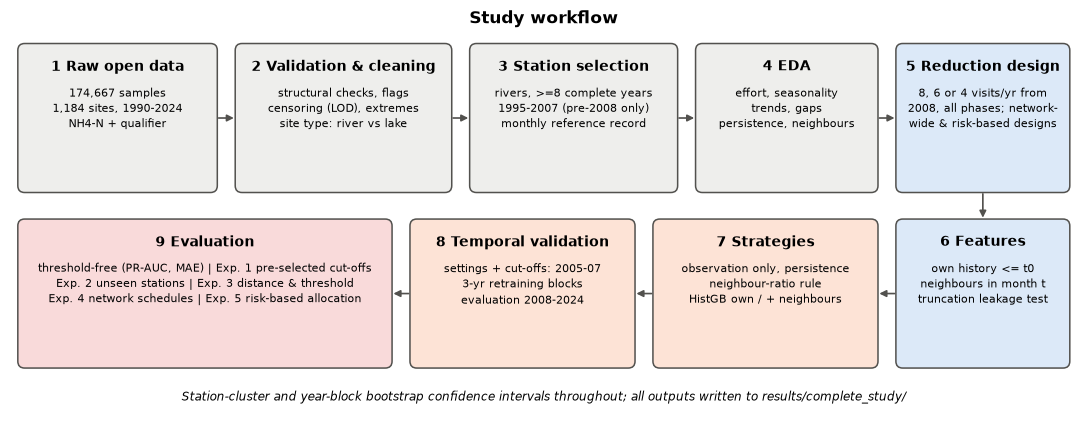

In [4]:
fig, ax = plt.subplots(figsize=(12.5, 4.6)); ax.set_xlim(0, 12.5); ax.set_ylim(1.0, 5.55); ax.axis("off"); ax.grid(False)
def box(x, y, w, h, title, body, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="#52514e", lw=1))
    ax.text(x + w / 2, y + h - .17, title, ha="center", va="top", fontsize=9, weight="bold")
    ax.text(x + w / 2, y + h - .47, body, ha="center", va="top", fontsize=7.4, linespacing=1.35)
def arrow(x1, y1, x2, y2): ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", lw=1.1, color="#52514e"))
G, B, O, R = "#eeeeec", "#dce9f8", "#fde3d6", "#f9dada"
box(0.1, 3.7, 2.3, 1.7, "1 Raw open data", "174,667 samples\n1,184 sites, 1990-2024\nNH4-N + qualifier", G)
box(2.65, 3.7, 2.5, 1.7, "2 Validation & cleaning", "structural checks, flags\ncensoring (LOD), extremes\nsite type: river vs lake", G)
box(5.4, 3.7, 2.4, 1.7, "3 Station selection", "rivers, >=8 complete years\n1995-2007 (pre-2008 only)\nmonthly reference record", G)
box(8.05, 3.7, 2.1, 1.7, "4 EDA", "effort, seasonality\ntrends, gaps\npersistence, neighbours", G)
box(10.4, 3.7, 2.0, 1.7, "5 Reduction design", "8, 6 or 4 visits/yr from\n2008, all phases; network-\nwide & risk-based designs", B)
for a, b in ((2.4, 2.65), (5.15, 5.4), (7.8, 8.05), (10.15, 10.4)): arrow(a, 4.55, b, 4.55)
box(10.4, 1.65, 2.0, 1.7, "6 Features", "own history <= t0\nneighbours in month t\ntruncation leakage test", B)
box(7.55, 1.65, 2.6, 1.7, "7 Strategies", "observation only, persistence\nneighbour-ratio rule\nHistGB own / + neighbours", O)
box(4.7, 1.65, 2.6, 1.7, "8 Temporal validation", "settings + cut-offs: 2005-07\n3-yr retraining blocks\nevaluation 2008-2024", O)
box(0.1, 1.65, 4.35, 1.7, "9 Evaluation", "threshold-free (PR-AUC, MAE) | Exp. 1 pre-selected cut-offs\nExp. 2 unseen stations | Exp. 3 distance & threshold\nExp. 4 network schedules | Exp. 5 risk-based allocation", R)
arrow(11.4, 3.7, 11.4, 3.35); arrow(10.4, 2.5, 10.15, 2.5); arrow(7.55, 2.5, 7.3, 2.5); arrow(4.7, 2.5, 4.45, 2.5)
ax.text(6.25, 1.25, "Station-cluster and year-block bootstrap confidence intervals throughout; all outputs written to results/complete_study/", ha="center", fontsize=8, style="italic")
ax.set_title("Study workflow", fontsize=11); savefig(fig, "F00_workflow"); plt.show()

<a id="4"></a>
## 4. Data validation and cleaning
No record is deleted at this stage. Every issue is either verified as absent or recorded as a flag; analysis-specific exclusions are applied later and are reported in the cleaning log.

### 4.1 Structural checks

In [5]:
d = raw.copy()
d["value"] = pd.to_numeric(d["NH4_N_mg_l_"], errors="coerce")
d["date"] = pd.to_datetime(d["Date"], format="%Y/%m/%d", errors="coerce")
d["E"] = pd.to_numeric(d["Easting"], errors="coerce"); d["N"] = pd.to_numeric(d["Northing"], errors="coerce")
d["qual"] = d["Q_NH4N"].str.strip(); d["year"] = d.date.dt.year; d["ym"] = d.date.dt.to_period("M"); d["month"] = d.date.dt.month
d["hour"] = pd.to_datetime(d["Time"], format="%H:%M:%S", errors="coerce").dt.hour
checks = pd.DataFrame([
    ("Records", f"{len(d):,}", "-"), ("Stations / locations", f"{d.StationCode.nunique():,} / {d.Location.nunique():,}", "see 4.6-4.7"),
    ("Date range", f"{d.date.min().date()} to {d.date.max().date()}", "-"),
    ("Non-numeric concentration", int(d.value.isna().sum()), "none"), ("Unparsable dates", int(d.date.isna().sum()), "none"),
    ("Unparsable times", int(d.hour.isna().sum()), "none" if d.hour.isna().sum() == 0 else "retained (time is not used)"),
    ("Negative values", int((d.value < 0).sum()), "none"),
    ("Zero values", int((d.value == 0).sum()), "none (censored values carry the LOD)"),
    ("Missing coordinates", int(d[["E", "N"]].isna().any(axis=1).sum()), "none"),
    ("X/Y differ from Easting/Northing", int(((d.X != d.Easting) | (d.Y != d.Northing)).sum()), "identical"),
    ("Depth values", ", ".join(sorted(d.Depth.unique())), "all surface samples"),
    ("Exact duplicate records (excl. OBJECTID)", int(d.drop(columns=["OBJECTID"]).duplicated().sum()), "none"),
    ("Duplicate station-date pairs", int(d.duplicated(["StationCode", "Date"]).sum()), "none"),
], columns=["Check", "Result", "Assessment"])
display(checks)

,Check,Result,Assessment
0,Records,"174,667",-
1,Stations / locations,"1,184 / 1,178",see 4.6-4.7
2,Date range,1990-01-02 to 2024-12-11,-
3,Non-numeric concentration,0,none
4,Unparsable dates,0,none
5,Unparsable times,1,retained (time is not used)
6,Negative values,0,none
7,Zero values,0,none (censored values carry the LOD)
8,Missing coordinates,0,none
9,X/Y differ from Easting/Northing,0,identical


### 4.2 Censored values (limit of detection)

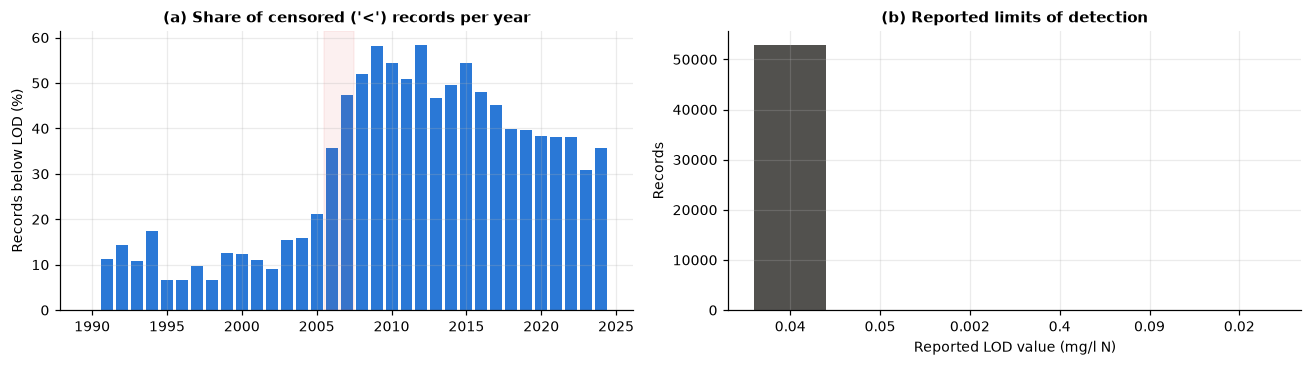

censored '<': 52,951 (30.3%); '>': 8; censored with LOD >= 0.2 mg/l (exceedance state unknown): 2


,records,censored,LOD_median,min_uncensored
year,,,,
1995,5057,0.067,0.04,0.004
2000,5507,0.123,0.04,0.002
2004,6411,0.158,0.04,0.006
2005,6606,0.211,0.04,0.003
2006,6622,0.356,0.04,0.005
2007,6382,0.475,0.04,0.007
2008,6874,0.519,0.04,0.004
2012,3929,0.584,0.04,0.006
2016,3330,0.48,0.04,0.04


In [6]:
cens_year = d.groupby("year").agg(records=("value", "size"), censored=("qual", lambda q: (q == "<").mean()),
                                  LOD_median=("value", lambda v: v[d.loc[v.index, "qual"] == "<"].median()),
                                  min_uncensored=("value", lambda v: v[d.loc[v.index, "qual"] == ""].min()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].bar(cens_year.index, cens_year.censored * 100, color="#2a78d6"); ax[0].set_ylabel("Records below LOD (%)")
ax[0].set_title("(a) Share of censored ('<') records per year"); ax[0].axvspan(2005.5, 2007.5, color="#e34948", alpha=.08)
lod = d[d.qual == "<"].value.round(3).value_counts().head(6)
ax[1].bar(lod.index.astype(str), lod.values, color="#52514e"); ax[1].set_xlabel("Reported LOD value (mg/l N)"); ax[1].set_ylabel("Records")
ax[1].set_title("(b) Reported limits of detection")
fig.tight_layout(); savefig(fig, "F01_censoring"); plt.show()
print(f"censored '<': {(d.qual == '<').sum():,} ({(d.qual == '<').mean():.1%}); '>': {(d.qual == '>').sum()}; "
      f"censored with LOD >= {min(THRS)} mg/l (exceedance state unknown): {int(((d.qual == '<') & (d.value >= min(THRS))).sum())}")
display(cens_year.loc[[1995, 2000, 2004, 2005, 2006, 2007, 2008, 2012, 2016, 2020, 2024]].round(3))

### 4.3 Extreme values

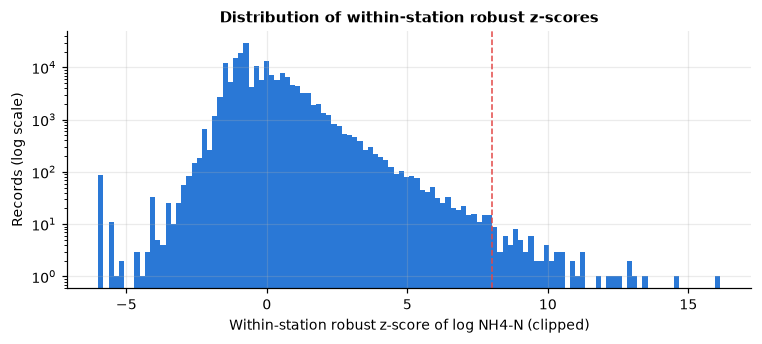

flag_extreme (>5 mg/l and >= station p99.9): 68 | robust z > 8: 76 | overlap: 7


,StationCode,Location,Date,value,robust_z
4037,UKGBNIF10006,PENNYBURNSTREAMATSTRANDROAD,2001/04/02,50.5,2.96
96845,UKGBNIF10500,CLOWNEYRIVERATM1ROUNDABOUTDONEGALLRD,1991/04/19,42,2.62
110611,UKGBNIF10566,FARSETRIVERATCASTLEPLACE(CLOSED),1993/10/08,36,2.64
4282,UKGBNIF10009,CREGGANBYWASHATSTRANDROAD,2005/04/21,24,6.7
3918,UKGBNIF10005,KILFENNANBURNATMALONEPARK,2000/06/27,22,1.97
36558,UKGBNIF10204,SHARVOGUESBURNATSHARVOGUES,2012/10/29,20.8,3.95
94287,UKGBNIF10494,BLACKSTAFFRIVER(BELFAST)ATBMORALSTMWASHBOUCHERRD,1991/09/03,20,1.86
110511,UKGBNIF10565,FARSETRIVERATQUEENSSQUARE(CLOSED),1993/06/25,20,2.97
152220,UKGBNIF10764,BALLYMAGRORTYSTREAMATUPPERGALLIAGHROAD,1997/07/09,18.8,5.6
156147,UKGBNIF10870,PARKLAKESTREAM(DOWNSTREAM),2003/08/22,18,0.77


Decision: extreme values are RETAINED in the primary analysis (high NH4-N can be a genuine pollution event); their removal is tested in Section 15.


In [7]:
lg = np.log(d.value); unc = d.qual == ""                          # robust statistics from measured (uncensored) values only
med = lg.where(unc).groupby(d.StationCode).transform("median")
mad = (lg - med).abs().where(unc).groupby(d.StationCode).transform("median") * 1.4826
d["robust_z"] = (lg - med) / mad.clip(lower=0.1)
q999 = d.groupby("StationCode").value.transform(lambda x: x.quantile(0.999))
d["flag_extreme"] = (d.value > 5) & (d.value >= q999)
d["flag_robust_z8"] = (d.robust_z > 8) & unc
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(d.robust_z.clip(-6, 20), bins=120, color="#2a78d6"); ax.set_yscale("log"); ax.axvline(8, color="#e34948", ls="--", lw=1)
ax.set_xlabel("Within-station robust z-score of log NH4-N (clipped)"); ax.set_ylabel("Records (log scale)"); ax.set_title("Distribution of within-station robust z-scores")
fig.tight_layout(); savefig(fig, "F02_extremes"); plt.show()
print(f"flag_extreme (>5 mg/l and >= station p99.9): {int(d.flag_extreme.sum())} | robust z > 8: {int(d.flag_robust_z8.sum())} | overlap: {int((d.flag_extreme & d.flag_robust_z8).sum())}")
display(d[d.flag_extreme].nlargest(10, "value")[["StationCode", "Location", "Date", "value", "robust_z"]].round(2))
print("Decision: extreme values are RETAINED in the primary analysis (high NH4-N can be a genuine pollution event); their removal is tested in Section 15.")

### 4.4 Sampling time of day

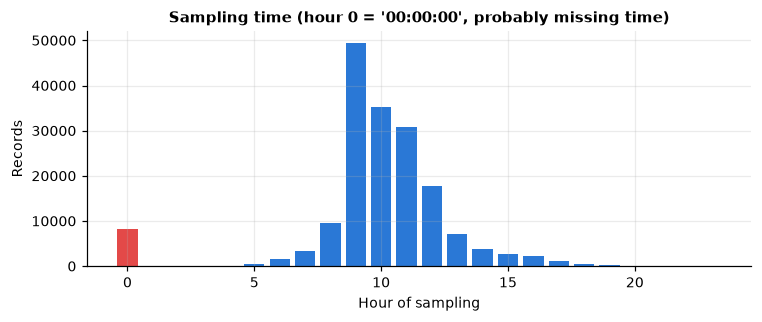

records with time 00:00:00: 8,135 (4.7%); 09:00-12:59: 76.3%. Time is not used as a predictor.


In [8]:
fig, ax = plt.subplots(figsize=(7, 3)); h = d.hour.value_counts().sort_index()
ax.bar(h.index, h.values, color=["#e34948" if i == 0 else "#2a78d6" for i in h.index]); ax.set_xlabel("Hour of sampling"); ax.set_ylabel("Records")
ax.set_title("Sampling time (hour 0 = '00:00:00', probably missing time)"); fig.tight_layout(); savefig(fig, "F03_sampling_time"); plt.show()
d["flag_time_missing"] = d.Time == "00:00:00"
print(f"records with time 00:00:00: {int(d.flag_time_missing.sum()):,} ({d.flag_time_missing.mean():.1%}); 09:00-12:59: {d.hour.between(9, 12).mean():.1%}. Time is not used as a predictor.")

### 4.5 Site classification: rivers versus lakes and reservoirs
The dataset is labelled *river* monitoring but also contains lake, reservoir and pond sites, whose NH₄-N dynamics differ. Sites are classified from their descriptions with ordered, transparent rules: (1) documented manual overrides; (2) samples taken *from the shore* are lake samples; (3) explicit watercourse words (river, burn, stream, feeder, tributary) indicate a river — this prevents false matches such as *Lis**blake** Burn* or *Newry River at **Dam**olly Row*; (4) lake words (lake, reservoir, dam, pond, jetty, slipway, body of lough); (5) names starting with *Lough* without any river term. Only river sites are analysed; an audit table lists lake-classified sites whose names still contain river-like words.

In [9]:
LAKE_TERMS = ["RESERVOIR", "SLIPWAY", "BODYOF", "JETT", "DAM", "POND", "LAKE"]
STRONG_RIVER = re.compile(r"RIVER|BURN|STREAM|FEEDER|TRIBUTARY")          # explicit watercourse words
RIVER_TERMS = re.compile(r"RIVER|RAT|BURN|WATER|STREAM|TRIBUTARY|FEEDER|BROOK")
LOUGH_START = re.compile(r"^(LOWER|UPPER)?LOUGH")
OVERRIDES = {"UKGBNIF10924": ("lake/reservoir", "Lough Beg (a lake) at the River Bann outflow; 'RIVER' names the outflow"),
             "UKGBNIF11170": ("lake/reservoir", "Crawfordsburn pond (a pond; 'BURN' is part of the place name)")}
def classify(code_, name):
    # Ordered rules: (1) manual overrides, (2) shore samples are lakes, (3) explicit watercourse words are rivers
    # (e.g. 'Park Lake Stream', 'Newry River at Damolly'), (4) lake words, (5) names starting with LOUGH and no river term.
    if code_ in OVERRIDES: return OVERRIDES[code_][0], "manual override: " + OVERRIDES[code_][1]
    if "SHORE" in name: return "lake/reservoir", "shore sample"
    if STRONG_RIVER.search(name): return "river", "explicit watercourse term"
    hit = [t for t in LAKE_TERMS if t in name]
    if hit: return "lake/reservoir", "lake term: " + "/".join(hit)
    if LOUGH_START.match(name) and not RIVER_TERMS.search(name): return "lake/reservoir", "name starts with LOUGH and has no river term"
    return "river", "default"
meta = d.groupby("StationCode").agg(Location=("Location", "first"), basin=("PrimaryBasin", "first"), E=("E", "first"), N=("N", "first"),
                                    status=("OpenClosed", "first"), records=("value", "size"), first=("date", "min"), last=("date", "max"),
                                    n_coords=("Easting", "nunique"), n_names=("Location", "nunique"))
cls = [classify(c, n) for c, n in zip(meta.index, meta.Location)]
meta["site_type"] = [c[0] for c in cls]; meta["classification_rule"] = [c[1] for c in cls]
d = d.join(meta[["site_type"]], on="StationCode")
display(meta.site_type.value_counts().to_frame("stations").join(d.groupby("site_type").size().to_frame("records")))
display(meta.groupby(["site_type", meta.classification_rule.str.split(":").str[0]]).size().to_frame("stations"))
chk = meta[(meta.site_type == "lake/reservoir") & meta.Location.str.contains(RIVER_TERMS) & (meta.records >= 20)][["Location", "records", "classification_rule"]]
print("Audit - lake/reservoir sites (>=20 records) whose name contains a river-like term:"); display(chk)

,stations,records
site_type,,
river,765,163773
lake/reservoir,419,10894


stations
site_type      classification_rule                                   
lake/reservoir lake term                                           35
               manual override                                      2
               name starts with LOUGH and has no river term        41
               shore sample                                       341
river          default                                            385
               explicit watercourse term                          380

Audit - lake/reservoir sites (>=20 records) whose name contains a river-like term:


,Location,records,classification_rule
StationCode,,,
UKGBNIF10924,LOUGHBEGATRIVERBANNOUTFLOW,241,manual override: Lough Beg (a lake) at the Riv...


### 4.6 Station metadata consistency

In [10]:
meta_checks = pd.DataFrame([
    ("Stations with >1 coordinate pair", int((meta.n_coords > 1).sum())), ("Stations with >1 location name", int((meta.n_names > 1).sum())),
    ("Location names shared by >1 station code", int((d.groupby("Location").StationCode.nunique() > 1).sum())),
    ("Coordinate pairs shared by >1 station code", int((d.groupby(["Easting", "Northing"]).StationCode.nunique() > 1).sum())),
    ("Records with blank basin", int((d.PrimaryBasin.str.strip() == "").sum())), ("Stations with blank status", int((meta.status.str.strip() == "").sum())),
], columns=["Check", "Count"])
display(meta_checks)
shared = d.groupby("Location").StationCode.nunique(); sh = meta[meta.Location.isin(shared[shared > 1].index)][["Location", "site_type", "records"]]
display(sh.sort_values("Location"))
print("Shared names/coordinates concern lake/pond shore sites only; they are excluded with the lake sites. Blank basins are retained (basin is descriptive only).")

,Check,Count
0,Stations with >1 coordinate pair,0
1,Stations with >1 location name,0
2,Location names shared by >1 station code,6
3,Coordinate pairs shared by >1 station code,5
4,Records with blank basin,1669
5,Stations with blank status,607


,Location,site_type,records
StationCode,,,
UKGBNIF11148,CAVANACAWLAKEFROMSHORE,lake/reservoir,1
UKGBNIF11445,CAVANACAWLAKEFROMSHORE,lake/reservoir,1
UKGBNIF11225,CURLEYPONDFROMSHORE,lake/reservoir,2
UKGBNIF11443,CURLEYPONDFROMSHORE,lake/reservoir,1
UKGBNIF11043,LOUGHNAWEELANFROMSHORE,lake/reservoir,1
UKGBNIF11192,LOUGHNAWEELANFROMSHORE,lake/reservoir,1
UKGBNIF11056,LOUGHPATRICKFROMSHORE,lake/reservoir,3
UKGBNIF11360,LOUGHPATRICKFROMSHORE,lake/reservoir,2
UKGBNIF11152,SULTANNORTHPONDFROMSHORE,lake/reservoir,2


Shared names/coordinates concern lake/pond shore sites only; they are excluded with the lake sites. Blank basins are retained (basin is descriptive only).


### 4.7 Multiple samples within a calendar month

In [11]:
spm = d.groupby(["StationCode", "ym"]).value.agg(["size", "first", "max"])
multi = spm[spm["size"] > 1]
diff = multi["max"] > multi["first"]
print(f"station-months: {len(spm):,}; with >1 sample: {len(multi):,} ({len(multi) / len(spm):.1%}); "
      f"of these, a later sample exceeds the first in {diff.mean():.1%} (median ratio when higher: {np.median(multi['max'][diff] / multi['first'][diff]):.2f})")
print("Primary rule: the FIRST sample of each calendar month represents the monthly visit (a reduced schedule is defined in visits).\n"
      "Alternative (Section 15): the monthly MAXIMUM, i.e. an exceedance is recorded if any sample in the month exceeds the threshold.")

station-months: 155,537; with >1 sample: 18,354 (11.8%); of these, a later sample exceeds the first in 38.5% (median ratio when higher: 1.62)
Primary rule: the FIRST sample of each calendar month represents the monthly visit (a reduced schedule is defined in visits).
Alternative (Section 15): the monthly MAXIMUM, i.e. an exceedance is recorded if any sample in the month exceeds the threshold.


### 4.8 Cleaning log and exported cleaned dataset

In [12]:
complete_sy = d.groupby(["StationCode", "year"]).ym.nunique().unstack(fill_value=0) >= CFG["complete_months"]
y0, y1 = CFG["sel_window"]; d0, d1 = CFG["dev"]
def cohort(k_years, k_dev, sites):
    # uses ONLY years <= 2007: number of monthly-complete years in 1995-2007 and in the development period 2005-2007
    cy = complete_sy.reindex(columns=range(1990, 2025), fill_value=False)
    ok = (cy.loc[:, y0:y1].sum(axis=1) >= k_years) & (cy.loc[:, d0:d1].sum(axis=1) >= k_dev)
    return sorted(set(ok[ok].index) & set(sites))
river = meta.index[meta.site_type == "river"]
SEL_RIVER = cohort(CFG["min_complete_years"], CFG["dev_complete_years"], river); SEL_ALL = cohort(CFG["min_complete_years"], CFG["dev_complete_years"], meta.index)
COHORTS = {name: cohort(k, kd, river) for name, (k, kd) in CFG["cohort_alternatives"].items()}
_old = complete_sy.reindex(columns=range(1990, 2025), fill_value=False).loc[:, 2005:2024].sum(axis=1) >= 15
COHORTS["previous rule: >=15 complete years 2005-2024 (uses evaluation-period data)"] = sorted(set(_old[_old].index) & set(river))
excluded_lakes = meta.loc[sorted(set(SEL_ALL) - set(SEL_RIVER)), ["Location", "basin", "classification_rule"]]
log = pd.DataFrame([
    ("Raw records", len(d), d.StationCode.nunique(), "-"),
    ("Structural errors (non-numeric, invalid dates, negative, duplicates)", 0, 0, "none found"),
    ("Flag: censored below LOD", int((d.qual == "<").sum()), "-", "retained; value = LOD; non-exceedance"),
    ("Flag: extreme value", int(d.flag_extreme.sum()), "-", "retained (removed in sensitivity run)"),
    ("Flag: missing sampling time", int(d.flag_time_missing.sum()), "-", "retained (time not used)"),
    ("Exclude lake/reservoir sites", int((d.site_type != "river").sum()), int((meta.site_type != "river").sum()), "excluded"),
    ("River sites", int((d.site_type == "river").sum()), len(river), "-"),
    (f"River sites with >= {CFG['min_complete_years']} monthly-complete years {y0}-{y1} and {CFG['dev_complete_years']} in {d0}-{d1}", int(d.StationCode.isin(SEL_RIVER).sum()), len(SEL_RIVER), "analysed (pre-2008 cohort)"),
    ("(for reference) all sites meeting the record-length rule", int(d.StationCode.isin(SEL_ALL).sum()), len(SEL_ALL), f"{len(SEL_ALL) - len(SEL_RIVER)} lake/reservoir sites removed"),
], columns=["Step", "Records", "Stations", "Decision"])
display(log)
display(excluded_lakes)
d.drop(columns=["ym"]).to_csv(os.path.join(DAT, "cleaned_samples_with_flags.csv.gz"), index=False)
meta.to_csv(os.path.join(DAT, "station_metadata.csv")); save_table(log, "T00_cleaning_log"); save_table(dictionary, "T00_data_dictionary")
print("exported: data/cleaned_samples_with_flags.csv.gz, data/station_metadata.csv")

,Step,Records,Stations,Decision
0,Raw records,174667,1184,-
1,"Structural errors (non-numeric, invalid dates,...",0,0,none found
2,Flag: censored below LOD,52951,-,retained; value = LOD; non-exceedance
3,Flag: extreme value,68,-,retained (removed in sensitivity run)
4,Flag: missing sampling time,8135,-,retained (time not used)
5,Exclude lake/reservoir sites,10894,419,excluded
6,River sites,163773,765,-
7,River sites with >= 8 monthly-complete years 1...,85819,281,analysed (pre-2008 cohort)
8,(for reference) all sites meeting the record-l...,88637,290,9 lake/reservoir sites removed


,Location,basin,classification_rule
StationCode,,,
UKGBNIF10395,LOUGHNEAGHATCHURCHTOWNPOINT,Lough Neagh & Peripherals,name starts with LOUGH and has no river term
UKGBNIF10399,LOUGHNEAGHATBARTINSBAY,Lough Neagh & Peripherals,name starts with LOUGH and has no river term
UKGBNIF10656,LOUGHMELVINFROMB53ROADSOUTHOFGARRISON,Bradoge,name starts with LOUGH and has no river term
UKGBNIF10664,LOWERLOUGHERNEATROSSHARBOUR(TULLYFAD),Lower Erne,name starts with LOUGH and has no river term
UKGBNIF10666,LOWERLOUGHERNEATROSSCLARE,Lower Erne,name starts with LOUGH and has no river term
UKGBNIF10667,LOWERLOUGHERNEATDEVENISH,Lower Erne,name starts with LOUGH and has no river term
UKGBNIF10668,LOWERLOUGHERNEATPORTORA,Lower Erne,name starts with LOUGH and has no river term
UKGBNIF10738,LOWERLOUGHMACNEANATULSTERWAYFOOTBR,Arney,name starts with LOUGH and has no river term
UKGBNIF10741,UPPERLOUGHMACNEANATCARRICKDUFF,Arney,name starts with LOUGH and has no river term


exported: data/cleaned_samples_with_flags.csv.gz, data/station_metadata.csv


#### 4.9 Station cohort defined from pre-2008 data only
Selecting stations by the completeness of their record *during* the evaluation period would admit stations partly because they survived until 2024 (survivorship / selection bias). The cohort is therefore defined only from **1995–2007**, the period available before the first reduced schedule:

* **≥ 8 of 13 monthly-complete years in 1995–2007** (≥ 10 sampled months). Eight years give at least eight observations of every calendar month for the station's own climatology and a long training history, while keeping stations whose monitoring started in the late 1990s. The previous rule (15 of 20 years, 75%) cannot be transferred to a 13-year window; 8/13 (62%) is the closest rule that retains a spatially dense network, and stricter (10/13) and looser (6/13) rules are tested in Section 15.
* **All three development years (2005–2007) monthly-complete**, because alarm cut-offs and hyper-parameters are selected on this period.

Stations that close or become irregular after 2007 remain in the cohort; they simply contribute fewer evaluation months. This mirrors the real decision an agency faces in 2007.

In [13]:
cy_ = complete_sy.reindex(columns=range(1990, 2025), fill_value=False)
def cohort_row(name, sel):
    ev_sy = cy_.loc[sel, CFG["eval"][0]:CFG["eval"][1]]
    return {"cohort": name, "stations": len(sel), "overlap with primary cohort": len(set(sel) & set(SEL_RIVER)),
            "stations with >=1 complete year 2008-2024": int((ev_sy.sum(axis=1) > 0).sum()), "complete station-years 2008-2024": int(ev_sy.values.sum()),
            "stations complete in 2020-2024 (all 5 yrs)": int((cy_.loc[sel, 2020:2024].sum(axis=1) == 5).sum())}
COH = pd.DataFrame([cohort_row("PRIMARY: >=8 of 13 complete years 1995-2007, 3 in 2005-07", SEL_RIVER)] + [cohort_row(n, s_) for n, s_ in COHORTS.items()])
save_table(COH, "T00b_station_cohorts"); display(COH)
ev_sy = cy_.loc[SEL_RIVER, CFG["eval"][0]:CFG["eval"][1]].sum(axis=1)
print(f"primary cohort: {len(SEL_RIVER)} river stations; complete evaluation years per station: median {ev_sy.median():.0f}, "
      f"{int((ev_sy == 0).sum())} stations without any complete year after 2007 (retained; they contribute no evaluation months)")

,cohort,stations,overlap with primary cohort,stations with >=1 complete year 2008-2024,complete station-years 2008-2024,stations complete in 2020-2024 (all 5 yrs)
0,"PRIMARY: >=8 of 13 complete years 1995-2007, 3...",281,281,279,2788,12
1,"cohort: >=6 of 13 complete years, >=2 in 2005-07",412,281,409,3865,20
2,"cohort: >=10 of 13 complete years, 3 in 2005-07",171,171,169,1891,12
3,previous rule: >=15 complete years 2005-2024 (...,153,116,153,2180,18


primary cohort: 281 river stations; complete evaluation years per station: median 10, 2 stations without any complete year after 2007 (retained; they contribute no evaluation months)


> **Interpretation — data validation and cleaning.**
> * **Structurally clean data.** No non-numeric concentrations, invalid dates, negative or zero values, missing coordinates, duplicate records or duplicate station-date pairs; X/Y equal Easting/Northing; all samples are surface samples. One record has an unparsable time (irrelevant: time is not a predictor).
> * **Censoring is informative but changes over time.** 30.3% of records are below the limit of detection (almost always 0.04 mg N L⁻¹). The censored share rose from 7–16% (1995–2004) to 36–58% (2006–2012), and from about 2014 no uncensored value below 0.04 mg N L⁻¹ is reported — a change in reporting practice rather than in water quality. Because all study thresholds (≥ 0.2 mg N L⁻¹) are at least five times the LOD, censored values are unambiguously non-exceedances (only 2 censored records have LOD ≥ 0.2 mg N L⁻¹); the LOD substitution in the features is tested in Section 15.
> * **Extremes are retained.** 68 records exceed 5 mg N L⁻¹ and their station's 99.9th percentile; a within-station robust z-score computed on measured values flags 76 records (z > 8), 7 of them in common. High NH₄-N can be a genuine pollution event; removing the 68 flagged extremes is tested in Section 15.
> * **Site type matters.** The 'river' dataset contains 419 lake, reservoir, pond and shore sites (10,894 records). Ordered rules with two documented overrides separate them; the audit table shows no remaining lake-classified site with ≥ 20 records and a river-like name except the documented Lough Beg override. Nine of the 290 sites that meet the record-length rule are lakes or reservoirs and are excluded, leaving **281 river stations**.
> * **One visit per month.** 11.8% of station-months contain more than one sample; in 38.5% of these a later sample is higher than the first (median ratio 1.62). The first sample of each month defines the monthly visit; using the monthly maximum instead is evaluated in Section 15.
> * **Pre-2008 cohort (Section 4.9).** 281 stations meet the rule; 279 have at least one complete year after 2007 (median 10 of 17), but only 12 are complete in every year 2020–2024 — the cohort deliberately includes stations whose monitoring later stopped. The previous rule (≥ 15 complete years in 2005–2024) selected 153 stations, 37 of which would not have qualified on pre-2008 information. The stricter (10/13: 171 stations) and looser (6/13: 412 stations) alternatives are evaluated in Section 15.
> * Cleaned samples (with all flags), station metadata and the monthly reference record are exported to `results/complete_study/data/`.

<a id="5"></a>
## 5. Exploratory data analysis

### 5.1 Monitoring effort over time

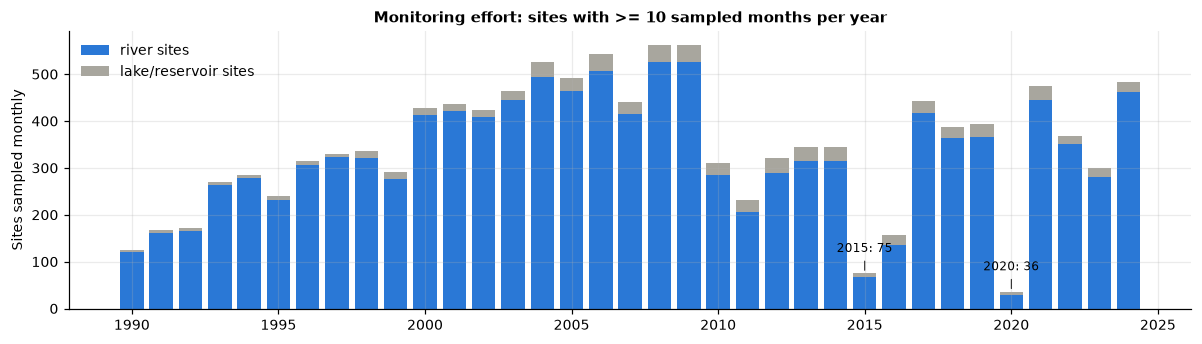

In [14]:
eff = complete_sy.sum(); riv_eff = complete_sy.loc[complete_sy.index.isin(river)].sum()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(riv_eff.index, riv_eff.values, color="#2a78d6", label="river sites")
ax.bar(eff.index, (eff - riv_eff).values, bottom=riv_eff.values, color="#a8a69e", label="lake/reservoir sites")
for y in (2015, 2020): ax.annotate(f"{y}: {int(eff[y])}", (y, eff[y]), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=8, arrowprops=dict(arrowstyle="-", lw=.6))
ax.set_ylabel("Sites sampled monthly"); ax.legend(); ax.set_title("Monitoring effort: sites with >= 10 sampled months per year")
fig.tight_layout(); savefig(fig, "F04_monitoring_effort"); plt.show()

### 5.2 Monthly reference record of the analysed stations

In [15]:
def prepare(station_list, monthly_rule="first", cens_factor=1.0, drop_extremes=False):
    # Monthly reference matrices for a station set. Returns a context dict used by all later functions.
    x = d[d.StationCode.isin(station_list)].sort_values(["StationCode", "date"])
    if drop_extremes: x = x[~x.flag_extreme]
    months = pd.period_range("1990-01", "2024-12", freq="M"); T = len(months)
    mon = np.array([m.month for m in months]); yr = np.array([m.year for m in months]); midx = {m: i for i, m in enumerate(months)}
    sel = list(station_list); S = len(sel); sidx = {s: i for i, s in enumerate(sel)}
    g = x.groupby(["StationCode", "ym"])
    if monthly_rule == "first": rep = g.first()
    else: rep = x.loc[g.value.idxmax()].set_index(["StationCode", "ym"])
    V = np.full((S, T), np.nan); CEN = np.zeros((S, T), bool)
    for (s, m), r in rep[["value", "qual"]].iterrows(): V[sidx[s], midx[m]] = r.value; CEN[sidx[s], midx[m]] = r.qual == "<"
    Vf = np.where(CEN, V * cens_factor, V); L = np.log(Vf)
    info = meta.loc[sel]; xy = info[["E", "N"]].values.astype(float)
    dist, nn = cKDTree(xy).query(xy, k=CFG["nb_k"] + 1)
    NB_ALL = [[(nn[i, k], dist[i, k] / 1000) for k in range(1, CFG["nb_k"] + 1) if dist[i, k] / 1000 <= CFG["nb_km"]] for i in range(S)]
    groups = KMeans(n_clusters=CFG["n_groups"], n_init=10, random_state=SEED).fit_predict(xy)
    okSY = complete_sy.reindex(index=sel, columns=range(1990, 2025), fill_value=False).values
    def em(a, b): return okSY[:, yr - 1990] & ((yr >= a) & (yr <= b))[None, :] & ~np.isnan(V)
    EVAL, DEVM = em(*CFG["eval"]), em(*CFG["dev"])
    ctx = dict(sel=sel, S=S, months=months, T=T, mon=mon, yr=yr, V=V, CEN=CEN, L=L, info=info, xy=xy, dist=dist, NB_ALL=NB_ALL,
               groups=groups, okSY=okSY, EVAL=EVAL, DEVM=DEVM,
               n_sy_eval=int(okSY[:, CFG["eval"][0] - 1990:CFG["eval"][1] - 1989].sum()), n_sy_dev=int(okSY[:, CFG["dev"][0] - 1990:CFG["dev"][1] - 1989].sum()))
    return ctx
def activate(ctx): globals().update(ctx)
MAIN_CTX = prepare(SEL_RIVER); activate(MAIN_CTX)
def exceed(vals, cens, thr): return np.where(cens & (vals >= thr), False, vals > thr)
print(f"analysed river stations: {S}; basins: {info.basin.nunique()}; evaluation {CFG['eval'][0]}-{CFG['eval'][1]}: {int(EVAL.sum()):,} station-months, "
      f"{n_sy_eval:,} station-years; development {CFG['dev'][0]}-{CFG['dev'][1]}: {int(DEVM.sum()):,} station-months, {n_sy_dev} station-years")
ref_long = pd.DataFrame([(sel[i], str(months[t]), V[i, t], CEN[i, t], bool(EVAL[i, t]), bool(DEVM[i, t])) for i in range(S) for t in np.flatnonzero(~np.isnan(V[i]))],
                        columns=["StationCode", "month", "NH4_N", "censored", "evaluation_month", "development_month"])
ref_long.to_csv(os.path.join(DAT, "monthly_reference_record.csv.gz"), index=False); print("exported: data/monthly_reference_record.csv.gz")

analysed river stations: 281; basins: 41; evaluation 2008-2024: 31,738 station-months, 2,788 station-years; development 2005-2007: 9,694 station-months, 843 station-years
exported: data/monthly_reference_record.csv.gz


### 5.3 Spatial pattern and data completeness

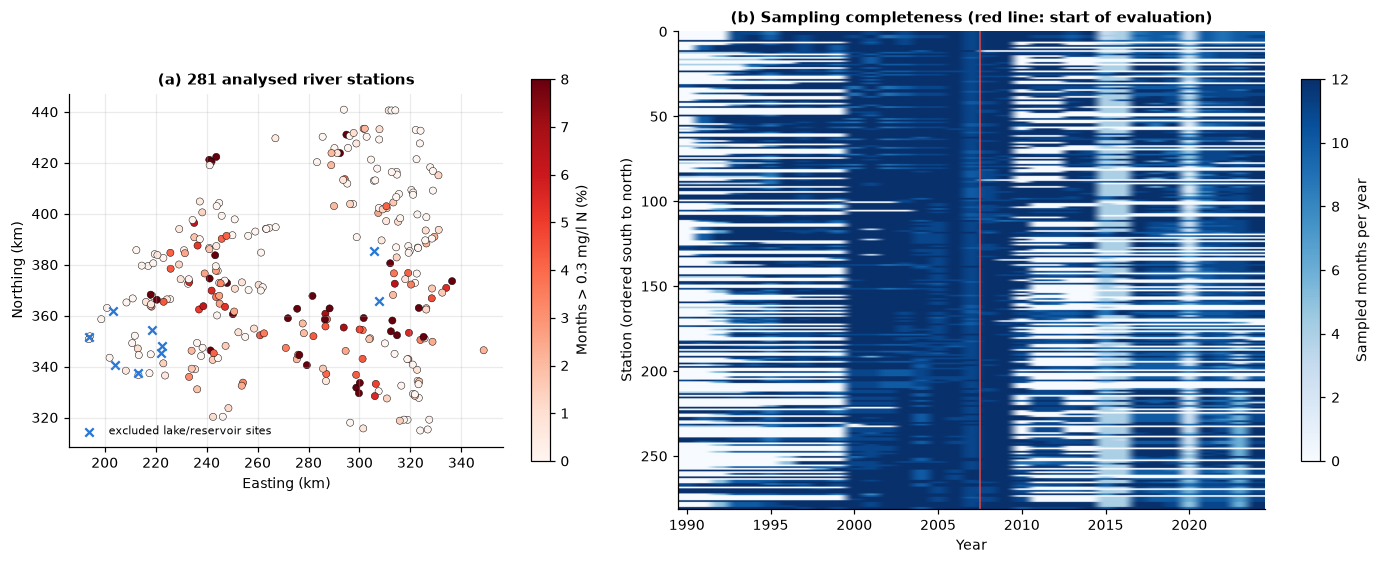

In [16]:
rate = {thr: np.array([exceed(V[i, EVAL[i]], CEN[i, EVAL[i]], thr).mean() for i in range(S)]) for thr in THRS}
lakes = meta.loc[excluded_lakes.index]
fig = plt.figure(figsize=(13, 5.2)); gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.35])
a0 = fig.add_subplot(gs[0]); sc = a0.scatter(xy[:, 0] / 1000, xy[:, 1] / 1000, c=rate[PRIMARY] * 100, s=22, cmap="Reds", vmin=0, vmax=8, edgecolor="k", lw=.3)
a0.scatter(lakes.E / 1000, lakes.N / 1000, marker="x", color="#2a78d6", s=30, label="excluded lake/reservoir sites")
plt.colorbar(sc, ax=a0, shrink=.8, label=f"Months > {PRIMARY} mg/l N (%)"); a0.set_aspect("equal"); a0.legend(loc="lower left", fontsize=7)
a0.set_xlabel("Easting (km)"); a0.set_ylabel("Northing (km)"); a0.set_title(f"(a) {S} analysed river stations")
a1 = fig.add_subplot(gs[1]); comp = np.array([[np.isfinite(V[i, yr == y]).sum() for y in range(1990, 2025)] for i in range(S)])
order = np.argsort(xy[:, 1]); im = a1.imshow(comp[order], aspect="auto", cmap="Blues", vmin=0, vmax=12, extent=[1989.5, 2024.5, S, 0]); a1.grid(False)
plt.colorbar(im, ax=a1, shrink=.8, label="Sampled months per year"); a1.axvline(2007.5, color="#e34948", lw=1)
a1.set_xlabel("Year"); a1.set_ylabel("Station (ordered south to north)"); a1.set_title("(b) Sampling completeness (red line: start of evaluation)")
fig.tight_layout(); savefig(fig, "F05_map_completeness"); plt.show()

### 5.4 Concentration distribution, seasonality and long-term trends

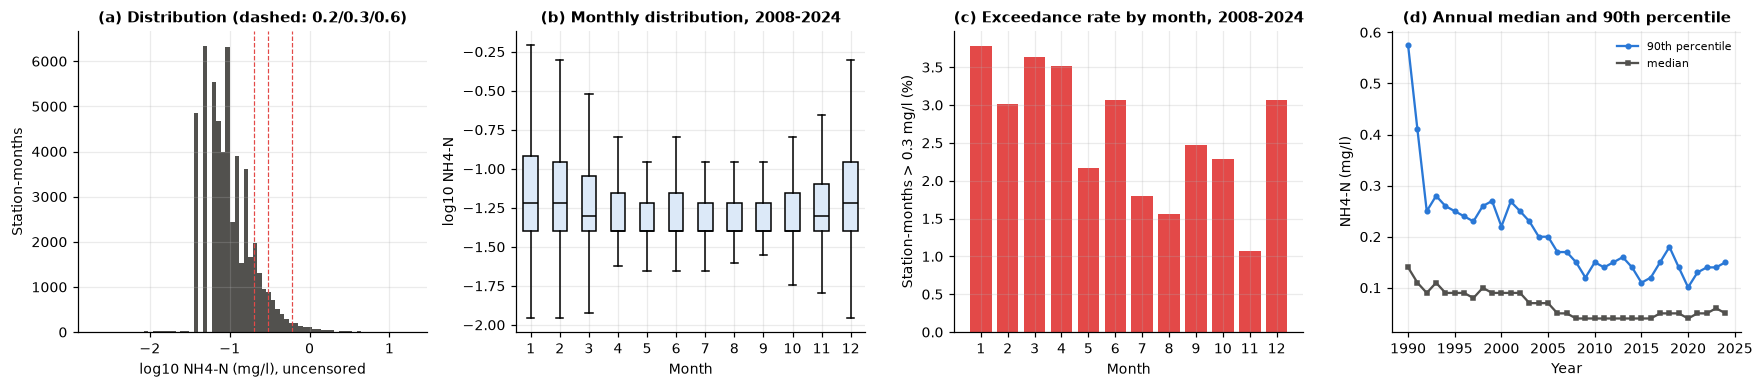

,median,p90,exceed
year,,,
1995,0.09,0.25,6.876
2000,0.09,0.22,4.91
2005,0.07,0.2,4.034
2008,0.04,0.15,3.358
2012,0.04,0.15,2.386
2016,0.04,0.12,1.189
2020,0.04,0.101,2.143
2024,0.05,0.15,2.524


In [17]:
m_ = EVAL | DEVM | (np.isfinite(V) & (yr < 2005)[None, :])
vals = pd.DataFrame({"v": V[m_], "c": CEN[m_], "month": np.broadcast_to(mon, V.shape)[m_], "year": np.broadcast_to(yr, V.shape)[m_]})
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
ax[0].hist(np.log10(vals.v[~vals.c]), bins=70, color="#52514e")
for t in (0.2, 0.3, 0.6): ax[0].axvline(np.log10(t), color="#e34948", ls="--", lw=.8)
ax[0].set_xlabel("log10 NH4-N (mg/l), uncensored"); ax[0].set_ylabel("Station-months"); ax[0].set_title("(a) Distribution (dashed: 0.2/0.3/0.6)")
ev = vals[vals.year >= CFG["eval"][0]]
ax[1].boxplot([np.log10(ev.v[ev.month == k]) for k in range(1, 13)], showfliers=False, patch_artist=True, boxprops=dict(facecolor="#dce9f8"), medianprops=dict(color="k"))
ax[1].set_xlabel("Month"); ax[1].set_ylabel("log10 NH4-N"); ax[1].set_title("(b) Monthly distribution, 2008-2024")
ax[2].bar(range(1, 13), [100 * (ev.v[(ev.month == k) & ~ev.c] > PRIMARY).sum() / (ev.month == k).sum() for k in range(1, 13)], color="#e34948")
ax[2].set_xticks(range(1, 13)); ax[2].set_xlabel("Month"); ax[2].set_ylabel(f"Station-months > {PRIMARY} mg/l (%)"); ax[2].set_title("(c) Exceedance rate by month, 2008-2024")
yrs = vals.groupby("year").agg(median=("v", "median"), p90=("v", lambda x: x.quantile(.9)))
yrs["exceed"] = vals.groupby("year").apply(lambda g: (g.v[~g.c] > PRIMARY).sum() / len(g), include_groups=False) * 100
ax[3].plot(yrs.index, yrs.p90, "o-", color="#2a78d6", ms=3, label="90th percentile"); ax[3].plot(yrs.index, yrs["median"], "s-", color="#52514e", ms=3, label="median")
ax[3].set_ylabel("NH4-N (mg/l)"); ax[3].set_xlabel("Year"); ax[3].legend(fontsize=7); ax[3].set_title("(d) Annual median and 90th percentile")
fig.tight_layout(); savefig(fig, "F06_distribution_season_trend"); plt.show()
display(yrs.loc[[1995, 2000, 2005, 2008, 2012, 2016, 2020, 2024]].round(3))

### 5.5 Exceedance frequency and persistence

,threshold (mg/l N),recorded exceedances,evaluation months,rate,stations with >=1 event
0,0.2,1715,31738,0.05404,193
1,0.3,828,31738,0.02609,162
2,0.4,500,31738,0.01575,137
3,0.6,250,31738,0.007877,103


P(exceedance next month | exceedance now) at 0.3 mg/l: 0.178 (base rate 0.026)


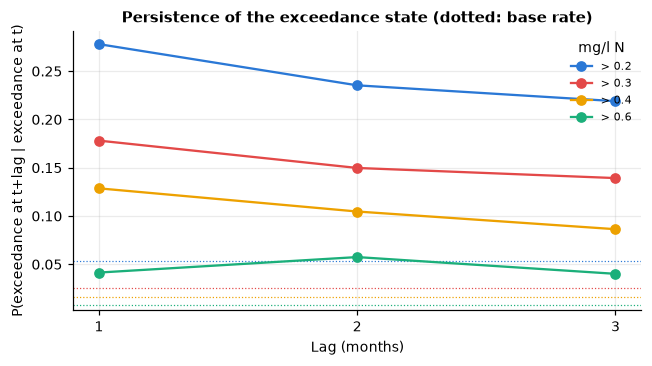

In [18]:
rows, pers = [], []
for thr in THRS:
    e_all = [exceed(V[i, EVAL[i]], CEN[i, EVAL[i]], thr) for i in range(S)]
    rows.append({"threshold (mg/l N)": thr, "recorded exceedances": int(sum(e.sum() for e in e_all)), "evaluation months": int(EVAL.sum()),
                 "rate": sum(e.sum() for e in e_all) / EVAL.sum(), "stations with >=1 event": int(sum(e.any() for e in e_all))})
    E_ = np.where(np.isnan(V), np.nan, exceed(np.nan_to_num(V), CEN, thr).astype(float))
    for lag in (1, 2, 3):
        a, b = E_[:, :-lag], E_[:, lag:]; m = EVAL[:, lag:] & ~np.isnan(a) & ~np.isnan(b); aa, bb = a[m].astype(bool), b[m].astype(bool)
        pers.append({"threshold": thr, "lag": lag, "P(E|E)": bb[aa].mean(), "base rate": bb.mean()})
EXC = pd.DataFrame(rows); PERS = pd.DataFrame(pers); display(EXC); save_table(EXC, "T01_exceedance_counts"); save_table(PERS, "T01b_exceedance_persistence")
p1 = PERS[(PERS.threshold == PRIMARY) & (PERS.lag == 1)].iloc[0]; print(f"P(exceedance next month | exceedance now) at {PRIMARY} mg/l: {p1['P(E|E)']:.3f} (base rate {p1['base rate']:.3f})")
fig, ax = plt.subplots(figsize=(6, 3.4))
for thr, c in zip(THRS, ["#2a78d6", "#e34948", "#eda100", "#1baf7a"]):
    p = PERS[PERS.threshold == thr]; ax.plot(p.lag, p["P(E|E)"], "o-", color=c, label=f"> {thr}"); ax.axhline(p["base rate"].iloc[0], color=c, ls=":", lw=.8)
ax.set_xticks([1, 2, 3]); ax.set_xlabel("Lag (months)"); ax.set_ylabel("P(exceedance at t+lag | exceedance at t)"); ax.legend(title="mg/l N", fontsize=7)
ax.set_title("Persistence of the exceedance state (dotted: base rate)"); fig.tight_layout(); savefig(fig, "F07_persistence"); plt.show()

### 5.6 Neighbour structure and co-variation

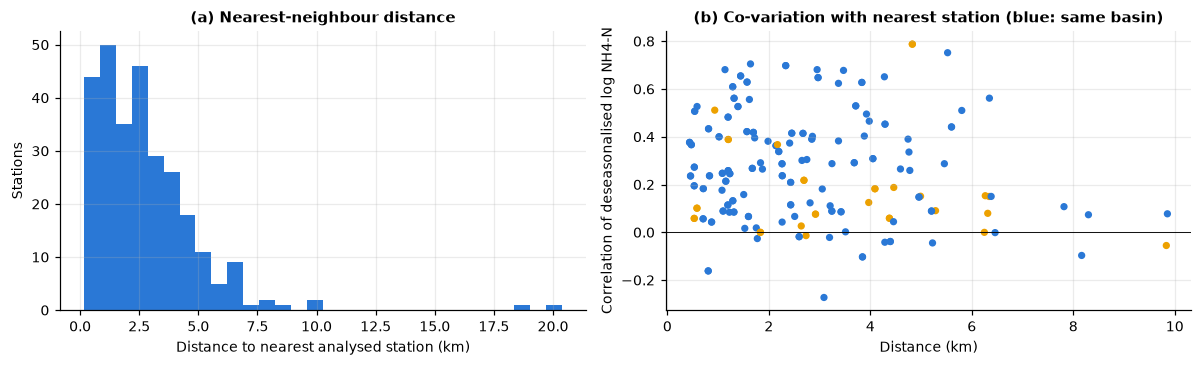

stations with >=1 neighbour within 15 km: 279/281; nearest distance median 2.3 km


,km,r (log),r (deseasonalised)
count,193,193,193
25%,1.22,0.14,0.09
50%,2.33,0.31,0.25
75%,3.85,0.5,0.42


In [19]:
clim = np.full_like(L, np.nan)
for k in range(1, 13):
    cols = mon == k; clim[:, cols] = np.nanmean(np.where(EVAL[:, cols], L[:, cols], np.nan), axis=1, keepdims=True)
A = L - clim; nbr = []
for i in range(S):
    for j, km in NB_ALL[i][:1]:
        m = EVAL[i] & EVAL[j]
        if m.sum() >= 36: nbr.append({"km": km, "same basin": info.basin.iloc[i] == info.basin.iloc[j], "r (log)": np.corrcoef(L[i, m], L[j, m])[0, 1],
                                      "r (deseasonalised)": np.corrcoef(A[i, m], A[j, m])[0, 1]})
NBR = pd.DataFrame(nbr)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(dist[:, 1] / 1000, bins=30, color="#2a78d6"); ax[0].set_xlabel("Distance to nearest analysed station (km)"); ax[0].set_ylabel("Stations"); ax[0].set_title("(a) Nearest-neighbour distance")
ax[1].scatter(NBR.km, NBR["r (deseasonalised)"], s=14, c=np.where(NBR["same basin"], "#2a78d6", "#eda100")); ax[1].axhline(0, color="k", lw=.6)
ax[1].set_xlabel("Distance (km)"); ax[1].set_ylabel("Correlation of deseasonalised log NH4-N"); ax[1].set_title("(b) Co-variation with nearest station (blue: same basin)")
fig.tight_layout(); savefig(fig, "F08_neighbours"); plt.show()
print(f"stations with >=1 neighbour within {CFG['nb_km']:.0f} km: {sum(len(x) > 0 for x in NB_ALL)}/{S}; nearest distance median {np.median(dist[:, 1]) / 1000:.1f} km")
display(NBR.describe().loc[["count", "25%", "50%", "75%"]].round(2))

> **Interpretation — exploratory analysis.**
> * **Monitoring effort has already been reduced in practice**: the number of river sites sampled in at least ten months per year fell from 526 in 2008 to 68 in 2015 and 29 in 2020, before recovering to 281–462 in 2021–2024 (all sites including lakes: 562, 75 and 36). Many cohort stations therefore contribute only part of the evaluation period.
> * **The analysed network is dense**: 281 river stations in 40 named basins (plus 3 stations without a basin name), nearest-neighbour distance median 2.3 km, 279/281 stations with a neighbour within 15 km.
> * **Concentrations are low and declining**: the annual 90th percentile fell from 0.25 mg N L⁻¹ (1995) to 0.10–0.15 mg N L⁻¹ after 2008. The share of station-months above 0.3 mg N L⁻¹ fell from 6.9% (1995) to 1.2% (2016) and returned to 2.1–2.5% in 2020–2024.
> * **Seasonality is moderate**: exceedances above 0.3 mg N L⁻¹ are most frequent in winter and early spring (3.0–3.8% of station-months in December–April) and least frequent in July, August and November (1.1–1.8%).
> * **Exceedances are rare, short and widespread**: 828 recorded exceedances above 0.3 mg N L⁻¹ (2.6% of evaluation months) at 162 stations; the exceedance state rarely persists into the next month (0.178 against a base rate of 0.026).
> * **Neighbours co-vary only weakly**: the correlation of deseasonalised log NH₄-N with the nearest station has median 0.25 (IQR 0.09–0.42). Only a *partial* recovery of skipped months can be expected.

<a id="6"></a>
## 6. Sampling-reduction design and baselines

From 1 January 2008 the target station is visited only in the scheduled months (8 visits/yr: one month skipped per quarter, 3 phases; 6 visits/yr: 2 phases; 4 visits/yr: 3 phases); all other stations keep monthly sampling. Results are pooled over all phases. **Observation only** detects an exceedance only in visited months; **persistence** assigns a skipped month the state of the last visit.

In [20]:
def availability(keep, start): return ~np.isnan(V) & (np.isin(mon, keep)[None, :] | (yr < start)[None, :])
def baseline_sim():
    out = []
    for f, phases in CFG["sched"].items():
        for ph, keep in enumerate(phases):
            av = availability(keep, CFG["eval"][0])
            for thr in THRS:
                c = {k: [0, 0, 0] for k in ("Observation-only", "Persistence")}
                for i in range(S):
                    idx = np.flatnonzero(av[i])
                    for t in np.flatnonzero(EVAL[i]):
                        e = bool(exceed(V[i, t], CEN[i, t], thr))
                        if av[i, t]: al = {"Observation-only": e, "Persistence": e}
                        else: k = np.searchsorted(idx, t) - 1; al = {"Observation-only": False, "Persistence": V[i, idx[k]] > thr}
                        for s_, a_ in al.items(): c[s_][0] += a_ and e; c[s_][1] += a_ and not e; c[s_][2] += (not a_) and e
                for s_, (tp, fp, fn) in c.items(): out.append({"visits/yr": f, "phase": ph, "threshold": thr, "strategy": s_, "TP": tp, "FP": fp, "FN": fn})
    Bt = pd.DataFrame(out).groupby(["visits/yr", "threshold", "strategy"])[["TP", "FP", "FN"]].sum().reset_index()
    nph = Bt["visits/yr"].map({f: len(p) for f, p in CFG["sched"].items()})
    Bt["recall"] = Bt.TP / (Bt.TP + Bt.FN); Bt["missed / station-yr"] = Bt.FN / nph / n_sy_eval; Bt["false alarms / station-yr"] = Bt.FP / nph / n_sy_eval
    return Bt
BASE = baseline_sim(); save_table(BASE, "T02_baselines")
display(BASE.pivot_table(index=["visits/yr", "threshold"], columns="strategy", values=["recall", "missed / station-yr", "false alarms / station-yr"]).round(3))

false alarms / station-yr             missed / station-yr                       recall            
strategy                     Observation-only Persistence    Observation-only Persistence Observation-only Persistence
visits/yr threshold                                                                                                   
4         0.2                               0       0.305                0.41       0.307            0.333       0.501
          0.3                               0       0.167               0.198       0.166            0.333        0.44
          0.4                               0       0.106                0.12       0.106            0.333       0.409
          0.6                               0       0.058                0.06       0.057            0.333       0.365
6         0.2                               0       0.223               0.308       0.223              0.5       0.637
          0.3                               0       0.121               0.148       0.122              0.5        0.59
          0.4                               0       0.078                0.09       0.079              0.5       0.562
          0.6                               0       0.044               0.045       0.043              0.5       0.522
8         0.2                               0       0.147               0.205       0.149            0.667       0.758
          0.3                               0       0.081               0.099       0.081            0.667       0.726
          0.4                               0       0.051                0.06       0.052            0.667        0.71
          0.6                               0       0.028                0.03       0.028            0.667       0.683

> **Interpretation — baselines.** Observation only detects exactly the visited share of recorded exceedances (66.7%, 50% and 33.3% with 8, 6 and 4 visits/yr). Carrying the last visit forward with the nominal rule adds 6–11 points at 0.3 mg N L⁻¹ (72.6%, 59.0% and 44.0%) but at the cost of 0.08–0.17 false alarms per station-year, and at 0.6 mg N L⁻¹ it is barely better than observation only (36.5% vs 33.3% at 4/yr). The station's last visit is therefore insufficient to recover skipped months.

<a id="7"></a>
## 7. Feature construction and leakage controls

For a skipped month *t* of station *s*, the origin *t₀* is the last **available** visit of *s* before *t*.

| Group | Features |
|---|---|
| Own history (12) | log value at t₀, censoring flag at t₀, gap h = t − t₀, expanding mean, 12-month mean, monthly climatology of target and origin month (≥ 2 years), seasonal change, anomalies, sin/cos of target month — all from visits ≤ t₀ |
| Neighbours (8) | up to 3 analysed stations within the search radius (default 15 km) sampled in both t and t₀: log change t₀→t of the nearest, its anomaly relative to its own climatology (≤ t₀), its value at t and distance, the mean change and anomaly, the maximum value and the number of neighbours |

The response is the change in log NH₄-N from t₀ to t. Training pairs come from the observed record (h = 1–3 months).

In [21]:
def cumstats(Am):
    X = np.where(np.isnan(Am), 0.0, Am); n = (~np.isnan(Am)).astype(float)
    return (np.cumsum(X, 1), np.cumsum(n, 1), np.stack([np.cumsum(np.where(mon[None, :] == k, X, 0), 1) for k in range(1, 13)]),
            np.stack([np.cumsum(np.where(mon[None, :] == k, n, 0), 1) for k in range(1, 13)]))
OWN = ["last", "last_censored", "h", "baseline", "mean12", "anomaly", "clim_target", "clim_origin", "seasonal_change", "seas_anom", "tsin", "tcos"]
NBC = ["nb1_change", "nb1_anom", "nb1_value", "nb1_km", "nb_mean_change", "nb_mean_anom", "nb_max_value", "nb_n"]
MODELS = {"HistGB_own": OWN, "HistGB_nb": OWN + NBC}

def build(s, t, t0, own, radius=None):
    radius = CFG["nb_km"] if radius is None else radius
    cs, cn, csm, cnm = own; dcs, dcn, dcsm, dcnm = DENSE
    assert np.all(t0 < t), "origin must precede the target month"
    last = L[s, t0]; base = cs[s, t0] / cn[s, t0]; t12 = np.maximum(t0 - 12, 0); n12 = cn[s, t0] - cn[s, t12]
    def clim_(ti):
        mm = mon[ti] - 1; return np.where(cnm[mm, s, t0] >= 2, csm[mm, s, t0] / np.maximum(cnm[mm, s, t0], 1), base)
    ct, co = clim_(t), clim_(t0)
    F = pd.DataFrame({"last": last, "last_censored": CEN[s, t0].astype(float), "h": (t - t0).astype(float), "baseline": base,
                      "mean12": np.where(n12 > 0, (cs[s, t0] - cs[s, t12]) / np.maximum(n12, 1), last), "anomaly": last - base,
                      "clim_target": ct, "clim_origin": co, "seasonal_change": ct - co, "seas_anom": last - co,
                      "tsin": np.sin(2 * np.pi * mon[t] / 12), "tcos": np.cos(2 * np.pi * mon[t] / 12)})
    nbv = {k: np.full(len(s), np.nan) for k in NBC}
    for r in range(len(s)):
        ch, an, va = [], [], []
        for j, km in NB_ALL[s[r]]:
            if km > radius or np.isnan(L[j, t[r]]) or np.isnan(L[j, t0[r]]): continue
            mm = mon[t[r]] - 1; den = dcnm[mm, j, t0[r]]
            cj = dcsm[mm, j, t0[r]] / den if den >= 2 else dcs[j, t0[r]] / max(dcn[j, t0[r]], 1)
            ch.append(L[j, t[r]] - L[j, t0[r]]); an.append(L[j, t[r]] - cj); va.append(L[j, t[r]])
            if len(ch) == 1: nbv["nb1_change"][r], nbv["nb1_anom"][r], nbv["nb1_value"][r], nbv["nb1_km"][r] = ch[0], an[0], va[0], km
        if ch: nbv["nb_mean_change"][r], nbv["nb_mean_anom"][r], nbv["nb_max_value"][r] = np.mean(ch), np.mean(an), np.max(va)
        nbv["nb_n"][r] = len(ch)
    for k, v in nbv.items(): F[k] = v
    F["s"], F["t"], F["t0"], F["y"], F["year"], F["group"], F["cens_target"] = s, t, t0, L[s, t], yr[t], groups[s], CEN[s, t]
    return F

def make_pairs(radius=None):
    ps, pt, pt0 = [], [], []
    for i in range(S):
        obs = np.flatnonzero(~np.isnan(V[i])); oset = set(obs.tolist())
        for t in obs:
            for h in range(1, CFG["max_h"] + 1):
                if t - h in oset and t - h >= 24: ps.append(i); pt.append(t); pt0.append(t - h)
    return build(np.array(ps), np.array(pt), np.array(pt0), DENSE, radius)

def skipped_items(keep, start, mask, radius=None):
    av = availability(keep, start); own = cumstats(np.where(av, L, np.nan)); s_, tt, t0_, ret, nohist = [], [], [], [], 0
    for i in range(S):
        idx = np.flatnonzero(av[i])
        for t in np.flatnonzero(mask[i]):
            if av[i, t]: ret.append((i, t)); continue
            k = np.searchsorted(idx, t) - 1
            if k < 0: nohist += 1; continue                      # no earlier visit: cannot infer (index would wrap to the future)
            s_.append(i); tt.append(t); t0_.append(idx[k])
    IT = build(np.array(s_), np.array(tt), np.array(t0_), own, radius)
    assert not av[IT.s.values, IT.t.values].any(), "a skipped month was available to the model"
    return IT, pd.DataFrame(ret, columns=["s", "t"]), nohist

DENSE = cumstats(L); t_ = time.time(); PAIRS = make_pairs()
ITEMS, DEV_ITEMS, NOHIST = {}, {}, {}
for f, phs in CFG["sched"].items():
    for ph, keep in enumerate(phs):
        a, b, n1 = skipped_items(keep, CFG["eval"][0], EVAL); ITEMS[(f, ph)] = (a, b)
        a, b, n2 = skipped_items(keep, CFG["dev"][0], DEVM); DEV_ITEMS[(f, ph)] = (a, b); NOHIST[(f, ph)] = (n1, n2)
display(pd.DataFrame({"evaluation skipped months": {str(k): len(v[0]) for k, v in ITEMS.items()},
                      "development skipped months": {str(k): len(v[0]) for k, v in DEV_ITEMS.items()},
                      "excluded (no earlier visit) eval / dev": {str(k): f"{v[0]} / {v[1]}" for k, v in NOHIST.items()}}))
print(f"training pairs: {len(PAIRS):,}; with >=1 neighbour sampled: {(PAIRS.nb_n > 0).mean():.1%}; built in {time.time() - t_:.0f}s")

,evaluation skipped months,development skipped months,excluded (no earlier visit) eval / dev
"(8, 0)",10785,3143,0 / 0
"(8, 1)",10877,3326,0 / 0
"(8, 2)",10076,3225,0 / 0
"(6, 0)",15526,4905,0 / 0
"(6, 1)",16212,4789,0 / 0
"(4, 0)",20953,6551,0 / 0
"(4, 1)",20861,6368,0 / 0
"(4, 2)",21662,6469,0 / 0


training pairs: 210,144; with >=1 neighbour sampled: 94.3%; built in 11s


**Truncation test.** For 300 random skipped months, all features are recomputed from a copy of the data in which every value after the target month (all stations) and the target value itself are deleted. Identical features prove that no future or hidden information is used.

In [22]:
IT0 = ITEMS[(4, 0)][0]; picks = np.random.RandomState(SEED).choice(len(IT0), 300, replace=False); maxdiff = 0.0; L_main = L
for k in picks:
    r = IT0.iloc[k]; s, t, t0 = int(r.s), int(r.t), int(r.t0)
    Lt = L_main.copy(); Lt[:, t + 1:] = np.nan; Lt[s, t] = np.nan
    av = availability(CFG["sched"][4][0], CFG["eval"][0]) & ~np.isnan(Lt)
    L = Lt
    try: f_new = build(np.array([s]), np.array([t]), np.array([t0]), cumstats(np.where(av, Lt, np.nan)))[OWN + NBC].values.astype(float)
    finally: L = L_main
    f_old = IT0.iloc[[k]][OWN + NBC].values.astype(float); both = ~(np.isnan(f_new) & np.isnan(f_old))
    if both.any(): maxdiff = max(maxdiff, float(np.nanmax(np.abs(f_new[both] - f_old[both]))))
print(f"truncation test (300 skipped months): max |difference| = {maxdiff:.2e} ->", "PASS" if maxdiff < 1e-9 else "FAIL")
assert maxdiff < 1e-9

truncation test (300 skipped months): max |difference| = 0.00e+00 -> PASS


> **Interpretation — features and leakage controls.** 210,144 training pairs are built from the observed record; 94.3% have at least one neighbour sampled in both months. **The truncation test is passed (maximum feature difference 0)**, demonstrating that no information after the target month, and no hidden target value, enters the features. Because all cohort stations have complete development years, no skipped month lacks an earlier visit (0 excluded months); the guard that prevents an empty history from wrapping to a future sample is retained.

<a id="8"></a>
## 8. Models and hyper-parameter selection

**Strategies.** *Persistence*: last visit. *Neighbour ratio rule*: last visit × (nearest neighbour's value in month t / its value in month t₀). *HistGB (own history)* and *HistGB + neighbours*: histogram gradient boosting of the log change. Hyper-parameters are selected **once** on the development period (training < 2005, validation 2005–2007).

**Training blocks.** For each block start B (every 3 years from 2008) and spatial cluster g: the *seen* design trains on all pairs with target year < B except post-2007 pairs of cluster g (hidden months never enter training); the *unseen* design (Experiment 2) trains only on the other nine clusters.

In [23]:
def fit(cols, cfg, X): return HistGradientBoostingRegressor(random_state=SEED, **cfg).fit(X[cols].values, (X.y - X["last"]).values)
def predict(m, cols, X): return m.predict(X[cols].values) + X["last"].values
dtr, dva = PAIRS[PAIRS.year < CFG["dev"][0]], PAIRS[PAIRS.year.between(*CFG["dev"])]
tune = [{"model": name, "config": ci, **cfg, "dev MAE (log)": float(np.abs(predict(fit(cols, cfg, dtr), cols, dva) - dva.y).mean())}
        for name, cols in MODELS.items() for ci, cfg in enumerate(HGB_GRID)]
TUNE = pd.DataFrame(tune); CHOSEN = {m: int(TUNE[TUNE.model == m].sort_values("dev MAE (log)").config.iloc[0]) for m in MODELS}
display(TUNE.pivot(index="config", columns="model", values="dev MAE (log)").round(4)); print("selected configurations:", CHOSEN); save_table(TUNE, "T03_tuning")
def block_of(y): return max(b for b in CFG["blocks"] if b <= y)
def run_models(items, design="seen", pairs=None, cols_map=MODELS):
    pairs = PAIRS if pairs is None else pairs
    out = {k: {n: pd.Series(np.nan, index=v[0].index) for n in cols_map} for k, v in items.items()}
    for B in CFG["blocks"]:
        for g in range(CFG["n_groups"]):
            tr = pairs[(pairs.year < B) & ~((pairs.group == g) & (pairs.year >= CFG["eval"][0]))] if design == "seen" else pairs[(pairs.year < B) & (pairs.group != g)]
            assert tr.t.max() < np.flatnonzero(yr == B)[0]
            for n, cols in cols_map.items():
                m = fit(cols, HGB_GRID[CHOSEN.get(n, CHOSEN["HistGB_nb"])], tr)
                for k, (IT, _) in items.items():
                    sub = IT[(IT.year.map(block_of) == B) & (IT.group == g)]
                    if len(sub): out[k][n].loc[sub.index] = predict(m, cols, sub)
    return out
def add_rules(IT): IT["Persistence"] = IT["last"]; IT["Neighbour_ratio"] = IT["last"] + np.nan_to_num(IT.nb1_change)
t_ = time.time(); P_SEEN = run_models(ITEMS)
for k, (IT, _) in ITEMS.items():
    for n in MODELS: IT[n] = P_SEEN[k][n]
    add_rules(IT)
DEV_MODELS = {n: fit(cols, HGB_GRID[CHOSEN[n]], PAIRS[PAIRS.year < CFG["dev"][0]]) for n, cols in MODELS.items()}
for k, (IT, _) in DEV_ITEMS.items():
    for n, cols in MODELS.items(): IT[n] = predict(DEV_MODELS[n], cols, IT)
    add_rules(IT)
assert all(ITEMS[k][0][STRATS].notna().all().all() for k in ITEMS)
print(f"seen-design models fitted in {time.time() - t_:.0f}s; every skipped month has a prediction from every strategy")

model,HistGB_nb,HistGB_own
config,,
0,0.361,0.4298
1,0.3543,0.4249
2,0.3533,0.4257
3,0.3563,0.4269
4,0.3527,0.4242
5,0.355,0.4258


selected configurations: {'HistGB_own': 4, 'HistGB_nb': 4}
seen-design models fitted in 245s; every skipped month has a prediction from every strategy


<a id="9"></a>
## 9. Threshold-free evaluation
Scored on the skipped months only (visited months are identical for all strategies). Confidence intervals: cluster bootstrap by station and by year.

threshold  skipped exceedances  PR-AUC  ROC-AUC  MAE (log)
visits/yr strategy                                                                         
8         Persistence                  0.3                  276   0.103    0.767      0.363
          Neighbour_ratio              0.3                  276    0.15    0.808      0.455
          HistGB_own                   0.3                  276   0.167    0.812      0.323
          HistGB_nb                    0.3                  276   0.213    0.853      0.294
          prevalence (no skill)        0.3                  NaN   0.026      NaN        NaN
6         Persistence                  0.3                  414   0.103    0.768      0.363
          Neighbour_ratio              0.3                  414    0.15    0.809      0.456
          HistGB_own                   0.3                  414   0.158    0.808      0.325
          HistGB_nb                    0.3                  414    0.21    0.852      0.296
          prevalence (no skill)        0.3                  NaN   0.026      NaN        NaN
4         Persistence                  0.3                  552   0.092     0.76       0.38
          Neighbour_ratio              0.3                  552   0.138      0.8      0.469
          HistGB_own                   0.3                  552   0.149    0.806       0.33
          HistGB_nb                    0.3                  552   0.204     0.85        0.3
          prevalence (no skill)        0.3                  NaN   0.026      NaN        NaN

,visits/yr,comparison,cluster,dPR-AUC,95% CI low,95% CI high
0,8,HistGB_nb - Persistence,station,0.11,0.0674,0.1459
1,8,HistGB_nb - Persistence,year,0.11,0.0839,0.1406
2,8,HistGB_nb - HistGB_own,station,0.0459,0.0292,0.0648
3,8,HistGB_nb - HistGB_own,year,0.0459,0.022,0.0696
4,8,HistGB_nb - Neighbour_ratio,station,0.0631,0.0188,0.1083
5,8,HistGB_nb - Neighbour_ratio,year,0.0631,0.0405,0.0958
6,8,Neighbour_ratio - Persistence,station,0.0469,0.025,0.0705
7,8,Neighbour_ratio - Persistence,year,0.0469,0.0183,0.0736
8,8,HistGB_own - Persistence,station,0.0641,0.0253,0.0941
9,8,HistGB_own - Persistence,year,0.0641,0.0449,0.0879


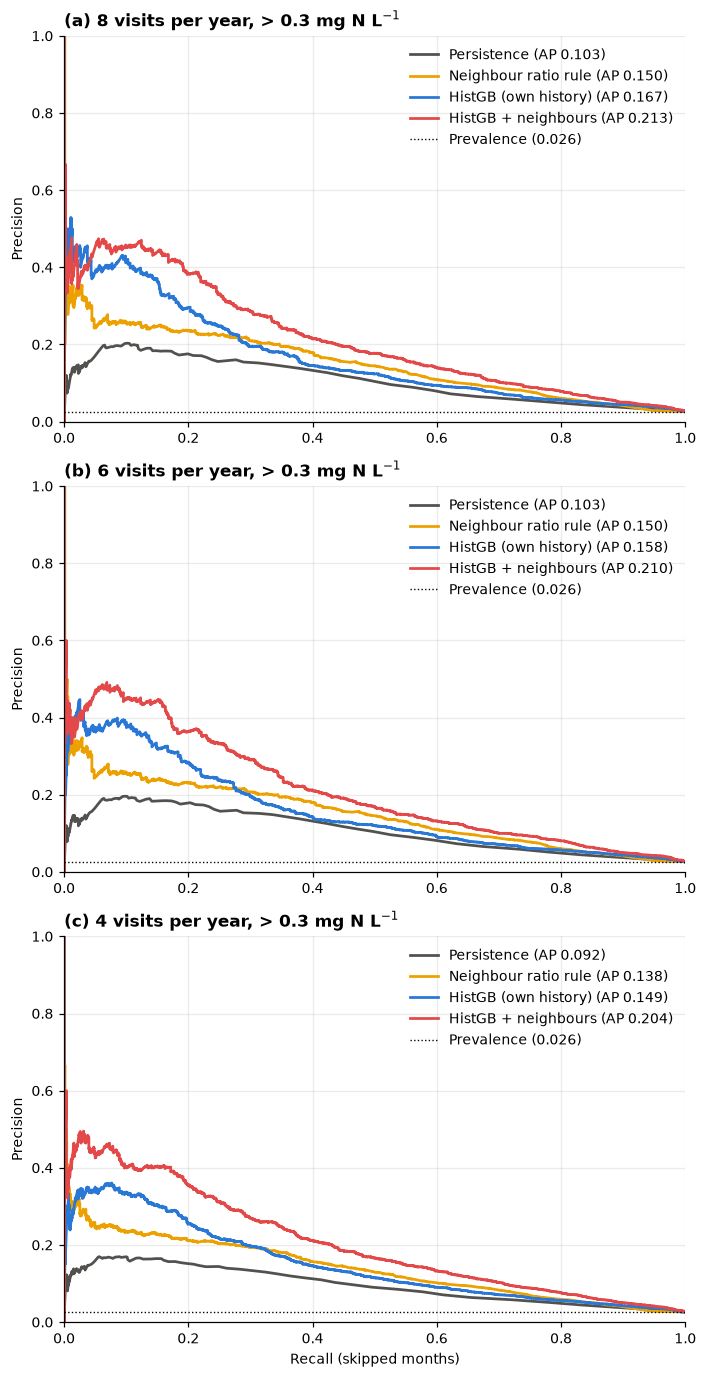

In [24]:
def pooled(items, f):
    k = len(CFG["sched"][f])
    return (pd.concat([items[(f, p)][0].assign(phase=p) for p in range(k)], ignore_index=True),
            pd.concat([items[(f, p)][1].assign(phase=p) for p in range(k)], ignore_index=True))
def labels(IT, thr): return exceed(np.exp(IT.y.values), IT.cens_target.values, thr)
def ret_events(RET, thr): return int(exceed(V[RET.s.values, RET.t.values], CEN[RET.s.values, RET.t.values], thr).sum())
def boot_ap(IT, a, b, thr, cluster, B=None, seed=SEED):
    B = CFG["n_boot"] if B is None else B; yb = labels(IT, thr); keys = IT.s.values if cluster == "station" else IT.year.values
    uk, inv = np.unique(keys, return_inverse=True); mem = [np.flatnonzero(inv == k) for k in range(len(uk))]; r = np.random.RandomState(seed); out = []
    for _ in range(B):
        idx = np.concatenate([mem[k] for k in r.randint(0, len(uk), len(uk))])
        if yb[idx].sum() == 0: continue
        out.append(average_precision_score(yb[idx], IT[a].values[idx]) - average_precision_score(yb[idx], IT[b].values[idx]))
    return average_precision_score(yb, IT[a]) - average_precision_score(yb, IT[b]), np.percentile(out, 2.5), np.percentile(out, 97.5)
rows, curves = [], {}
for f in CFG["sched"]:
    IT, _ = pooled(ITEMS, f); nph = len(CFG["sched"][f])
    for thr in THRS:
        yb = labels(IT, thr)
        for s_ in STRATS:
            rows.append({"visits/yr": f, "threshold": thr, "strategy": s_, "skipped exceedances": int(yb.sum() / nph), "PR-AUC": average_precision_score(yb, IT[s_]),
                         "ROC-AUC": roc_auc_score(yb, IT[s_]), "MAE (log)": float(np.abs(IT[s_] - IT.y).mean())})
            if thr == PRIMARY: curves[(f, s_)] = precision_recall_curve(yb, IT[s_])
        rows.append({"visits/yr": f, "threshold": thr, "strategy": "prevalence (no skill)", "PR-AUC": yb.mean()})
MAIN = pd.DataFrame(rows); save_table(MAIN, "T04_threshold_free")
display(MAIN[MAIN.threshold == PRIMARY].set_index(["visits/yr", "strategy"]).round(3))
bt = []
for f in CFG["sched"]:
    IT, _ = pooled(ITEMS, f)
    for a, b in (("HistGB_nb", "Persistence"), ("HistGB_nb", "HistGB_own"), ("HistGB_nb", "Neighbour_ratio"), ("Neighbour_ratio", "Persistence"), ("HistGB_own", "Persistence")):
        for cl in ("station", "year"):
            e, lo, hi = boot_ap(IT, a, b, PRIMARY, cl); bt.append({"visits/yr": f, "comparison": f"{a} - {b}", "cluster": cl, "dPR-AUC": e, "95% CI low": lo, "95% CI high": hi})
BT = pd.DataFrame(bt); save_table(BT, "T05_threshold_free_bootstrap"); display(BT.round(4))

# ---- Figure: precision-recall curves, one panel per row ----
n = len(CFG["sched"])
fig, ax = plt.subplots(n, 1, figsize=(6.5, 4.2 * n), sharex=True, sharey=True, squeeze=False)
ax = ax[:, 0]
for k, (a_, f) in enumerate(zip(ax, CFG["sched"])):
    sel_pr = (MAIN["visits/yr"] == f) & (MAIN.threshold == PRIMARY)
    for s_ in STRATS:
        p, r_, _ = curves[(f, s_)]
        ap = MAIN[sel_pr & (MAIN.strategy == s_)]["PR-AUC"].iloc[0]
        a_.plot(r_, p, color=COL[s_], lw=1.8, label=f"{LAB[s_]} (AP {ap:.3f})")
    prev = MAIN[sel_pr & MAIN.strategy.str.startswith("prev")]["PR-AUC"].iloc[0]
    a_.axhline(prev, color="k", ls=":", lw=0.9, label=f"Prevalence ({prev:.3f})")
    a_.set_title(f"({'abcdefgh'[k]}) {f} visits per year, > {PRIMARY} mg N L$^{{-1}}$", loc="left", fontsize=11)
    a_.set_ylabel("Precision")
    a_.set_xlim(0, 1); a_.set_ylim(0, 1)
    a_.legend(fontsize=9, frameon=False, loc="upper right")
    a_.tick_params(labelbottom=True)          # show recall ticks on every panel
ax[-1].set_xlabel("Recall (skipped months)")
fig.tight_layout()
savefig(fig, "F09_pr_curves")
plt.show()

#### 9.1 How the bootstrap confidence intervals are computed
* **Unit of resampling.** Whole stations (*station bootstrap*) or whole calendar years (*year bootstrap*), drawn with replacement; the two are run **separately** and reported side by side. A **two-way bootstrap** (below) resamples stations *and* years simultaneously: each skipped month receives the weight (number of times its station is drawn) × (number of times its year is drawn), which accounts for dependence along both dimensions at once.
* **Paired comparison.** In every replicate both strategies are scored on the **same** resampled skipped months, and the statistic is the **difference** between them. The 95% interval is the 2.5–97.5 percentile range of this difference distribution (percentile bootstrap) — it is *not* obtained by subtracting two separate intervals.
* **Metric computation.** PR-AUC (average precision) is **recomputed on the pooled resample** (all stations, years and phases together); it is not an average of per-station PR-AUC, which would be undefined for the many stations without events.
* **Stations with few events** enter with all their skipped months, including those without any exceedance; they therefore contribute negatives (false alarms) and are never dropped. Replicates that contain no exceedance at all cannot be scored and are discarded; their number is reported for the two-way bootstrap.
* **Replicates:** 1,000 (500 within distance strata); random seed 42.

In [25]:
def boot_ap_2way(IT, a, b, thr, B=None, seed=SEED):
    # two-way (station x year) paired bootstrap of the PR-AUC difference; weights = station draws x year draws
    B = CFG["n_boot"] if B is None else B; yb = labels(IT, thr); r = np.random.RandomState(seed)
    us, si = np.unique(IT.s.values, return_inverse=True); uy, yi = np.unique(IT.year.values, return_inverse=True)
    sa, sb = IT[a].values, IT[b].values; out, skipped = [], 0
    for _ in range(B):
        w = np.bincount(r.randint(0, len(us), len(us)), minlength=len(us))[si] * np.bincount(r.randint(0, len(uy), len(uy)), minlength=len(uy))[yi]
        m = w > 0
        if yb[m].sum() == 0: skipped += 1; continue
        out.append(average_precision_score(yb[m], sa[m], sample_weight=w[m]) - average_precision_score(yb[m], sb[m], sample_weight=w[m]))
    return average_precision_score(yb, IT[a]) - average_precision_score(yb, IT[b]), np.percentile(out, 2.5), np.percentile(out, 97.5), skipped
bt2 = []
for f in CFG["sched"]:
    IT, _ = pooled(ITEMS, f)
    for a, b in (("HistGB_nb", "Persistence"), ("HistGB_nb", "HistGB_own"), ("HistGB_nb", "Neighbour_ratio"), ("Neighbour_ratio", "Persistence")):
        e, lo, hi, sk = boot_ap_2way(IT, a, b, PRIMARY)
        st = BT[(BT["visits/yr"] == f) & (BT.comparison == f"{a} - {b}")].set_index("cluster")
        bt2.append({"visits/yr": f, "comparison": f"{a} - {b}", "dPR-AUC": e, "station CI": f"{st.loc['station', '95% CI low']:.3f} to {st.loc['station', '95% CI high']:.3f}",
                    "year CI": f"{st.loc['year', '95% CI low']:.3f} to {st.loc['year', '95% CI high']:.3f}", "two-way 95% CI low": lo, "two-way 95% CI high": hi,
                    "two-way replicates discarded (no event)": sk})
BT2 = pd.DataFrame(bt2); save_table(BT2, "T05b_two_way_bootstrap"); display(BT2.round(4))

,visits/yr,comparison,dPR-AUC,station CI,year CI,two-way 95% CI low,two-way 95% CI high,two-way replicates discarded (no event)
0,8,HistGB_nb - Persistence,0.11,0.067 to 0.146,0.084 to 0.141,0.056,0.1651,0
1,8,HistGB_nb - HistGB_own,0.0459,0.029 to 0.065,0.022 to 0.070,0.016,0.0805,0
2,8,HistGB_nb - Neighbour_ratio,0.0631,0.019 to 0.108,0.041 to 0.096,0.0092,0.1266,0
3,8,Neighbour_ratio - Persistence,0.0469,0.025 to 0.070,0.018 to 0.074,0.009,0.0839,0
4,6,HistGB_nb - Persistence,0.1069,0.062 to 0.147,0.083 to 0.134,0.0523,0.1606,0
5,6,HistGB_nb - HistGB_own,0.0516,0.035 to 0.070,0.030 to 0.073,0.0234,0.083,0
6,6,HistGB_nb - Neighbour_ratio,0.0604,0.013 to 0.108,0.040 to 0.091,0.0059,0.1272,0
7,6,Neighbour_ratio - Persistence,0.0465,0.025 to 0.070,0.019 to 0.072,0.0096,0.0845,0
8,4,HistGB_nb - Persistence,0.1122,0.066 to 0.152,0.086 to 0.141,0.057,0.1674,0
9,4,HistGB_nb - HistGB_own,0.0551,0.037 to 0.073,0.031 to 0.080,0.0243,0.0894,0


> **Interpretation — threshold-free evaluation (skipped months, > 0.3 mg N L⁻¹).**
> * **HistGB + neighbours is best on every metric**: AP 0.204 at 4 visits/yr (persistence 0.092, neighbour ratio 0.138, own history 0.149; prevalence 0.026), ROC-AUC 0.850 (0.760) and the lowest error (MAE 0.300 vs 0.380 log units). Results are almost identical at 6 and 8 visits/yr (0.210 and 0.213).
> * **The improvement is robust under every bootstrap design**: Δ AP versus persistence +0.112 (95% CI 0.066–0.152 by station; 0.086–0.141 by year; 0.057–0.167 two-way, station × year).
> * **Decomposition of the gain**: flexible modelling of the station's own history adds +0.057 over persistence (0.023–0.087), and same-month neighbour information adds a further +0.055 (0.037–0.073 by station; 0.024–0.089 two-way). HistGB + neighbours also exceeds the neighbour-ratio rule (+0.066; 0.019–0.112 by station, 0.013–0.129 two-way). With this unbiased cohort the learned model therefore contributes beyond a simple rule, but spatial information remains essential: without neighbours the model reaches only 0.149.
> * Absolute AP values are low because exceedances are rare and episodic; relative to the 2.6% prevalence the best strategy ranks skipped months about eight times better than chance. No two-way bootstrap replicate had to be discarded.

<a id="10"></a>
## 10. Experiment 1 — Pre-selected alarm cut-offs

For every strategy, visit frequency and threshold, the alarm cut-off on the predicted concentration is chosen **on the development period** (reduction simulated from 2005; models trained on data before 2005) and then **frozen** for 2008–2024:

* **F1 rule** — cut-off maximising F1 on development skipped months;
* **FA-budget rule** — lowest (most sensitive) cut-off with ≤ 0.1 false alarms per station-year on the development period;
* **Nominal rule** — alarm when the prediction exceeds the threshold itself (no calibration).

Recall and precision are computed over **all** evaluation months (visited months are known exactly).

In [26]:
GRID = np.round(np.exp(np.linspace(np.log(0.05), np.log(3.0), 200)), 4)
def choose_cutoffs(f, thr):
    IT, _ = pooled(DEV_ITEMS, f); yb = labels(IT, thr); nph = len(CFG["sched"][f]); cuts = {}
    for s_ in STRATS:
        sc = np.exp(IT[s_].values)
        f1 = [2 * ((sc > c) & yb).sum() / max(2 * ((sc > c) & yb).sum() + ((sc > c) & ~yb).sum() + (~(sc > c) & yb).sum(), 1) for c in GRID]
        fa = np.array([((sc > c) & ~yb).sum() / nph / n_sy_dev for c in GRID]); ok = np.flatnonzero(fa <= CFG["fa_budget"])
        cuts[(s_, "F1")] = float(GRID[int(np.argmax(f1))]); cuts[(s_, "FA-budget")] = float(GRID[ok[0]]) if len(ok) else float(GRID[-1]); cuts[(s_, "nominal")] = thr
    return cuts
def evaluate_fixed(items, f, thr, cuts, n_sy):
    IT, RET = pooled(items, f); yb = labels(IT, thr); nph = len(CFG["sched"][f]); rev = ret_events(RET, thr); tot = yb.sum() + rev
    out = [{"strategy": "Observation-only", "rule": "-", "cut-off": np.nan, "recall": rev / tot, "precision": 1.0, "F1": 2 * rev / (rev + tot),
            "missed / station-yr": (tot - rev) / nph / n_sy, "false alarms / station-yr": 0.0}]
    for (s_, rule), c in cuts.items():
        a = np.exp(IT[s_].values) > c; tp, fp, fn = (a & yb).sum() + rev, (a & ~yb).sum(), (~a & yb).sum()
        out.append({"strategy": s_, "rule": rule, "cut-off": c, "recall": tp / tot, "precision": tp / (tp + fp), "F1": 2 * tp / (2 * tp + fp + fn),
                    "missed / station-yr": fn / nph / n_sy, "false alarms / station-yr": fp / nph / n_sy})
    return pd.DataFrame(out).assign(**{"visits/yr": f, "threshold": thr, "events": int(tot / nph)})
CUTS = {(f, thr): choose_cutoffs(f, thr) for f in CFG["sched"] for thr in THRS}
FIX = pd.concat([evaluate_fixed(ITEMS, f, thr, CUTS[(f, thr)], n_sy_eval) for f in CFG["sched"] for thr in THRS], ignore_index=True)
save_table(FIX, "T06_fixed_cutoffs")
display(FIX[FIX.threshold == PRIMARY].set_index(["visits/yr", "rule", "strategy"])[["cut-off", "recall", "precision", "F1", "missed / station-yr", "false alarms / station-yr"]].round(3))

cut-off  recall  precision    F1  missed / station-yr  false alarms / station-yr
visits/yr rule      strategy                                                                                          
8         -         Observation-only      NaN   0.667          1   0.8                0.099                          0
          F1        Persistence         0.224   0.759      0.611 0.677                0.072                      0.143
          FA-budget Persistence         0.325   0.721      0.748 0.734                0.083                      0.072
          nominal   Persistence           0.3   0.726      0.726 0.726                0.081                      0.081
          F1        Neighbour_ratio     0.234   0.805      0.536 0.644                0.058                      0.207
          FA-budget Neighbour_ratio     0.491   0.728      0.781 0.754                0.081                      0.061
          nominal   Neighbour_ratio       0.3   0.783      0.623 0.694                0.065                       0.14
          F1        HistGB_own          0.183   0.749      0.752  0.75                0.075                      0.074
          FA-budget HistGB_own          0.207    0.73      0.826 0.775                 0.08                      0.046
          nominal   HistGB_own            0.3   0.689      0.955   0.8                0.092                       0.01
          F1        HistGB_nb           0.198   0.758      0.781 0.769                0.072                      0.063
          FA-budget HistGB_nb           0.203   0.754      0.794 0.774                0.073                      0.058
          nominal   HistGB_nb             0.3   0.694      0.952 0.803                0.091                       0.01
6         -         Observation-only      NaN     0.5          1 0.667                0.148                          0
          F1        Persistence         0.224   0.639      0.466 0.539                0.107                      0.217
          FA-budget Persistence         0.408   0.557      0.697 0.619                0.131                      0.072
          nominal   Persistence           0.3    0.59      0.591 0.591                0.122                      0.121
          F1        Neighbour_ratio     0.234    0.71      0.404 0.515                0.086                      0.311
          FA-budget Neighbour_ratio     0.641   0.566      0.735  0.64                0.129                       0.06
          nominal   Neighbour_ratio       0.3   0.673      0.488 0.565                0.097                       0.21
          F1        HistGB_own          0.216   0.592       0.74 0.658                0.121                      0.062
          FA-budget HistGB_own           0.22   0.585      0.756  0.66                0.123                      0.056
          nominal   HistGB_own            0.3    0.53      0.912  0.67                 0.14                      0.015
          F1        HistGB_nb           0.211   0.624      0.715 0.666                0.112                      0.074
          FA-budget HistGB_nb            0.22   0.613      0.747 0.674                0.115                      0.062
          nominal   HistGB_nb             0.3   0.545      0.914 0.683                0.135                      0.015
4         -         Observation-only      NaN   0.333          1   0.5                0.198                          0
          F1        Persistence         0.224   0.499      0.337 0.402                0.149                      0.292
          FA-budget Persistence         0.471   0.386      0.593 0.467                0.182                      0.079
          nominal   Persistence           0.3    0.44       0.44  0.44                0.166                      0.167
          F1        Neighbour_ratio     0.318   0.541      0.384 0.449                0.136                      0.258
          FA-budget Neighbour_ratio     0.821   0.392      0.678 0.497                0.181                    

,visits/yr,threshold,rule,comparison,cluster,d recall,recall CI low,recall CI high,d F1,F1 CI low,F1 CI high
12,8,0.3,F1,HistGB_nb - Persistence,station,-0.001,-0.013,0.01,0.092,0.068,0.122
13,8,0.3,F1,HistGB_nb - Persistence,year,-0.001,-0.012,0.008,0.092,0.08,0.103
14,8,0.3,F1,HistGB_nb - HistGB_own,station,0.009,-0.003,0.023,0.019,0.005,0.033
15,8,0.3,F1,HistGB_nb - HistGB_own,year,0.009,-0.002,0.02,0.019,0.01,0.027
16,8,0.3,F1,Neighbour_ratio - Persistence,station,0.046,0.032,0.06,-0.033,-0.05,-0.02
17,8,0.3,F1,Neighbour_ratio - Persistence,year,0.046,0.028,0.058,-0.033,-0.054,-0.014
18,8,0.3,FA-budget,HistGB_nb - Persistence,station,0.033,0.015,0.051,0.039,0.021,0.062
19,8,0.3,FA-budget,HistGB_nb - Persistence,year,0.033,0.023,0.043,0.039,0.027,0.049
20,8,0.3,FA-budget,HistGB_nb - HistGB_own,station,0.024,0.012,0.038,-0.001,-0.014,0.01
21,8,0.3,FA-budget,HistGB_nb - HistGB_own,year,0.024,0.013,0.036,-0.001,-0.012,0.006


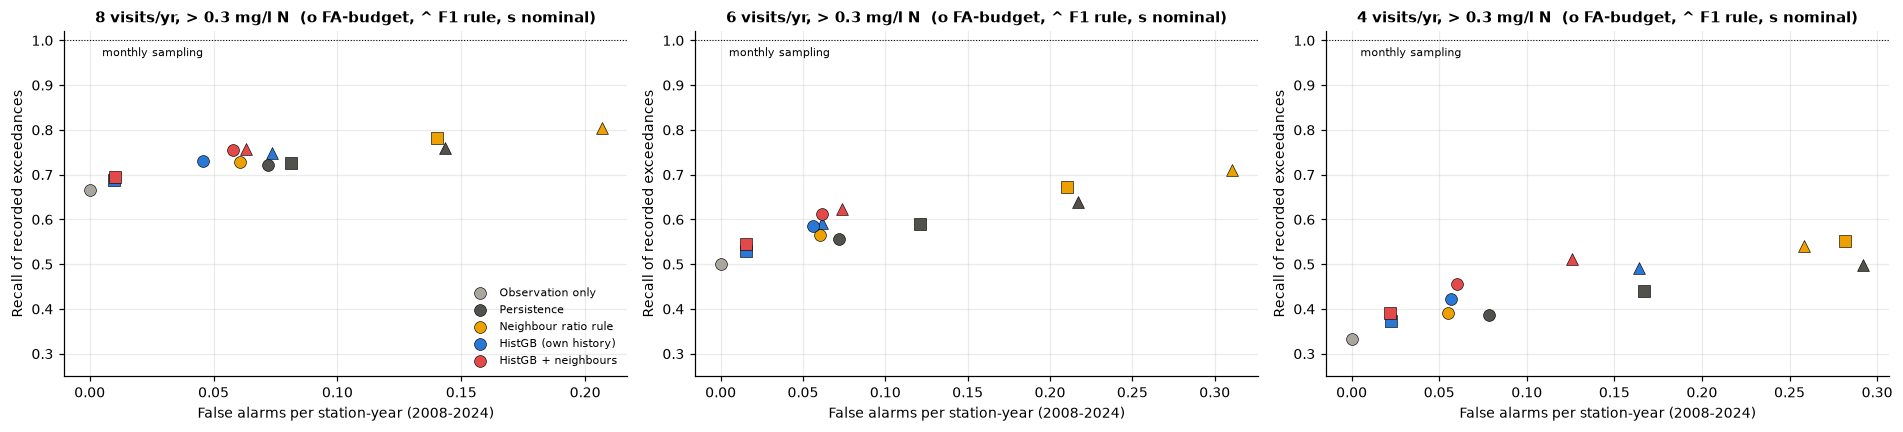

In [27]:
def boot_fixed(f, thr, a, b, rule, cluster, B=None, seed=SEED):
    B = CFG["n_boot"] if B is None else B; cuts = CUTS[(f, thr)]; IT, RET = pooled(ITEMS, f); yb = labels(IT, thr)
    Re = exceed(V[RET.s.values, RET.t.values], CEN[RET.s.values, RET.t.values], thr)
    ki = IT.s.values if cluster == "station" else IT.year.values; kr = RET.s.values if cluster == "station" else yr[RET.t.values]
    uk = np.unique(np.concatenate([ki, kr])); gi, gr, K = np.searchsorted(uk, ki), np.searchsorted(uk, kr), len(uk)
    def comp(s_):
        al = np.exp(IT[s_].values) > cuts[(s_, rule)]
        return (np.bincount(gi, (al & yb).astype(float), K) + np.bincount(gr, Re.astype(float), K), np.bincount(gi, (al & ~yb).astype(float), K), np.bincount(gi, (~al & yb).astype(float), K))
    (ta, fa, na), (tb, fb, nb_) = comp(a), comp(b); dd = np.random.RandomState(seed).randint(0, K, (B, K))
    rec = lambda tp, fn: tp[dd].sum(1) / (tp[dd].sum(1) + fn[dd].sum(1)); f1 = lambda tp, fp, fn: 2 * tp[dd].sum(1) / (2 * tp[dd].sum(1) + fp[dd].sum(1) + fn[dd].sum(1))
    dR, dF = rec(ta, na) - rec(tb, nb_), f1(ta, fa, na) - f1(tb, fb, nb_)
    eR = ta.sum() / (ta.sum() + na.sum()) - tb.sum() / (tb.sum() + nb_.sum()); eF = 2 * ta.sum() / (2 * ta.sum() + fa.sum() + na.sum()) - 2 * tb.sum() / (2 * tb.sum() + fb.sum() + nb_.sum())
    return {"d recall": eR, "recall CI low": np.percentile(dR, 2.5), "recall CI high": np.percentile(dR, 97.5), "d F1": eF, "F1 CI low": np.percentile(dF, 2.5), "F1 CI high": np.percentile(dF, 97.5)}
BF = pd.DataFrame([{"visits/yr": f, "threshold": thr, "rule": rule, "comparison": f"{a} - {b}", "cluster": cl, **boot_fixed(f, thr, a, b, rule, cl)}
                   for f in CFG["sched"] for thr in (0.2, 0.3) for rule in ("F1", "FA-budget")
                   for a, b in (("HistGB_nb", "Persistence"), ("HistGB_nb", "HistGB_own"), ("Neighbour_ratio", "Persistence")) for cl in ("station", "year")])
save_table(BF, "T07_fixed_cutoffs_bootstrap"); display(BF[BF.threshold == PRIMARY].round(3))
fig, ax = plt.subplots(1, len(CFG["sched"]), figsize=(5.8 * len(CFG["sched"]), 4))
for a_, f in zip(ax, CFG["sched"]):
    x = FIX[(FIX["visits/yr"] == f) & (FIX.threshold == PRIMARY)]
    for _, r in x.iterrows():
        mk = {"-": "o", "FA-budget": "o", "F1": "^", "nominal": "s"}[r.rule]; a_.scatter(r["false alarms / station-yr"], r.recall, marker=mk, s=60, color=COL[r.strategy], edgecolor="k", lw=.4, zorder=3,
                                                                                           label=LAB[r.strategy] if r.rule in ("-", "FA-budget") else None)
    a_.axhline(1, color="k", ls=":", lw=.7); a_.text(0.005, .985, "monthly sampling", fontsize=7, va="top")
    a_.set_xlabel("False alarms per station-year (2008-2024)"); a_.set_ylabel("Recall of recorded exceedances"); a_.set_ylim(.25, 1.02)
    a_.set_title(f"{f} visits/yr, > {PRIMARY} mg/l N  (o FA-budget, ^ F1 rule, s nominal)")
ax[0].legend(fontsize=7, loc="lower right"); fig.tight_layout(); savefig(fig, "F10_fixed_cutoffs"); plt.show()

> **Interpretation — Experiment 1 (alarm cut-offs fixed on 2005–2007).**
> * **FA-budget rule, 4 visits/yr, > 0.3 mg N L⁻¹:** recall of recorded exceedances is 33.3% (observation only), 38.6% (persistence), 39.2% (neighbour ratio), 42.2% (own history) and **45.7% (HistGB + neighbours)**, with precision 0.69 (persistence 0.59) and 0.060 false alarms per station-year. Δ recall versus persistence +7.1 points (CI 2.7–11.3 by station; 4.7–9.2 by year); Δ F1 +0.083 (0.060–0.103); versus own history +3.5 points (1.9–5.2). About **19% of the exceedances missed by reduced sampling are recovered** (23% at 6/yr, 26% at 8/yr). The neighbour-ratio rule does not improve recall over persistence at this budget (+0.6 points, CI −1.8 to 3.1) although it raises precision.
> * **Other frequencies:** 8 visits/yr: 66.7% → 72.1% (persistence) → 75.4%; 6 visits/yr: 50.0% → 55.7% → 61.3%.
> * **F1 rule:** higher recall but many more false alarms; at 4/yr persistence reaches 49.9% recall with 0.29 false alarms per station-year (precision 0.34), HistGB + neighbours 51.1% with 0.13 (precision 0.55).
> * **Nominal rule:** regression models rarely alarm (HistGB + neighbours: recall 39.0%, precision 0.84) because they predict typical rather than peak values — **calibrating the alarm cut-off is essential**.
> * **Calibration drift:** cut-offs targeting 0.1 false alarms per station-year in 2005–2007 produce 0.046–0.079 in 2008–2024 (lower concentrations, changed censoring regime). Periodic recalibration on stations that remain monthly is a practical remedy.

<a id="11"></a>
## 11. Experiment 2 — Spatial generalisation to unseen stations

unseen-design models fitted in 242s


threshold  PR-AUC  MAE (log)  recall (FA-budget)  false alarms / station-yr
visits/yr model       design                                                                             
8         HistGB_own  seen          0.3  0.1673     0.3225              0.7303                     0.0456
                      unseen        0.3  0.1581     0.3231              0.7218                     0.0416
          HistGB_nb   seen          0.3  0.2132     0.2943              0.7544                      0.058
                      unseen        0.3  0.2087     0.2963               0.746                     0.0469
          Persistence -             0.3  0.1032     0.3635                 NaN                        NaN
6         HistGB_own  seen          0.3  0.1584     0.3252              0.5851                      0.056
                      unseen        0.3  0.1506     0.3255              0.5725                     0.0491
          HistGB_nb   seen          0.3  0.2099     0.2961              0.6129                     0.0615
                      unseen        0.3  0.2034     0.2982              0.5948                     0.0493
          Persistence -             0.3  0.1031     0.3628                 NaN                        NaN
4         HistGB_own  seen          0.3  0.1493     0.3299              0.4223                     0.0567
                      unseen        0.3  0.1417     0.3307              0.4022                     0.0493
          HistGB_nb   seen          0.3  0.2044     0.2999              0.4569                       0.06
                      unseen        0.3  0.1966     0.3023                0.43                     0.0466
          Persistence -             0.3  0.0922     0.3797                 NaN                        NaN

,visits/yr,threshold,comparison,dPR-AUC,95% CI low,95% CI high
0,8,0.2,HistGB_nb unseen - HistGB_nb seen,-0.0037,-0.0161,0.0091
1,8,0.2,HistGB_nb unseen - Persistence,0.1774,0.1445,0.2058
2,8,0.3,HistGB_nb unseen - HistGB_nb seen,-0.0045,-0.0169,0.0073
3,8,0.3,HistGB_nb unseen - Persistence,0.1055,0.069,0.1336
4,6,0.2,HistGB_nb unseen - HistGB_nb seen,-0.0058,-0.0175,0.0067
5,6,0.2,HistGB_nb unseen - Persistence,0.1689,0.1343,0.1991
6,6,0.3,HistGB_nb unseen - HistGB_nb seen,-0.0065,-0.0197,0.0063
7,6,0.3,HistGB_nb unseen - Persistence,0.1003,0.0634,0.1314
8,4,0.2,HistGB_nb unseen - HistGB_nb seen,-0.007,-0.017,0.0036
9,4,0.2,HistGB_nb unseen - Persistence,0.1812,0.1432,0.2136


,cluster,stations,events,Persistence,seen,unseen
0,0,28,52,0.044,0.08,0.075
1,1,31,18,0.022,0.096,0.096
2,2,28,35,0.097,0.191,0.183
3,3,25,41,0.058,0.183,0.175
4,4,34,64,0.072,0.175,0.172
5,5,24,136,0.17,0.3,0.292
6,6,33,75,0.246,0.327,0.304
7,7,22,36,0.029,0.124,0.131
8,8,32,12,0.015,0.021,0.021
9,9,24,81,0.069,0.184,0.174


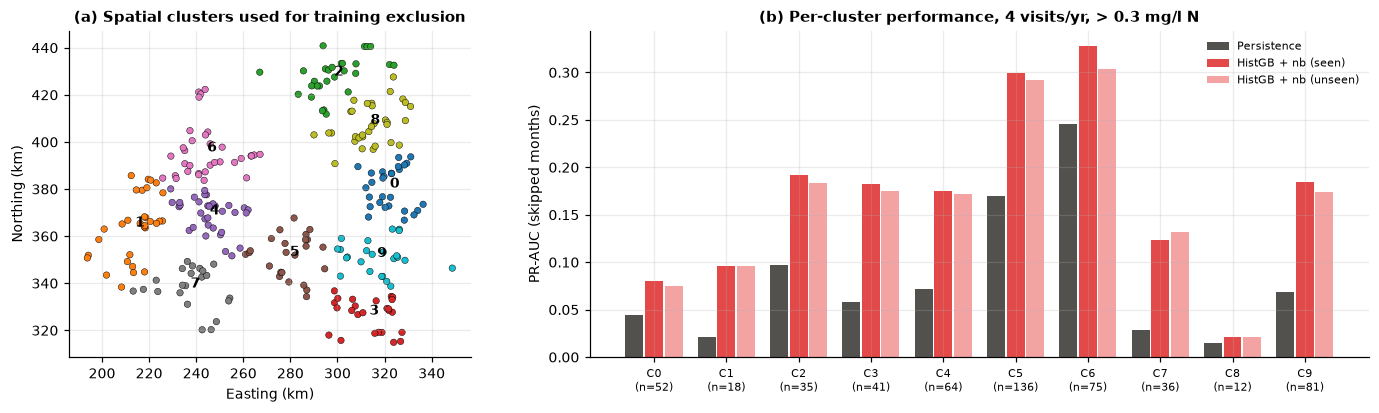

In [28]:
t_ = time.time(); P_UNSEEN = run_models(ITEMS, "unseen"); print(f"unseen-design models fitted in {time.time() - t_:.0f}s")
UNS = {k: (v[0].copy(), v[1]) for k, v in ITEMS.items()}
for k, (IT, _) in UNS.items():
    for n in MODELS: IT[n] = P_UNSEEN[k][n]
rows = []
for f in CFG["sched"]:
    ITs, RETs = pooled(ITEMS, f); ITu, _ = pooled(UNS, f)
    for thr in THRS:
        yb = labels(ITs, thr); rev = ret_events(RETs, thr); tot = yb.sum() + rev
        for n in MODELS:
            for design, IT in (("seen", ITs), ("unseen", ITu)):
                a = np.exp(IT[n].values) > CUTS[(f, thr)][(n, "FA-budget")]
                rows.append({"visits/yr": f, "threshold": thr, "model": n, "design": design, "PR-AUC": average_precision_score(yb, IT[n]), "MAE (log)": float(np.abs(IT[n] - IT.y).mean()),
                             "recall (FA-budget)": ((a & yb).sum() + rev) / tot, "false alarms / station-yr": (a & ~yb).sum() / len(CFG["sched"][f]) / n_sy_eval})
        rows.append({"visits/yr": f, "threshold": thr, "model": "Persistence", "design": "-", "PR-AUC": average_precision_score(yb, ITs.Persistence), "MAE (log)": float(np.abs(ITs.Persistence - ITs.y).mean())})
GEN = pd.DataFrame(rows); save_table(GEN, "T08_spatial_generalisation")
display(GEN[GEN.threshold == PRIMARY].set_index(["visits/yr", "model", "design"]).round(4))
bg = []
for f in CFG["sched"]:
    ITs, _ = pooled(ITEMS, f); ITu, _ = pooled(UNS, f)
    J = ITs[["s", "year", "y", "cens_target", "Persistence"]].copy(); J["seen"] = ITs.HistGB_nb.values; J["unseen"] = ITu.HistGB_nb.values
    for thr in (0.2, 0.3):
        for a, b in (("unseen", "seen"), ("unseen", "Persistence")):
            e, lo, hi = boot_ap(J, a, b, thr, "station"); bg.append({"visits/yr": f, "threshold": thr, "comparison": f"HistGB_nb {a} - {'HistGB_nb seen' if b == 'seen' else b}", "dPR-AUC": e, "95% CI low": lo, "95% CI high": hi})
BG = pd.DataFrame(bg); save_table(BG, "T09_spatial_generalisation_bootstrap"); display(BG.round(4))
ITs, _ = pooled(ITEMS, 4); ITu, _ = pooled(UNS, 4); yb = labels(ITs, PRIMARY); pg = []
for g in range(CFG["n_groups"]):
    m = (ITs.group == g).values
    if yb[m].sum() >= 5:
        pg.append({"cluster": g, "stations": int((groups == g).sum()), "events": int(yb[m].sum() / 3), "Persistence": average_precision_score(yb[m], ITs.Persistence[m]),
                   "seen": average_precision_score(yb[m], ITs.HistGB_nb[m]), "unseen": average_precision_score(yb[m], ITu.HistGB_nb[m])})
PG = pd.DataFrame(pg); save_table(PG, "T08b_spatial_generalisation_by_cluster"); display(PG.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].scatter(xy[:, 0] / 1000, xy[:, 1] / 1000, c=groups, cmap="tab10", s=18, edgecolor="k", lw=.3); ax[0].set_aspect("equal")
for g in range(CFG["n_groups"]):
    c = xy[groups == g].mean(0) / 1000; ax[0].text(c[0], c[1], str(g), fontsize=9, weight="bold")
ax[0].set_title("(a) Spatial clusters used for training exclusion"); ax[0].set_xlabel("Easting (km)"); ax[0].set_ylabel("Northing (km)")
x = np.arange(len(PG)); w = .27
for i, (c, lab, cc) in enumerate((("Persistence", "Persistence", "#52514e"), ("seen", "HistGB + nb (seen)", "#e34948"), ("unseen", "HistGB + nb (unseen)", "#f4a3a3"))):
    ax[1].bar(x + (i - 1) * w, PG[c], w * .92, color=cc, label=lab)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"C{g}\n(n={n})" for g, n in zip(PG.cluster, PG.events)], fontsize=7); ax[1].set_ylabel("PR-AUC (skipped months)")
ax[1].set_title(f"(b) Per-cluster performance, 4 visits/yr, > {PRIMARY} mg/l N"); ax[1].legend(fontsize=7)
fig.tight_layout(); savefig(fig, "F11_spatial_generalisation"); plt.show()

> **Interpretation — Experiment 2 (spatial generalisation).** Excluding the entire spatial cluster of the target station from training changes AP only slightly: 0.204 (seen) vs 0.197 (unseen) at 4 visits per year (Δ −0.008, CI −0.022 to +0.004), 0.210 vs 0.203 at 6 and 0.213 vs 0.209 at 8 visits per year. The unseen model still clearly beats persistence (+0.104, CI 0.063–0.138). At the pre-selected cut-off, however, recall falls from 45.7% to 43.0%, which is no higher than the station-specific seasonal climatology (43.2%, Section 14b): ranking skill transfers to stations not used for training, the operational gain does not. This tests transfer **within** the network; it is not an external validation.

<a id="12"></a>
## 12. Experiment 3 — Robustness to neighbour distance and exceedance threshold

In [29]:
rows = []
for f in CFG["sched"]:
    IT, _ = pooled(ITEMS, f); nph = len(CFG["sched"][f])
    dc = pd.cut(IT.nb1_km, [0, 2, 5, 10, 15], labels=["0-2 km", "2-5 km", "5-10 km", "10-15 km"]).astype(str).where(IT.nb1_km.notna(), "no neighbour sampled")
    for thr in (0.2, 0.3):
        yb = labels(IT, thr)
        for c in ["0-2 km", "2-5 km", "5-10 km", "10-15 km", "no neighbour sampled"]:
            m = (dc == c).values
            if yb[m].sum() < 10: continue
            sub = IT[m].reset_index(drop=True); e, lo, hi = boot_ap(sub, "HistGB_nb", "Persistence", thr, "station", B=CFG["n_boot_strata"])
            rows.append({"visits/yr": f, "threshold": thr, "distance": c, "skipped months": int(m.sum() / nph), "events": int(yb[m].sum() / nph),
                         **{f"PR-AUC {s_}": average_precision_score(yb[m], sub[s_]) for s_ in STRATS}, "dPR-AUC (nb - persistence)": e, "95% CI low": lo, "95% CI high": hi})
DIST = pd.DataFrame(rows); save_table(DIST, "T10_distance_strata"); display(DIST.round(3))

,visits/yr,threshold,distance,skipped months,events,PR-AUC Persistence,PR-AUC Neighbour_ratio,PR-AUC HistGB_own,PR-AUC HistGB_nb,dPR-AUC (nb - persistence),95% CI low,95% CI high
0,8,0.2,0-2 km,3790,213,0.213,0.256,0.308,0.369,0.156,0.104,0.212
1,8,0.2,2-5 km,4577,252,0.157,0.221,0.246,0.321,0.165,0.127,0.211
2,8,0.2,5-10 km,1417,82,0.338,0.328,0.534,0.57,0.232,0.109,0.274
3,8,0.2,no neighbour sampled,765,22,0.077,0.077,0.146,0.159,0.082,0.03,0.157
4,8,0.3,0-2 km,3790,102,0.114,0.157,0.178,0.215,0.101,0.039,0.17
5,8,0.3,2-5 km,4577,120,0.08,0.149,0.111,0.169,0.089,0.06,0.126
6,8,0.3,5-10 km,1417,42,0.215,0.187,0.322,0.375,0.16,0.058,0.186
7,8,0.3,no neighbour sampled,765,11,0.033,0.033,0.04,0.041,0.008,-0.011,0.018
8,6,0.2,0-2 km,5688,320,0.212,0.257,0.301,0.367,0.155,0.106,0.208
9,6,0.2,2-5 km,6865,379,0.159,0.221,0.238,0.312,0.153,0.117,0.199


In [30]:
RAD = {CFG["nb_km"]: {k: ITEMS[k] for k in ((4, 0), (4, 1), (4, 2))}}; t_ = time.time()
for radius in CFG["radii"]:
    pr = make_pairs(radius); items_r = {k: skipped_items(CFG["sched"][4][k[1]], CFG["eval"][0], EVAL, radius)[:2] for k in ((4, 0), (4, 1), (4, 2))}
    pr_pred = run_models(items_r, "seen", pairs=pr, cols_map={"HistGB_nb": OWN + NBC})
    for k, (IT, _) in items_r.items(): IT["HistGB_nb"] = pr_pred[k]["HistGB_nb"]
    RAD[radius] = items_r
print(f"radius-restricted models fitted in {time.time() - t_:.0f}s")
IT15, _ = pooled(ITEMS, 4); rows = []
for radius, items in sorted(RAD.items()):
    IT = pd.concat([items[(4, p)][0] for p in range(3)], ignore_index=True)
    for thr in (0.2, 0.3, 0.6):
        yb = labels(IT, thr)
        rows.append({"radius (km)": radius, "threshold": thr, "skipped months with a neighbour": (IT.nb_n > 0).mean(), "PR-AUC HistGB + nb": average_precision_score(yb, IT.HistGB_nb),
                     "MAE (log) HistGB + nb": float(np.abs(IT.HistGB_nb - IT.y).mean()), "PR-AUC own history": average_precision_score(yb, IT15.HistGB_own), "PR-AUC persistence": average_precision_score(yb, IT15.Persistence)})
RADT = pd.DataFrame(rows); save_table(RADT, "T11_radius_restriction"); display(RADT.round(4))

radius-restricted models fitted in 458s


,radius (km),threshold,skipped months with a neighbour,PR-AUC HistGB + nb,MAE (log) HistGB + nb,PR-AUC own history,PR-AUC persistence
0,2,0.2,0.3578,0.3117,0.3209,0.29,0.1733
1,2,0.3,0.3578,0.1637,0.3209,0.1493,0.0922
2,2,0.6,0.3578,0.0437,0.3209,0.0394,0.0272
3,5,0.2,0.7903,0.3561,0.3027,0.29,0.1733
4,5,0.3,0.7903,0.1934,0.3027,0.1493,0.0922
5,5,0.6,0.7903,0.0506,0.3027,0.0394,0.0272
6,10,0.2,0.9242,0.3652,0.2996,0.29,0.1733
7,10,0.3,0.9242,0.2074,0.2996,0.1493,0.0922
8,10,0.6,0.9242,0.0566,0.2996,0.0394,0.0272
9,15,0.2,0.927,0.3614,0.2999,0.29,0.1733


,visits/yr,threshold,events,d nb-pers,nb-pers low,nb-pers high,d nb-own,nb-own low,nb-own high,d ratio-pers,ratio-pers low,ratio-pers high
0,8,0.2,571,0.1811,0.1415,0.2163,0.0626,0.046,0.0852,0.0478,0.027,0.0697
1,8,0.3,276,0.11,0.0674,0.1459,0.0459,0.0292,0.0648,0.0469,0.025,0.0705
2,8,0.4,166,0.073,0.0362,0.111,0.0385,0.0205,0.0618,0.0485,0.0277,0.0715
3,8,0.6,83,0.0242,0.0099,0.0429,0.0138,0.0062,0.0248,0.0325,0.0187,0.0504
4,6,0.2,857,0.1746,0.1354,0.2099,0.0628,0.0448,0.0866,0.0474,0.0254,0.0694
5,6,0.3,414,0.1069,0.0617,0.1473,0.0516,0.035,0.0696,0.0465,0.0253,0.0695
6,6,0.4,250,0.073,0.0322,0.1156,0.0457,0.0266,0.069,0.0483,0.0276,0.0714
7,6,0.6,125,0.0256,0.0101,0.046,0.0177,0.0093,0.0298,0.0316,0.0183,0.05
8,4,0.2,1143,0.1881,0.1469,0.2244,0.0714,0.0551,0.0905,0.0537,0.0366,0.072
9,4,0.3,552,0.1122,0.0657,0.1516,0.0551,0.0371,0.0733,0.0462,0.028,0.0662


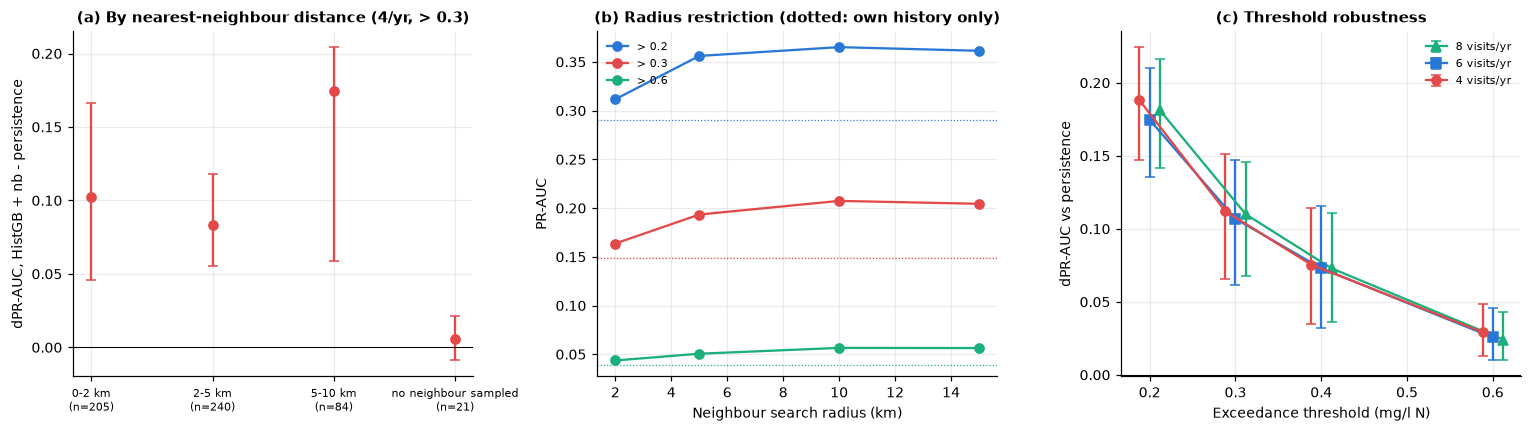

In [31]:
rows = []
for f in CFG["sched"]:
    IT, _ = pooled(ITEMS, f)
    for thr in THRS:
        r_ = {"visits/yr": f, "threshold": thr, "events": int(labels(IT, thr).sum() / len(CFG["sched"][f]))}
        for a, b, tag in (("HistGB_nb", "Persistence", "nb-pers"), ("HistGB_nb", "HistGB_own", "nb-own"), ("Neighbour_ratio", "Persistence", "ratio-pers")):
            e, lo, hi = boot_ap(IT, a, b, thr, "station"); r_.update({f"d {tag}": e, f"{tag} low": lo, f"{tag} high": hi})
        rows.append(r_)
THR = pd.DataFrame(rows); save_table(THR, "T12_threshold_robustness"); display(THR.round(4))
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
x = DIST[(DIST["visits/yr"] == 4) & (DIST.threshold == PRIMARY)]
ax[0].errorbar(range(len(x)), x["dPR-AUC (nb - persistence)"], yerr=[x["dPR-AUC (nb - persistence)"] - x["95% CI low"], x["95% CI high"] - x["dPR-AUC (nb - persistence)"]], fmt="o", color="#e34948", capsize=3)
ax[0].axhline(0, color="k", lw=.7); ax[0].set_xticks(range(len(x))); ax[0].set_xticklabels([f"{a}\n(n={n})" for a, n in zip(x.distance, x.events)], fontsize=7)
ax[0].set_ylabel("dPR-AUC, HistGB + nb - persistence"); ax[0].set_title(f"(a) By nearest-neighbour distance (4/yr, > {PRIMARY})")
for thr, c in zip((0.2, 0.3, 0.6), ("#2a78d6", "#e34948", "#1baf7a")):
    r = RADT[RADT.threshold == thr]; ax[1].plot(r["radius (km)"], r["PR-AUC HistGB + nb"], "o-", color=c, label=f"> {thr}"); ax[1].axhline(r["PR-AUC own history"].iloc[0], color=c, ls=":", lw=.8)
ax[1].set_xlabel("Neighbour search radius (km)"); ax[1].set_ylabel("PR-AUC"); ax[1].set_title("(b) Radius restriction (dotted: own history only)"); ax[1].legend(fontsize=7)
for f, mk, c in ((8, "^", "#1baf7a"), (6, "s", "#2a78d6"), (4, "o", "#e34948")):
    r = THR[THR["visits/yr"] == f]; ax[2].errorbar(r.threshold + {8: .012, 6: 0, 4: -.012}[f], r["d nb-pers"], yerr=[r["d nb-pers"] - r["nb-pers low"], r["nb-pers high"] - r["d nb-pers"]], fmt=mk + "-", capsize=3, color=c, label=f"{f} visits/yr")
ax[2].axhline(0, color="k", lw=.7); ax[2].set_xlabel("Exceedance threshold (mg/l N)"); ax[2].set_ylabel("dPR-AUC vs persistence"); ax[2].set_title("(c) Threshold robustness"); ax[2].legend(fontsize=7)
fig.tight_layout(); savefig(fig, "F12_distance_threshold"); plt.show()

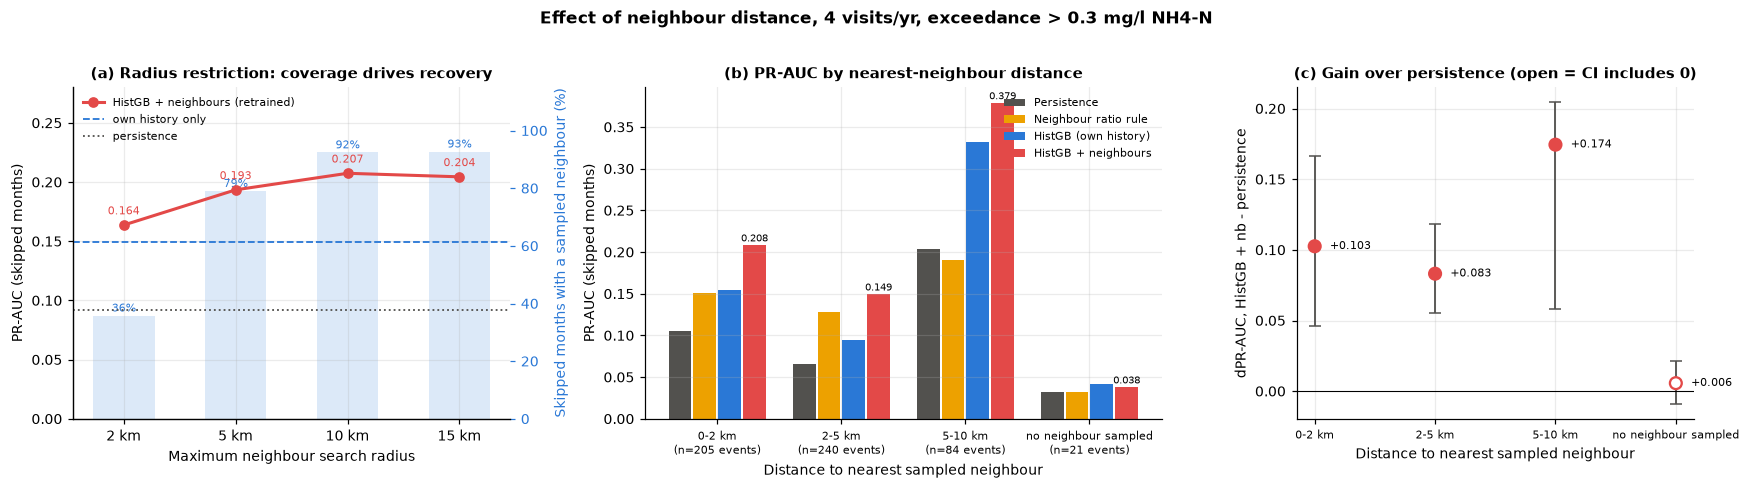

,radius (km),skipped months with a neighbour,PR-AUC HistGB + nb,PR-AUC own history,PR-AUC persistence
1,2,0.358,0.164,0.149,0.092
4,5,0.79,0.193,0.149,0.092
7,10,0.924,0.207,0.149,0.092
10,15,0.927,0.204,0.149,0.092


,distance,events,PR-AUC Persistence,PR-AUC Neighbour_ratio,PR-AUC HistGB_nb,dPR-AUC (nb - persistence),95% CI low,95% CI high
0,0-2 km,205,0.106,0.151,0.208,0.103,0.046,0.166
1,2-5 km,240,0.066,0.128,0.149,0.083,0.055,0.118
2,5-10 km,84,0.204,0.19,0.379,0.174,0.058,0.204
3,no neighbour sampled,21,0.032,0.032,0.038,0.006,-0.009,0.021


In [32]:
# Figure F12b - effect of neighbour distance (radius restriction + nearest-neighbour distance strata)
# Uses RADT (T11) and DIST (T10) from Experiment 3; if the notebook was restarted, they are read from the saved CSV files.
try: RADT, DIST
except NameError:
    RADT = pd.read_csv(os.path.join(OUT, "T11_radius_restriction.csv")); DIST = pd.read_csv(os.path.join(OUT, "T10_distance_strata.csv"))
F_, THR_ = 4, PRIMARY                                                   # scenario shown: 4 visits/yr, > 0.3 mg/l N

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.1, 1.3, 1]})

# (a) radius restriction: coverage (bars) and PR-AUC (line)
r = RADT[RADT.threshold == THR_].sort_values("radius (km)"); x = np.arange(len(r))
a2 = ax[0].twinx(); a2.grid(False)
b = a2.bar(x, r["skipped months with a neighbour"] * 100, 0.55, color="#dce9f8", zorder=0)
a2.bar_label(b, labels=[f"{v:.0%}" for v in r["skipped months with a neighbour"]], fontsize=7, color="#2a78d6", padding=1)
a2.set_ylim(0, 115); a2.set_ylabel("Skipped months with a sampled neighbour (%)", color="#2a78d6"); a2.tick_params(axis="y", colors="#2a78d6")
ax[0].set_zorder(a2.get_zorder() + 1); ax[0].patch.set_visible(False)
ax[0].plot(x, r["PR-AUC HistGB + nb"], "o-", color=COL["HistGB_nb"], lw=2, label="HistGB + neighbours (retrained)")
for xi, v in zip(x, r["PR-AUC HistGB + nb"]): ax[0].annotate(f"{v:.3f}", (xi, v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7, color=COL["HistGB_nb"])
ax[0].axhline(r["PR-AUC own history"].iloc[0], color=COL["HistGB_own"], ls="--", lw=1.2, label="own history only")
ax[0].axhline(r["PR-AUC persistence"].iloc[0], color=COL["Persistence"], ls=":", lw=1.2, label="persistence")
ax[0].set_xticks(x); ax[0].set_xticklabels([f"{v:g} km" for v in r["radius (km)"]]); ax[0].set_xlabel("Maximum neighbour search radius")
ax[0].set_ylabel("PR-AUC (skipped months)"); ax[0].set_ylim(0, r["PR-AUC HistGB + nb"].max() * 1.35)
ax[0].set_title("(a) Radius restriction: coverage drives recovery"); ax[0].legend(fontsize=7, loc="upper left")

# (b) nearest sampled neighbour distance: PR-AUC by strategy
dd = DIST[(DIST["visits/yr"] == F_) & (DIST.threshold == THR_) & (DIST.events >= 10)].reset_index(drop=True); x = np.arange(len(dd)); w = .2   # strata with < 10 events omitted
for i, s_ in enumerate(STRATS):
    bb = ax[1].bar(x + (i - 1.5) * w, dd[f"PR-AUC {s_}"], w * .92, color=COL[s_], label=LAB[s_])
    if s_ == "HistGB_nb": ax[1].bar_label(bb, fmt="%.3f", fontsize=6.5, padding=1)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{c}\n(n={n} events)" for c, n in zip(dd.distance, dd.events)], fontsize=7.5)
ax[1].set_xlabel("Distance to nearest sampled neighbour"); ax[1].set_ylabel("PR-AUC (skipped months)")
ax[1].set_title("(b) PR-AUC by nearest-neighbour distance"); ax[1].legend(fontsize=7, loc="upper right")

# (c) gain over persistence with 95% station-bootstrap CI
e = dd["dPR-AUC (nb - persistence)"]; lo, hi = dd["95% CI low"], dd["95% CI high"]
sig = lo > 0
ax[2].errorbar(x, e, yerr=[e - lo, hi - e], fmt="none", ecolor="#52514e", capsize=4, lw=1.2)
ax[2].scatter(x, e, s=60, zorder=3, color=[COL["HistGB_nb"] if s else "white" for s in sig], edgecolor=COL["HistGB_nb"], lw=1.5)
for xi, v in zip(x, e): ax[2].annotate(f"+{v:.3f}", (xi, v), xytext=(10, 0), textcoords="offset points", va="center", fontsize=7)
ax[2].axhline(0, color="k", lw=.7); ax[2].set_xticks(x); ax[2].set_xticklabels(dd.distance, fontsize=7.5)
ax[2].set_xlabel("Distance to nearest sampled neighbour"); ax[2].set_ylabel("dPR-AUC, HistGB + nb - persistence")
ax[2].set_title("(c) Gain over persistence (open = CI includes 0)")

fig.suptitle(f"Effect of neighbour distance, {F_} visits/yr, exceedance > {THR_} mg/l NH4-N", fontsize=11, weight="bold", y=1.02)
fig.tight_layout(); savefig(fig, "F12b_neighbour_distance"); plt.show()

display(r[["radius (km)", "skipped months with a neighbour", "PR-AUC HistGB + nb", "PR-AUC own history", "PR-AUC persistence"]].round(3))
display(dd[["distance", "events", "PR-AUC Persistence", "PR-AUC Neighbour_ratio", "PR-AUC HistGB_nb", "dPR-AUC (nb - persistence)", "95% CI low", "95% CI high"]].round(3))

#### 12.1 River connectivity (proxy): same river, same basin or other basin
The dataset contains no flow topology (upstream/downstream links). As a proxy, the river name is taken from the site description (text before 'AT', '@', 'U/S', 'D/S') and the basin from `PrimaryBasin`. For each skipped month the nearest *sampled* neighbour is classified as on the **same river**, in the **same basin but on another river**, or in **another basin**. A variant of the neighbour-ratio rule that prefers same-river, then same-basin neighbours (within 15 or 25 km) tests whether connectivity-aware neighbour choice improves recovery.

In [33]:
def river_name(loc): return re.split(r"AT|@|U/S|D/S|UPSTREAM|DOWNSTREAM", loc)[0].strip()
rn = np.array([river_name(l) for l in info.Location]); bs = info.basin.values
IT4, _ = pooled(ITEMS, 4); yb4 = labels(IT4, PRIMARY); s4, t4, t04 = IT4.s.values, IT4.t.values, IT4.t0.values
nb1 = np.full(len(IT4), -1)
for r_ in range(len(IT4)):
    for j, km in NB_ALL[s4[r_]]:
        if not np.isnan(L[j, t4[r_]]) and not np.isnan(L[j, t04[r_]]): nb1[r_] = j; break
has = nb1 >= 0; jj = np.maximum(nb1, 0)
grp = np.where(~has, "no neighbour sampled", np.where(has & (rn[s4] == rn[jj]) & (rn[s4] != ""), "same river", np.where(bs[s4] == bs[jj], "same basin, other river", "other basin")))
rows = []
for g in ["same river", "same basin, other river", "other basin", "no neighbour sampled"]:
    m = grp == g
    if yb4[m].sum() < 5: continue
    rows.append({"nearest sampled neighbour": g, "skipped months (per phase)": int(m.sum() / 3), "share": m.mean(), "events (per phase)": int(yb4[m].sum() / 3),
                 "median km": float(np.nanmedian(IT4.nb1_km[m])) if g != "no neighbour sampled" else np.nan,
                 "r (neighbour vs target change)": float(np.corrcoef(IT4.nb1_change[m].fillna(0), (IT4.y - IT4["last"])[m])[0, 1]) if g != "no neighbour sampled" else np.nan,
                 **{f"PR-AUC {k}": average_precision_score(yb4[m], IT4[k][m]) for k in STRATS}})
CONN = pd.DataFrame(rows); save_table(CONN, "T12b_river_connectivity"); display(CONN.round(3))
dK, nK = cKDTree(xy).query(xy, k=min(16, S))
def ratio_priority(prio, radius):
    pred = IT4["last"].values.copy()
    for r_ in range(len(IT4)):
        s, t, t0 = s4[r_], t4[r_], t04[r_]; c_ = []
        for j, dd in zip(nK[s, 1:], dK[s, 1:] / 1000):
            if dd > radius or np.isnan(L[j, t]) or np.isnan(L[j, t0]): continue
            lvl = 0 if (rn[j] == rn[s] and rn[s] != "") else (1 if bs[j] == bs[s] else 2)
            c_.append((lvl if prio else 0, dd, j))
        if c_: _, _, j = min(c_); pred[r_] += L[j, t] - L[j, t0]
    return pred
for name, prio, rad in (("rr_nearest15", False, 15), ("rr_river15", True, 15), ("rr_river25", True, 25)): IT4[name] = ratio_priority(prio, rad)
pr_rows = []
for name, lab in (("rr_nearest15", "nearest neighbour within 15 km (primary rule)"), ("rr_river15", "same river > same basin > nearest, 15 km"), ("rr_river25", "same river > same basin > nearest, 25 km")):
    e, lo, hi = boot_ap(IT4, name, "rr_nearest15", PRIMARY, "station") if name != "rr_nearest15" else (0.0, np.nan, np.nan)
    pr_rows.append({"neighbour choice": lab, "PR-AUC": average_precision_score(yb4, IT4[name]), "d vs primary rule": e, "95% CI low": lo, "95% CI high": hi})
CONN2 = pd.DataFrame(pr_rows); save_table(CONN2, "T12c_connectivity_aware_ratio_rule"); display(CONN2.round(4))

,nearest sampled neighbour,skipped months (per phase),share,events (per phase),median km,r (neighbour vs target change),PR-AUC Persistence,PR-AUC Neighbour_ratio,PR-AUC HistGB_own,PR-AUC HistGB_nb
0,same river,1423,0.067,55,4.277,0.516,0.112,0.301,0.173,0.331
1,"same basin, other river",14567,0.688,422,2.264,0.322,0.105,0.146,0.165,0.217
2,other basin,3623,0.171,53,4.091,0.23,0.033,0.046,0.052,0.069
3,no neighbour sampled,1544,0.073,21,NaN,NaN,0.032,0.032,0.042,0.038


,neighbour choice,PR-AUC,d vs primary rule,95% CI low,95% CI high
0,nearest neighbour within 15 km (primary rule),0.1387,0,NaN,NaN
1,"same river > same basin > nearest, 15 km",0.1446,0.0059,-0.006,0.0174
2,"same river > same basin > nearest, 25 km",0.1423,0.0036,-0.0091,0.0158


#### 12.2 Flow connectivity from a river network (HydroRIVERS)
River names are only a proxy. The HydroRIVERS v1.0 network (Lehner and Grill, 2013; reaches drawn from upstream to downstream, `NEXT_DOWN` = downstream reach) is used to snap each station to its nearest reach and to trace downstream paths. For the three nearest neighbours within 15 km the neighbour is classified as **upstream** (it drains into the target), **downstream**, on **another branch of the same river system** (same outlet) or in **another river system**; stations more than 300 m from a reach are flagged as unreliable (mostly small streams that HydroRIVERS does not resolve). The analysis uses the exported monthly record of the 4-visit design and the neighbour-ratio rule, so it is independent of the trained models.

stations snapped within 300 m of a HydroRIVERS reach: 246/281 (median snap distance 106 m)


,nearest sampled neighbour,share of skipped months,events (per phase),median km,r (neighbour vs target change),PR-AUC persistence,PR-AUC neighbour-ratio rule
0,upstream,0.123,65,2.673,0.388,0.052,0.155
1,downstream,0.183,98,2.847,0.4,0.07,0.152
2,"same system, other branch",0.389,177,2.919,0.299,0.061,0.102
3,other river system,0.067,4,2.97,0.288,0.014,0.03
4,unreliable snap,0.217,200,2.141,0.277,0.187,0.189
5,no neighbour sampled,0.02,5,NaN,NaN,0.02,0.02


neighbour-ratio rule, PR-AUC: nearest neighbour 0.1388 | flow-connected neighbour first (upstream > downstream, <= 25 km along the river) 0.1448 | difference +0.0060 (95% CI -0.0031 to +0.0146)
share of the 552 exceedances (per phase) at stations without a reliable reach: 36% (small streams are missing from HydroRIVERS)


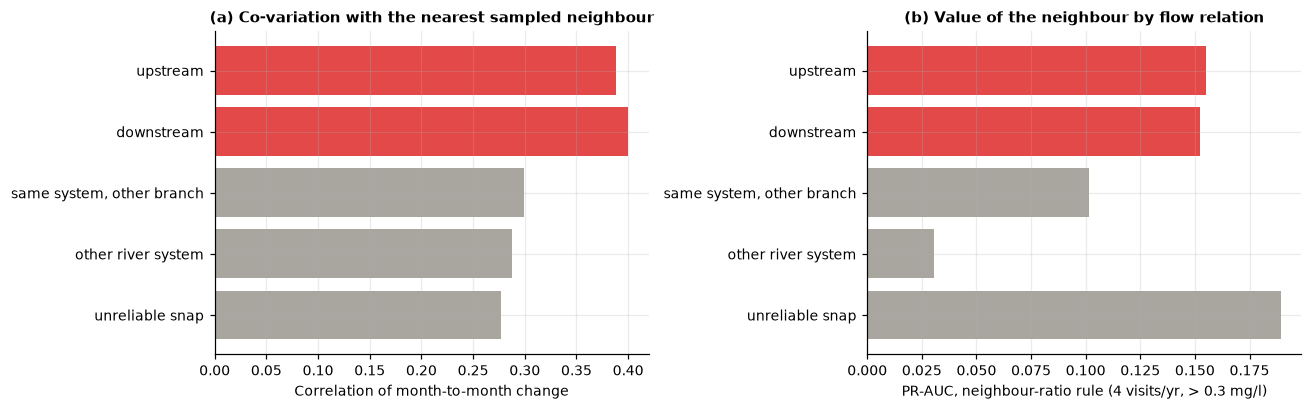

In [34]:
# ==== CELL A ==== 12.2 Flow connectivity from HydroRIVERS (standalone: reads only exported files)
# Requires: pip install pyproj shapely ; file data/hydrorivers_ni.json (HydroRIVERS v1.0 Europe, clipped to -8.3,53.9,-5.3,55.4)
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.metrics import average_precision_score as AP
from pyproj import Transformer
from shapely.geometry import LineString, Point
from shapely.strtree import STRtree
ROOT = os.getcwd() if os.path.exists("data/raw") else os.path.dirname(os.getcwd())
OUT = os.path.join(ROOT, "results", "complete_study"); DAT = os.path.join(OUT, "data"); FIG = os.path.join(OUT, "figures")
SNAP_MAX_M = 300                                     # stations further than this from a HydroRIVERS reach are 'unreliable'
# --- monthly reference record of the cohort (exported in Section 5.2)
_mref = pd.read_csv(os.path.join(DAT, "monthly_reference_record.csv.gz")); _meta = pd.read_csv(os.path.join(DAT, "station_metadata.csv"), index_col=0)
codes = sorted(_mref.StationCode.unique()); si = {c: i for i, c in enumerate(codes)}; NS = len(codes)
months = pd.period_range("1990-01", "2024-12", freq="M"); mi = {str(p): i for i, p in enumerate(months)}; TT = len(months)
VV = np.full((NS, TT), np.nan); CC = np.zeros((NS, TT), bool); EVM = np.zeros((NS, TT), bool)
for r in _mref.itertuples(): i, t = si[r.StationCode], mi[r.month]; VV[i, t] = r.NH4_N; CC[i, t] = r.censored; EVM[i, t] = r.evaluation_month
LL = np.log(VV); MON = np.array([p.month for p in months]); YR = np.array([p.year for p in months])
XY = _meta.loc[codes, ["E", "N"]].values.astype(float)
# --- river network: reaches drawn from upstream to downstream; NEXT_DOWN = downstream reach id
import glob
_cands = [p for p in [os.path.join(ROOT, "data", "hydrorivers_ni.json")] + glob.glob(os.path.join(ROOT, "**", "*ydro*iver*.json"), recursive=True) if os.path.exists(p)]
assert _cands, "HydroRIVERS file not found: place hydrorivers_ni.json in data/"
hr = json.load(open(_cands[0], encoding="utf-8"))
to_ig = Transformer.from_crs("EPSG:4326", "EPSG:29902", always_xy=True)
rid, lines, PR = [], [], {}
for f in hr["features"]:
    c = np.array(f["geometry"]["coordinates"]); x, y = to_ig.transform(c[:, 0], c[:, 1])
    rid.append(f["properties"]["HYRIV_ID"]); lines.append(LineString(np.c_[x, y])); PR[f["properties"]["HYRIV_ID"]] = f["properties"]
tree = STRtree(lines); snap = []
for i in range(NS):
    p = Point(XY[i]); k = tree.nearest(p); snap.append((rid[k], lines[k].distance(p), lines[k].project(p) / 1000, lines[k].length / 1000))
SNAP = pd.DataFrame(snap, columns=["reach", "snap_m", "pos_km", "reach_km"], index=codes)
def dpath(r0):
    out, seen = [r0], {r0}
    while (nd := PR.get(out[-1], {}).get("NEXT_DOWN", 0)) and nd in PR and nd not in seen: out.append(nd); seen.add(nd)
    return out
PATH = [dpath(r) for r in SNAP.reach]
def flow_rel(a, b):
    # relation of neighbour b to target a and flow distance (km)
    if SNAP.snap_m.iloc[a] > SNAP_MAX_M or SNAP.snap_m.iloc[b] > SNAP_MAX_M: return "unreliable snap", np.nan
    ra, rb = SNAP.reach.iloc[a], SNAP.reach.iloc[b]
    if ra == rb: dk = SNAP.pos_km.iloc[a] - SNAP.pos_km.iloc[b]; return ("upstream" if dk > 0 else "downstream"), abs(dk)
    pa, pb = PATH[a], PATH[b]
    if ra in pb:
        k = pb.index(ra); return "upstream", SNAP.reach_km.iloc[b] - SNAP.pos_km.iloc[b] + sum(PR[x]["LENGTH_KM"] for x in pb[1:k]) + SNAP.pos_km.iloc[a]
    if rb in pa:
        k = pa.index(rb); return "downstream", SNAP.reach_km.iloc[a] - SNAP.pos_km.iloc[a] + sum(PR[x]["LENGTH_KM"] for x in pa[1:k]) + SNAP.pos_km.iloc[b]
    return ("same system, other branch" if pa[-1] == pb[-1] else "other river system"), np.nan
print(f"stations snapped within {SNAP_MAX_M} m of a HydroRIVERS reach: {(SNAP.snap_m <= SNAP_MAX_M).sum()}/{NS} (median snap distance {SNAP.snap_m.median():.0f} m)")
# --- skipped months of the 4 visits/yr one-at-a-time design, nearest sampled neighbour (<= 3 within 15 km) classified by flow relation
dK, nK = cKDTree(XY).query(XY, k=min(12, NS)); REL = {}; rows = []
for keep in ([1, 4, 7, 10], [2, 5, 8, 11], [3, 6, 9, 12]):
    av = ~np.isnan(VV) & (np.isin(MON, keep)[None, :] | (YR < 2008)[None, :])
    for i in range(NS):
        idx = np.flatnonzero(av[i])
        for t in np.flatnonzero(EVM[i] & ~av[i]):
            k = np.searchsorted(idx, t) - 1
            if k < 0: continue
            t0 = idx[k]; cand = []
            for j, dd in zip(nK[i, 1:], dK[i, 1:] / 1000):
                if np.isnan(LL[j, t]) or np.isnan(LL[j, t0]): continue
                if (i, j) not in REL: REL[(i, j)] = flow_rel(i, j)
                cand.append((dd, j) + REL[(i, j)])
            near = [c for c in cand if c[0] <= 15][:3]; con = [c for c in cand if c[2] in ("upstream", "downstream") and c[3] <= 25]
            row = {"s": i, "y": bool((VV[i, t] > 0.3) & ~CC[i, t]), "last": LL[i, t0], "target_change": LL[i, t] - LL[i, t0]}
            if near: dd, j, rel_, fd = near[0]; row.update(cls=rel_, km=dd, nb_change=LL[j, t] - LL[j, t0], rr_near=LL[i, t0] + LL[j, t] - LL[j, t0])
            else: row.update(cls="no neighbour sampled", km=np.nan, nb_change=np.nan, rr_near=LL[i, t0])
            c_ = sorted(con, key=lambda c: (c[2] != "upstream", c[3]))[0] if con else None
            row["rr_flow"] = LL[i, t0] + LL[c_[1], t] - LL[c_[1], t0] if c_ else row["rr_near"]
            rows.append(row)
FL = pd.DataFrame(rows); nph_ = 3; rows = []
for g in ["upstream", "downstream", "same system, other branch", "other river system", "unreliable snap", "no neighbour sampled"]:
    x = FL[FL.cls == g]
    if len(x) == 0: continue
    rows.append({"nearest sampled neighbour": g, "share of skipped months": len(x) / len(FL), "events (per phase)": int(x.y.sum() / nph_), "median km": x.km.median(),
                 "r (neighbour vs target change)": np.corrcoef(x.nb_change.fillna(0), x.target_change)[0, 1] if g != "no neighbour sampled" else np.nan,
                 "PR-AUC persistence": AP(x.y, x["last"]), "PR-AUC neighbour-ratio rule": AP(x.y, x.rr_near)})
FLOW = pd.DataFrame(rows); FLOW.to_csv(os.path.join(OUT, "T12d_flow_connectivity.csv"), index=False); display(FLOW.round(3))
rng = np.random.RandomState(42); us = np.unique(FL.s); mem = {s: np.flatnonzero(FL.s.values == s) for s in us}; bs = []
for _ in range(1000):
    ix = np.concatenate([mem[s] for s in rng.choice(us, len(us))]); yy = FL.y.values[ix]
    if yy.sum(): bs.append(AP(yy, FL.rr_flow.values[ix]) - AP(yy, FL.rr_near.values[ix]))
print(f"neighbour-ratio rule, PR-AUC: nearest neighbour {AP(FL.y, FL.rr_near):.4f} | flow-connected neighbour first (upstream > downstream, <= 25 km along the river) "
      f"{AP(FL.y, FL.rr_flow):.4f} | difference {AP(FL.y, FL.rr_flow) - AP(FL.y, FL.rr_near):+.4f} (95% CI {np.percentile(bs, 2.5):+.4f} to {np.percentile(bs, 97.5):+.4f})")
print(f"share of the {int(FL.y.sum() / nph_)} exceedances (per phase) at stations without a reliable reach: {FL[FL.cls == 'unreliable snap'].y.sum() / FL.y.sum():.0%} (small streams are missing from HydroRIVERS)")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8)); F_ = FLOW[FLOW["nearest sampled neighbour"] != "no neighbour sampled"]
cols_ = ["#e34948" if g in ("upstream", "downstream") else "#a8a69e" for g in F_["nearest sampled neighbour"]]
ax[0].barh(F_["nearest sampled neighbour"], F_["r (neighbour vs target change)"], color=cols_); ax[0].invert_yaxis(); ax[0].set_xlabel("Correlation of month-to-month change")
ax[0].set_title("(a) Co-variation with the nearest sampled neighbour")
ax[1].barh(F_["nearest sampled neighbour"], F_["PR-AUC neighbour-ratio rule"], color=cols_); ax[1].invert_yaxis(); ax[1].set_xlabel("PR-AUC, neighbour-ratio rule (4 visits/yr, > 0.3 mg/l)")
ax[1].set_title("(b) Value of the neighbour by flow relation"); fig.tight_layout()
fig.savefig(os.path.join(FIG, "F12d_flow_connectivity.png"), dpi=300, bbox_inches="tight"); plt.show()

> **Interpretation — Experiment 3 (distance, river connectivity and threshold).**
> * **Radius restriction (retrained models):** AP rises with the neighbour search radius — 2 km (36% of skipped months with a neighbour): 0.164, close to the own-history model (0.149); 5 km (79%): 0.193; 10 km (92%): 0.207; 15 km (93%): 0.204. The benefit follows neighbour coverage and **saturates at about 10 km**.
> * **Distance strata:** whenever a neighbour was sampled, the gain over persistence is clearly positive — +0.103 (0–2 km, CI 0.046–0.166), +0.083 (2–5 km, 0.055–0.118) and +0.174 (5–10 km, 0.058–0.204) at 4/yr — and it vanishes without a sampled neighbour (+0.006, −0.009 to 0.021). There is no consistent optimum distance; the large 5–10 km value rests on 84 events at stations where persistence itself performs well.
> * **River connectivity (proxy):** when the nearest sampled neighbour is on the same river, its change correlates with the target's at r = 0.52 and the neighbour-ratio rule reaches AP 0.301 (HistGB 0.331); same basin/other river: r = 0.32, 0.146; other basin: r = 0.23, 0.046. Only 6.7% of skipped months have a same-river neighbour, and preferring same-river and same-basin neighbours does not improve the ratio rule overall (+0.006, CI −0.006 to 0.017). Connectivity explains *where* individual neighbours help, but it does not improve the network-wide result.
> * **Flow topology (HydroRIVERS, Section 12.2):** 246 of 281 stations lie within 300 m of a mapped reach. Flow-connected neighbours are individually more informative — upstream: r = 0.39, ratio-rule AP 0.155; downstream: r = 0.40, 0.152 — compared with another branch of the same river system (r = 0.30, 0.102) and other systems (0.29, 0.030). Preferring flow-connected neighbours changes the overall AP only from 0.139 to 0.145 (+0.006, CI −0.003 to 0.015): ; 36% of skipped exceedances involve a target or nearest sampled neighbour more than 300 m from a mapped reach, which may reflect unmapped small streams or station-matching errors.
> * **Threshold:** the advantage over persistence shrinks as the threshold rises — +0.188 (0.2), +0.112 (0.3), +0.076 (0.4), +0.029 (0.6 mg N L⁻¹) at 4/yr, all CIs above zero. At 0.6 mg N L⁻¹ the simple ratio rule is as good as HistGB (+0.031 vs +0.029 over persistence).

<a id="13"></a>
## 13. Experiment 4 — Network-wide reduction: synchronised versus staggered schedules

Experiments 1–3 assume that only the target station is reduced while its neighbours keep monthly sampling. A monitoring agency that cuts its budget would, however, reduce **all** stations. Every station is then sampled 6 or 4 times per year (identical total effort), and the question becomes **how to schedule** the visits:

* **synchronised** — all stations are visited in the same months (e.g. Jan/Apr/Jul/Oct);
* **staggered (graph colouring)** — neighbouring stations (≤ 15 km, three nearest) are assigned different phases by greedy graph colouring, so a skipped month at one station is usually sampled at its neighbours;
* **random phases** — each station draws a phase at random (two draws; every draw is used with all phase rotations so that each station visits every calendar month equally often);
* **one-at-a-time** — reference: neighbours keep monthly sampling (upper bound).

Neighbour features use only samples that the neighbour actually takes under its own schedule. Training follows the **same temporal and spatial rules as Experiments 1–3**. Cut-offs: a model trained on the schedule applied to the historical record before 2005 scores the simulated 2005–2007 skipped months, and the FA-budget cut-off is frozen. Evaluation: **one model per 3-year block B and spatial cluster g** (seen design), trained on the schedule simulated over 1995–2007 (the archive was monthly, so hidden values are known there) **plus the visit pairs actually taken under the design in 2008…B−1**, excluding the post-2007 pairs of cluster g. Hidden months of the evaluation period never enter training. The **one-at-a-time** reference is Experiment 1 itself (same items, predictions and cut-offs). The previous procedure (a single model trained on 1995–2007) is reported alongside for comparison (T15c). Hyper-parameters are the primary choice (Section 8).

post-2007 observed visit pairs added to training (median over clusters, last block): {'network: random phases 4/yr v0': 8318, 'network: random phases 4/yr v1': 8385, 'network: random phases 4/yr v2': 8384, 'network: random phases 4/yr v3': 8459, 'network: random phases 4/yr v4': 8400, 'network: random phases 4/yr v5': 8222, 'network: random phases 6/yr v0': 12288, 'network: random phases 6/yr v1': 12492, 'network: random phases 6/yr v2': 12372, 'network: random phases 6/yr v3': 12418, 'network: staggered (graph colouring) 4/yr v0': 8430, 'network: staggered (graph colouring) 4/yr v1': 8335, 'network: staggered (graph colouring) 4/yr v2': 8347, 'network: staggered (graph colouring) 6/yr v0': 12370, 'network: staggered (graph colouring) 6/yr v1': 12409, 'network: synchronised 4/yr v0': 8689, 'network: synchronised 4/yr v1': 8911, 'network: synchronised 4/yr v2': 7472, 'network: synchronised 6/yr v0': 12892, 'network: synchronised 6/yr v1': 11844}


,visits/yr,scheme,threshold,HistGB_nb PR-AUC,HistGB_nb (trained once) PR-AUC,HistGB_nb recall,HistGB_nb (trained once) recall
1,6,one-at-a-time (neighbours monthly),0.3,0.21,0.21,0.613,0.613
4,6,network: synchronised,0.3,0.174,0.174,0.587,0.587
7,6,network: staggered (graph colouring),0.3,0.214,0.215,0.597,0.606
10,6,network: random phases,0.3,0.197,0.199,0.597,0.598
13,4,one-at-a-time (neighbours monthly),0.3,0.204,0.204,0.457,0.457
16,4,network: synchronised,0.3,0.161,0.159,0.42,0.416
19,4,network: staggered (graph colouring),0.3,0.184,0.184,0.431,0.432
22,4,network: random phases,0.3,0.185,0.183,0.43,0.427


network-schedule experiment: 395s; neighbour edges: 524


,visits/yr,scheme,neighbour-phase conflicts,skipped months with a neighbour sampled in the same month,Observation-only recall,Persistence recall,Neighbour_ratio recall,HistGB_nb recall,HistGB_nb false alarms/station-yr,Persistence PR-AUC,Neighbour_ratio PR-AUC,HistGB_nb PR-AUC
1,6,one-at-a-time (neighbours monthly),NaN,0.928,0.5,0.557,0.566,0.613,0.062,0.103,0.15,0.21
4,6,network: synchronised,524,0,0.5,0.557,0.557,0.587,0.05,0.103,0.103,0.174
7,6,network: staggered (graph colouring),162,0.904,0.5,0.557,0.554,0.597,0.052,0.103,0.129,0.214
10,6,network: random phases,259,0.767,0.5,0.557,0.553,0.597,0.051,0.103,0.124,0.197
13,4,one-at-a-time (neighbours monthly),NaN,0.927,0.333,0.386,0.392,0.457,0.06,0.092,0.138,0.204
16,4,network: synchronised,524,0,0.333,0.386,0.386,0.42,0.047,0.092,0.092,0.161
19,4,network: staggered (graph colouring),66,0.784,0.333,0.386,0.385,0.431,0.052,0.092,0.113,0.184
22,4,network: random phases,185,0.574,0.333,0.386,0.391,0.43,0.046,0.092,0.11,0.185


,visits/yr,threshold,strategy,comparison,cluster,d recall,95% CI low,95% CI high,d PR-AUC
0,6,0.2,Neighbour_ratio,network: staggered (graph colouring) minus n...,station,0.0006,-0.017,0.0172,NaN
1,6,0.2,HistGB_nb,network: staggered (graph colouring) minus n...,station,0.0143,0.0022,0.0269,NaN
2,6,0.2,Neighbour_ratio,one-at-a-time (neighbours monthly) minus net...,station,0.0015,-0.0049,0.0085,NaN
3,6,0.2,HistGB_nb,one-at-a-time (neighbours monthly) minus net...,station,0.0076,0.0003,0.0163,NaN
4,6,0.2,Neighbour_ratio,network: staggered (graph colouring) minus n...,year,0.0006,-0.0091,0.0079,NaN
5,6,0.2,HistGB_nb,network: staggered (graph colouring) minus n...,year,0.0143,0.003,0.0228,NaN
6,6,0.2,Neighbour_ratio,one-at-a-time (neighbours monthly) minus net...,year,0.0015,-0.0057,0.0063,NaN
7,6,0.2,HistGB_nb,one-at-a-time (neighbours monthly) minus net...,year,0.0076,-0.0019,0.0163,NaN
8,6,0.3,Neighbour_ratio,network: staggered (graph colouring) minus n...,station,-0.0036,-0.03,0.0211,NaN
9,6,0.3,HistGB_nb,network: staggered (graph colouring) minus n...,station,0.0103,-0.003,0.0247,NaN


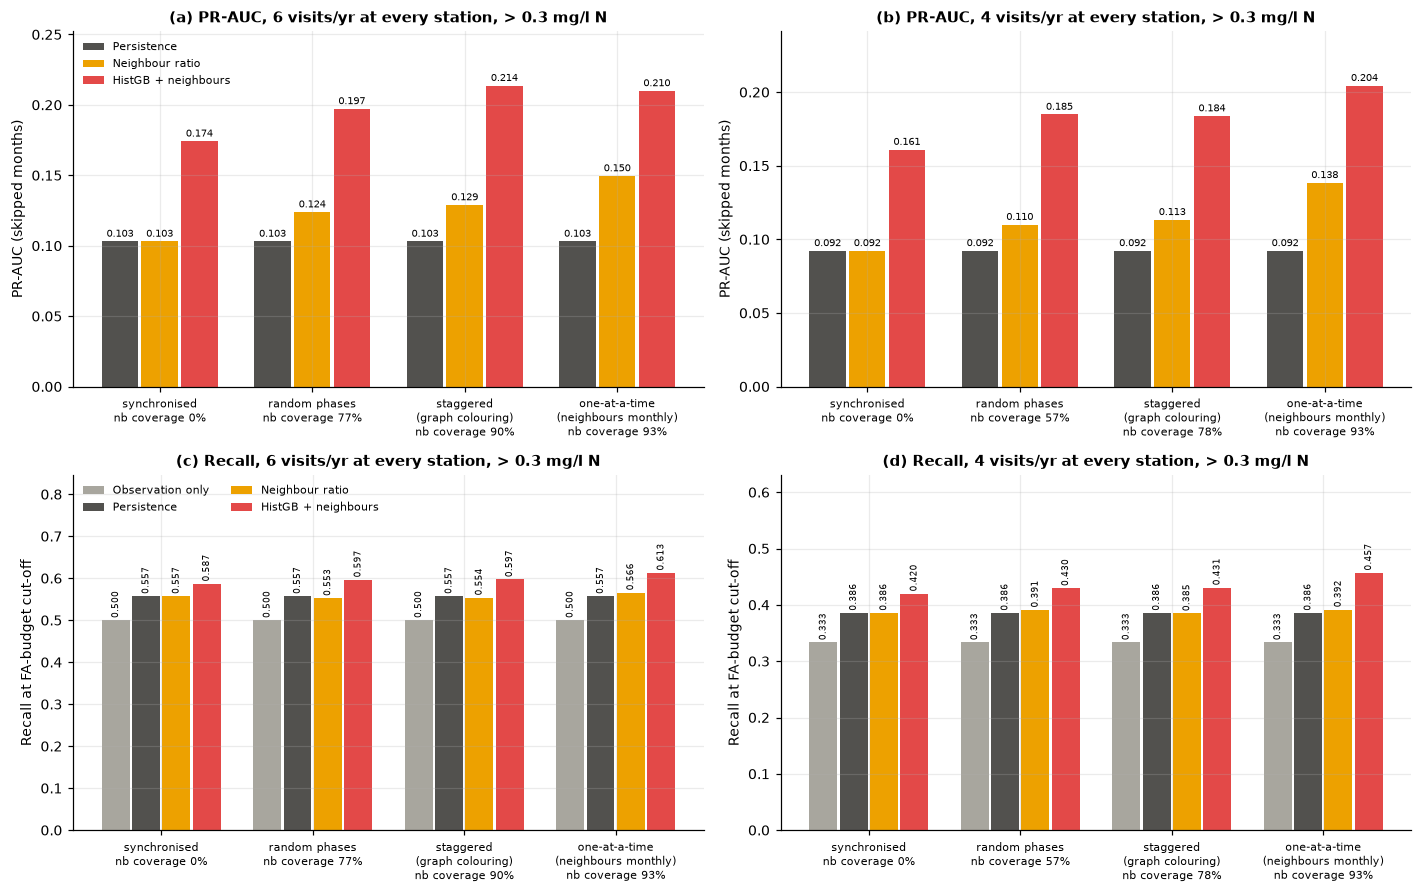

In [35]:
# Experiment 4 - network-wide reduction: synchronised vs staggered sampling schedules (block-retrained, seen design).
# Relies on notebook globals: S, V, L, CEN, mon, yr, T, NB_ALL, EVAL, DEVM, okSY, CFG, HGB_GRID, CHOSEN, OWN, NBC,
# cumstats, exceed, n_sy_eval, n_sy_dev, STRATS, COL, LAB, SEED, savefig, save_table
import itertools
TRAIN_FROM = 1995
NET_FREQS = [f for f in CFG["sched"] if f in ((4,) if FAST else (6, 4))]          # network-wide experiment: 6 and 4 visits/yr
def neighbour_graph():
    adj = [set() for _ in range(S)]
    for i in range(S):
        for j, km in NB_ALL[i]: adj[i].add(j); adj[j].add(i)
    return adj
ADJ = neighbour_graph()
def colour(n_phases):
    # Greedy graph colouring: neighbours receive different sampling phases where possible (ties -> least-used phase)
    order = sorted(range(S), key=lambda i: -len(ADJ[i])); ph = -np.ones(S, int); load = np.zeros(n_phases)
    for i in order:
        conf = [sum(ph[j] == p for j in ADJ[i]) for p in range(n_phases)]
        p = min(range(n_phases), key=lambda q: (conf[q], load[q])); ph[i] = p; load[p] += 1
    return ph
def conflicts(ph): return sum(ph[i] == ph[j] for i in range(S) for j in ADJ[i]) // 2
def schemes(f):
    k = len(CFG["sched"][f]); stag = colour(k)
    out = {"one-at-a-time (neighbours monthly)": [("single", np.full(S, p)) for p in range(k)],
           "network: synchronised": [("network", np.full(S, p)) for p in range(k)],
           "network: staggered (graph colouring)": [("network", (stag + r) % k) for r in range(k)],
           # random phases, balanced: each random assignment is used with all k rotations so every station visits every phase equally often
           "network: random phases": [("network", (np.random.RandomState(SEED + r).randint(0, k, S) + q) % k) for r in range(2) for q in range(k)]}
    return out
def availability_matrix(f, phases, start):
    sched = np.zeros((S, T), bool)
    for i in range(S): sched[i] = np.isin(mon, CFG["sched"][f][phases[i]])
    return ~np.isnan(V) & (sched | (yr < start)[None, :])
def last_index(A):
    li = np.full(A.shape, -1)
    for i in range(A.shape[0]):
        idx = np.flatnonzero(A[i]); pos = np.searchsorted(idx, np.arange(A.shape[1]), side="right") - 1
        li[i] = np.where(pos >= 0, idx[np.maximum(pos, 0)], -1)
    return li
def _features(AV, NBAV, s, t, t0):
    # features for target months t with origin t0 (last available own visit); own history from AV, neighbours from NBAV
    own = cumstats(np.where(AV, L, np.nan)); nbs = cumstats(np.where(NBAV, L, np.nan)); nli = last_index(NBAV)
    cs, cn, csm, cnm = own; dcs, dcn, dcsm, dcnm = nbs
    last = L[s, t0]; base = cs[s, t0] / cn[s, t0]; t12 = np.maximum(t0 - 12, 0); n12 = cn[s, t0] - cn[s, t12]
    def clim_(ti):
        mm = mon[ti] - 1; return np.where(cnm[mm, s, t0] >= 2, csm[mm, s, t0] / np.maximum(cnm[mm, s, t0], 1), base)
    ct, co = clim_(t), clim_(t0)
    F = pd.DataFrame({"last": last, "last_censored": CEN[s, t0].astype(float), "h": (t - t0).astype(float), "baseline": base,
                      "mean12": np.where(n12 > 0, (cs[s, t0] - cs[s, t12]) / np.maximum(n12, 1), last), "anomaly": last - base,
                      "clim_target": ct, "clim_origin": co, "seasonal_change": ct - co, "seas_anom": last - co,
                      "tsin": np.sin(2 * np.pi * mon[t] / 12), "tcos": np.cos(2 * np.pi * mon[t] / 12)})
    nbv = {k: np.full(len(s), np.nan) for k in NBC}
    for r in range(len(s)):
        ch, an, va = [], [], []
        for j, km in NB_ALL[s[r]]:
            if not NBAV[j, t[r]]: continue                                   # neighbour must have been sampled in month t
            ref = nli[j, t0[r]]
            mm = mon[t[r]] - 1; den = dcnm[mm, j, t0[r]]
            cj = dcsm[mm, j, t0[r]] / den if den >= 2 else dcs[j, t0[r]] / max(dcn[j, t0[r]], 1)
            c_ = L[j, t[r]] - L[j, ref] if (ref >= 0 and t0[r] - ref <= 3) else np.nan     # change vs neighbour's own last visit <= t0
            ch.append(c_); an.append(L[j, t[r]] - cj); va.append(L[j, t[r]])
            if len(an) == 1: nbv["nb1_change"][r], nbv["nb1_anom"][r], nbv["nb1_value"][r], nbv["nb1_km"][r] = c_, an[0], va[0], km
        if an:
            nbv["nb_mean_change"][r] = np.nanmean(ch) if np.isfinite(ch).any() else np.nan
            nbv["nb_mean_anom"][r], nbv["nb_max_value"][r] = np.mean(an), np.max(va)
        nbv["nb_n"][r] = len(an)
    for k_, v in nbv.items(): F[k_] = v
    F["s"], F["t"], F["year"], F["y"], F["cens_target"], F["group"] = s, t, yr[t], L[s, t], CEN[s, t], groups[s]
    F["Persistence"] = F["last"]; F["Neighbour_ratio"] = F["last"] + np.nan_to_num(F.nb1_change)
    return F

def items_for(f, phases, mode, start, mask, AV=None):
    # skipped (hidden) months inside `mask`: target value is used only for scoring (or, before 2008, as a training label)
    AV = availability_matrix(f, phases, start) if AV is None else AV
    NBAV = AV if mode == "network" else ~np.isnan(V)                       # what neighbours actually sampled
    s_, t_, t0_, ret = [], [], [], []
    for i in range(S):
        idx = np.flatnonzero(AV[i])
        for t in np.flatnonzero(mask[i]):
            if AV[i, t]: ret.append((i, t)); continue
            k = np.searchsorted(idx, t) - 1
            if k < 0: continue
            s_.append(i); t_.append(t); t0_.append(idx[k])
    s, t, t0 = map(np.array, (s_, t_, t0_)); assert np.all(t0 < t) and not AV[s, t].any()
    return _features(AV, NBAV, s, t, t0), pd.DataFrame(ret, columns=["s", "t"])

def observed_pairs(AV, y0, y1):
    # pairs of consecutive visits that were ACTUALLY taken under the design (target t and origin t0 both sampled, t - t0 <= max_h),
    # target year in [y0, y1]; network mode: neighbours = what neighbours sampled under the same design. No hidden month is used.
    s_, t_, t0_ = [], [], []
    for i in range(S):
        idx = np.flatnonzero(AV[i])
        for k in range(1, len(idx)):
            t, t0 = idx[k], idx[k - 1]
            if y0 <= yr[t] <= y1 and t - t0 <= CFG["max_h"]: s_.append(i); t_.append(t); t0_.append(t0)
    if not s_: return None
    s, t, t0 = map(np.array, (s_, t_, t0_)); assert AV[s, t].all() and AV[s, t0].all()
    return _features(AV, AV, s, t, t0)

def train_mask(y0, y1): return okSY[:, yr - 1990] & ((yr >= y0) & (yr <= y1))[None, :] & ~np.isnan(V)
GRIDC = np.round(np.exp(np.linspace(np.log(0.05), np.log(3.0), 200)), 4)
def fa_cutoff(y_log, cens, score_log, thr, n_units):
    yb = exceed(np.exp(y_log), cens, thr); sc = np.exp(score_log)
    fa = np.array([((sc > c) & ~yb).sum() / n_units for c in GRIDC]); ok = np.flatnonzero(fa <= CFG["fa_budget"])
    return float(GRIDC[ok[0]]) if len(ok) else float(GRIDC[-1])
cfg_nb = HGB_GRID[CHOSEN["HistGB_nb"]]; cols_nb = OWN + NBC
n_sy_train_dev = int(okSY[:, CFG["dev"][0] - 1990:CFG["dev"][1] - 1989].sum())

def fit_hgb(X):
    use = [c for c in cols_nb if X[c].notna().any()]       # neighbour columns can be all-missing (e.g. synchronised schedules)
    return HistGradientBoostingRegressor(random_state=SEED, **cfg_nb).fit(X[use].values, (X.y - X["last"]).values), use
def pred_hgb(mu, X): m, use = mu; return m.predict(X[use].values) + X["last"].values
RETRAIN_LOG = []
def train_and_predict(TR, EV, POST, label):
    # Same temporal/spatial rules as Experiments 1-3 (seen design):
    #   development model: simulated skipped months < 2005 -> cut-offs on 2005-2007 (unchanged);
    #   evaluation: one model per 3-year block B and spatial cluster g, trained on the schedule simulated over 1995-2007 PLUS the visit pairs
    #   actually taken under the design in 2008..B-1, excluding cluster g's post-2007 pairs. Hidden months never enter training.
    trA, dev = TR[TR.year < CFG["dev"][0]], TR[TR.year.between(*CFG["dev"])]
    assert len(trA) > 100 and len(dev) > 100, "too few simulated training items"
    dev = dev.assign(HistGB_nb=pred_hgb(fit_hgb(trA), dev))
    m0 = fit_hgb(TR); EV = EV.copy(); EV["HistGB_nb_once"] = pred_hgb(m0, EV)           # previous procedure (trained once), kept for comparison
    pred = np.full(len(EV), np.nan); evb = EV.year.map(block_of).values; evg = EV.group.values
    for B in CFG["blocks"]:
        add_B = POST[POST.year < B] if POST is not None else None
        for g in range(CFG["n_groups"]):
            sel = (evb == B) & (evg == g)
            if not sel.any(): continue
            add = add_B[add_B.group != g] if add_B is not None else None
            if add is None or len(add) == 0: mu = m0
            else:
                tr = pd.concat([TR, add], ignore_index=True); assert tr.t.max() < np.flatnonzero(yr == B)[0]; mu = fit_hgb(tr)
            pred[sel] = pred_hgb(mu, EV[sel])
            RETRAIN_LOG.append({"design": label, "block": B, "cluster": g, "simulated pre-2008 items": len(TR), "post-2007 observed pairs added": 0 if add is None else len(add)})
    assert np.isfinite(pred).all(); EV["HistGB_nb"] = pred
    return EV, dev

def run_scheme(f, vectors, label=""):
    parts = []
    if vectors[0][0] == "single":
        # one-at-a-time reference = Experiment 1 itself (same items, block-retrained seen-design predictions, development items)
        for p in range(len(vectors)):
            EV, RET = ITEMS[(f, p)]; DV, _ = DEV_ITEMS[(f, p)]
            parts.append((EV.assign(HistGB_nb_once=EV.HistGB_nb), RET, DV, p))
        return parts
    for v_i, (mode, ph) in enumerate(vectors):
        TR, _ = items_for(f, ph, mode, TRAIN_FROM, train_mask(TRAIN_FROM, CFG["dev"][1]))       # schedule simulated on 1995-2007
        EV, RET = items_for(f, ph, mode, CFG["eval"][0], EVAL)                                  # evaluation 2008-2024 (hidden months)
        POST = observed_pairs(availability_matrix(f, ph, CFG["eval"][0]), CFG["eval"][0], CFG["eval"][1] - 1)
        EV, dev = train_and_predict(TR, EV, POST, f"{label} {f}/yr v{v_i}")
        parts.append((EV, RET, dev, v_i))
    return parts

def evaluate_scheme(parts, f, thr):
    nv = len(parts); rows = {}
    EVs = pd.concat([p[0].assign(v=p[3]) for p in parts], ignore_index=True); RETs = pd.concat([p[1].assign(v=p[3]) for p in parts], ignore_index=True)
    DEVs = pd.concat([p[2].assign(v=p[3]) for p in parts], ignore_index=True)
    yb = exceed(np.exp(EVs.y.values), EVs.cens_target.values, thr)
    rev = exceed(V[RETs.s.values, RETs.t.values], CEN[RETs.s.values, RETs.t.values], thr); tot = yb.sum() + rev.sum()
    out = {"skipped months with a neighbour sampled in the same month": (EVs.nb_n > 0).mean(),
           "Observation-only recall": rev.sum() / tot}
    for s_ in ("Persistence", "Neighbour_ratio", "HistGB_nb"):
        c = fa_cutoff(DEVs.y.values, DEVs.cens_target.values, DEVs[s_].values, thr, nv * n_sy_train_dev)
        a = np.exp(EVs[s_].values) > c
        out[f"{s_} PR-AUC"] = average_precision_score(yb, EVs[s_]); out[f"{s_} recall"] = ((a & yb).sum() + rev.sum()) / tot
        out[f"{s_} false alarms/station-yr"] = (a & ~yb).sum() / nv / n_sy_eval; out[f"{s_} cut-off"] = c
        EVs[f"alarm_{s_}"] = a
    a = np.exp(EVs["HistGB_nb_once"].values) > out["HistGB_nb cut-off"]                  # previous procedure, same development cut-off
    out["HistGB_nb (trained once) PR-AUC"] = average_precision_score(yb, EVs["HistGB_nb_once"]); out["HistGB_nb (trained once) recall"] = ((a & yb).sum() + rev.sum()) / tot
    return out, EVs, RETs, rev

NYR = CFG["eval"][1] - CFG["eval"][0] + 1
def unit_keys(EVs, RETs, cluster):
    # bootstrap units: whole stations or whole calendar years
    if cluster == "station": return EVs.s.values, RETs.s.values, S
    return EVs.year.values - CFG["eval"][0], yr[RETs.t.values] - CFG["eval"][0], NYR
def station_recall(EVs, RETs, rev, thr, s_, cluster="station"):
    ke, kr, K = unit_keys(EVs, RETs, cluster)
    yb = exceed(np.exp(EVs.y.values), EVs.cens_target.values, thr); a = EVs[f"alarm_{s_}"].values
    tp = np.bincount(ke, (a & yb).astype(float), K) + np.bincount(kr, rev.astype(float), K)
    ev = np.bincount(ke, yb.astype(float), K) + np.bincount(kr, rev.astype(float), K)
    return tp, ev

t_ = time.time(); NET = {}; NET_ROWS = []
for f in NET_FREQS:
    sch = schemes(f)
    for name, vecs in sch.items():
        parts = run_scheme(f, vecs, name); NET[(f, name)] = parts
        for thr in (0.2, 0.3, 0.6):
            o, _, _, _ = evaluate_scheme(parts, f, thr)
            NET_ROWS.append({"visits/yr": f, "scheme": name, "threshold": thr,
                             "neighbour-phase conflicts": int(np.mean([conflicts(ph) for _, ph in vecs])) if name.startswith("network") else np.nan, **o})
NETT = pd.DataFrame(NET_ROWS); save_table(NETT, "T15_network_schedules")
RLOG = pd.DataFrame(RETRAIN_LOG)
print("post-2007 observed visit pairs added to training (median over clusters, last block):",
      RLOG[RLOG.block == CFG["blocks"][-1]].groupby("design")["post-2007 observed pairs added"].median().astype(int).to_dict())
ONCE = NETT[["visits/yr", "scheme", "threshold", "HistGB_nb PR-AUC", "HistGB_nb (trained once) PR-AUC", "HistGB_nb recall", "HistGB_nb (trained once) recall"]]
save_table(ONCE, "T15c_network_retraining_vs_trained_once"); display(ONCE[ONCE.threshold == PRIMARY].round(3))
print(f"network-schedule experiment: {time.time() - t_:.0f}s; neighbour edges: {sum(len(a) for a in ADJ) // 2}")
show_cols = ["visits/yr", "scheme", "neighbour-phase conflicts", "skipped months with a neighbour sampled in the same month", "Observation-only recall",
             "Persistence recall", "Neighbour_ratio recall", "HistGB_nb recall", "HistGB_nb false alarms/station-yr", "Persistence PR-AUC", "Neighbour_ratio PR-AUC", "HistGB_nb PR-AUC"]
display(NETT[NETT.threshold == PRIMARY][show_cols].round(3))

# paired station-cluster bootstrap: staggered minus synchronised (recall of recorded exceedances, HistGB + neighbours and ratio rule)
bb = []
for f in NET_FREQS:
    for thr in (0.2, 0.3):
        res_ = {}
        for name in ("network: staggered (graph colouring)", "network: synchronised", "one-at-a-time (neighbours monthly)"):
            o, EVs, RETs, rev = evaluate_scheme(NET[(f, name)], f, thr)
            res_[name] = {(s_, cl): station_recall(EVs, RETs, rev, thr, s_, cl) for s_ in ("Persistence", "Neighbour_ratio", "HistGB_nb") for cl in ("station", "year")}
        for cl in ("station", "year"):
            K = S if cl == "station" else NYR; dd = np.random.RandomState(SEED).randint(0, K, (CFG["n_boot"], K))
            for a_name, b_name in (("network: staggered (graph colouring)", "network: synchronised"), ("one-at-a-time (neighbours monthly)", "network: staggered (graph colouring)")):
                for s_ in ("Neighbour_ratio", "HistGB_nb"):
                    ta, ea = res_[a_name][(s_, cl)]; tb, eb = res_[b_name][(s_, cl)]
                    boot = ta[dd].sum(1) / ea[dd].sum(1) - tb[dd].sum(1) / eb[dd].sum(1)
                    bb.append({"visits/yr": f, "threshold": thr, "strategy": s_, "comparison": f"{a_name}  minus  {b_name}", "cluster": cl,
                               "d recall": ta.sum() / ea.sum() - tb.sum() / eb.sum(), "95% CI low": np.percentile(boot, 2.5), "95% CI high": np.percentile(boot, 97.5)})
# station-cluster bootstrap of PR-AUC differences on skipped months (HistGB + neighbours)
def boot_ap_schemes(EA, EB, thr, B=None, seed=SEED):
    B = CFG["n_boot"] if B is None else B; r = np.random.RandomState(seed)
    ya, yb_ = exceed(np.exp(EA.y.values), EA.cens_target.values, thr), exceed(np.exp(EB.y.values), EB.cens_target.values, thr)
    ma = [np.flatnonzero(EA.s.values == i) for i in range(S)]; mb = [np.flatnonzero(EB.s.values == i) for i in range(S)]; out = []
    for _ in range(B):
        d_ = r.randint(0, S, S); ia = np.concatenate([ma[i] for i in d_]); ib = np.concatenate([mb[i] for i in d_])
        if ya[ia].sum() == 0 or yb_[ib].sum() == 0: continue
        out.append(average_precision_score(ya[ia], EA.HistGB_nb.values[ia]) - average_precision_score(yb_[ib], EB.HistGB_nb.values[ib]))
    return average_precision_score(ya, EA.HistGB_nb) - average_precision_score(yb_, EB.HistGB_nb), np.percentile(out, 2.5), np.percentile(out, 97.5)
for f in NET_FREQS:
    for thr in (0.2, 0.3):
        E = {n: pd.concat([p[0] for p in NET[(f, n)]], ignore_index=True) for n in ("network: staggered (graph colouring)", "network: synchronised", "network: random phases", "one-at-a-time (neighbours monthly)")}
        for a_name, b_name in (("network: staggered (graph colouring)", "network: synchronised"), ("network: random phases", "network: synchronised"),
                               ("network: staggered (graph colouring)", "network: random phases"), ("one-at-a-time (neighbours monthly)", "network: staggered (graph colouring)")):
            e, lo, hi = boot_ap_schemes(E[a_name], E[b_name], thr)
            bb.append({"visits/yr": f, "threshold": thr, "strategy": "HistGB_nb (PR-AUC)", "comparison": f"{a_name}  minus  {b_name}", "cluster": "station", "d recall": np.nan,
                       "d PR-AUC": e, "95% CI low": lo, "95% CI high": hi})
NETB = pd.DataFrame(bb); save_table(NETB, "T16_network_schedules_bootstrap"); display(NETB.round(4))

fig, ax = plt.subplots(2, len(NET_FREQS), figsize=(6.5 * len(NET_FREQS), 8.2), squeeze=False)
order_ = ["network: synchronised", "network: random phases", "network: staggered (graph colouring)", "one-at-a-time (neighbours monthly)"]
short = {"network: synchronised": "synchronised", "network: random phases": "random phases", "network: staggered (graph colouring)": "staggered\n(graph colouring)", "one-at-a-time (neighbours monthly)": "one-at-a-time\n(neighbours monthly)"}
COVC = "skipped months with a neighbour sampled in the same month"
for j, f in enumerate(NET_FREQS):
    x = NETT[(NETT["visits/yr"] == f) & (NETT.threshold == PRIMARY)].set_index("scheme").loc[order_]; xx = np.arange(len(x))
    labs = [f"{short[s]}\nnb coverage {c:.0%}" for s, c in zip(order_, x[COVC])]
    # (top) threshold-free ranking: PR-AUC
    a_ = ax[0, j]; w = .26
    for i, (c, lab, cc) in enumerate((("Persistence PR-AUC", "Persistence", COL["Persistence"]), ("Neighbour_ratio PR-AUC", "Neighbour ratio", COL["Neighbour_ratio"]),
                                      ("HistGB_nb PR-AUC", "HistGB + neighbours", COL["HistGB_nb"]))):
        b = a_.bar(xx + (i - 1) * w, x[c], w * .92, color=cc, label=lab)
        a_.bar_label(b, fmt="%.3f", fontsize=6.5, padding=1.5)
    a_.set_xticks(xx); a_.set_xticklabels(labs, fontsize=7.5); a_.set_ylim(0, x[["Neighbour_ratio PR-AUC", "HistGB_nb PR-AUC"]].values.max() * 1.18)
    a_.set_ylabel("PR-AUC (skipped months)"); a_.set_title(f"({'ab'[j]}) PR-AUC, {f} visits/yr at every station, > {PRIMARY} mg/l N")
    # (bottom) operational recall at the pre-selected FA-budget cut-off
    a_ = ax[1, j]; w = .2
    for i, (c, lab, cc) in enumerate((("Observation-only recall", "Observation only", COL["Observation-only"]), ("Persistence recall", "Persistence", COL["Persistence"]),
                                      ("Neighbour_ratio recall", "Neighbour ratio", COL["Neighbour_ratio"]), ("HistGB_nb recall", "HistGB + neighbours", COL["HistGB_nb"]))):
        b = a_.bar(xx + (i - 1.5) * w, x[c], w * .92, color=cc, label=lab); a_.bar_label(b, fmt="%.3f", fontsize=6, padding=1.5, rotation=90)
    a_.set_xticks(xx); a_.set_xticklabels(labs, fontsize=7.5)
    a_.set_ylim(0, x[[c for c in x.columns if c.endswith("recall")]].values.max() * 1.38)         # bars start at zero (no truncated axis)
    a_.set_ylabel("Recall at FA-budget cut-off"); a_.set_title(f"({'cd'[j]}) Recall, {f} visits/yr at every station, > {PRIMARY} mg/l N")
ax[0, 0].legend(fontsize=7, loc="upper left"); ax[1, 0].legend(fontsize=7, ncol=2, loc="upper left")
fig.tight_layout(); savefig(fig, "F14_network_schedules"); plt.show()


> **Interpretation — Experiment 4 (network-wide reduction, identical sampling effort).**
> * **Synchronised schedules remove the spatial information.** When all stations skip the same months, no skipped month has a same-month neighbour sample; the neighbour-ratio rule collapses to persistence and HistGB + neighbours falls to AP 0.161 at 4 visits per year (> 0.3 mg N L⁻¹).
> * **Staggering restores part of it at no extra cost.** Graph colouring reduces same-phase neighbour pairs from 524 to 66 and provides a same-month neighbour sample for 78% of skipped months (90% at 6 visits per year). AP rises to 0.184 (+0.023 over synchronised, CI 0.012–0.033); at 6 visits per year the gain is +0.039 (0.019–0.060), and staggering also beats random phases there (+0.016, 0.003–0.028), whereas at 4 visits per year random phases perform similarly (−0.001, −0.009 to 0.007).
> * **Operational effect is small.** At the FA-budget cut-off, recall improves by 1.1 points over synchronised schedules for HistGB + neighbours (42.0% → 43.1%; station CI 0.2–2.0, year CI −0.3 to 2.1) and by 1.0 point at 6 visits per year (−0.3 to 2.5); the ratio rule gains nothing.
> * **Staggering recovers part, not all, of the one-at-a-time benefit** (AP 0.204 with neighbours sampled monthly; +0.021, CI 0.011–0.034 over staggered at 4 visits per year), because under network-wide reduction the neighbours' own records are thinned as well. One-at-a-time values are an upper bound and are shown for reference only, because the two design families also differ in training data.

<a id="14"></a>
## 14. Experiment 5 — Station-year detection, risk-ranking stability and risk-based allocation

Experiments 1–4 ask how missed months can be *inferred*. Experiment 5 asks two questions an agency also controls: (a) is a station-year with a problem detected at all, and (b) can the **same sampling budget** be spent better by allocating visits according to prior risk?

**Design.** The budget equals the uniform 4-visit scenario (on average ≤ 4 visits per station-year). The *n* stations with the highest prior exceedance risk keep monthly sampling and all other stations are reduced to 3, 2 or 1 visits per year (*n* chosen so that the mean budget does not exceed 4). The reduced stations receive staggered phases (graph colouring), and **all stations follow their allocated schedule**, so neighbour information is only available where a neighbour is actually sampled. Every strategy — observation only, persistence, neighbour-ratio rule and HistGB with neighbours — is evaluated exactly as in Experiment 4: block- and cluster-wise retraining (allocation simulated over 1995–2007 plus visit pairs actually taken under the allocation before each block), **alarm cut-offs selected on 2005–2007 for ≤ 0.1 false alarms per station-year and frozen**, and recall, precision and false alarms computed on 2008–2024. Bootstrap intervals resample whole stations and, separately, whole years. The uniform comparators are the network-wide synchronised and staggered 4-visit schedules of Experiment 4.

**Risk ranking.** Stations are ranked by their exceedance rate before the evaluation period. Raw rates are unstable for stations with few samples, so an empirical-Bayes **Beta-Binomial** model is fitted across stations and each station is ranked by its posterior mean rate (k + α)/(n + α + β), which shrinks rates based on few samples towards the network mean. The primary ranking uses 1995–2007 (for the evaluation schedule) and 1995–2004 (for the schedule simulated on the development period, so that cut-off selection never uses outcomes that informed the schedule). Stability is assessed for 1995–2000, 2001–2007 and 1995–2007, raw versus shrunk.

In [36]:
# ==== CELL 1 ==== Experiment 5a - detection at the station-year level (one-at-a-time design, cut-offs from Experiment 1)
# A station-year has an event if >= 1 recorded exceedance occurs in its evaluation months; it is DETECTED if >= 1 of those
# exceedances is observed (visited month) or alarmed (skipped month, pre-selected FA-budget cut-off).
def station_year_table(f, thr, rule="FA-budget"):
    rows = []
    for p in range(len(CFG["sched"][f])):
        IT, RET = ITEMS[(f, p)]
        e_ret = exceed(V[RET.s.values, RET.t.values], CEN[RET.s.values, RET.t.values], thr)
        base = pd.DataFrame({"s": RET.s.values, "year": yr[RET.t.values], "event": e_ret})
        yb = labels(IT, thr); sk = pd.DataFrame({"s": IT.s.values, "year": IT.year.values, "event": yb})
        for s_ in ["Observation-only"] + STRATS:
            a_sk = np.zeros(len(IT), bool) if s_ == "Observation-only" else np.exp(IT[s_].values) > CUTS[(f, thr)][(s_, rule)]
            m = pd.concat([base.assign(alarm=e_ret), sk.assign(alarm=a_sk)], ignore_index=True); m["tp"] = m.alarm & m.event
            g = m.groupby(["s", "year"]).agg(event=("event", "any"), tp=("tp", "any"), alarm=("alarm", "any"))
            rows.append(g.assign(strategy=s_, phase=p).reset_index())
    return pd.concat(rows, ignore_index=True)
def sy_summary(Tt):
    g = Tt.groupby("strategy"); nph = Tt.phase.nunique(); nyr = CFG["eval"][1] - CFG["eval"][0] + 1
    out = pd.DataFrame({"station-years with event": g.event.sum() / nph,
                        "detected (station-year recall)": g.apply(lambda x: x.tp.sum() / x.event.sum(), include_groups=False),
                        "flagged station-years without event / yr": g.apply(lambda x: (x.alarm & ~x.event).sum() / nph, include_groups=False) / nyr})
    return out.loc[["Observation-only"] + STRATS]
def boot_sy(Tt, a, b, B=None, seed=SEED):
    B = CFG["n_boot"] if B is None else B
    agg = Tt.groupby(["strategy", "s"]).agg(tp=("tp", "sum"), ev=("event", "sum")).unstack(0).fillna(0)
    tpa, tpb, ev = agg[("tp", a)].values, agg[("tp", b)].values, agg[("ev", a)].values
    idx = np.random.RandomState(seed).randint(0, len(ev), (B, len(ev)))
    d_ = tpa[idx].sum(1) / ev[idx].sum(1) - tpb[idx].sum(1) / ev[idx].sum(1)
    return tpa.sum() / ev.sum() - tpb.sum() / ev.sum(), np.percentile(d_, 2.5), np.percentile(d_, 97.5)
SY_ROWS, SY_BOOT = [], []
for f in CFG["sched"]:
    for thr in (0.2, PRIMARY):
        Tt = station_year_table(f, thr); SY_ROWS.append(sy_summary(Tt).reset_index().assign(**{"visits/yr": f, "threshold": thr}))
        for a, b in (("HistGB_nb", "Observation-only"), ("HistGB_nb", "Persistence"), ("Neighbour_ratio", "Persistence")):
            e, lo, hi = boot_sy(Tt, a, b)
            SY_BOOT.append({"visits/yr": f, "threshold": thr, "comparison": f"{a} - {b}", "d station-year recall": e, "95% CI low": lo, "95% CI high": hi})
SYT = pd.concat(SY_ROWS, ignore_index=True); SYB = pd.DataFrame(SY_BOOT)
save_table(SYT, "T17_station_year_detection"); save_table(SYB, "T18_station_year_detection_bootstrap")
display(SYT[SYT.threshold == PRIMARY].set_index(["visits/yr", "strategy"]).round(3)); display(SYB[SYB.threshold == PRIMARY].round(3))

station-years with event  detected (station-year recall)  flagged station-years without event / yr  threshold
visits/yr strategy                                                                                                                       
8         Observation-only                       524                           0.758                                         0        0.3
          Persistence                            524                            0.76                                     0.529        0.3
          Neighbour_ratio                        524                            0.79                                     3.941        0.3
          HistGB_own                             524                           0.767                                     0.961        0.3
          HistGB_nb                              524                           0.782                                     2.333        0.3
6         Observation-only                       524                           0.622                                         0        0.3
          Persistence                            524                           0.623                                     0.647        0.3
          Neighbour_ratio                        524                           0.654                                     3.559        0.3
          HistGB_own                             524                           0.635                                     0.882        0.3
          HistGB_nb                              524                           0.656                                     1.971        0.3
4         Observation-only                       524                           0.448                                         0        0.3
          Persistence                            524                           0.451                                     0.431        0.3
          Neighbour_ratio                        524                           0.487                                     3.098        0.3
          HistGB_own                             524                           0.462                                     0.667        0.3
          HistGB_nb                              524                           0.485                                     1.627        0.3

,visits/yr,threshold,comparison,d station-year recall,95% CI low,95% CI high
3,8,0.3,HistGB_nb - Observation-only,0.024,0.016,0.031
4,8,0.3,HistGB_nb - Persistence,0.022,0.015,0.029
5,8,0.3,Neighbour_ratio - Persistence,0.031,0.023,0.038
9,6,0.3,HistGB_nb - Observation-only,0.034,0.021,0.048
10,6,0.3,HistGB_nb - Persistence,0.033,0.02,0.046
11,6,0.3,Neighbour_ratio - Persistence,0.031,0.021,0.041
15,4,0.3,HistGB_nb - Observation-only,0.036,0.023,0.051
16,4,0.3,HistGB_nb - Persistence,0.034,0.021,0.048
17,4,0.3,Neighbour_ratio - Persistence,0.036,0.025,0.047


,ranking,"alpha, beta",Jaccard of top 56 with primary,Spearman with primary,min. samples among top 56,share of 2008-2024 events at top 56,"observation-only recall, 31 monthly + 3/yr","observation-only recall, 56 monthly + 2/yr","observation-only recall, 76 monthly + 1/yr"
0,raw rate 1995-2000,-,0.647,0.81,11,0.557,0.543,0.631,0.673
1,Beta-Binomial 1995-2000,"0.47, 7.3",0.647,0.846,11,0.557,0.545,0.631,0.666
2,raw rate 2001-2007,-,0.697,0.943,58,0.6,0.578,0.667,0.692
3,Beta-Binomial 2001-2007,"0.51, 9.7",0.697,0.933,58,0.6,0.578,0.667,0.692
4,raw rate 1995-2007,-,0.965,0.995,92,0.56,0.565,0.634,0.709
5,Beta-Binomial 1995-2007,"0.54, 9.3",1,1,92,0.57,0.566,0.642,0.709


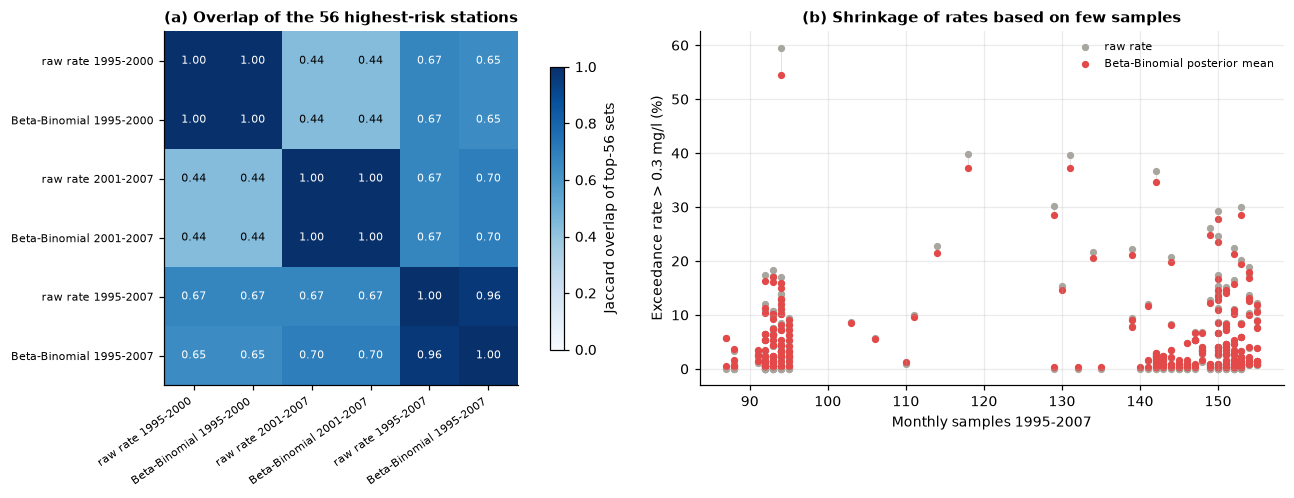

In [37]:
# ==== CELL 2 ==== Experiment 5b - risk ranking from pre-2008 data and its stability (raw vs Beta-Binomial shrinkage)
from scipy.special import betaln
from scipy.optimize import minimize
from scipy.stats import spearmanr
def exc_counts(y0_, y1_, thr):
    hist = (yr >= y0_) & (yr <= y1_); k = np.zeros(S); n = np.zeros(S)
    for i in range(S):
        m = hist & ~np.isnan(V[i]); n[i] = m.sum(); k[i] = exceed(V[i, m], CEN[i, m], thr).sum()
    return k, n
def eb_beta_binomial(k, n):
    # empirical Bayes: maximise the Beta-Binomial marginal likelihood over stations with >= 1 sample
    m = n > 0
    def nll(p):
        a, b = np.exp(p); return -np.sum(betaln(k[m] + a, n[m] - k[m] + b) - betaln(a, b))
    r0 = max(k[m].sum() / n[m].sum(), 1e-3)
    res = minimize(nll, np.log([r0 * 20, (1 - r0) * 20]), method="Nelder-Mead", options={"maxiter": 5000, "xatol": 1e-7, "fatol": 1e-9})
    return tuple(np.exp(res.x))
def risk_score(y0_, y1_, method, thr=PRIMARY):
    k, n = exc_counts(y0_, y1_, thr)
    if method == "raw": return np.where(n > 0, k / np.maximum(n, 1), 0.0), k, n, (np.nan, np.nan)
    a, b = eb_beta_binomial(k, n); return (k + a) / (n + a + b), k, n, (a, b)
REST = (2,) if FAST else (3, 2, 1); N_HI = {r_: int(np.floor((4 - r_) * S / (12 - r_))) for r_ in REST}      # mean budget <= 4 visits/station-yr
RANKS = {}
for (a_, b_) in ((1995, 2000), (2001, 2007), (1995, 2007), (1995, 2004)):
    for meth in ("raw", "eb"):
        sc, k, n, ab = risk_score(a_, b_, meth); RANKS[(meth, a_, b_)] = dict(order=np.lexsort((-n, -sc)), score=sc, k=k, n=n, ab=ab)
PRIMARY_RANK, DEV_RANK = ("eb", 1995, 2007), ("eb", 1995, 2004)
ev_st = np.array([exceed(V[i, EVAL[i]], CEN[i, EVAL[i]], PRIMARY).sum() for i in range(S)])
nh = N_HI[2]; top = lambda key, n_=nh: set(RANKS[key]["order"][:n_].tolist())
rank_label = lambda key: f"{'Beta-Binomial' if key[0] == 'eb' else 'raw rate'} {key[1]}-{key[2]}"
rows = []
for key, R_ in RANKS.items():
    if key[1:] == (1995, 2004): continue
    tp_ = list(top(key)); sh = ev_st[tp_].sum() / ev_st.sum()
    rows.append({"ranking": rank_label(key), "alpha, beta": "-" if key[0] == "raw" else f"{R_['ab'][0]:.2f}, {R_['ab'][1]:.1f}",
                 f"Jaccard of top {nh} with primary": len(top(key) & top(PRIMARY_RANK)) / len(top(key) | top(PRIMARY_RANK)),
                 "Spearman with primary": spearmanr(R_["score"], RANKS[PRIMARY_RANK]["score"]).correlation,
                 f"min. samples among top {nh}": int(R_["n"][tp_].min()), f"share of 2008-2024 events at top {nh}": sh,
                 **{f"observation-only recall, {N_HI[r_]} monthly + {r_}/yr": (ev_st[list(top(key, N_HI[r_]))].sum() / ev_st.sum()) * (1 - r_ / 12) + r_ / 12 for r_ in REST}})
RSTAB = pd.DataFrame(rows); save_table(RSTAB, "T19_risk_ranking_stability"); display(RSTAB.round(3))
keys_ = [k_ for k_ in RANKS if k_[1:] != (1995, 2004)]
J = np.array([[len(top(a) & top(b)) / len(top(a) | top(b)) for b in keys_] for a in keys_])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
im = ax[0].imshow(J, vmin=0, vmax=1, cmap="Blues"); ax[0].grid(False)
ax[0].set_xticks(range(len(keys_))); ax[0].set_xticklabels([rank_label(k_) for k_ in keys_], fontsize=7, rotation=35, ha="right")
ax[0].set_yticks(range(len(keys_))); ax[0].set_yticklabels([rank_label(k_) for k_ in keys_], fontsize=7)
for i in range(len(keys_)):
    for j in range(len(keys_)): ax[0].text(j, i, f"{J[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if J[i, j] > .6 else "k")
plt.colorbar(im, ax=ax[0], shrink=.8, label=f"Jaccard overlap of top-{nh} sets"); ax[0].set_title(f"(a) Overlap of the {nh} highest-risk stations")
Rr, Re = RANKS[("raw", 1995, 2007)], RANKS[PRIMARY_RANK]
ax[1].scatter(Rr["n"], Rr["score"] * 100, s=14, color="#a8a69e", label="raw rate")
ax[1].scatter(Re["n"], Re["score"] * 100, s=14, color="#e34948", label="Beta-Binomial posterior mean")
for i in range(S): ax[1].plot([Rr["n"][i], Re["n"][i]], [Rr["score"][i] * 100, Re["score"][i] * 100], color="#d0d0d0", lw=.4, zorder=0)
ax[1].set_xlabel("Monthly samples 1995-2007"); ax[1].set_ylabel(f"Exceedance rate > {PRIMARY} mg/l (%)"); ax[1].legend(fontsize=7)
ax[1].set_title("(b) Shrinkage of rates based on few samples")
fig.tight_layout(); savefig(fig, "F16_risk_ranking_stability"); plt.show()

risk-based allocation runs: 589s


mean visits/station-yr  recall  precision  false alarms/station-yr  cut-off (mg/l)  skipped months with same-month neighbour
design                              detection                                                                                                                                         
Uniform 4/yr, synchronised          Observation only                           4   0.333          1                        0             NaN                                         0
                                    Persistence                                4   0.386      0.593                    0.079           0.471                                         0
                                    Neighbour-ratio rule                       4   0.386      0.593                    0.079           0.471                                         0
                                    HistGB + neighbours                        4    0.42      0.726                    0.047           0.234                                         0
Uniform 4/yr, staggered             Observation only                           4   0.333          1                        0             NaN                                     0.784
                                    Persistence                                4   0.386      0.593                    0.079           0.471                                     0.784
                                    Neighbour-ratio rule                       4   0.385      0.657                     0.06           0.855                                     0.784
                                    HistGB + neighbours                        4   0.431      0.712                    0.052           0.229                                     0.784
Risk-based: 31 monthly, others 3/yr Observation only                       3.993   0.566          1                        0             NaN                                     0.714
                                    Persistence                            3.993   0.583      0.703                    0.073           0.408                                     0.714
                                    Neighbour-ratio rule                   3.993   0.598      0.743                    0.062           0.725                                     0.714
                                    HistGB + neighbours                    3.993   0.581      0.881                    0.023           0.187                                     0.714
Risk-based: 56 monthly, others 2/yr Observation only                       3.993   0.642          1                        0             NaN                                     0.559
                                    Persistence                            3.993   0.656      0.713                    0.079            0.36                                     0.559
                                    Neighbour-ratio rule                   3.993   0.668      0.769                     0.06           0.603                                     0.559
                                    HistGB + neighbours                    3.993   0.655      0.883                    0.026           0.165                                     0.559
Risk-based: 76 monthly, others 1/yr Observation only                       3.975   0.709          1                        0             NaN                                     0.426
                                    Persistence                            3.975   0.717      0.736                    0.077           0.306                                     0.426
                                    Neighbour-ratio rule                   3.975   0.726      0.777                    0.062           0.511                                     0.426
                                    HistGB + neighbours                    3.975   0.717      0.908                    0.022           0.158                                     0.426

,threshold,cluster,comparison,d recall,95% CI low,95% CI high
12,0.3,station,"Risk-based: 31 monthly, others 3/yr [HistGB + ...",0.15,0.087,0.21
13,0.3,station,"Risk-based: 31 monthly, others 3/yr [Observati...",0.135,0.069,0.196
14,0.3,station,"Risk-based: 31 monthly, others 3/yr [Persisten...",0.198,0.112,0.271
15,0.3,station,"Risk-based: 31 monthly, others 3/yr [HistGB + ...",0.015,0.007,0.025
16,0.3,station,"Risk-based: 56 monthly, others 2/yr [HistGB + ...",0.224,0.157,0.294
17,0.3,station,"Risk-based: 56 monthly, others 2/yr [Observati...",0.211,0.14,0.284
18,0.3,station,"Risk-based: 56 monthly, others 2/yr [Persisten...",0.27,0.186,0.345
19,0.3,station,"Risk-based: 56 monthly, others 2/yr [HistGB + ...",0.013,0.006,0.023
20,0.3,station,"Risk-based: 76 monthly, others 1/yr [HistGB + ...",0.287,0.218,0.355
21,0.3,station,"Risk-based: 76 monthly, others 1/yr [Observati...",0.278,0.204,0.349


,design,threshold,HistGB_nb recall (block-retrained),HistGB_nb recall (trained once)
0,"Uniform 4/yr, synchronised",0.2,0.422,0.42
1,"Uniform 4/yr, synchronised",0.3,0.42,0.416
2,"Uniform 4/yr, staggered",0.2,0.438,0.437
3,"Uniform 4/yr, staggered",0.3,0.431,0.432
4,"Risk-based: 31 monthly, others 3/yr",0.2,0.578,0.576
5,"Risk-based: 31 monthly, others 3/yr",0.3,0.581,0.579
6,"Risk-based: 56 monthly, others 2/yr",0.2,0.672,0.673
7,"Risk-based: 56 monthly, others 2/yr",0.3,0.655,0.655
8,"Risk-based: 76 monthly, others 1/yr",0.2,0.729,0.73
9,"Risk-based: 76 monthly, others 1/yr",0.3,0.717,0.717


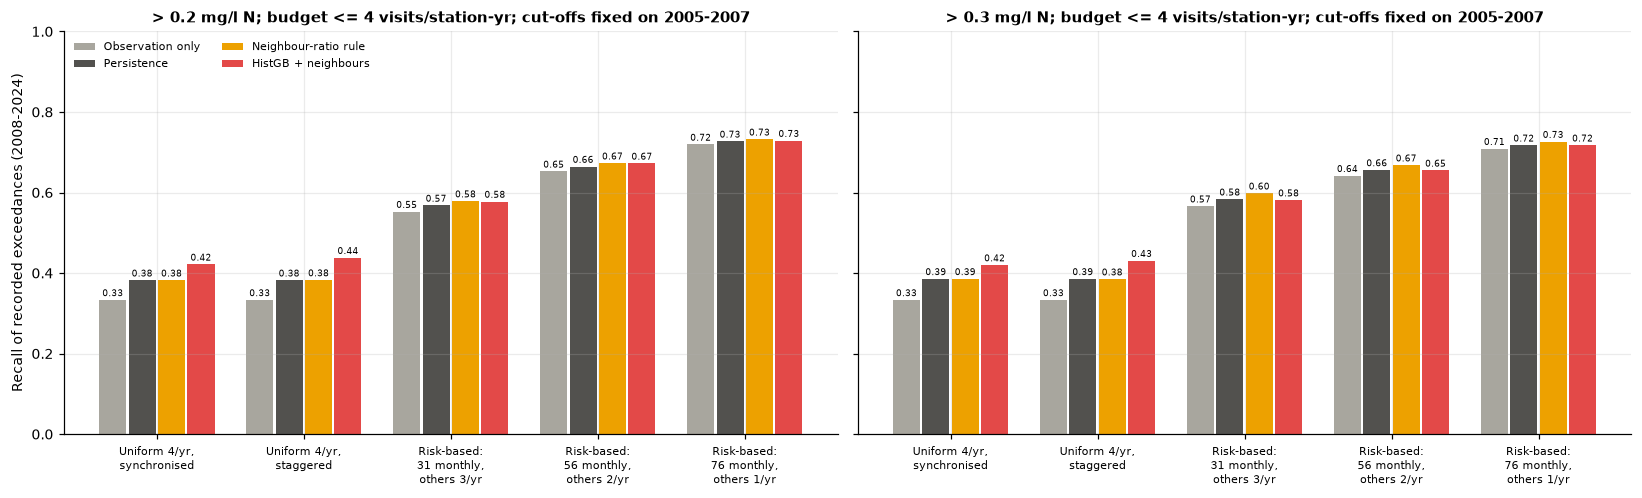

In [38]:
# ==== CELL 3 ==== Experiment 5c - fair comparison: uniform versus risk-based allocation at the same budget and alarm standard
def alloc_av(order, rest, start, rot, _cache={}):
    k_ = 12 // rest; phases = [[q + 1 + j * k_ for j in range(rest)] for q in range(k_)]
    if k_ not in _cache: _cache[k_] = colour(k_)                                   # staggered phases among neighbours
    ph = (_cache[k_] + rot) % k_; hi = np.zeros(S, bool); hi[order[:N_HI[rest]]] = True
    sch = np.zeros((S, T), bool)
    for i in range(S): sch[i] = True if hi[i] else np.isin(mon, phases[ph[i]])
    return ~np.isnan(V) & (sch | (yr < start)[None, :])
def run_alloc(rest):
    # same training rules as Experiment 4: schedule simulated on 1995-2007 + visit pairs actually taken under the allocation in 2008..B-1,
    # one model per 3-year block and spatial cluster (seen design); development model and cut-offs unchanged (1995-2004 ranking, 2005-2007)
    parts = []
    for rot in range(12 // rest):
        TR, _ = items_for(None, None, "network", TRAIN_FROM, train_mask(TRAIN_FROM, CFG["dev"][1]), AV=alloc_av(RANKS[DEV_RANK]["order"], rest, TRAIN_FROM, rot))
        AVe = alloc_av(RANKS[PRIMARY_RANK]["order"], rest, CFG["eval"][0], rot)
        EV, RET = items_for(None, None, "network", CFG["eval"][0], EVAL, AV=AVe)
        POST = observed_pairs(AVe, CFG["eval"][0], CFG["eval"][1] - 1)
        EV, dev = train_and_predict(TR, EV, POST, f"risk-based rest {rest}/yr rot {rot}")
        parts.append((EV, RET, dev, rot))
    return parts
t_ = time.time(); ALLOC = {r_: run_alloc(r_) for r_ in REST}; print(f"risk-based allocation runs: {time.time() - t_:.0f}s")
DET = (("Persistence", "Persistence"), ("Neighbour_ratio", "Neighbour-ratio rule"), ("HistGB_nb", "HistGB + neighbours"))
def summarise(parts, thr, design, budget):
    o, EVs, RETs, rev = evaluate_scheme(parts, None, thr)
    yb = exceed(np.exp(EVs.y.values), EVs.cens_target.values, thr); R = rev.sum()
    out = [{"design": design, "mean visits/station-yr": budget, "threshold": thr, "detection": "Observation only", "recall": o["Observation-only recall"],
            "precision": 1.0, "false alarms/station-yr": 0.0, "cut-off (mg/l)": np.nan, "skipped months with same-month neighbour": o["skipped months with a neighbour sampled in the same month"]}]
    for s_, lab in DET:
        a = EVs[f"alarm_{s_}"].values; tp = (a & yb).sum() + R
        out.append({"design": design, "mean visits/station-yr": budget, "threshold": thr, "detection": lab, "recall": o[f"{s_} recall"], "precision": tp / (a.sum() + R),
                    "false alarms/station-yr": o[f"{s_} false alarms/station-yr"], "cut-off (mg/l)": o[f"{s_} cut-off"],
                    "skipped months with same-month neighbour": o["skipped months with a neighbour sampled in the same month"]})
    return out, (EVs, RETs, rev)
DESIGNS = [("Uniform 4/yr, synchronised", NET[(4, "network: synchronised")], 4.0), ("Uniform 4/yr, staggered", NET[(4, "network: staggered (graph colouring)")], 4.0)] + \
          [(f"Risk-based: {N_HI[r_]} monthly, others {r_}/yr", ALLOC[r_], (12 * N_HI[r_] + r_ * (S - N_HI[r_])) / S) for r_ in REST]
FAIR_ROWS, FAIR_EV = [], {}
for thr in (0.2, PRIMARY):
    for name, parts, bud in DESIGNS:
        rows_, ev_ = summarise(parts, thr, name, bud); FAIR_ROWS += rows_; FAIR_EV[(name, thr)] = ev_
FAIR = pd.DataFrame(FAIR_ROWS); save_table(FAIR, "T20_fair_allocation_comparison")
display(FAIR[FAIR.threshold == PRIMARY].set_index(["design", "detection"]).drop(columns="threshold").round(3))
def st_counts(name, thr, det, cluster="station"):
    EVs, RETs, rev = FAIR_EV[(name, thr)]; yb = exceed(np.exp(EVs.y.values), EVs.cens_target.values, thr); ke, kr, K = unit_keys(EVs, RETs, cluster)
    tp = np.bincount(kr, rev.astype(float), K); ev = tp + np.bincount(ke, yb.astype(float), K)
    if det != "Observation only":
        s_ = {lab: k for k, lab in DET}[det]; tp = tp + np.bincount(ke, (EVs[f"alarm_{s_}"].values & yb).astype(float), K)
    return tp, ev
fb = []; U = "Uniform 4/yr, staggered"
for cl in ("station", "year"):
    K = S if cl == "station" else NYR; dd = np.random.RandomState(SEED).randint(0, K, (CFG["n_boot"], K))
    for thr in (0.2, PRIMARY):
        for r_ in REST:
            Rn = f"Risk-based: {N_HI[r_]} monthly, others {r_}/yr"
            for (na, da), (nb_, db) in (((Rn, "HistGB + neighbours"), (U, "HistGB + neighbours")), ((Rn, "Observation only"), (U, "HistGB + neighbours")),
                                        ((Rn, "Persistence"), (U, "Persistence")), ((Rn, "HistGB + neighbours"), (Rn, "Observation only"))):
                ta, ea = st_counts(na, thr, da, cl); tb, eb = st_counts(nb_, thr, db, cl)
                bs_ = ta[dd].sum(1) / ea[dd].sum(1) - tb[dd].sum(1) / eb[dd].sum(1)
                fb.append({"threshold": thr, "cluster": cl, "comparison": f"{na} [{da}]  minus  {nb_} [{db}]", "d recall": ta.sum() / ea.sum() - tb.sum() / eb.sum(),
                           "95% CI low": np.percentile(bs_, 2.5), "95% CI high": np.percentile(bs_, 97.5)})
FAIRB = pd.DataFrame(fb); save_table(FAIRB, "T20b_fair_allocation_bootstrap"); display(FAIRB[FAIRB.threshold == PRIMARY].round(3))
ONCE5 = pd.DataFrame([{"design": n, "threshold": thr, "HistGB_nb recall (block-retrained)": evaluate_scheme(p_, None, thr)[0]["HistGB_nb recall"],
                       "HistGB_nb recall (trained once)": evaluate_scheme(p_, None, thr)[0]["HistGB_nb (trained once) recall"]} for n, p_, _ in DESIGNS for thr in (0.2, PRIMARY)])
save_table(ONCE5, "T20c_allocation_retraining_vs_trained_once"); display(ONCE5.round(3))
dets = ["Observation only", "Persistence", "Neighbour-ratio rule", "HistGB + neighbours"]; dcol = [COL["Observation-only"], COL["Persistence"], COL["Neighbour_ratio"], COL["HistGB_nb"]]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for a_, thr in zip(ax, (0.2, PRIMARY)):
    x = FAIR[FAIR.threshold == thr]; names = [n for n, _, _ in DESIGNS]; xx = np.arange(len(names)); w = .2
    for i, (dt, cc) in enumerate(zip(dets, dcol)):
        y_ = [x[(x.design == n) & (x.detection == dt)].recall.iloc[0] for n in names]
        b = a_.bar(xx + (i - 1.5) * w, y_, w * .92, color=cc, label=dt); a_.bar_label(b, fmt="%.2f", fontsize=6, padding=1)
    a_.set_xticks(xx); a_.set_xticklabels([n.replace(": ", ":\n").replace(", ", ",\n") for n in names], fontsize=7.5)
    a_.set_title(f"> {thr} mg/l N; budget <= 4 visits/station-yr; cut-offs fixed on 2005-2007"); a_.set_ylim(0, 1)
ax[0].set_ylabel("Recall of recorded exceedances (2008-2024)"); ax[0].legend(fontsize=7, ncol=2, loc="upper left")
fig.tight_layout(); savefig(fig, "F17_fair_allocation_comparison"); plt.show()

#### 14.4 Who gains and who loses under risk-based allocation — and adaptive re-ranking
Recall over all exceedances favours designs that concentrate effort where exceedances are frequent. To expose the trade-off, observation-only detection (exact, no model, no false alarms) is reported separately for the pre-2008 high-risk stations, the other stations and the **'emerging' stations** (no exceedance in 1995–2007 but at least one in 2008–2024). A **re-ranked** design updates the Beta-Binomial ranking every three years using only the samples actually taken under the reduced schedule.

,"recall, all stations","recall, 56 pre-2008 high-risk stations","recall, 225 other stations",'emerging' stations (n=12) detected at least once
design,,,,
uniform 4/yr,0.333,0.333,0.333,0.444
"risk-based, static ranking (1995-2007)",0.642,1,0.167,0.222
"risk-based, re-ranked every 3 yr",0.657,0.97,0.242,0.25


pre-2008 high-risk set: 56 stations holding 57% of the 2008-2024 exceedances; 'emerging' stations: 12 with 17 exceedances (2%)


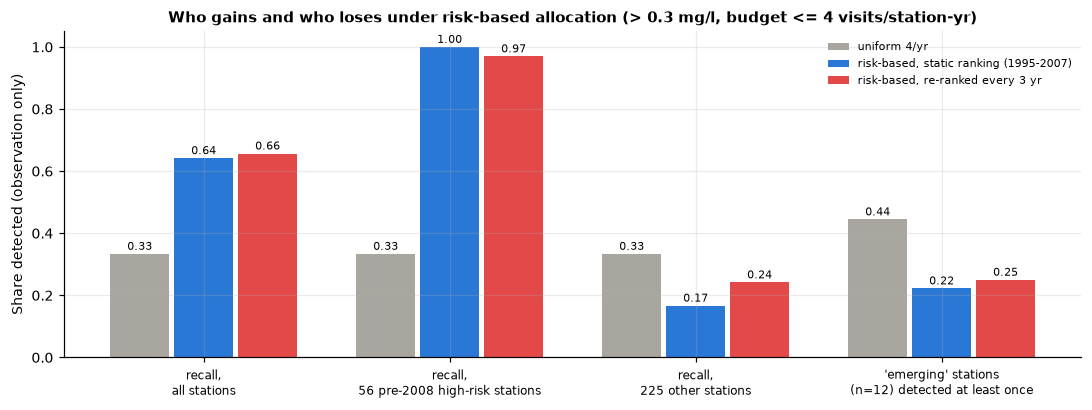

In [39]:
# ==== CELL B ==== 14.4 Cost of risk-based allocation for low-risk and 'emerging' stations, and adaptive re-ranking (standalone)
# Observation-only detection (no model, no false alarms): exact and comparable for every design. Budget <= 4 visits per station-year.
from scipy.special import betaln
from scipy.optimize import minimize
THR_ = 0.3; NHI = int(np.floor(2 * NS / 10)); REST_ = 2; KPH = 12 // REST_          # 56 stations monthly, others 2 visits/yr (6 phases)
EXCM = (VV > THR_) & ~CC & ~np.isnan(VV)                                                # recorded exceedance
def eb_score(k, n):
    msk = n > 0
    def nll(p): a, b = np.exp(p); return -np.sum(betaln(k[msk] + a, n[msk] - k[msk] + b) - betaln(a, b))
    r0 = max(k[msk].sum() / n[msk].sum(), 1e-3); a, b = np.exp(minimize(nll, np.log([r0 * 20, (1 - r0) * 20]), method="Nelder-Mead").x)
    return (k + a) / (n + a + b)
def static_rank():
    h = (YR >= 1995) & (YR <= 2007); obs = ~np.isnan(VV) & h[None, :]
    sc = eb_score((EXCM & obs).sum(1).astype(float), obs.sum(1).astype(float)); return np.argsort(-sc, kind="stable")
PH = [[q + 1 + j * KPH for j in range(REST_)] for q in range(KPH)]
def simulate(design, rot):
    # returns the visited-month mask (S x T) for 2008-2024 under the design; before 2008 everything observed
    vis = ~np.isnan(VV) & (YR < 2008)[None, :]
    if design == "uniform 4/yr":
        sch = np.isin(MON, [[1, 4, 7, 10], [2, 5, 8, 11], [3, 6, 9, 12]][rot % 3])[None, :].repeat(NS, 0)
        return vis | (~np.isnan(VV) & sch & (YR >= 2008)[None, :]), None
    order = static_rank(); hi_hist = []
    for B in range(2008, 2025, 3):
        if design == "risk-based, re-ranked every 3 yr" and B > 2008:
            h = (YR >= 1995) & (YR < B); obs = vis & h[None, :]                         # only what was actually sampled so far
            order = np.argsort(-eb_score((EXCM & obs).sum(1).astype(float), obs.sum(1).astype(float)), kind="stable")
        hi = np.zeros(NS, bool); hi[order[:NHI]] = True; hi_hist.append(hi.copy())
        lo_rank = {i: r for r, i in enumerate([i for i in order if not hi[i]])}
        blk = (YR >= B) & (YR <= min(B + 2, 2024))
        for i in range(NS):
            sch = np.ones(TT, bool) if hi[i] else np.isin(MON, PH[(lo_rank[i] + rot) % KPH])
            vis[i] |= ~np.isnan(VV[i]) & sch & blk
    return vis, hi_hist
# station groups defined from pre-2008 information only
h0 = (YR >= 1995) & (YR <= 2007); pre_exc = (EXCM & h0[None, :]).sum(1); ev_mask = EVM & ~np.isnan(VV)
HI0 = np.zeros(NS, bool); HI0[static_rank()[:NHI]] = True
EMERG = (pre_exc == 0) & (EXCM & ev_mask).any(1)                                        # no exceedance before 2008, at least one after
rows, delay = [], []
for design in ("uniform 4/yr", "risk-based, static ranking (1995-2007)", "risk-based, re-ranked every 3 yr"):
    nrot = 3 if design == "uniform 4/yr" else KPH; acc = []
    for rot in range(nrot):
        vis, _ = simulate(design, rot); det = EXCM & ev_mask & vis; tot = EXCM & ev_mask
        first_true = np.where(tot.any(1), np.argmax(tot, 1), -1); first_det = np.where(det.any(1), np.argmax(det, 1), -1)
        dl = [(first_det[i] - first_true[i]) / 12 if first_det[i] >= 0 else np.nan for i in np.flatnonzero(EMERG)]
        acc.append({"recall, all stations": det.sum() / tot.sum(), f"recall, {NHI} pre-2008 high-risk stations": det[HI0].sum() / tot[HI0].sum(),
                    f"recall, {NS - NHI} other stations": det[~HI0].sum() / tot[~HI0].sum(),
                    f"'emerging' stations (n={int(EMERG.sum())}) detected at least once": np.mean([det[i].any() for i in np.flatnonzero(EMERG)])})
    r_ = pd.DataFrame(acc).mean().to_dict(); r_["design"] = design; rows.append(r_)
COST = pd.DataFrame(rows).set_index("design")
COST.to_csv(os.path.join(OUT, "T22_allocation_tradeoffs.csv")); display(COST.round(3))
print(f"pre-2008 high-risk set: {NHI} stations holding {(EXCM & ev_mask)[HI0].sum() / (EXCM & ev_mask).sum():.0%} of the 2008-2024 exceedances; "
      f"'emerging' stations: {int(EMERG.sum())} with {(EXCM & ev_mask)[EMERG].sum()} exceedances ({(EXCM & ev_mask)[EMERG].sum() / (EXCM & ev_mask).sum():.0%})")
fig, ax = plt.subplots(figsize=(10, 3.8)); cols = list(COST.columns[:4]); xx = np.arange(len(cols)); w = .26
for k, (dname, cc) in enumerate(zip(COST.index, ["#a8a69e", "#2a78d6", "#e34948"])):
    b = ax.bar(xx + (k - 1) * w, COST.loc[dname, cols], w * .92, color=cc, label=dname); ax.bar_label(b, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticks(xx); ax.set_xticklabels([c.replace(", ", ",\n").replace(" (", "\n(") for c in cols], fontsize=8); ax.set_ylim(0, 1.05)
ax.set_ylabel("Share detected (observation only)"); ax.legend(fontsize=7, loc="upper right"); ax.set_title(f"Who gains and who loses under risk-based allocation (> {THR_} mg/l, budget <= 4 visits/station-yr)")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "F18_allocation_tradeoffs.png"), dpi=300, bbox_inches="tight"); plt.show()

#### 14.5 Maps: study area, river network, flow-connected neighbours and risk-based allocation

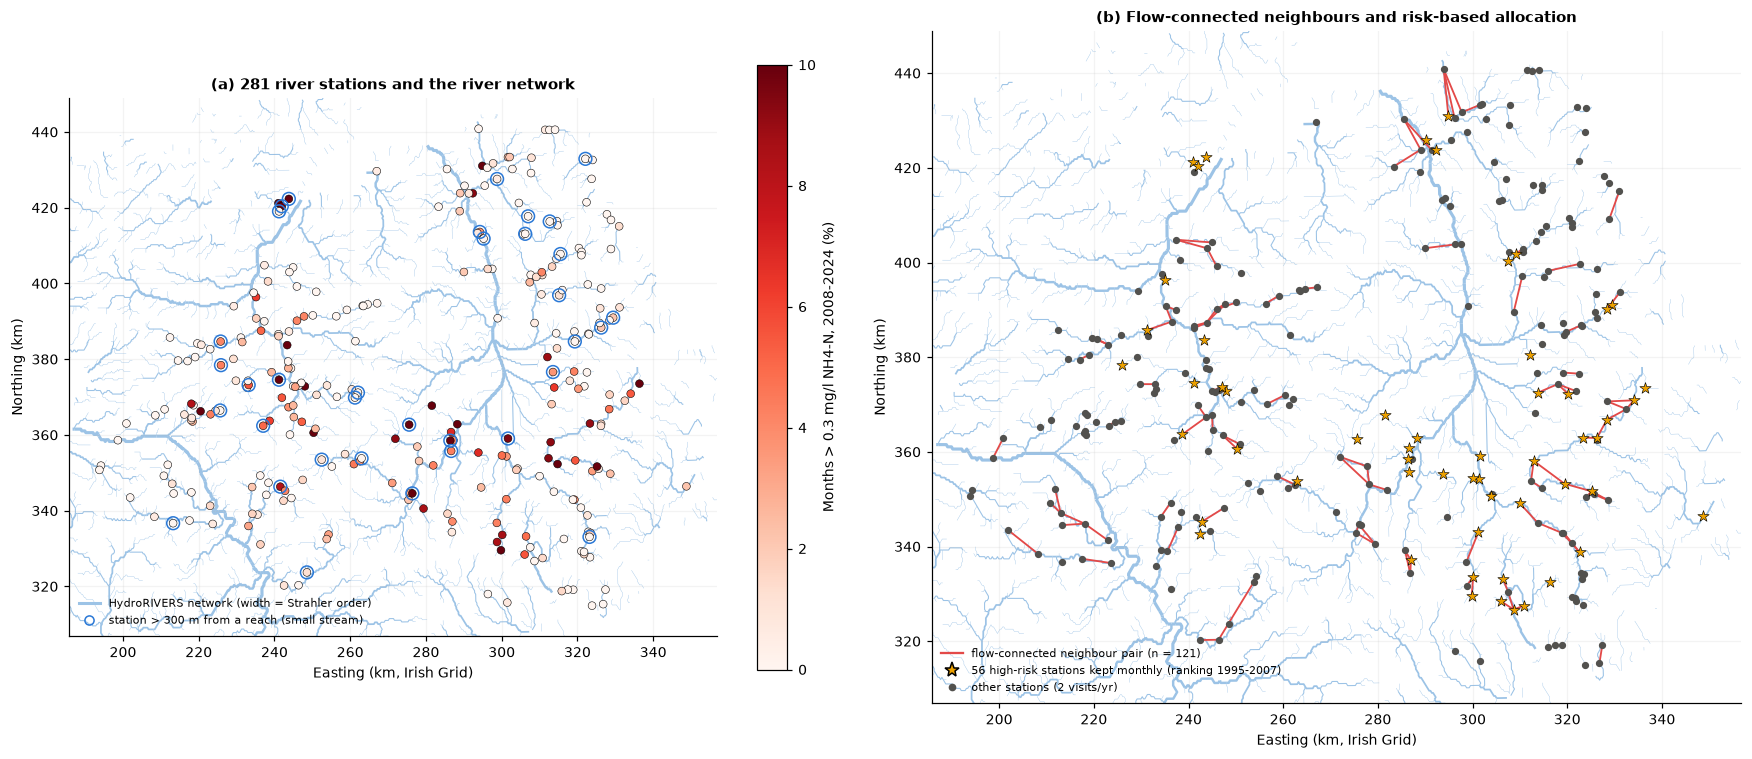

flow-connected neighbour pairs (<= 15 km, 3 nearest): 121; stations in at least one pair: 158


In [40]:
# ==== CELL C ==== Map: river network, stations, flow-connected neighbour pairs and high-risk stations (run after CELL A and CELL B)
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
rate_ = np.array([(EXCM[i] & ev_mask[i]).sum() / max(ev_mask[i].sum(), 1) for i in range(NS)]) * 100        # % of 2008-2024 months > 0.3 mg/l
pairs = []
for i in range(NS):
    for k in range(1, 4):
        j = nK[i, k]
        if dK[i, k] / 1000 > 15: continue
        r_, fd = flow_rel(i, j)
        if r_ in ("upstream", "downstream") and i < j: pairs.append((i, j))
ordr = np.array([PR[r]["ORD_STRA"] for r in rid])
segs = [np.asarray(L.coords) / 1000 for L in lines]
reliable = SNAP.snap_m.values <= SNAP_MAX_M
fig, ax = plt.subplots(1, 2, figsize=(16, 7.6))  # combined figure; panels are also saved separately below
for a_ in ax:
    a_.add_collection(LineCollection(segs, linewidths=0.25 + 0.45 * (ordr - 1), colors="#9cc3e6", zorder=1))
    a_.set_aspect("equal"); a_.set_xlim(XY[:, 0].min() / 1000 - 8, XY[:, 0].max() / 1000 + 8); a_.set_ylim(XY[:, 1].min() / 1000 - 8, XY[:, 1].max() / 1000 + 8)
    a_.set_xlabel("Easting (km, Irish Grid)"); a_.set_ylabel("Northing (km)"); a_.grid(alpha=.15)
# (a) stations coloured by exceedance rate_
sc = ax[0].scatter(XY[:, 0] / 1000, XY[:, 1] / 1000, c=rate_, cmap="Reds", vmin=0, vmax=10, s=26, edgecolor="k", lw=.35, zorder=3)
plt.colorbar(sc, ax=ax[0], shrink=.75, label="Months > 0.3 mg/l NH4-N, 2008-2024 (%)")
ax[0].scatter(XY[~reliable, 0] / 1000, XY[~reliable, 1] / 1000, s=70, facecolor="none", edgecolor="#2a78d6", lw=1, zorder=4)
ax[0].legend(handles=[Line2D([], [], color="#9cc3e6", lw=2, label="HydroRIVERS network (width = Strahler order)"),
                      Line2D([], [], marker="o", ls="", mfc="none", mec="#2a78d6", label=f"station > {SNAP_MAX_M} m from a reach (small stream)")], fontsize=7, loc="lower left")
ax[0].set_title(f"(a) {NS} river stations and the river network")
# (b) flow-connected neighbour pairs and pre-2008 high-risk stations
for i, j in pairs: ax[1].plot(XY[[i, j], 0] / 1000, XY[[i, j], 1] / 1000, color="#e34948", lw=1.2, zorder=2)
ax[1].scatter(XY[~HI0, 0] / 1000, XY[~HI0, 1] / 1000, s=14, color="#52514e", zorder=3)
ax[1].scatter(XY[HI0, 0] / 1000, XY[HI0, 1] / 1000, s=60, marker="*", color="#eda100", edgecolor="k", lw=.4, zorder=4)
ax[1].legend(handles=[Line2D([], [], color="#e34948", lw=1.5, label=f"flow-connected neighbour pair (n = {len(pairs)})"),
                      Line2D([], [], marker="*", ls="", color="#eda100", mec="k", ms=10, label=f"{NHI} high-risk stations kept monthly (ranking 1995-2007)"),
                      Line2D([], [], marker="o", ls="", color="#52514e", ms=4, label="other stations (2 visits/yr)")], fontsize=7, loc="lower left")
ax[1].set_title("(b) Flow-connected neighbours and risk-based allocation")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "F19_map_river_network.png"), dpi=300, bbox_inches="tight")
for k_, nm in ((0, "F19a_study_area_map"), (1, "F19b_flow_pairs_allocation_map")):
    ext = ax[k_].get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    if k_ == 0: ext = ext.union([ext, fig.axes[2].get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())])
    fig.savefig(os.path.join(FIG, nm + ".png"), dpi=300, bbox_inches=ext.expanded(1.02, 1.02))
plt.show()
print(f"flow-connected neighbour pairs (<= 15 km, 3 nearest): {len(pairs)}; stations in at least one pair: {len(set(np.ravel(pairs)))}")

#### 14.6 Sampling effort and detection at three levels (added in revision)
Added after peer review of the manuscript, after the primary results were known; no model, cut-off, ranking or station group is changed. It reports (i) the planned and realised visits of each design (manuscript Table S6) and (ii) observation-only detection at three levels: recorded exceedances (the primary metric), station-years with an exceedance and stations with an exceedance, with paired station-bootstrap intervals for each risk-based design minus the uniform design. It also exports the overlap (Jaccard) of the top-56 sets between all ranking periods.

,design,nominal visits per station-year (equal station-years),planned visits per evaluated station-year,realised visits per evaluated station-year,share of evaluated station-years at monthly stations
0,"Uniform 4/yr, staggered",4,4,3.795,NaN
1,"Risk-based: 31 monthly, others 3/yr",3.993,3.891,3.691,0.099
2,"Risk-based: 56 monthly, others 2/yr",3.993,3.829,3.638,0.183
3,"Risk-based: 76 monthly, others 1/yr",3.975,3.786,3.602,0.253


,design,level,all stations,56 pre-2008 high-risk stations,225 other stations,'emerging' stations (n=12),units (all stations)
0,"Uniform 4/yr, staggered",recorded exceedances,0.333,0.333,0.333,0.333,828
1,"Uniform 4/yr, staggered",station-years with an exceedance,0.448,0.517,0.391,0.354,524
2,"Uniform 4/yr, staggered",stations with an exceedance,0.65,0.847,0.567,0.444,162
3,"Risk-based: 31 monthly, others 3/yr",recorded exceedances,0.566,0.805,0.25,0.25,828
4,"Risk-based: 31 monthly, others 3/yr",station-years with an exceedance,0.506,0.751,0.301,0.266,524
5,"Risk-based: 31 monthly, others 3/yr",stations with an exceedance,0.62,0.885,0.509,0.354,162
6,"Risk-based: 56 monthly, others 2/yr",recorded exceedances,0.642,1,0.167,0.167,828
7,"Risk-based: 56 monthly, others 2/yr",station-years with an exceedance,0.568,1,0.206,0.177,524
8,"Risk-based: 56 monthly, others 2/yr",stations with an exceedance,0.556,1,0.368,0.222,162
9,"Risk-based: 76 monthly, others 1/yr",recorded exceedances,0.709,1,0.323,0.083,828


,comparison,level,difference,95% CI low,95% CI high
0,"Risk-based: 31 monthly, others 3/yr minus Un...",recorded exceedances,0.233,0.128,0.333
1,"Risk-based: 31 monthly, others 3/yr minus Un...",station-years with an exceedance,0.058,0.007,0.11
2,"Risk-based: 31 monthly, others 3/yr minus Un...",stations with an exceedance,-0.03,-0.055,0.001
3,"Risk-based: 56 monthly, others 2/yr minus Un...",recorded exceedances,0.308,0.204,0.402
4,"Risk-based: 56 monthly, others 2/yr minus Un...",station-years with an exceedance,0.12,0.051,0.187
5,"Risk-based: 56 monthly, others 2/yr minus Un...",stations with an exceedance,-0.095,-0.124,-0.06
6,"Risk-based: 76 monthly, others 1/yr minus Un...",recorded exceedances,0.376,0.277,0.458
7,"Risk-based: 76 monthly, others 1/yr minus Un...",station-years with an exceedance,0.175,0.094,0.248
8,"Risk-based: 76 monthly, others 1/yr minus Un...",stations with an exceedance,-0.134,-0.186,-0.079
9,"Risk-based: 56 monthly, others 2/yr, re-ranked...",recorded exceedances,0.323,0.225,0.411


,ranking A,ranking B,Jaccard of top 56,shared stations
0,raw rate 1995-2000,Beta-Binomial 1995-2000,1,56
1,raw rate 1995-2000,raw rate 2001-2007,0.436,34
2,raw rate 1995-2000,Beta-Binomial 2001-2007,0.436,34
3,raw rate 1995-2000,raw rate 1995-2007,0.672,45
4,raw rate 1995-2000,Beta-Binomial 1995-2007,0.647,44
5,raw rate 1995-2000,raw rate 1995-2004,0.647,44
6,raw rate 1995-2000,Beta-Binomial 1995-2004,0.647,44
7,Beta-Binomial 1995-2000,raw rate 2001-2007,0.436,34
8,Beta-Binomial 1995-2000,Beta-Binomial 2001-2007,0.436,34
9,Beta-Binomial 1995-2000,raw rate 1995-2007,0.672,45


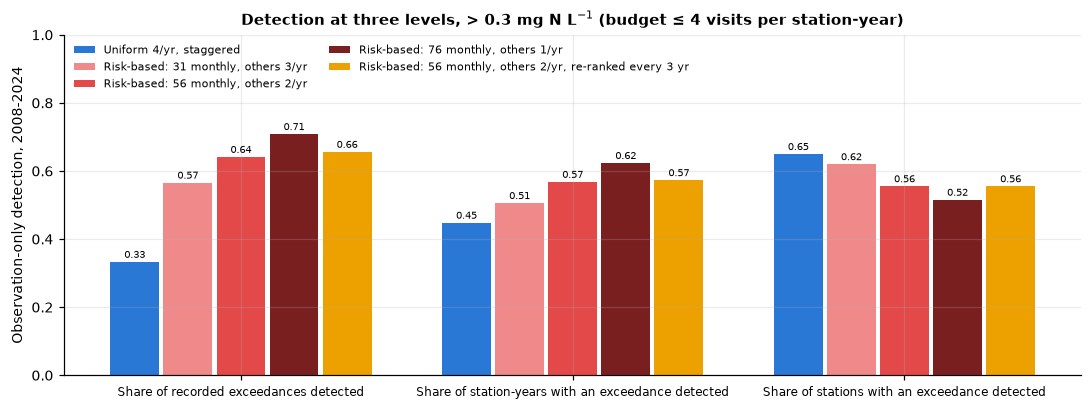

In [41]:
# ==== CELL R1 ==== 14.6 (revision) Realised sampling effort and detection at event, station-year and station level
# Observation-only detection is exact (no model, no false alarms) and comparable across designs. Rankings, station groups and
# schedules are those of Sections 14.2-14.4; nothing is re-selected on evaluation data. Results are averaged over all schedule rotations.
Y0, Y1 = CFG["eval"]; ORDER = RANKS[PRIMARY_RANK]["order"]
SYM = okSY[:, yr - 1990] & ((yr >= Y0) & (yr <= Y1))[None, :]            # every month of the evaluated (complete) station-years
EXC_ALL = exceed(np.nan_to_num(V, nan=0.0), CEN, PRIMARY) & ~np.isnan(V)  # recorded exceedances, all months
EXC = EXC_ALL & EVAL                                                      # recorded exceedances in the evaluation months
EV_COLS = np.flatnonzero((yr >= Y0) & (yr <= Y1)); NY = Y1 - Y0 + 1
def sched_static(n_hi, rest, rot, order=ORDER):
    # scheduled months in 2008-2024: n_hi highest-risk stations monthly, the others `rest` visits/yr on staggered phases
    k_ = 12 // rest; phases = [[q + 1 + j * k_ for j in range(rest)] for q in range(k_)]
    ph = (colour(k_) + rot) % k_; hi = np.zeros(S, bool); hi[order[:n_hi]] = True
    sch = np.zeros((S, T), bool)
    for i in range(S): sch[i] = True if hi[i] else np.isin(mon, phases[ph[i]])
    return sch & ((yr >= Y0) & (yr <= Y1))[None, :], hi
def sched_reranked(n_hi, rest, rot):
    # as Section 14.4: the ranking is updated every three years from the samples actually taken under the reduced schedule
    k_ = 12 // rest; phases = [[q + 1 + j * k_ for j in range(rest)] for q in range(k_)]
    pre = ~np.isnan(V) & (yr < Y0)[None, :]; sch = np.zeros((S, T), bool)
    for B in range(Y0, Y1 + 1, 3):
        seen = (pre | (sch & ~np.isnan(V))) & ((yr >= 1995) & (yr < B))[None, :] if B > Y0 else ~np.isnan(V) & ((yr >= 1995) & (yr <= Y0 - 1))[None, :]
        order = np.argsort(-eb_score((EXC_ALL & seen).sum(1).astype(float), seen.sum(1).astype(float)), kind="stable")
        hi = np.zeros(S, bool); hi[order[:n_hi]] = True
        lo_rank = {i: r for r, i in enumerate([i for i in order if not hi[i]])}
        blk = (yr >= B) & (yr <= min(B + 2, Y1))
        for i in range(S): sch[i, blk] = True if hi[i] else np.isin(mon[blk], phases[(lo_rank[i] + rot) % k_])
    return sch, None
def per_station(masks):
    # per-station counts averaged over rotations: events, station-years with an event, station with any event; and how many are observed
    ev_t = EXC.sum(1).astype(float); sy_e = EXC[:, EV_COLS].reshape(S, NY, 12).any(2); sy_t = sy_e.sum(1).astype(float); st_t = EXC.any(1).astype(float)
    ev_d, sy_d, st_d = np.zeros(S), np.zeros(S), np.zeros(S)
    for sch in masks:
        D = EXC & sch; ev_d += D.sum(1); sy_d += D[:, EV_COLS].reshape(S, NY, 12).any(2).sum(1); st_d += D.any(1)
    n = len(masks); return dict(ev=(ev_t, ev_d / n), sy=(sy_t, sy_d / n), st=(st_t, st_d / n))
LEVELS = {"ev": "recorded exceedances", "sy": "station-years with an exceedance", "st": "stations with an exceedance"}
DES6 = [("Uniform 4/yr, staggered", 0, 4, "static")] + [(f"Risk-based: {N_HI[r_]} monthly, others {r_}/yr", N_HI[r_], r_, "static") for r_ in REST]
if 2 in REST: DES6.append((f"Risk-based: {N_HI[2]} monthly, others 2/yr, re-ranked every 3 yr", N_HI[2], 2, "reranked"))
HI56 = np.zeros(S, bool); HI56[ORDER[:N_HI[2]]] = True
EMERG_R = (EXC_ALL & ~np.isnan(V) & ((yr >= 1995) & (yr < Y0))[None, :]).sum(1) == 0
EMERG_R &= EXC.any(1)
GROUPS_R = {"all stations": np.ones(S, bool), f"{HI56.sum()} pre-2008 high-risk stations": HI56, f"{S - HI56.sum()} other stations": ~HI56,
            f"'emerging' stations (n={EMERG_R.sum()})": EMERG_R}
PS, EFF = {}, []
for name, n_hi, rest, kind in DES6:
    masks, his = [], []
    for rot in range(12 // rest):
        sch, hi = sched_static(n_hi, rest, rot) if kind == "static" else sched_reranked(n_hi, rest, rot)
        masks.append(sch); his.append(hi)
    PS[name] = per_station(masks)
    if kind == "static":
        hi = his[0]
        EFF.append({"design": name, "nominal visits per station-year (equal station-years)": (12 * n_hi + rest * (S - n_hi)) / S,
                    "planned visits per evaluated station-year": np.mean([(m & SYM).sum() for m in masks]) / n_sy_eval,
                    "realised visits per evaluated station-year": np.mean([(m & EVAL).sum() for m in masks]) / n_sy_eval,
                    "share of evaluated station-years at monthly stations": okSY[hi][:, Y0 - 1990:Y1 - 1989].sum() / n_sy_eval if n_hi else np.nan})
EFFORT = pd.DataFrame(EFF); save_table(EFFORT, "T32_sampling_effort"); display(EFFORT.round(3))
rows = []
for name in PS:
    for lev, lab in LEVELS.items():
        tot, det = PS[name][lev]
        r_ = {"design": name, "level": lab}
        for g, m in GROUPS_R.items(): r_[g] = det[m].sum() / tot[m].sum() if tot[m].sum() else np.nan
        r_["units (all stations)"] = tot.sum(); rows.append(r_)
LEVT = pd.DataFrame(rows); save_table(LEVT, "T33_detection_levels"); display(LEVT.round(3))
# paired station bootstrap of design - uniform differences (all stations)
rb = []; idx = np.random.RandomState(SEED).randint(0, S, (CFG["n_boot"], S)); base = PS[DES6[0][0]]
for name in list(PS)[1:]:
    for lev, lab in LEVELS.items():
        (t0_, d0_), (t1_, d1_) = base[lev], PS[name][lev]
        est = d1_.sum() / t1_.sum() - d0_.sum() / t0_.sum()
        bs = d1_[idx].sum(1) / t1_[idx].sum(1) - d0_[idx].sum(1) / t0_[idx].sum(1)
        rb.append({"comparison": f"{name}  minus  {DES6[0][0]}", "level": lab, "difference": est,
                   "95% CI low": np.percentile(bs, 2.5), "95% CI high": np.percentile(bs, 97.5)})
LEVB = pd.DataFrame(rb); save_table(LEVB, "T33b_detection_levels_bootstrap"); display(LEVB.round(3))
# overlap of the top-56 sets between all ranking periods (Jaccard), exported for Table S5
keys = list(RANKS); jac = [{"ranking A": rank_label(a), "ranking B": rank_label(b),
                            f"Jaccard of top {N_HI[2]}": len(top(a) & top(b)) / len(top(a) | top(b)), "shared stations": len(top(a) & top(b))}
                           for ai, a in enumerate(keys) for b in keys[ai + 1:]]
JAC = pd.DataFrame(jac); save_table(JAC, "T19b_ranking_overlap"); display(JAC.round(3))
# figure: detection of recorded exceedances, station-years and stations under each design (observation only)
fig, ax = plt.subplots(figsize=(10, 3.8)); xx = np.arange(len(LEVELS)); w = .16
cols_ = (["#2a78d6", "#f08a8a", "#e34948", "#7a1f1f", "#eda100"] if len(PS) == 5 else ["#2a78d6", "#e34948", "#eda100"])
for k, name in enumerate(PS):
    v = [LEVT[(LEVT.design == name) & (LEVT.level == lab)]["all stations"].iloc[0] for lab in LEVELS.values()]
    b = ax.bar(xx + (k - (len(PS) - 1) / 2) * w, v, w * .92, color=cols_[k], label=name); ax.bar_label(b, fmt="%.2f", fontsize=6.5, padding=1)
ax.set_xticks(xx); ax.set_xticklabels([f"Share of {v} detected" for v in LEVELS.values()], fontsize=8); ax.set_ylim(0, 1)
ax.set_ylabel("Observation-only detection, 2008-2024"); ax.legend(fontsize=7, ncol=2, loc="upper left")
ax.set_title(f"Detection at three levels, > {PRIMARY} mg N L$^{{-1}}$ (budget ≤ 4 visits per station-year)")
fig.tight_layout(); savefig(fig, "F25_detection_levels"); plt.show()

> **Interpretation — sampling effort and detection at three levels (added in revision).**
> * **Effort (Table T32, manuscript Table S6).** All designs have a nominal budget of ≤ 4 visits per station-year. Because the high-risk stations have fewer evaluated station-years than the average, the risk-based designs plan 3.891, 3.829 and 3.786 visits per evaluated station-year and realise 3.691, 3.638 and 3.602, against 4.000 and 3.795 for the uniform design. The allocation gain therefore does not come from extra sampling.
> * **What is counted decides the answer (Tables T33, T33b; observation only).** With 56 monthly stations and the others sampled twice a year, the share of recorded exceedances detected rises from 33.3% to 64.2% (+30.8 points, CI 20.4–40.2) and the share of the 524 station-years with an exceedance from 44.8% to 56.8% (+12.0 points, 5.1–18.7), but the share of the 162 stations with an exceedance that are detected at least once in 2008–2024 **falls** from 65.0% to 55.6% (−9.5 points, −12.4 to −6.0). The same pattern holds for 31 monthly stations (+23.3, +5.8 and −3.0 points; the last interval includes zero) and 76 monthly stations (+37.6, +17.5 and −13.4 points).
> * **Re-ranking every three years** does not change this: 65.7% of exceedances, 57.3% of station-years and 55.6% of stations.
> * **Implication.** Risk-based allocation is the better use of a reduced budget when the aim is to record pollution events; when every polluted station or water body must be detected or classified, more uniform sampling performs better. The recommendation therefore depends on the monitoring objective.

> **Interpretation — Experiment 5 (station-year detection, ranking stability and risk-based allocation).**
> * **Station-year detection (one-at-a-time, cut-offs of Experiment 1).** 524 of 2,788 evaluation station-years (18.8%) contain at least one exceedance of 0.3 mg N L⁻¹. At 4 visits per year observation alone detects 44.8% of them and HistGB + neighbours 48.5% (+3.6 points, CI 2.3–5.1); at 6 visits per year 62.2% → 65.6%, at 8 visits per year 75.8% → 78.2%. Inference adds only a few points.
> * **The risk ranking is moderately stable.** Shrinkage barely changes the 1995–2007 ranking (Jaccard of the top 56 with the raw-rate ranking 0.97; Spearman 0.995). Rankings from 1995–2000 and 2001–2007 share 44 and 46 of their top 56 stations with the primary ranking (Jaccard 0.65 and 0.70) but only about 34 with each other (Jaccard 0.44, Table T19b). Nevertheless, every ranking places 56–60% of the 2008–2024 exceedances at its top 56 stations, giving observation-only recall of 63–67% under the 56-monthly allocation.
> * **Comparison at the same nominal budget and pre-specified alarm rule (Table T20).** All designs use ≤ 4 visits per station-year, network-wide schedules (staggered phases for reduced stations), models trained on the simulated schedule and cut-offs selected on 2005–2007. At 0.3 mg N L⁻¹ the best uniform design (staggered + HistGB) reaches 43.1% recall (0.052 false alarms per station-year). Risk-based allocation reaches 56.6–59.8% (31 monthly stations, others 3/yr), 64.2–66.8% (56 monthly, others 2/yr) and 70.9–72.6% (76 monthly, others 1/yr), depending on the detection method. With 56 monthly stations, HistGB + neighbours gains +22.4 points (CI 15.7–29.4) and observation only +21.1 points (14.0–28.4) over the best uniform design; at 0.2 mg N L⁻¹ the gain is +23.4 points. The observation-only value follows directly from the concentration of exceedances (57% at the 56 monthly stations): 0.57 × 1 + 0.43 × 2/12 ≈ 0.64.
> * **Realised false-alarm rates differ between methods** because each keeps its pre-selected cut-off: HistGB + neighbours is the most conservative under risk-based allocation (0.022–0.026 per station-year) and detects slightly fewer exceedances than the neighbour-ratio rule in every risk-based design. Inference adds +1.3 points over observation only with 56 monthly stations (CI 0.6–2.3).
> * **Who gains and who loses (Section 14.4).** With observation-only detection, static allocation raises recall at the 56 pre-2008 high-risk stations from 33% to 100% but lowers it at the other 225 stations from 33% to 17%; only 22% of the 12 'emerging' stations are detected at least once (uniform: 44%). Re-ranking every three years limits the loss (other stations 24%, emerging stations 25%) and slightly raises overall recall (65.7% vs 64.2%). Emerging stations account for only 17 exceedances, so these rates are uncertain.

<a id="14b"></a>
## 14b. Experiment 6 — Robustness: simple baselines, station groups and temporal stability

Three checks, none of which re-selects any setting on the evaluation period (cut-offs remain those chosen on 2005–2007):

* **Simple baselines** (does HistGB only re-learn seasonal or station-level exceedance frequency?). All use an *expanding* history up to the origin month t₀ (no evaluation data):
  *seasonal climatology, station-specific* (main baseline) — the station's exceedance frequency for the calendar month from its own available visits, shrunk by a Beta-Binomial empirical-Bayes prior towards the network-wide frequency of that month, p = (k + M·p_net)/(n + M), with the prior strength M estimated once per threshold on 1995–2004 (before development);
  *seasonal climatology, network-wide* — the calendar-month exceedance frequency over the network;
  *concentration climatology* — the station's mean log concentration for the calendar month;
  *station risk* — the station's Beta-Binomial exceedance rate before the scored period (1995–2004 for development, 1995–2007 for evaluation).
  Every method receives its own FA-budget cut-off chosen on 2005–2007 and is scored on the same skipped months with the same exceedance definition (PR-AUC, recall, precision — over all alarms and over skipped months only — and false alarms per station-year; Brier score for the two frequency climatologies, the only probabilistic forecasts).
* **Station groups** defined from pre-2008 information: the high-risk stations kept monthly in the 56-station risk-based design, the other stations, and 'emerging' stations (no recorded exceedance in 1995–2007, at least one in 2008–2024). Network-wide recall is shown next to recall at the stations whose sampling was reduced, with station-bootstrap intervals restricted to each group.
* **Temporal stability**: 2008–2015 versus 2016–2024, and each 3-year block.

In [42]:
# ==== CELL 1 ==== Experiment 6a - simple baselines (one-at-a-time design, same cut-off rule and same skipped months as Experiment 1)
# Every baseline uses only information available before the forecast (expanding history up to the origin month t0; no evaluation data):
#  * Clim_freq_station  (main baseline): station x calendar-month exceedance frequency from the station's own AVAILABLE visits <= t0,
#                        Beta-Binomial empirical-Bayes shrinkage towards the network-wide frequency of the same calendar month:
#                        p = (k + M p_net) / (n + M); the prior strength M is estimated once per threshold on 1995-2004 (before development).
#  * Clim_freq_network : network-wide calendar-month exceedance frequency up to t0 (other stations' records + the target's available visits).
#  * Clim_conc         : station x calendar-month mean log concentration from available visits <= t0 (feature `clim_target`).
#  * Station_risk      : station Beta-Binomial exceedance rate before the scored period (1995-2004 for development, 1995-2007 for evaluation).
# Cut-offs: FA-budget rule on 2005-2007, chosen separately for every method and frozen (as in Experiment 1).
BASES = ["Clim_freq_station", "Clim_freq_network", "Clim_conc", "Station_risk"]; ALLS = STRATS + BASES; PROB = {"Clim_freq_station", "Clim_freq_network", "Station_risk"}
COL.update({"Clim_freq_station": "#2e8b57", "Clim_freq_network": "#a6d8b5", "Clim_conc": "#7fb27f", "Station_risk": "#9b6fb5"})
LAB.update({"Clim_freq_station": "Seasonal climatology (station, shrunk)", "Clim_freq_network": "Seasonal climatology (network)",
            "Clim_conc": "Concentration climatology (station-month)", "Station_risk": "Station risk (pre-period)"})
OBSD = ~np.isnan(V)
def month_cum(X): return np.stack([np.cumsum(X & (mon == k)[None, :], 1) for k in range(1, 13)]).astype(float)   # (12, S, T), counts up to and including t
EXC_D = {thr: OBSD & exceed(np.where(OBSD, V, 0.0), CEN, thr) for thr in THRS}
KD = {thr: month_cum(EXC_D[thr]) for thr in THRS}; ND = month_cum(OBSD)
def fit_prior_strength(thr, y0=1995, y1=2004):
    # empirical Bayes: k_sm ~ Beta-Binomial(n_sm, M p_m, M (1 - p_m)) over stations s and calendar months m, data y0..y1 (before development)
    w = (yr >= y0) & (yr <= y1); k = np.stack([(EXC_D[thr] & w[None, :] & (mon == m)[None, :]).sum(1) for m in range(1, 13)]).astype(float)
    n = np.stack([(OBSD & w[None, :] & (mon == m)[None, :]).sum(1) for m in range(1, 13)]).astype(float); pm = (k.sum(1) / n.sum(1))[:, None]
    def nll(lm):
        M = np.exp(lm); a, b = M * pm, M * (1 - pm); return -np.sum(betaln(k + a, n - k + b) - betaln(a, b))
    return float(np.exp(minimize(lambda x: nll(x[0]), [np.log(20.0)], method="Nelder-Mead").x[0]))
M_PRIOR = {thr: fit_prior_strength(thr) for thr in THRS}; print("Beta-Binomial prior strength M by threshold (fitted on 1995-2004):", {k: round(v, 1) for k, v in M_PRIOR.items()})
def add_freq_clim(IT, keep, start, thr):
    AV = availability(keep, start); s, t, t0 = IT.s.values, IT.t.values, IT.t0.values; m = mon[t] - 1
    ka, na = month_cum(AV & EXC_D[thr]), month_cum(AV)
    k_s, n_s = ka[m, s, t0], na[m, s, t0]
    k_net = KD[thr].sum(1)[m, t0] - KD[thr][m, s, t0] + k_s; n_net = ND.sum(1)[m, t0] - ND[m, s, t0] + n_s     # other stations' record + own available visits
    p_net = (k_net + 0.5) / (n_net + 1.0)
    return (k_s + M_PRIOR[thr] * p_net) / (n_s + M_PRIOR[thr]), p_net
# threshold-specific frequency columns are stored per threshold; the concentration-based baselines do not depend on the threshold
FREQ = {}
for D, start in ((ITEMS, CFG["eval"][0]), (DEV_ITEMS, CFG["dev"][0])):
    for (f, ph), (IT, _) in D.items():
        IT["Clim_conc"] = IT["clim_target"]
        IT["Station_risk"] = RANKS[PRIMARY_RANK if D is ITEMS else DEV_RANK]["score"][IT.s.values]
        for thr in THRS: FREQ[(id(D), f, ph, thr)] = add_freq_clim(IT, CFG["sched"][f][ph], start, thr)
def set_thr(thr):
    # put the threshold-specific frequency climatologies into the item tables (called before every scoring at threshold thr)
    for D in (ITEMS, DEV_ITEMS):
        for (f, ph), (IT, _) in D.items(): IT["Clim_freq_station"], IT["Clim_freq_network"] = FREQ[(id(D), f, ph, thr)]
def score_of(IT, s_): return IT[s_].values if s_ in PROB else np.exp(IT[s_].values)
def fa_budget_cut(f, thr, s_):
    if s_ in STRATS: return CUTS[(f, thr)][(s_, "FA-budget")]                       # identical to Experiment 1
    set_thr(thr); IT, _ = pooled(DEV_ITEMS, f); yb = labels(IT, thr); sc = score_of(IT, s_); nph = len(CFG["sched"][f])
    cands = GRID if s_ not in PROB else np.unique(np.quantile(sc, np.linspace(0, 1, 401)))
    fa = np.array([((sc > c) & ~yb).sum() / nph / n_sy_dev for c in cands]); ok = np.flatnonzero(fa <= CFG["fa_budget"])
    return float(cands[ok[0]]) if len(ok) else float(cands[-1])
CUT6 = {(f, thr, s_): fa_budget_cut(f, thr, s_) for f in CFG["sched"] for thr in THRS for s_ in ALLS}
def tp_ev(IT, RET, thr, alarm, cluster="station", skipped_only=False):
    # per bootstrap unit: detected recorded exceedances and recorded exceedances.
    # skipped_only=False (as in Experiment 1): visited months count as observed detections (TP) and enter the denominator;
    # skipped_only=True  (main comparison of Experiment 6): only skipped months, TP = alarmed exceedances, denominator = skipped exceedances.
    yb = labels(IT, thr); ke, kr, K = unit_keys(IT, RET, cluster)
    rev = np.zeros(len(RET)) if skipped_only else exceed(V[RET.s.values, RET.t.values], CEN[RET.s.values, RET.t.values], thr).astype(float)
    ev = np.bincount(kr, rev, K) + np.bincount(ke, yb.astype(float), K)
    tp = np.bincount(kr, rev, K) + (np.bincount(ke, (alarm & yb).astype(float), K) if alarm is not None else 0.0)
    return tp, ev
BOOT_LOG = []                                                            # replicates that could not be scored, per bootstrap call
def boot_ratio_diff(ta, ea, tb, eb, units=None, B=None, seed=SEED, tag=""):
    # paired cluster bootstrap of a difference in recall; `units` restricts resampling to a subset of units (e.g. a station group).
    # Replicates in which either denominator is 0 (no recorded exceedance drawn) cannot be scored and are discarded (counted in BOOT_LOG).
    B = CFG["n_boot"] if B is None else B; units = np.arange(len(ea)) if units is None else np.asarray(units)
    ta, ea, tb, eb = ta[units], ea[units], tb[units], eb[units]; dd = np.random.RandomState(seed).randint(0, len(units), (B, len(units)))
    EA, EB = ea[dd].sum(1), eb[dd].sum(1); ok = (EA > 0) & (EB > 0)
    d_ = ta[dd].sum(1)[ok] / EA[ok] - tb[dd].sum(1)[ok] / EB[ok]; BOOT_LOG.append({"call": tag or "recall difference", "replicates": B, "discarded": int((~ok).sum())})
    return ta.sum() / ea.sum() - tb.sum() / eb.sum(), np.percentile(d_, 2.5), np.percentile(d_, 97.5)
def boot_ap_counted(IT, a, b, thr, cluster, B=None, seed=SEED, tag=""):
    # identical to boot_ap (Section 9) but also reports the number of replicates without any exceedance (discarded)
    B = CFG["n_boot"] if B is None else B; yb = labels(IT, thr); keys = IT.s.values if cluster == "station" else IT.year.values
    uk, inv = np.unique(keys, return_inverse=True); mem = [np.flatnonzero(inv == k) for k in range(len(uk))]; r = np.random.RandomState(seed); out = []; sk = 0
    for _ in range(B):
        idx = np.concatenate([mem[k] for k in r.randint(0, len(uk), len(uk))])
        if yb[idx].sum() == 0: sk += 1; continue
        out.append(average_precision_score(yb[idx], IT[a].values[idx]) - average_precision_score(yb[idx], IT[b].values[idx]))
    BOOT_LOG.append({"call": tag or f"PR-AUC {a} - {b} ({cluster})", "replicates": B, "discarded": sk})
    return average_precision_score(yb, IT[a]) - average_precision_score(yb, IT[b]), np.percentile(out, 2.5), np.percentile(out, 97.5)
def alarms(IT, f, thr, s_): return None if s_ == "Observation-only" else score_of(IT, s_) > CUT6[(f, thr, s_)]
CONC = {"Persistence", "Neighbour_ratio", "HistGB_own", "HistGB_nb", "Clim_conc"}              # methods that predict a concentration
rows = []
for thr in THRS:
    set_thr(thr)
    for f in CFG["sched"]:
        IT, RET = pooled(ITEMS, f); nph = len(CFG["sched"][f]); yb = labels(IT, thr); DV, _ = pooled(DEV_ITEMS, f)
        for s_ in ["Observation-only"] + ALLS:
            a = alarms(IT, f, thr, s_); tp, ev = tp_ev(IT, RET, thr, a); fp = 0 if a is None else int((a & ~yb).sum())
            TPs = 0 if a is None else int((a & yb).sum()); FNs = int(yb.sum()) - TPs
            r_ = {"visits/yr": f, "threshold": thr, "strategy": s_, "skipped months": len(IT) // nph, "skipped exceedances": int(yb.sum()) // nph,
                  "PR-AUC (skipped months)": np.nan if a is None else average_precision_score(yb, score_of(IT, s_)),
                  "cut-off (frozen, 2005-2007)": np.nan if a is None else CUT6[(f, thr, s_)],
                  "distinct development scores": np.nan if a is None else len(np.unique(score_of(DV, s_))),
                  # main comparison: skipped months only
                  "TP (skipped)": TPs / nph, "FP (skipped)": fp / nph, "FN (skipped)": FNs / nph, "recall (skipped months)": TPs / max(int(yb.sum()), 1),
                  "precision (skipped months)": np.nan if (a is None or a.sum() == 0) else TPs / a.sum(), "false alarms/station-yr": fp / nph / n_sy_eval,
                  # as in Experiment 1: all recorded exceedances, visited months counted as observed detections
                  "recall (all recorded exceedances)": tp.sum() / ev.sum(), "precision (incl. observed exceedances)": tp.sum() / (tp.sum() + fp),
                  "MAE log (concentration methods)": float(np.abs(IT[s_].values - IT.y.values).mean()) if s_ in CONC else np.nan,
                  "Brier score": np.mean((IT[s_].values - yb) ** 2) if s_ in ("Clim_freq_station", "Clim_freq_network") else np.nan}
            rows.append(r_)
BASE6 = pd.DataFrame(rows)
bref = BASE6[BASE6.strategy == "Clim_freq_network"].set_index(["visits/yr", "threshold"])["Brier score"]
BASE6["Brier skill vs network climatology"] = [1 - r["Brier score"] / bref[(r["visits/yr"], r.threshold)] if pd.notna(r["Brier score"]) else np.nan for _, r in BASE6.iterrows()]
save_table(BASE6, "T23_baselines_climatology_station_risk")
display(BASE6[BASE6.threshold == PRIMARY].set_index(["visits/yr", "strategy"]).drop(columns="threshold").round(3))
noal = BASE6[(BASE6.strategy != "Observation-only") & (BASE6["TP (skipped)"] + BASE6["FP (skipped)"] == 0)]
if len(noal): print("NOTE - frozen development cut-off raised no alarm in the evaluation period for:", noal[["visits/yr", "threshold", "strategy", "distinct development scores"]].to_dict("records"))
# calibration of the two probabilistic baselines (skipped months, evaluation period, primary threshold)
set_thr(PRIMARY); cal = []; BINS = [0, .005, .01, .02, .05, .1, .2, .5, 1.0001]
for f in CFG["sched"]:
    IT, _ = pooled(ITEMS, f); yb = labels(IT, PRIMARY)
    for s_ in ("Clim_freq_station", "Clim_freq_network"):
        b_ = np.digitize(IT[s_].values, BINS) - 1
        for k in np.unique(b_):
            m = b_ == k; cal.append({"visits/yr": f, "strategy": s_, "predicted probability bin": f"{BINS[k]:.3f}-{min(BINS[k + 1], 1):.3f}", "skipped months": int(m.sum()),
                                     "mean predicted": IT[s_].values[m].mean(), "observed exceedance frequency": yb[m].mean()})
CAL = pd.DataFrame(cal); save_table(CAL, "T23c_climatology_calibration"); display(CAL[CAL["visits/yr"] == 4].round(4))
bt = []
CMP6 = (("HistGB_nb", "Clim_freq_station"), ("HistGB_own", "Clim_freq_station"), ("Clim_freq_station", "Persistence"), ("Clim_freq_station", "Clim_freq_network"),
        ("HistGB_nb", "Clim_conc"), ("HistGB_nb", "Station_risk"))
for f in CFG["sched"]:
    for thr in (0.2, PRIMARY):
        set_thr(thr); IT, RET = pooled(ITEMS, f)
        for a_, b_ in CMP6:
            for cl in ("station", "year"):
                e, lo, hi = boot_ap_counted(IT, a_, b_, thr, cl)
                bt.append({"visits/yr": f, "threshold": thr, "metric": "PR-AUC", "comparison": f"{a_} - {b_}", "cluster": cl, "difference": e, "95% CI low": lo, "95% CI high": hi})
                for so, mlab in ((True, "recall, skipped months (FA-budget)"), (False, "recall, all recorded exceedances (FA-budget)")):
                    ta, ea = tp_ev(IT, RET, thr, alarms(IT, f, thr, a_), cl, so); tb, eb = tp_ev(IT, RET, thr, alarms(IT, f, thr, b_), cl, so)
                    e, lo, hi = boot_ratio_diff(ta, ea, tb, eb, tag=f"{mlab} {a_} - {b_} ({cl})")
                    bt.append({"visits/yr": f, "threshold": thr, "metric": mlab, "comparison": f"{a_} - {b_}", "cluster": cl, "difference": e, "95% CI low": lo, "95% CI high": hi})
            if thr == PRIMARY:                                             # two-way (station x year) bootstrap, as for the headline comparisons (T05b)
                e, lo, hi, sk = boot_ap_2way(IT, a_, b_, thr); BOOT_LOG.append({"call": f"PR-AUC two-way {a_} - {b_}", "replicates": CFG["n_boot"], "discarded": sk})
                bt.append({"visits/yr": f, "threshold": thr, "metric": "PR-AUC", "comparison": f"{a_} - {b_}", "cluster": "two-way", "difference": e, "95% CI low": lo, "95% CI high": hi})
BASE6B = pd.DataFrame(bt); save_table(BASE6B, "T23b_baselines_bootstrap"); display(BASE6B[(BASE6B.threshold == PRIMARY) & (BASE6B["visits/yr"] == 4)].round(3))

Beta-Binomial prior strength M by threshold (fitted on 1995-2004): {0.2: 3.5, 0.3: 6.7, 0.4: 8.4, 0.6: 12.5}


skipped months  skipped exceedances  PR-AUC (skipped months)  cut-off (frozen, 2005-2007)  distinct development scores  TP (skipped)  FP (skipped)  FN (skipped)  \
visits/yr strategy                                                                                                                                                                              
8         Observation-only            10579                  276                      NaN                          NaN                          NaN             0             0           276   
          Persistence                 10579                  276                    0.103                        0.325                          151            45         200.7           231   
          Neighbour_ratio             10579                  276                     0.15                        0.491                        2,017            51           169           225   
          HistGB_own                  10579                  276                    0.167                        0.207                        9,673         52.67           127         223.3   
          HistGB_nb                   10579                  276                    0.213                        0.203                        9,691         72.67         161.7         203.3   
          Clim_freq_station           10579                  276                    0.127                        0.255                        1,677            57         211.3           219   
          Clim_freq_network           10579                  276                    0.031                        0.098                           85             0             0           276   
          Clim_conc                   10579                  276                    0.137                        0.259                        3,065         49.33           148         226.7   
          Station_risk                10579                  276                    0.155                        0.259                          153         55.67         166.7         220.3   
6         Observation-only            15869                  414                      NaN                          NaN                          NaN             0             0           414   
          Persistence                 15869                  414                    0.103                        0.408                          150          47.5         200.5         366.5   
          Neighbour_ratio             15869                  414                     0.15                        0.641                        2,010          54.5         168.5         359.5   
          HistGB_own                  15869                  414                    0.158                         0.22                        9,673          70.5           156         343.5   
          HistGB_nb                   15869                  414                     0.21                         0.22                        9,692          93.5         171.5         320.5   
          Clim_freq_station           15869                  414                    0.127                        0.294                        1,677          69.5           188         344.5   
          Clim_freq_network           15869                  414                    0.031                        0.098                           85             0             0           414   
          Clim_conc                   15869                  414                    0.137                        0.282                        3,065          69.5           182         344.5   
          Station_risk                15869                  414                    0.155                        0.301                          153            55           102           359   
4         Observation-only            21158                  552                      NaN                          NaN                          NaN             0        

NOTE - frozen development cut-off raised no alarm in the evaluation period for: [{'visits/yr': 8, 'threshold': 0.2, 'strategy': 'Clim_freq_network', 'distinct development scores': 93.0}, {'visits/yr': 6, 'threshold': 0.2, 'strategy': 'Clim_freq_network', 'distinct development scores': 93.0}, {'visits/yr': 4, 'threshold': 0.2, 'strategy': 'Clim_freq_network', 'distinct development scores': 93.0}, {'visits/yr': 8, 'threshold': 0.3, 'strategy': 'Clim_freq_network', 'distinct development scores': 85.0}, {'visits/yr': 6, 'threshold': 0.3, 'strategy': 'Clim_freq_network', 'distinct development scores': 85.0}, {'visits/yr': 4, 'threshold': 0.3, 'strategy': 'Clim_freq_network', 'distinct development scores': 85.0}, {'visits/yr': 8, 'threshold': 0.4, 'strategy': 'Clim_freq_network', 'distinct development scores': 82.0}, {'visits/yr': 6, 'threshold': 0.4, 'strategy': 'Clim_freq_network', 'distinct development scores': 82.0}, {'visits/yr': 4, 'threshold': 0.4, 'strategy': 'Clim_freq_network', 'di

,visits/yr,strategy,predicted probability bin,skipped months,mean predicted,observed exceedance frequency
16,4,Clim_freq_station,0.010-0.020,23165,0.0154,0.0092
17,4,Clim_freq_station,0.020-0.050,16085,0.0258,0.018
18,4,Clim_freq_station,0.050-0.100,14489,0.0721,0.0272
19,4,Clim_freq_station,0.100-0.200,6789,0.1413,0.0445
20,4,Clim_freq_station,0.200-0.500,2880,0.2768,0.1521
21,4,Clim_freq_station,0.500-1.000,68,0.5694,0.2941
22,4,Clim_freq_network,0.020-0.050,25194,0.0435,0.0205
23,4,Clim_freq_network,0.050-0.100,38282,0.0608,0.0298


,visits/yr,threshold,metric,comparison,cluster,difference,95% CI low,95% CI high
192,4,0.3,PR-AUC,HistGB_nb - Clim_freq_station,station,0.077,0.043,0.098
193,4,0.3,"recall, skipped months (FA-budget)",HistGB_nb - Clim_freq_station,station,0.038,-0.002,0.076
194,4,0.3,"recall, all recorded exceedances (FA-budget)",HistGB_nb - Clim_freq_station,station,0.025,-0.001,0.051
195,4,0.3,PR-AUC,HistGB_nb - Clim_freq_station,year,0.077,0.041,0.113
196,4,0.3,"recall, skipped months (FA-budget)",HistGB_nb - Clim_freq_station,year,0.038,-0.002,0.073
197,4,0.3,"recall, all recorded exceedances (FA-budget)",HistGB_nb - Clim_freq_station,year,0.025,-0.001,0.049
198,4,0.3,PR-AUC,HistGB_nb - Clim_freq_station,two-way,0.077,0.022,0.12
199,4,0.3,PR-AUC,HistGB_own - Clim_freq_station,station,0.022,-0.01,0.035
200,4,0.3,"recall, skipped months (FA-budget)",HistGB_own - Clim_freq_station,station,-0.014,-0.045,0.014
201,4,0.3,"recall, all recorded exceedances (FA-budget)",HistGB_own - Clim_freq_station,station,-0.009,-0.03,0.009


{'all stations': '281 stations, 828 recorded exceedances > 0.3 mg/l in 2008-2024', '56 pre-2008 high-risk stations': '56 stations, 472 recorded exceedances > 0.3 mg/l in 2008-2024', '225 other stations': '225 stations, 356 recorded exceedances > 0.3 mg/l in 2008-2024', "'emerging' stations (n=12)": '12 stations, 17 recorded exceedances > 0.3 mg/l in 2008-2024'}


group,'emerging' stations (n=12),225 other stations,56 pre-2008 high-risk stations,all stations
strategy,,,,
Clim_conc,0.333,0.333,0.507,0.432
Clim_freq_network,0.333,0.333,0.333,0.333
Clim_freq_station,0.333,0.335,0.504,0.432
HistGB_nb,0.333,0.358,0.532,0.457
HistGB_own,0.333,0.337,0.487,0.422
Neighbour_ratio,0.333,0.383,0.398,0.392
Observation-only,0.333,0.333,0.333,0.333
Persistence,0.333,0.359,0.406,0.386
Station_risk,0.333,0.333,0.489,0.422


recall, all stations  recall, 56 pre-2008 high-risk stations  recall, 225 other stations  recall, 'emerging' stations (n=12)  \
design                              detection                                                                                                                                            
Uniform 4/yr, synchronised          Observation only                     0.333                                   0.333                       0.333                               0.333   
                                    Persistence                          0.386                                   0.406                       0.359                               0.333   
                                    Neighbour-ratio rule                 0.386                                   0.406                       0.359                               0.333   
                                    HistGB + neighbours                   0.42                                   0.485                       0.333                               0.333   
Uniform 4/yr, staggered             Observation only                     0.333                                   0.333                       0.333                               0.333   
                                    Persistence                          0.386                                   0.406                       0.359                               0.333   
                                    Neighbour-ratio rule                 0.385                                   0.391                       0.376                               0.333   
                                    HistGB + neighbours                  0.431                                   0.499                        0.34                               0.333   
Risk-based: 31 monthly, others 3/yr Observation only                     0.566                                   0.805                        0.25                                0.25   
                                    Persistence                          0.583                                   0.815                       0.277                                0.25   
                                    Neighbour-ratio rule                 0.598                                   0.818                       0.307                                0.25   
                                    HistGB + neighbours                  0.581                                    0.82                       0.264                                0.25   
Risk-based: 56 monthly, others 2/yr Observation only                     0.642                                       1                       0.167                               0.167   
                                    Persistence                          0.656                                       1                         0.2                               0.176   
                                    Neighbour-ratio rule                 0.668                                       1                       0.228                               0.167   
                                    HistGB + neighbours                  0.655                                       1                       0.198                               0.167   
Risk-based: 76 monthly, others 1/yr Observation only                     0.709                                       1                       0.323                               0.083   
                                    Persistence                          0.717                                       1                       0.342                               0.088   
                                    Neighbour-ratio rule                 0.726                                       1                       0.364                               0.088   
                                    HistGB + neighbours                  0.717                                       1                       0.343      

,experiment,visits/yr,threshold,group,comparison,d recall,95% CI low,95% CI high
104,Exp 5 (allocation),4,0.3,all stations,"Uniform 4/yr, synchronised [Observation only] ...",0,0,0
105,Exp 5 (allocation),4,0.3,56 pre-2008 high-risk stations,"Uniform 4/yr, synchronised [Observation only] ...",0,0,0
106,Exp 5 (allocation),4,0.3,225 other stations,"Uniform 4/yr, synchronised [Observation only] ...",0,0,0
107,Exp 5 (allocation),4,0.3,'emerging' stations (n=12),"Uniform 4/yr, synchronised [Observation only] ...",0,0,0
108,Exp 5 (allocation),4,0.3,all stations,"Uniform 4/yr, synchronised [HistGB + neighbour...",-0.011,-0.02,-0.002
109,Exp 5 (allocation),4,0.3,56 pre-2008 high-risk stations,"Uniform 4/yr, synchronised [HistGB + neighbour...",-0.014,-0.033,-0.001
110,Exp 5 (allocation),4,0.3,225 other stations,"Uniform 4/yr, synchronised [HistGB + neighbour...",-0.007,-0.013,-0.001
111,Exp 5 (allocation),4,0.3,'emerging' stations (n=12),"Uniform 4/yr, synchronised [HistGB + neighbour...",0,0,0
112,Exp 5 (allocation),4,0.3,all stations,"Risk-based: 31 monthly, others 3/yr [Observati...",0.233,0.128,0.333
113,Exp 5 (allocation),4,0.3,56 pre-2008 high-risk stations,"Risk-based: 31 monthly, others 3/yr [Observati...",0.471,0.346,0.563


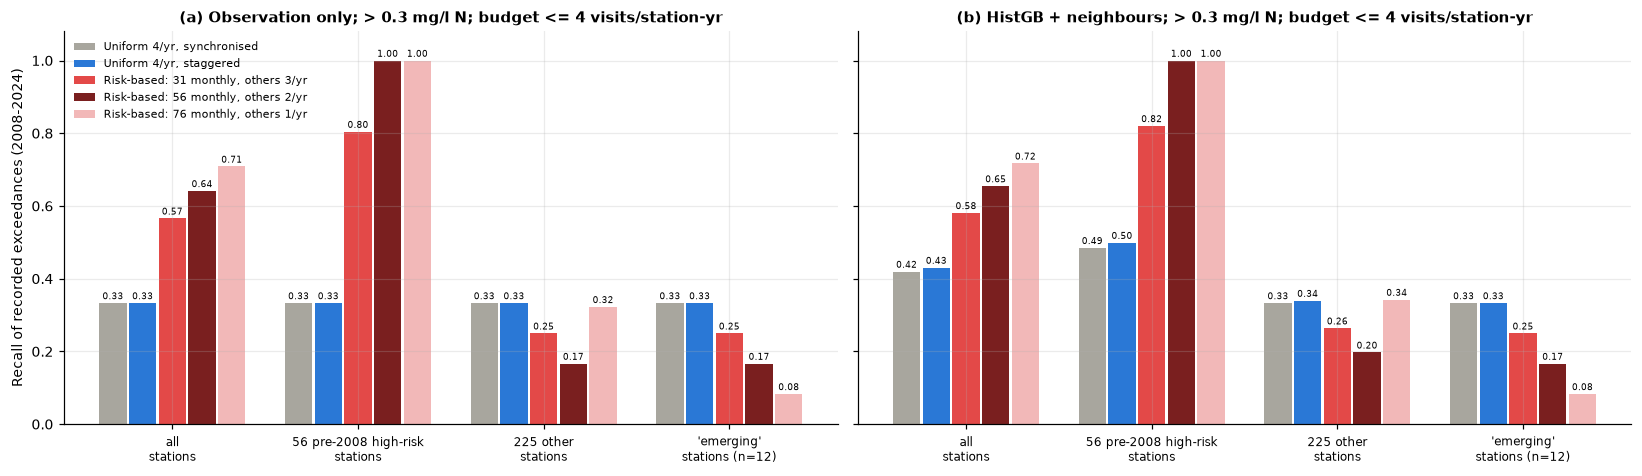

In [43]:
# ==== CELL 2 ==== Experiment 6b - performance by station group (defined from pre-2008 information only)
# high-risk = the N_HI[2] stations with the highest pre-2008 Beta-Binomial rate (the stations kept monthly in the 56-station risk-based design);
# 'emerging' = no recorded exceedance > PRIMARY in 1995-2007 but >= 1 in the 2008-2024 evaluation months. Groups are fixed for both thresholds.
nhi = N_HI[2]; HI = np.zeros(S, bool); HI[RANKS[PRIMARY_RANK]["order"][:nhi]] = True
k_pre, _ = exc_counts(1995, 2007, PRIMARY); ev_cnt = np.array([exceed(V[i, EVAL[i]], CEN[i, EVAL[i]], PRIMARY).sum() for i in range(S)])
EMERG6 = (k_pre == 0) & (ev_cnt > 0)
GRP = {"all stations": np.ones(S, bool), f"{nhi} pre-2008 high-risk stations": HI, f"{S - nhi} other stations": ~HI, f"'emerging' stations (n={EMERG6.sum()})": EMERG6}
print({g: f"{m.sum()} stations, {ev_cnt[m].sum()} recorded exceedances > {PRIMARY} mg/l in 2008-2024" for g, m in GRP.items()})
# (A) Experiment 1 (one-at-a-time) by group, every strategy
rows, bb = [], []
for f in CFG["sched"]:
    for thr in (0.2, PRIMARY):
        set_thr(thr); IT, RET = pooled(ITEMS, f); yb = labels(IT, thr); TE = {s_: tp_ev(IT, RET, thr, alarms(IT, f, thr, s_)) for s_ in ["Observation-only"] + ALLS}
        for g, m in GRP.items():
            sk = m[IT.s.values]
            for s_ in ["Observation-only"] + ALLS:
                tp, ev = TE[s_]
                rows.append({"visits/yr": f, "threshold": thr, "group": g, "strategy": s_, "recorded exceedances": ev[m].sum() / len(CFG["sched"][f]), "recall": tp[m].sum() / ev[m].sum(),
                             "PR-AUC (skipped months)": average_precision_score(yb[sk], score_of(IT[sk], s_)) if s_ != "Observation-only" and yb[sk].sum() >= 20 else np.nan})
            for a_, b_ in (("HistGB_nb", "Persistence"), ("HistGB_nb", "Clim_freq_station"), ("HistGB_nb", "Observation-only")):
                e, lo, hi = boot_ratio_diff(*TE[a_], *TE[b_], units=np.flatnonzero(m))
                bb.append({"experiment": "Exp 1 (one-at-a-time)", "visits/yr": f, "threshold": thr, "group": g, "comparison": f"{a_} - {b_}", "d recall": e, "95% CI low": lo, "95% CI high": hi})
GR1 = pd.DataFrame(rows); save_table(GR1, "T24_station_groups_one_at_a_time")
display(GR1[(GR1.threshold == PRIMARY) & (GR1["visits/yr"] == 4)].pivot(index="strategy", columns="group", values="recall").round(3))
# (B) Experiment 5 designs by group: the trade-off table (network-wide recall next to recall at the stations whose sampling was reduced)
rows = []; DN = [n for n, _, _ in DESIGNS]
for thr in (0.2, PRIMARY):
    for name in DN:
        EVs, RETs, rev = FAIR_EV[(name, thr)]
        for det in ("Observation only",) + tuple(lab for _, lab in DET):
            tp, ev = st_counts(name, thr, det)
            # share of emerging stations with >= 1 detected exceedance, per schedule rotation, averaged
            v_ = EVs.v.values; vr = RETs.v.values; yb = exceed(np.exp(EVs.y.values), EVs.cens_target.values, thr); det_any = []
            for v in np.unique(v_):
                hit = np.bincount(RETs.s.values[vr == v], rev[vr == v].astype(float), S)
                if det != "Observation only":
                    s_ = {lab: k for k, lab in DET}[det]; hit = hit + np.bincount(EVs.s.values[v_ == v], (EVs[f"alarm_{s_}"].values & yb)[v_ == v].astype(float), S)
                det_any.append((hit[EMERG6] > 0).mean())
            r_ = {"design": name, "threshold": thr, "detection": det}
            for g, m in GRP.items(): r_[f"recall, {g}"] = tp[m].sum() / ev[m].sum()
            r_[f"'emerging' stations detected at least once"] = np.mean(det_any); rows.append(r_)
        if name == "Uniform 4/yr, staggered": continue
        for det in ("Observation only", "HistGB + neighbours"):
            ta, ea = st_counts(name, thr, det); tb, eb = st_counts("Uniform 4/yr, staggered", thr, det)
            for g, m in GRP.items():
                e, lo, hi = boot_ratio_diff(ta, ea, tb, eb, units=np.flatnonzero(m))
                bb.append({"experiment": "Exp 5 (allocation)", "visits/yr": 4, "threshold": thr, "group": g, "comparison": f"{name} [{det}] - Uniform 4/yr, staggered [{det}]",
                           "d recall": e, "95% CI low": lo, "95% CI high": hi})
GR5 = pd.DataFrame(rows); save_table(GR5, "T24b_station_groups_allocation"); GRB = pd.DataFrame(bb); save_table(GRB, "T24c_station_groups_bootstrap")
display(GR5[GR5.threshold == PRIMARY].set_index(["design", "detection"]).drop(columns="threshold").round(3))
display(GRB[(GRB.threshold == PRIMARY) & (GRB.experiment == "Exp 5 (allocation)")].round(3))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
gl = list(GRP); xx = np.arange(len(gl)); dcols = ["#a8a69e", "#2a78d6", "#e34948", "#7a1f1f", "#f2b8b8"]
for a_, det in zip(ax, ("Observation only", "HistGB + neighbours")):
    x = GR5[(GR5.threshold == PRIMARY) & (GR5.detection == det)].set_index("design"); w = .8 / len(DN)
    for k, (n, cc) in enumerate(zip(DN, dcols)):
        b = a_.bar(xx + (k - (len(DN) - 1) / 2) * w, [x.loc[n, f"recall, {g}"] for g in gl], w * .92, color=cc, label=n); a_.bar_label(b, fmt="%.2f", fontsize=6, padding=1)
    a_.set_xticks(xx); a_.set_xticklabels([g.replace(" stations", "\nstations") for g in gl], fontsize=8); a_.set_ylim(0, 1.08)
    a_.set_title(f"({'ab'[det != 'Observation only']}) {det}; > {PRIMARY} mg/l N; budget <= 4 visits/station-yr")
ax[0].set_ylabel("Recall of recorded exceedances (2008-2024)"); ax[0].legend(fontsize=7, loc="upper left")
fig.tight_layout(); savefig(fig, "F20_station_group_tradeoffs"); plt.show()

period,2008-2015,2016-2024
strategy,,
Clim_conc,0.465,0.403
Clim_freq_network,0.333,0.333
Clim_freq_station,0.467,0.4
HistGB_nb,0.488,0.429
HistGB_own,0.465,0.384
Neighbour_ratio,0.385,0.398
Observation-only,0.333,0.333
Persistence,0.389,0.383
"Risk-based: 31 monthly, others 3/yr [HistGB + neighbours]",0.636,0.533


,experiment,visits/yr,period,metric,comparison,difference,95% CI low,95% CI high
16,Exp 1 (one-at-a-time),4,2008-2015,PR-AUC,HistGB_nb - Persistence,0.117,0.051,0.16
17,Exp 1 (one-at-a-time),4,2008-2015,recall (FA-budget),HistGB_nb - Persistence,0.099,0.028,0.162
18,Exp 1 (one-at-a-time),4,2008-2015,PR-AUC,HistGB_nb - Clim_freq_station,0.067,0.022,0.092
19,Exp 1 (one-at-a-time),4,2008-2015,recall (FA-budget),HistGB_nb - Clim_freq_station,0.021,-0.015,0.051
20,Exp 1 (one-at-a-time),4,2016-2024,PR-AUC,HistGB_nb - Persistence,0.105,0.063,0.152
21,Exp 1 (one-at-a-time),4,2016-2024,recall (FA-budget),HistGB_nb - Persistence,0.046,0.012,0.08
22,Exp 1 (one-at-a-time),4,2016-2024,PR-AUC,HistGB_nb - Clim_freq_station,0.084,0.041,0.111
23,Exp 1 (one-at-a-time),4,2016-2024,recall (FA-budget),HistGB_nb - Clim_freq_station,0.029,-0.002,0.061
24,Exp 5 (allocation),4,2008-2015,recall (FA-budget),"Risk-based: 31 monthly, others 3/yr [Observati...",0.29,0.162,0.393
25,Exp 5 (allocation),4,2008-2015,recall (FA-budget),"Risk-based: 31 monthly, others 3/yr [HistGB + ...",0.167,0.102,0.228


strategy,Clim_freq_station,HistGB_nb,Observation-only,Persistence
block,,,,
2008-2010,0.159,0.247,NaN,0.111
2011-2013,0.164,0.194,NaN,0.096
2014-2016,0.105,0.189,NaN,0.068
2017-2019,0.113,0.247,NaN,0.108
2020-2022,0.106,0.12,NaN,0.064
2023-2024,0.146,0.183,NaN,0.08


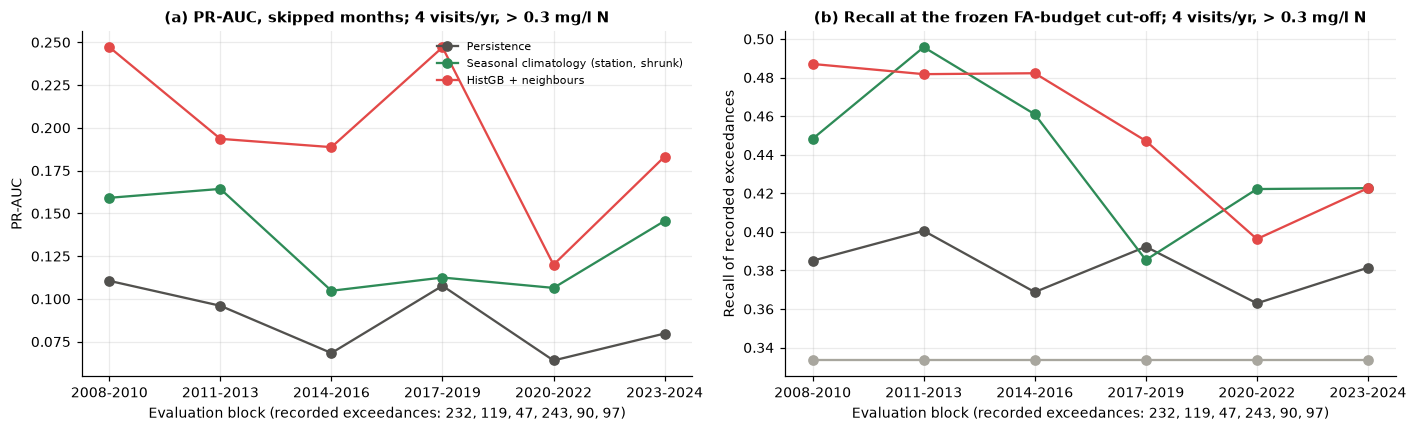

In [44]:
# ==== CELL 3 ==== Experiment 6c - temporal stability: 2008-2015 versus 2016-2024 and by 3-year block (frozen models' cut-offs; nothing re-selected)
PERIODS = {"2008-2015": (2008, 2015), "2016-2024": (2016, 2024)}
rows, bb = [], []
set_thr(PRIMARY)
for f in CFG["sched"]:
    IT, RET = pooled(ITEMS, f); ry = yr[RET.t.values]
    for pname, (a0, a1) in PERIODS.items():
        mi, mr = IT.year.between(a0, a1).values, (ry >= a0) & (ry <= a1); ITp, RETp = IT[mi], RET[mr]; yb = labels(ITp, PRIMARY)
        TE = {s_: tp_ev(ITp, RETp, PRIMARY, alarms(ITp, f, PRIMARY, s_)) for s_ in ["Observation-only"] + ALLS}
        for s_ in ["Observation-only"] + ALLS:
            rows.append({"experiment": "Exp 1 (one-at-a-time)", "visits/yr": f, "period": pname, "strategy": s_, "recorded exceedances": TE[s_][1].sum() / len(CFG["sched"][f]),
                         "recall": TE[s_][0].sum() / TE[s_][1].sum(), "PR-AUC (skipped months)": np.nan if s_ == "Observation-only" else average_precision_score(yb, score_of(ITp, s_))})
        for a_, b_ in (("HistGB_nb", "Persistence"), ("HistGB_nb", "Clim_freq_station")):
            e, lo, hi = boot_ap(ITp, a_, b_, PRIMARY, "station")
            bb.append({"experiment": "Exp 1 (one-at-a-time)", "visits/yr": f, "period": pname, "metric": "PR-AUC", "comparison": f"{a_} - {b_}", "difference": e, "95% CI low": lo, "95% CI high": hi})
            e, lo, hi = boot_ratio_diff(*TE[a_], *TE[b_])
            bb.append({"experiment": "Exp 1 (one-at-a-time)", "visits/yr": f, "period": pname, "metric": "recall (FA-budget)", "comparison": f"{a_} - {b_}", "difference": e, "95% CI low": lo, "95% CI high": hi})
for pname, (a0, a1) in PERIODS.items():
    ce = {}
    for name in DN:
        EVs, RETs, rev = FAIR_EV[(name, PRIMARY)]; me = EVs.year.between(a0, a1).values; ry = yr[RETs.t.values]; mr = (ry >= a0) & (ry <= a1)
        yb = exceed(np.exp(EVs.y.values), EVs.cens_target.values, PRIMARY)
        for det in ("Observation only",) + tuple(lab for _, lab in DET):
            key_ = {lab: k for k, lab in DET}.get(det)
            al = np.zeros(len(EVs), bool) if det == "Observation only" else EVs[f"alarm_{key_}"].values
            tp = np.bincount(RETs.s.values[mr], rev[mr].astype(float), S) + np.bincount(EVs.s.values[me], (al & yb)[me].astype(float), S)
            ev = np.bincount(RETs.s.values[mr], rev[mr].astype(float), S) + np.bincount(EVs.s.values[me], yb[me].astype(float), S)
            ce[(name, det)] = (tp, ev)
            rows.append({"experiment": "Exp 5 (allocation)", "visits/yr": 4, "period": pname, "strategy": f"{name} [{det}]", "recorded exceedances": ev.sum() / EVs.v.nunique(), "recall": tp.sum() / ev.sum()})
    for name in DN[2:]:
        for det in ("Observation only", "HistGB + neighbours"):
            e, lo, hi = boot_ratio_diff(*ce[(name, det)], *ce[("Uniform 4/yr, staggered", det)])
            bb.append({"experiment": "Exp 5 (allocation)", "visits/yr": 4, "period": pname, "metric": "recall (FA-budget)", "comparison": f"{name} [{det}] - Uniform 4/yr, staggered [{det}]",
                       "difference": e, "95% CI low": lo, "95% CI high": hi})
TEMP = pd.DataFrame(rows); save_table(TEMP, "T25_temporal_stability"); TEMPB = pd.DataFrame(bb); save_table(TEMPB, "T25b_temporal_stability_bootstrap")
display(TEMP[(TEMP["visits/yr"] == 4)].pivot(index="strategy", columns="period", values="recall").round(3)); display(TEMPB[TEMPB["visits/yr"] == 4].round(3))
# per 3-year block (Experiment 1, 4 visits/yr): PR-AUC and recall by block, with the number of recorded exceedances
set_thr(PRIMARY); IT, RET = pooled(ITEMS, 4); blk_it = IT.year.map(block_of).values; blk_rt = np.array([block_of(y) for y in yr[RET.t.values]]); rows = []
for B in CFG["blocks"]:
    ITb, RETb = IT[blk_it == B], RET[blk_rt == B]; yb = labels(ITb, PRIMARY)
    for s_ in ["Observation-only", "Persistence", "Clim_freq_station", "HistGB_nb"]:
        tp, ev = tp_ev(ITb, RETb, PRIMARY, alarms(ITb, 4, PRIMARY, s_))
        rows.append({"block": f"{B}-{min(B + 2, CFG['eval'][1])}", "strategy": s_, "recorded exceedances": ev.sum() / 3, "recall": tp.sum() / ev.sum(),
                     "PR-AUC (skipped months)": np.nan if s_ == "Observation-only" else average_precision_score(yb, score_of(ITb, s_))})
BLK = pd.DataFrame(rows); save_table(BLK, "T25c_by_block_4visits"); display(BLK.pivot(index="block", columns="strategy", values="PR-AUC (skipped months)").round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s_ in ["Observation-only", "Persistence", "Clim_freq_station", "HistGB_nb"]:
    x = BLK[BLK.strategy == s_]
    if s_ != "Observation-only": ax[0].plot(x.block, x["PR-AUC (skipped months)"], "o-", color=COL[s_], label=LAB[s_])
    ax[1].plot(x.block, x.recall, "o-", color=COL[s_], label=LAB[s_])
nev = BLK[BLK.strategy == "HistGB_nb"]["recorded exceedances"].values
for a_, t_ in zip(ax, ("(a) PR-AUC, skipped months", "(b) Recall at the frozen FA-budget cut-off")):
    a_.set_title(f"{t_}; 4 visits/yr, > {PRIMARY} mg/l N"); a_.set_xlabel("Evaluation block (recorded exceedances: " + ", ".join(f"{int(n)}" for n in nev) + ")")
ax[0].set_ylabel("PR-AUC"); ax[1].set_ylabel("Recall of recorded exceedances"); ax[0].legend(fontsize=7)
fig.tight_layout(); savefig(fig, "F21_temporal_stability"); plt.show()

In [45]:
# ==== CELL 4 ==== Experiment 6d - automated consistency and leakage checks, and a record of the common evaluation configuration
AUD = []
def chk(name, ok, detail=""): AUD.append({"check": name, "result": "PASS" if bool(ok) else "FAIL", "detail": detail})
rng6 = np.random.RandomState(SEED); tidx = np.arange(T); first_eval_t = int(np.flatnonzero(yr == CFG["eval"][0])[0])
# (1) brute-force recomputation of both frequency climatologies from the raw monthly arrays (only months <= t0 actually sampled)
for D, start, lab in ((ITEMS, CFG["eval"][0], "evaluation"), (DEV_ITEMS, CFG["dev"][0], "development")):
    worst, viol, n_chk, n_less = 0.0, 0, 0, 0
    for (f, ph), (IT, _) in D.items():
        AV = availability(CFG["sched"][f][ph], start); st_, ne_ = FREQ[(id(D), f, ph, PRIMARY)]
        for k in rng6.choice(len(IT), min(60, len(IT)), replace=False):
            s, t, t0 = int(IT.s.values[k]), int(IT.t.values[k]), int(IT.t0.values[k]); same = mon == mon[t]
            if AV[s, t] or not (t0 < t): viol += 1                                         # target month must be hidden, origin before it
            own = AV[s] & (tidx <= t0) & same; kk = exceed(V[s, own], CEN[s, own], PRIMARY).sum(); nn = own.sum()
            oth = OBSD.copy(); oth[s] = AV[s]; msk = oth & (tidx <= t0)[None, :] & same[None, :]
            kn = sum(int(exceed(V[i, msk[i]], CEN[i, msk[i]], PRIMARY).sum()) for i in range(S)); nn_ = int(msk.sum())
            pn = (kn + .5) / (nn_ + 1); ps = (kk + M_PRIOR[PRIMARY] * pn) / (nn + M_PRIOR[PRIMARY])
            worst = max(worst, abs(ps - st_[k]), abs(pn - ne_[k])); n_chk += 1
            n_less += int(nn < (OBSD[s] & (tidx <= t0) & same).sum())                       # skipped months really left out of n
    chk(f"frequency climatologies = brute-force recomputation from visits <= t0 ({lab}, {n_chk} random skipped months)", worst < 1e-12 and viol == 0,
        f"max |difference| = {worst:.2e}; hidden-target/origin violations = {viol}")
    if lab == "evaluation":
        chk("reduced schedule respected: denominators smaller than if skipped months had been observed", n_less > 0,
            f"{n_less} of {n_chk} checked months have fewer same-month visits than the full record")
# (2) prior strength uses only 1995-2004: refit with every value from 2005 onwards deleted
_save = (OBSD, EXC_D)
try:
    cut05 = (yr < CFG["dev"][0])[None, :]; OBSD = _save[0] & cut05; EXC_D = {k: v & cut05 for k, v in _save[1].items()}
    M_chk = {thr: fit_prior_strength(thr, 1995, CFG["eval"][1]) for thr in THRS}
finally: OBSD, EXC_D = _save
chk("Beta-Binomial prior strength identical when all data from 2005 onwards are deleted", all(abs(M_chk[t_] - M_PRIOR[t_]) < 1e-9 * M_PRIOR[t_] for t_ in THRS),
    "; ".join(f"{t_}: {M_PRIOR[t_]:.4f} vs {M_chk[t_]:.4f}" for t_ in THRS))
# (3) development and evaluation sets are disjoint; development information ends before 2008
dmax_t = max(int(IT.t.max()) for IT, _ in DEV_ITEMS.values()); dmax_t0 = max(int(IT.t0.max()) for IT, _ in DEV_ITEMS.values())
emin_t = min(int(IT.t.min()) for IT, _ in ITEMS.values())
ov = sum(len(set(zip(ITEMS[k][0].s, ITEMS[k][0].t)) & set(zip(DEV_ITEMS[k][0].s, DEV_ITEMS[k][0].t))) for k in ITEMS)
chk("development items (2005-2007) and evaluation items (2008-2024) disjoint", ov == 0 and dmax_t < first_eval_t <= emin_t,
    f"overlapping station-months = {ov}; last development target month index {dmax_t}, first evaluation {emin_t}")
chk("development scores use information up to 2007 only (origin months)", dmax_t0 < first_eval_t, f"last development origin index {dmax_t0}")
chk("station-risk baseline: development ranking 1995-2004, evaluation ranking 1995-2007", DEV_RANK[1:] == (1995, 2004) and PRIMARY_RANK[1:] == (1995, 2007), f"{DEV_RANK}, {PRIMARY_RANK}")
# (4) cut-offs: existing methods unchanged; baselines re-derived from development items only
chk("cut-offs of Persistence / neighbour-ratio / HistGB identical to Experiment 1", all(CUT6[(f, thr, s_)] == CUTS[(f, thr)][(s_, "FA-budget")] for f in CFG["sched"] for thr in THRS for s_ in STRATS))
rec = {}
for thr in THRS:
    set_thr(thr)
    for f in CFG["sched"]:
        DV, _ = pooled(DEV_ITEMS, f); ydv = labels(DV, thr)
        for s_ in BASES:
            c = CUT6[(f, thr, s_)]; fa_ = ((score_of(DV, s_) > c) & ~ydv).sum() / len(CFG["sched"][f]) / n_sy_dev; rec[(f, thr, s_)] = fa_
chk("baseline cut-offs satisfy the false-alarm budget on 2005-2007 (or are the strictest candidate)", all(v <= CFG["fa_budget"] + 1e-12 or CUT6[k] >= max(score_of(pooled(DEV_ITEMS, k[0])[0], k[2])) for k, v in rec.items()),
    f"max development false alarms/station-yr = {max(rec.values()):.4f}")
# (5) identical evaluation sample and exceedance definition for every method; existing predictions untouched
okrows, oklab, okpred = True, True, True
for thr in THRS:
    set_thr(thr)
    for f in CFG["sched"]:
        IT, _ = pooled(ITEMS, f); yb = labels(IT, thr)
        okrows &= all(np.isfinite(score_of(IT, s_)).all() for s_ in ALLS)
        okrows &= all(((IT[s_] > 0) & (IT[s_] < 1)).all() for s_ in ("Clim_freq_station", "Clim_freq_network"))
        m0 = MAIN[(MAIN["visits/yr"] == f) & (MAIN.threshold == thr)].set_index("strategy")
        oklab &= int(yb.sum() / len(CFG["sched"][f])) == int(m0.loc["HistGB_nb", "skipped exceedances"])
        okpred &= all(abs(average_precision_score(yb, IT[s_]) - m0.loc[s_, "PR-AUC"]) < 1e-12 for s_ in STRATS)
chk("all scores finite on every skipped month; probabilities strictly inside (0, 1)", okrows)
chk("same skipped months and same exceedance labels as Experiment 1 (T04)", oklab)
chk("PR-AUC of Persistence / neighbour-ratio / HistGB unchanged (identical to T04)", okpred)
chk("scored months are inside the evaluation mask (complete station-years, sampled months)", all(EVAL[IT.s.values, IT.t.values].all() and EVAL[R.s.values, R.t.values].all() for IT, R in ITEMS.values()))
dup = int(d[d.StationCode.isin(sel)].duplicated(["StationCode", "ym"]).sum())
chk("one value per station-month (documented first-visit rule)", np.isfinite(V[~np.isnan(V)]).all(), f"{dup} additional same-month records in the cohort resolved by the first-visit rule")
nb_disc = pd.DataFrame(BOOT_LOG); chk("bootstrap replicates that could not be scored are counted", True,
                                      f"{int(nb_disc.discarded.sum())} of {int(nb_disc.replicates.sum())} replicates discarded over {len(nb_disc)} bootstrap calls (max {int(nb_disc.discarded.max())} in one call)")
AUDT = pd.DataFrame(AUD); save_table(AUDT, "T26_audit_checks"); save_table(nb_disc, "T26b_bootstrap_discarded_replicates"); display(AUDT)
print("ALL CHECKS PASSED" if (AUDT.result == "PASS").all() else f"FAILED CHECKS: {AUDT[AUDT.result == 'FAIL'].check.tolist()}")
# common evaluation configuration (read from the objects actually used above)
EVAL_CFG = {"dataset": "DAERA River Water Quality Monitoring 1990-2024, Ammonia (NH4-N); columns StationCode, sample date, NH4-N value, qualifier Q_NH4N",
            "monthly value": "first visit of the month (one value per station-month)", "censoring": "'<' values kept at the LOD; a censored value is a non-exceedance (exceed(): censored and value >= threshold -> False)",
            "exceedance": "value > threshold (mg N/L); primary threshold 0.3; also 0.2, 0.4, 0.6", "cohort": f"{S} river stations: >= {CFG['min_complete_years']} of 13 monthly-complete years (>= {CFG['complete_months']} months) in 1995-2007 and {CFG['dev_complete_years']}/3 in 2005-2007",
            "schedules (kept calendar months by phase)": {str(k): v for k, v in CFG["sched"].items()}, "development period": CFG["dev"], "evaluation period": CFG["eval"],
            "scored months": "months of monthly-complete station-years that were sampled in the record; skipped = not in the reduced schedule; visited = in the schedule",
            "training blocks": CFG["blocks"], "spatial clusters": CFG["n_groups"], "hyper-parameters (HistGB)": {k: HGB_GRID[v] for k, v in CHOSEN.items()},
            "cut-off rule": f"lowest cut-off with <= {CFG['fa_budget']} false alarms per station-year on 2005-2007, per method, schedule and threshold; frozen",
            "PR-AUC": "sklearn.metrics.average_precision_score on skipped months", "bootstrap": f"{CFG['n_boot']} replicates, seed {SEED}; station, year and two-way (station x year weights) clusters; percentile 95% intervals",
            "Beta-Binomial prior strength M (seasonal climatology)": M_PRIOR, "random seed": SEED, "fast mode": FAST}
json.dump(EVAL_CFG, open(os.path.join(OUT, "evaluation_config.json"), "w"), indent=1, default=str); print("evaluation configuration written to evaluation_config.json")

,check,result,detail
0,frequency climatologies = brute-force recomput...,PASS,max |difference| = 0.00e+00; hidden-target/ori...
1,reduced schedule respected: denominators small...,PASS,423 of 480 checked months have fewer same-mont...
2,frequency climatologies = brute-force recomput...,PASS,max |difference| = 0.00e+00; hidden-target/ori...
3,Beta-Binomial prior strength identical when al...,PASS,0.2: 3.5083 vs 3.5083; 0.3: 6.7442 vs 6.7442; ...
4,development items (2005-2007) and evaluation i...,PASS,overlapping station-months = 0; last developme...
5,development scores use information up to 2007 ...,PASS,last development origin index 214
6,station-risk baseline: development ranking 199...,PASS,"('eb', 1995, 2004), ('eb', 1995, 2007)"
7,cut-offs of Persistence / neighbour-ratio / Hi...,PASS,
8,baseline cut-offs satisfy the false-alarm budg...,PASS,max development false alarms/station-yr = 0.0996
9,all scores finite on every skipped month; prob...,PASS,


ALL CHECKS PASSED
evaluation configuration written to evaluation_config.json


> **Interpretation — Experiment 6 (simple baselines, station groups and temporal stability).**
> * **Baselines (Table T23, manuscript Table 4).** At 4 visits per year, AP of HistGB + neighbours (0.204) exceeds the station-specific seasonal climatology (0.127; +0.077, CI 0.043–0.098 by station, 0.022–0.120 two-way) and static station risk (0.155; +0.050). At the operating cut-off, however, recall rises only from 43.2% to 45.7% over the climatology (+2.5 points, station CI −0.1 to 5.1). HistGB with own history alone shows no clear AP advantage over the climatology (+0.022, two-way CI −0.029 to 0.046) and is below static station risk (0.149 vs 0.155). The climatology over-predicts exceedance probabilities by about a factor of two (Table T23c).
> * **Station groups (Table T24b).** Under uniform staggered sampling, HistGB + neighbours detects 49.9% of the exceedances at the 56 high-risk stations but only 34.0% at the other 225 stations; with 56 monthly stations recall is 100% and 19.8%, respectively (−14.2 points at the other stations, CI −15.8 to −12.5). No inference method recovers skipped exceedances at the 12 emerging stations.
> * **Temporal stability (Tables T25, T25b).** HistGB + neighbours has the highest AP and recall at 4 visits per year in both 2008–2015 (AP 0.219, recall 48.8%) and 2016–2024 (0.192, 42.9%), and the allocation gain holds in both sub-periods (1,377 and 1,411 station-years; +24.6 and +20.5 points).

<a id="14c"></a>
## 14c. Experiment 7 — Extension (pre-declared): rolling cut-off recalibration and alarm-triggered follow-up sampling

The analysis plan was written before any result of this section was computed (`EXPERIMENT7_PLAN.md`); the results of Sections 9–14b remain the primary results.

* **7a — rolling recalibration (one-at-a-time design).** For each 3-year block and spatial cluster, the FA-budget cut-off (≤ 0.1 false alarms per station-year) is re-selected on the skipped-month predictions of the other clusters in the three preceding years, whose stations keep monthly sampling under this design; 2008–2010 keeps the frozen 2005–2007 cut-off. Predictions are unchanged. Not applicable to network-wide or allocation designs (no station remains monthly in the uniform design).
* **7b — alarm-triggered follow-up.** A HistGB + neighbours alarm (or an observed exceedance) in month t triggers one extra visit in month t+1 at the same station, unless t+1 is already scheduled. The yield of these extra visits is compared with the same number of randomly placed extra visits (budget-matched control) under the uniform staggered and the 56-station risk-based design.

network-level recall  skipped-month recall  predictive precision  false alarms/station-yr  median cut-off
strategy          cut-off rule                                                                                                                           
Persistence       frozen 2005-2007                             0.386                 0.079                 0.165                    0.079           0.471
                  rolling 3-year recalibration                 0.408                 0.112                 0.165                    0.113           0.387
Neighbour_ratio   frozen 2005-2007                             0.392                 0.088                 0.239                    0.055           0.821
                  rolling 3-year recalibration                 0.435                 0.152                 0.228                    0.102           0.567
HistGB_own        frozen 2005-2007                             0.422                 0.133                 0.318                    0.057           0.239
                  rolling 3-year recalibration                 0.464                 0.196                 0.265                    0.107           0.211
HistGB_nb         frozen 2005-2007                             0.457                 0.185                 0.379                     0.06           0.239
                  rolling 3-year recalibration                 0.503                 0.254                 0.316                    0.109           0.216
Clim_freq_station frozen 2005-2007                             0.432                 0.147                 0.302                    0.067           0.304
                  rolling 3-year recalibration                 0.449                 0.174                 0.257                    0.099           0.294

,visits/yr,threshold,strategy,metric,cluster,difference,95% CI low,95% CI high
112,4,0.3,HistGB_nb,"network-level recall, rolling - frozen",station,0.0459,0.0302,0.0606
113,4,0.3,HistGB_nb,"false alarms/station-yr, rolling - frozen",station,0.0491,0.0319,0.0715
114,4,0.3,HistGB_nb,"network-level recall, rolling - frozen",year,0.0459,0.0216,0.07
115,4,0.3,HistGB_nb,"false alarms/station-yr, rolling - frozen",year,0.0491,0.0277,0.0721


,cut-off rule,block,false alarms/station-yr,skipped-month recall
0,frozen 2005-2007,2008-2010,0.053,0.231
1,frozen 2005-2007,2011-2013,0.088,0.223
2,frozen 2005-2007,2014-2016,0.043,0.223
3,frozen 2005-2007,2017-2019,0.066,0.171
4,frozen 2005-2007,2020-2022,0.045,0.094
5,frozen 2005-2007,2023-2024,0.057,0.134
6,rolling 3-year recalibration,2008-2010,0.053,0.231
7,rolling 3-year recalibration,2011-2013,0.168,0.311
8,rolling 3-year recalibration,2014-2016,0.06,0.234
9,rolling 3-year recalibration,2017-2019,0.174,0.315


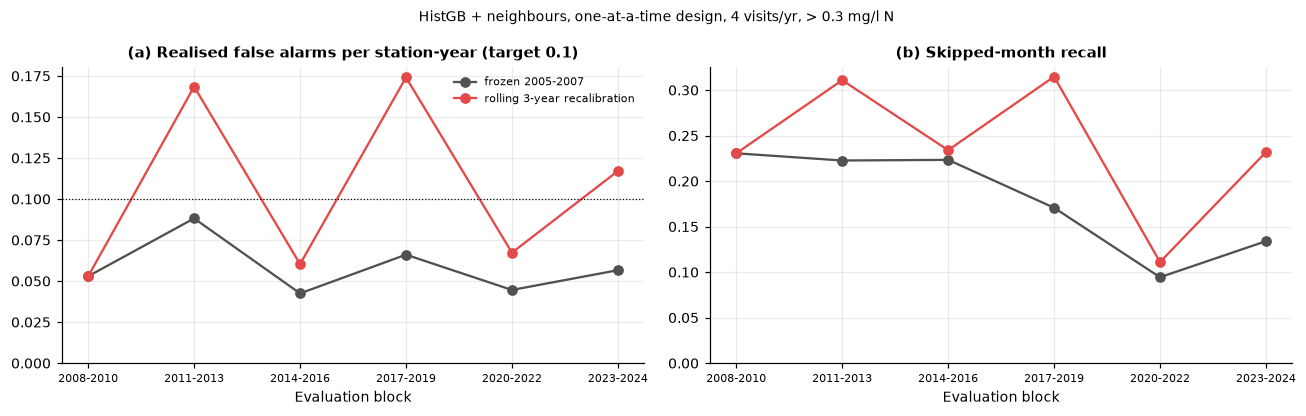

In [46]:
# ==== CELL 1 ==== Experiment 7a - rolling recalibration of alarm cut-offs (one-at-a-time design; pre-declared in EXPERIMENT7_PLAN.md)
# For block B and spatial cluster g the FA-budget cut-off is re-selected on the skipped-month predictions of the OTHER clusters in B-3..B-1
# (under the one-at-a-time design those stations keep monthly sampling, so their outcomes are known); B = 2008 keeps the frozen 2005-2007 cut-off.
# Model predictions are unchanged; only the cut-off changes.
M7 = ["Persistence", "Neighbour_ratio", "HistGB_own", "HistGB_nb", "Clim_freq_station"]
def cands7(s_, sc): return GRID if s_ not in PROB else np.unique(np.quantile(sc, np.linspace(0, 1, 401)))
def roll_cuts(f, thr, s_):
    set_thr(thr); IT, _ = pooled(ITEMS, f); nph = len(CFG["sched"][f]); yb = labels(IT, thr); sc = score_of(IT, s_); cuts = {}
    for B in CFG["blocks"]:
        for g in range(CFG["n_groups"]):
            if B == CFG["eval"][0]: cuts[(B, g)] = CUT6[(f, thr, s_)]; continue
            m = IT.year.between(B - 3, B - 1).values & (IT.group.values != g)
            assert IT.year.values[m].max() < B                                              # calibration strictly before the block
            nsy = int(okSY[groups != g][:, B - 3 - 1990:B - 1990].sum())
            c_ = cands7(s_, sc[m]); fa = np.array([((sc[m] > c) & ~yb[m]).sum() / nph / nsy for c in c_]); ok = np.flatnonzero(fa <= CFG["fa_budget"])
            cuts[(B, g)] = float(c_[ok[0]]) if len(ok) else float(c_[-1])
    return cuts
def roll_alarm(IT, s_, cuts):
    key = list(zip(IT.year.map(block_of).values, IT.group.values)); return score_of(IT, s_) > np.array([cuts[k] for k in key])
NSY_ST = okSY[:, CFG["eval"][0] - 1990:CFG["eval"][1] - 1989].sum(1).astype(float)          # evaluation station-years per station
NSY_YR = okSY[:, CFG["eval"][0] - 1990:CFG["eval"][1] - 1989].sum(0).astype(float)          # ... per year
def fp_units(IT, a, yb, cluster):
    ke = IT.s.values if cluster == "station" else IT.year.values - CFG["eval"][0]; K = S if cluster == "station" else NYR
    return np.bincount(ke, (a & ~yb).astype(float), K)
def boot_fa_diff(fa_a, fa_b, nsy, nph, B=None, seed=SEED):
    B = CFG["n_boot"] if B is None else B; K = len(nsy); dd = np.random.RandomState(seed).randint(0, K, (B, K))
    d_ = (fa_a[dd].sum(1) - fa_b[dd].sum(1)) / nph / nsy[dd].sum(1)
    return (fa_a.sum() - fa_b.sum()) / nph / nsy.sum(), np.percentile(d_, 2.5), np.percentile(d_, 97.5)
rows, bb, CUT7 = [], [], {}
for thr in (0.2, PRIMARY):
    for f in CFG["sched"]:
        set_thr(thr); IT, RET = pooled(ITEMS, f); nph = len(CFG["sched"][f]); yb = labels(IT, thr)
        for s_ in M7:
            cuts = roll_cuts(f, thr, s_); CUT7[(f, thr, s_)] = cuts; set_thr(thr)
            for lab, a in (("frozen 2005-2007", alarms(IT, f, thr, s_)), ("rolling 3-year recalibration", roll_alarm(IT, s_, cuts))):
                tp, ev = tp_ev(IT, RET, thr, a); fp = int((a & ~yb).sum()); TPs = int((a & yb).sum())
                rows.append({"visits/yr": f, "threshold": thr, "strategy": s_, "cut-off rule": lab, "network-level recall": tp.sum() / ev.sum(),
                             "skipped-month recall": TPs / yb.sum(), "predictive precision": TPs / a.sum() if a.sum() else np.nan,
                             "false alarms/station-yr": fp / nph / n_sy_eval, "median cut-off": float(np.median(list(cuts.values()))) if lab.startswith("rolling") else CUT6[(f, thr, s_)]})
            aF, aR = alarms(IT, f, thr, s_), roll_alarm(IT, s_, cuts)
            for cl in ("station", "year"):
                (ta, ea), (tb, eb_) = tp_ev(IT, RET, thr, aR, cl), tp_ev(IT, RET, thr, aF, cl)
                e, lo, hi = boot_ratio_diff(ta, ea, tb, eb_, tag=f"7a recall {s_} {f} {thr} {cl}")
                bb.append({"visits/yr": f, "threshold": thr, "strategy": s_, "metric": "network-level recall, rolling - frozen", "cluster": cl, "difference": e, "95% CI low": lo, "95% CI high": hi})
                e, lo, hi = boot_fa_diff(fp_units(IT, aR, yb, cl), fp_units(IT, aF, yb, cl), NSY_ST if cl == "station" else NSY_YR, nph)
                bb.append({"visits/yr": f, "threshold": thr, "strategy": s_, "metric": "false alarms/station-yr, rolling - frozen", "cluster": cl, "difference": e, "95% CI low": lo, "95% CI high": hi})
RECAL = pd.DataFrame(rows); save_table(RECAL, "T27_rolling_recalibration"); RECALB = pd.DataFrame(bb); save_table(RECALB, "T27b_rolling_recalibration_bootstrap")
display(RECAL[(RECAL.threshold == PRIMARY) & (RECAL["visits/yr"] == 4)].set_index(["strategy", "cut-off rule"]).drop(columns=["visits/yr", "threshold"]).round(3))
display(RECALB[(RECALB.threshold == PRIMARY) & (RECALB["visits/yr"] == 4) & (RECALB.strategy == "HistGB_nb")].round(4))
# realised false alarms per block (HistGB + nb, 4 visits/yr, primary threshold), frozen vs rolling
set_thr(PRIMARY); IT, RET = pooled(ITEMS, 4); yb = labels(IT, PRIMARY); blk = IT.year.map(block_of).values; rb = []
for lab, a in (("frozen 2005-2007", alarms(IT, 4, PRIMARY, "HistGB_nb")), ("rolling 3-year recalibration", roll_alarm(IT, "HistGB_nb", CUT7[(4, PRIMARY, "HistGB_nb")]))):
    for i_, B in enumerate(CFG["blocks"]):
        end_ = CFG["blocks"][i_ + 1] - 1 if i_ + 1 < len(CFG["blocks"]) else CFG["eval"][1]          # block runs to the next block start
        ys = list(range(B, end_ + 1)); nsy = okSY[:, [y - 1990 for y in ys]].sum()
        m = blk == B; rb.append({"cut-off rule": lab, "block": f"{B}-{ys[-1]}", "false alarms/station-yr": (a[m] & ~yb[m]).sum() / len(CFG["sched"][4]) / nsy,
                                 "skipped-month recall": (a[m] & yb[m]).sum() / max(yb[m].sum(), 1)})
RB = pd.DataFrame(rb); save_table(RB, "T27c_rolling_recalibration_by_block"); display(RB.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for lab, cc in (("frozen 2005-2007", "#52514e"), ("rolling 3-year recalibration", "#e34948")):
    x = RB[RB["cut-off rule"] == lab]; ax[0].plot(x.block, x["false alarms/station-yr"], "o-", color=cc, label=lab); ax[1].plot(x.block, x["skipped-month recall"], "o-", color=cc, label=lab)
ax[0].axhline(CFG["fa_budget"], color="k", ls=":", lw=.8); ax[0].set_ylim(0, None); ax[1].set_ylim(0, None)
ax[0].set_title(f"(a) Realised false alarms per station-year (target {CFG['fa_budget']})"); ax[1].set_title("(b) Skipped-month recall")
for a_ in ax: a_.set_xlabel("Evaluation block"); a_.tick_params(axis="x", labelsize=7)
ax[0].legend(fontsize=7); fig.suptitle(f"HistGB + neighbours, one-at-a-time design, 4 visits/yr, > {PRIMARY} mg/l N", fontsize=9)
fig.tight_layout(); savefig(fig, "F22_rolling_recalibration"); plt.show()

design                                             Uniform 4/yr, staggered                                    Risk-based: 56 monthly, others 2/yr                                   
trigger                                                  HistGB + nb alarm observed exceedance either trigger                   HistGB + nb alarm observed exceedance either trigger
extra visits/station-yr                                              0.043               0.099          0.141                               0.023               0.031          0.054
scorable share of extra visits                                       0.885               0.943          0.926                               0.916               0.648          0.763
new detections per 100 scorable extra visits                         10.48               9.744          9.954                               5.866               6.567          6.205
random control: per 100 visits (mean)                                2.197               2.235          2.208                               1.392               1.358          1.348
random control: 2.5%                                                 0.635               1.407          1.459                               0.279               0.299          0.577
random control: 97.5%                                                 3.81               3.333          3.107                               2.793               2.694          2.168
network-level recall without follow-up                               0.431               0.431          0.431                               0.655               0.655          0.655
recall gain                                                          0.013               0.031          0.044                               0.004               0.004          0.009
recall gain 95% CI low                                               0.006               0.024          0.033                               0.002               0.002          0.005
recall gain 95% CI high                                               0.02               0.037          0.053                               0.008               0.007          0.014
random control: recall gain (mean)                                   0.003               0.007           0.01                               0.001               0.001          0.002
recall gain, all stations                                            0.013               0.031          0.044                               0.004               0.004          0.009
recall gain, 56 pre-2008 high-risk stations                          0.022               0.038           0.06                                   0                   0              0
recall gain, 225 other stations                                      0.002               0.021          0.022                                0.01                0.01           0.02
recall gain, 'emerging' stations (n=12)                                  0                   0              0                                   0                   0              0
random control recall gain, all stations                             0.003               0.007           0.01                               0.001               0.001          0.002
random control recall gain, 56 pre-2008 high-ri...                   0.002               0.006          0.009                                   0                   0              0
random control recall gain, 225 other stations                       0.003               0.008          0.011                               0.002               0.002          0.004
random control recall gain, 'emerging' stations...                   0.003               0.009           0.01                               0.003               0.002          0.005

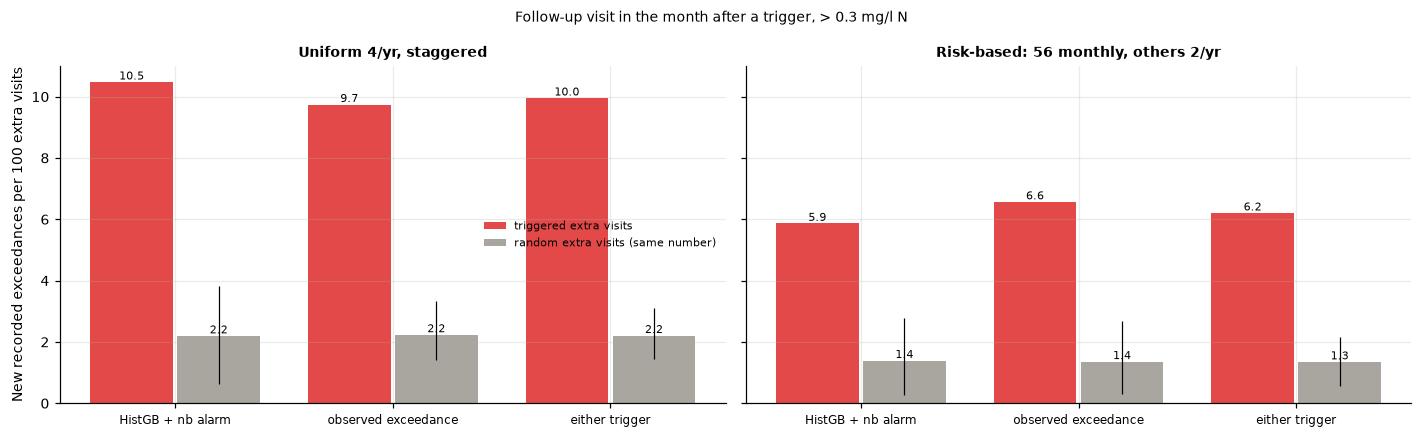

In [47]:
# ==== CELL 2 ==== Experiment 7b - alarm-triggered follow-up sampling (pre-declared in EXPERIMENT7_PLAN.md)
# A trigger for station s in month t (known at the end of month t) adds one visit in month t+1 unless t+1 is already a scheduled visit.
# The extra visit detects a recorded exceedance in t+1 not already detected; it does not feed back into later features (conservative).
# Extra visits to months without a usable record value count as cost without detection. Random control: the same number of scorable
# extra visits placed at random skipped months of the same rotation (200 draws).
N_RAND = 20 if FAST else 200
def followup(name, thr):
    EVs, RETs, rev = FAIR_EV[(name, thr)]; yb = exceed(np.exp(EVs.y.values), EVs.cens_target.values, thr); al = EVs["alarm_HistGB_nb"].values
    rr = np.random.RandomState(SEED); out = {}; ev_st = np.zeros(S); base_st = np.zeros(S); nv = EVs.v.nunique()
    gain = {k: np.zeros(S) for k in ("HistGB + nb alarm", "observed exceedance", "either trigger")}; cost = {k: 0 for k in gain}; scor = {k: 0 for k in gain}
    rnd = {k: [] for k in gain}; rnd_st = {k: np.zeros(S) for k in gain}
    for v in np.unique(EVs.v.values):
        me, mr = EVs.v.values == v, RETs.v.values == v
        ks = EVs.s.values[me] * T + EVs.t.values[me]; kr = RETs.s.values[mr] * T + RETs.t.values[mr]
        y_sk, a_sk, ex_r = yb[me], al[me], rev[mr].astype(bool)
        idx_sk = {k: i for i, k in enumerate(ks)}; vis = set(kr.tolist())
        detected = set(ks[a_sk & y_sk].tolist()) | set(kr[ex_r].tolist())
        ev_st += np.bincount(EVs.s.values[me], y_sk.astype(float), S) + np.bincount(RETs.s.values[mr], ex_r.astype(float), S)
        base_st += np.bincount(EVs.s.values[me], (a_sk & y_sk).astype(float), S) + np.bincount(RETs.s.values[mr], ex_r.astype(float), S)
        trig = {"HistGB + nb alarm": set(ks[a_sk].tolist()), "observed exceedance": set(kr[ex_r].tolist())}; trig["either trigger"] = trig["HistGB + nb alarm"] | trig["observed exceedance"]
        for k, tk in trig.items():
            nxt = {x + 1 for x in tk if (x % T) + 1 < T} - vis                               # next month, not already scheduled
            cost[k] += len(nxt); sc_ = [x for x in nxt if x in idx_sk]; scor[k] += len(sc_)
            new = [x for x in sc_ if y_sk[idx_sk[x]] and x not in detected]
            gain[k] += np.bincount(np.array([x // T for x in new], int), minlength=S).astype(float) if new else 0
            n_ = len(sc_)
            for _ in range(N_RAND):                                                          # budget-matched random control (scorable visits)
                pick = rr.choice(len(ks), n_, replace=False) if n_ else np.array([], int)
                hit = pick[y_sk[pick] & ~np.isin(ks[pick], list(detected))]
                rnd[k].append(len(hit)); rnd_st[k] += np.bincount(EVs.s.values[me][hit], minlength=S) / N_RAND
    rows = []
    for k in gain:
        rd = np.array(rnd[k]).reshape(nv, N_RAND).sum(0)                                 # per draw, summed over rotations
        e, lo, hi = boot_ratio_diff(base_st + gain[k], ev_st, base_st, ev_st, tag=f"7b {name} {thr} {k}")
        rows.append({"design": name, "threshold": thr, "trigger": k, "extra visits/station-yr": cost[k] / nv / n_sy_eval, "scorable share of extra visits": scor[k] / max(cost[k], 1),
                     "new detections per 100 scorable extra visits": 100 * gain[k].sum() / max(scor[k], 1),
                     "random control: per 100 visits (mean)": 100 * rd.mean() / max(scor[k], 1), "random control: 2.5%": 100 * np.percentile(rd, 2.5) / max(scor[k], 1),
                     "random control: 97.5%": 100 * np.percentile(rd, 97.5) / max(scor[k], 1),
                     "network-level recall without follow-up": base_st.sum() / ev_st.sum(), "recall gain": e, "recall gain 95% CI low": lo, "recall gain 95% CI high": hi,
                     "random control: recall gain (mean)": rd.mean() / ev_st.sum(),
                     **{f"recall gain, {g}": gain[k][m].sum() / ev_st[m].sum() for g, m in GRP.items()},
                     **{f"random control recall gain, {g}": rnd_st[k][m].sum() / ev_st[m].sum() for g, m in GRP.items()}})
    return rows
FU = pd.DataFrame([r for name in ("Uniform 4/yr, staggered", f"Risk-based: {N_HI[2]} monthly, others 2/yr") for thr in (0.2, PRIMARY) for r in followup(name, thr)])
save_table(FU, "T28_alarm_triggered_followup"); display(FU[FU.threshold == PRIMARY].set_index(["design", "trigger"]).drop(columns="threshold").T.round(3))
x = FU[FU.threshold == PRIMARY]; fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a_, name in zip(ax, x.design.unique()):
    z = x[x.design == name]; xx = np.arange(len(z))
    b1 = a_.bar(xx - .2, z["new detections per 100 scorable extra visits"], .38, color="#e34948", label="triggered extra visits")
    b2 = a_.bar(xx + .2, z["random control: per 100 visits (mean)"], .38, color="#a8a69e", label="random extra visits (same number)")
    a_.errorbar(xx + .2, z["random control: per 100 visits (mean)"], yerr=[z["random control: per 100 visits (mean)"] - z["random control: 2.5%"], z["random control: 97.5%"] - z["random control: per 100 visits (mean)"]], fmt="none", ecolor="k", lw=.8)
    a_.bar_label(b1, fmt="%.1f", fontsize=7); a_.bar_label(b2, fmt="%.1f", fontsize=7)
    a_.set_xticks(xx); a_.set_xticklabels(z.trigger, fontsize=8); a_.set_title(name, fontsize=9); a_.set_ylim(0, None)
ax[0].set_ylabel("New recorded exceedances per 100 extra visits"); ax[0].legend(fontsize=7)
fig.suptitle(f"Follow-up visit in the month after a trigger, > {PRIMARY} mg/l N", fontsize=9); fig.tight_layout(); savefig(fig, "F23_alarm_triggered_followup"); plt.show()

> **Interpretation — Experiment 7 (rolling recalibration and alarm-triggered follow-up).**
> * **Rolling recalibration (Table T27).** Re-selecting the cut-off every three years raises the recall of HistGB + neighbours at 4 visits per year from 45.7% to 50.3% (+4.6 points, CI 3.0–6.1), but the realised false-alarm rate rises from 0.060 to 0.109 per station-year, above the 0.1 target, and predictive precision falls from 0.379 to 0.316. Recalibration does not improve detection within the false-alarm constraint.
> * **Follow-up visits (Table T28).** Under the uniform staggered design, an extra visit in the month after a HistGB + neighbours alarm finds 10.5 new recorded exceedances per 100 extra visits, against 2.2 for the same number of random visits; an extra visit after an observed exceedance, which needs no model, finds 9.7 and gives a larger recall gain (+3.1 vs +1.3 points). Both triggers together add 4.4 points for 0.14 extra visits per station-year. Under the 56-station risk-based design, the model alarm finds 5.9 per 100 extra visits (random 1.4) and both triggers add 0.9 points. No trigger finds an exceedance at the emerging stations. Targeted follow-up is efficient per visit but limited in total effect, and unlike reallocation it needs extra visits.

<a id="14d"></a>
## 14d. Experiment 8 — Extension: rainfall covariates (main analysis pre-declared; sensitivity addendum specified after a development run)

Monthly rainfall from HadUK-Grid v1.3.2 (Met Office, 5 km; nearest land cell to each station; file `data/haduk_rainfall_stations_monthly.csv`, produced by `get_haduk_rainfall.py`). The plan (`EXPERIMENT8_PLAN.md`) was fixed before any rainfall model was fitted: four features (rainfall of the target month, days with ≥ 10 mm, rainfall anomaly against an expanding same-month climatology up to t₀, and the change from t₀ to t), the already selected hyper-parameters, the seen design with 3-year block retraining, and development-period FA-budget cut-offs. Rainfall of month t is assumed to be available at the end of month t. If the rainfall file is absent, this section is skipped.

In [48]:
# ==== CELL 1 ==== Experiment 8a - rainfall covariates (HadUK-Grid; pre-declared in EXPERIMENT8_PLAN.md): data and features
# r = ln(1 + monthly rainfall). Features for target month t and origin t0: rain_t, raindays10_t (days >= 10 mm in t),
# rain_anom_t = r(t) - mean r of the same calendar month over all months <= t0, rain_change = r(t) - r(t0).
# Assumption: rainfall of month t is available at the end of month t (end-of-month inference).
RAIN_FILE = os.path.join(ROOT, "data", "haduk_rainfall_stations_monthly.csv")
HAVE_RAIN = os.path.exists(RAIN_FILE)
RAINC = ["rain_t", "raindays10_t", "rain_anom_t", "rain_change"]
if not HAVE_RAIN:
    print(f"{RAIN_FILE} not found - Experiment 8 is skipped (place the file in data/ to run it)")
else:
    rf = pd.read_csv(RAIN_FILE); rf["p"] = pd.PeriodIndex(rf.month, freq="M")
    sidx8 = {c: i for i, c in enumerate(sel)}; midx8 = {m: i for i, m in enumerate(months)}
    si, ti = rf.StationCode.map(sidx8), rf.p.map(midx8); ok_ = si.notna() & ti.notna()
    assert ok_.sum() == S * T, f"rainfall file covers {ok_.sum()} of {S * T} station-months"
    RAINL = np.full((S, T), np.nan); RD10 = np.full((S, T), np.nan)
    RAINL[si[ok_].astype(int).values, ti[ok_].astype(int).values] = np.log1p(rf.rainfall_mm[ok_].values)
    RD10[si[ok_].astype(int).values, ti[ok_].astype(int).values] = rf.raindays_ge10mm[ok_].values
    assert np.isfinite(RAINL).all() and np.isfinite(RD10).all(), "rainfall missing for some station-months"
    print(f"rainfall loaded: {rf.StationCode.nunique()} stations x {rf.month.nunique()} months; max station-cell distance {rf.cell_distance_m.max():.0f} m")
    def rain_cols_from(RL, RD, F):
        s, t, t0 = F.s.values.astype(int), F.t.values.astype(int), F.t0.values.astype(int); m = mon[t] - 1
        CS = np.stack([np.cumsum(np.where(mon[None, :] == k, np.nan_to_num(RL), 0.0), 1) for k in range(1, 13)])
        CN = np.stack([np.cumsum((mon[None, :] == k) & np.isfinite(RL), 1) for k in range(1, 13)]).astype(float)
        n = CN[m, s, t0]; clim = np.where(n > 0, CS[m, s, t0] / np.maximum(n, 1), np.nan)
        return pd.DataFrame({"rain_t": RL[s, t], "raindays10_t": RD[s, t], "rain_anom_t": RL[s, t] - clim, "rain_change": RL[s, t] - RL[s, t0]}, index=F.index)
    for F_ in [PAIRS] + [IT for IT, _ in ITEMS.values()] + [IT for IT, _ in DEV_ITEMS.values()]:
        F_[RAINC] = rain_cols_from(RAINL, RD10, F_)
    # leakage check: delete all rainfall after month t (features) and after t0 (climatology part) for 300 random skipped months
    IT0 = ITEMS[(4, 0)][0]; pk = np.random.RandomState(SEED).choice(len(IT0), 300, replace=False); md_, mc_ = 0.0, 0.0
    for k in pk:
        r = IT0.iloc[[k]]; t, t0 = int(r.t.iloc[0]), int(r.t0.iloc[0])
        RLa = RAINL.copy(); RLa[:, t + 1:] = np.nan; RDa = RD10.copy(); RDa[:, t + 1:] = np.nan
        md_ = max(md_, float(np.nanmax(np.abs(rain_cols_from(RLa, RDa, r).values - r[RAINC].values))))
        RLb = RAINL.copy(); RLb[:, t0 + 1:] = np.nan; RLb[:, t] = RAINL[:, t]                     # keep r(t), delete everything else after t0
        cb = rain_cols_from(RLb, RD10, r)["rain_anom_t"].values; mc_ = max(mc_, float(np.nanmax(np.abs(cb - r["rain_anom_t"].values))))
    print(f"rainfall leakage check (300 skipped months): max |difference| after deleting rainfall after t = {md_:.2e}; "
          f"climatology after deleting rainfall after t0 = {mc_:.2e} ->", "PASS" if max(md_, mc_) < 1e-12 else "FAIL")
    assert max(md_, mc_) < 1e-12
    display(PAIRS[RAINC].describe().round(3))

rainfall loaded: 281 stations x 420 months; max station-cell distance 3915 m
rainfall leakage check (300 skipped months): max |difference| after deleting rainfall after t = 0.00e+00; climatology after deleting rainfall after t0 = 0.00e+00 -> PASS


,rain_t,raindays10_t,rain_anom_t,rain_change
count,2.101e+05,2.101e+05,2.101e+05,2.101e+05
mean,4.423,2.502,0.013,0.007
std,0.529,2.08,0.506,0.712
min,1.158,0,-2.936,-3.579
25%,4.103,1,-0.299,-0.463
50%,4.473,2,0.061,-0.013
75%,4.793,3.56,0.361,0.462
max,6.249,17.54,2.132,3.938


rainfall models fitted in 431s


PR-AUC (skipped months)  network-level recall  skipped-month recall  predictive precision  false alarms/station-yr  MAE log
visits/yr strategy                                                                                                                                      
8         Observation-only                       NaN                 0.667                     0                   NaN                        0      NaN
          Persistence                          0.103                 0.721                 0.163                 0.183                    0.072    0.363
          HistGB_own                           0.167                  0.73                 0.191                 0.293                    0.046    0.323
          HistGB_rain_own                      0.171                 0.726                 0.179                 0.299                    0.041    0.329
          HistGB_nb                            0.213                 0.754                 0.263                  0.31                    0.058    0.294
          HistGB_rain_nb                       0.217                 0.754                 0.262                 0.317                    0.056    0.296
          Clim_freq_station                    0.127                 0.736                 0.207                 0.212                    0.076      NaN
6         Observation-only                       NaN                   0.5                     0                   NaN                        0      NaN
          Persistence                          0.103                 0.557                 0.115                 0.192                    0.072    0.363
          HistGB_own                           0.158                 0.585                  0.17                 0.311                    0.056    0.325
          HistGB_rain_own                      0.161                 0.572                 0.144                 0.329                    0.044    0.331
          HistGB_nb                             0.21                 0.613                 0.226                 0.353                    0.062    0.296
          HistGB_rain_nb                       0.213                 0.604                 0.208                 0.363                    0.054    0.298
          Clim_freq_station                    0.127                 0.584                 0.168                  0.27                    0.067      NaN
4         Observation-only                       NaN                 0.333                     0                   NaN                        0      NaN
          Persistence                          0.092                 0.386                 0.079                 0.165                    0.079     0.38
          HistGB_own                           0.149                 0.422                 0.133                 0.318                    0.057     0.33
          HistGB_rain_own                      0.155                 0.413                  0.12                 0.328                    0.049    0.336
          HistGB_nb                            0.204                 0.457                 0.185                 0.379                     0.06      0.3
          HistGB_rain_nb                       0.205                 0.453                 0.179                 0.376                    0.059    0.302
          Clim_freq_station                    0.127                 0.432                 0.147                 0.302                    0.067      NaN

,visits/yr,threshold,metric,comparison,cluster,difference,95% CI low,95% CI high,replicates discarded
96,4,0.3,PR-AUC,HistGB_rain_nb - HistGB_nb,station,0.0002,-0.0102,0.0127,NaN
97,4,0.3,network-level recall,HistGB_rain_nb - HistGB_nb,station,-0.004,-0.0102,0.0019,NaN
98,4,0.3,skipped-month recall,HistGB_rain_nb - HistGB_nb,station,-0.006,-0.0153,0.0028,NaN
99,4,0.3,PR-AUC,HistGB_rain_nb - HistGB_nb,year,0.0002,-0.0109,0.011,NaN
100,4,0.3,network-level recall,HistGB_rain_nb - HistGB_nb,year,-0.004,-0.0154,0.0078,NaN
101,4,0.3,skipped-month recall,HistGB_rain_nb - HistGB_nb,year,-0.006,-0.0231,0.0117,NaN
102,4,0.3,PR-AUC,HistGB_rain_nb - HistGB_nb,two-way,0.0002,-0.0151,0.02,0
103,4,0.3,PR-AUC,HistGB_rain_own - HistGB_own,station,0.0056,-0.0033,0.0194,NaN
104,4,0.3,network-level recall,HistGB_rain_own - HistGB_own,station,-0.0093,-0.017,-0.0008,NaN
105,4,0.3,skipped-month recall,HistGB_rain_own - HistGB_own,station,-0.0139,-0.0256,-0.0012,NaN


,group,recall HistGB_nb,recall HistGB_rain_nb,d recall,95% CI low,95% CI high,PR-AUC HistGB_nb,PR-AUC HistGB_rain_nb
0,all stations,0.457,0.453,-0.004,-0.01,0.002,0.204,0.205
1,56 pre-2008 high-risk stations,0.532,0.534,0.002,-0.006,0.01,0.275,0.284
2,225 other stations,0.358,0.346,-0.012,-0.022,-0.004,0.1,0.086
3,'emerging' stations (n=12),0.333,0.333,0,0,0,0.019,0.022


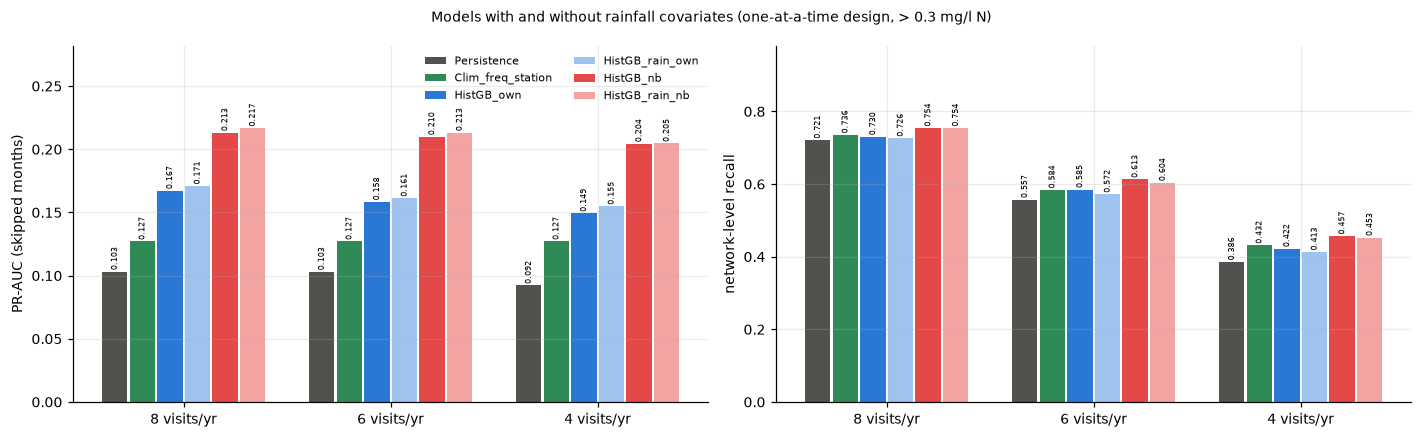

In [49]:
# ==== CELL 2 ==== Experiment 8b - models with rainfall (same hyper-parameters, seen design, block retraining, dev cut-offs) and evaluation
if HAVE_RAIN:
    M8 = {"HistGB_rain_own": OWN + RAINC, "HistGB_rain_nb": OWN + NBC + RAINC}
    CH8 = {"HistGB_rain_own": CHOSEN["HistGB_own"], "HistGB_rain_nb": CHOSEN["HistGB_nb"]}       # no re-tuning
    _chosen_saved = dict(CHOSEN); CHOSEN.update(CH8)
    try:
        t_ = time.time(); P8 = run_models(ITEMS, "seen", pairs=PAIRS, cols_map=M8)
    finally:
        CHOSEN.clear(); CHOSEN.update(_chosen_saved)
    for k, (IT, _) in ITEMS.items():
        for n in M8: IT[n] = P8[k][n]
    DEV8 = {n: fit(cols, HGB_GRID[CH8[n]], PAIRS[PAIRS.year < CFG["dev"][0]]) for n, cols in M8.items()}
    for k, (IT, _) in DEV_ITEMS.items():
        for n, cols in M8.items(): IT[n] = predict(DEV8[n], cols, IT)
    assert all(ITEMS[k][0][list(M8)].notna().all().all() for k in ITEMS)
    print(f"rainfall models fitted in {time.time() - t_:.0f}s")
    for f in CFG["sched"]:
        for thr in THRS:
            DV, _ = pooled(DEV_ITEMS, f); yb = labels(DV, thr); nph = len(CFG["sched"][f])
            for n in M8:
                sc = np.exp(DV[n].values); fa = np.array([((sc > c) & ~yb).sum() / nph / n_sy_dev for c in GRID]); ok = np.flatnonzero(fa <= CFG["fa_budget"])
                CUT6[(f, thr, n)] = float(GRID[ok[0]]) if len(ok) else float(GRID[-1])
    M8ALL = ["Observation-only", "Persistence", "HistGB_own", "HistGB_rain_own", "HistGB_nb", "HistGB_rain_nb", "Clim_freq_station"]
    rows = []
    for thr in THRS:
        set_thr(thr)
        for f in CFG["sched"]:
            IT, RET = pooled(ITEMS, f); nph = len(CFG["sched"][f]); yb = labels(IT, thr)
            for s_ in M8ALL:
                a = alarms(IT, f, thr, s_); tp, ev = tp_ev(IT, RET, thr, a); fp = 0 if a is None else int((a & ~yb).sum()); TPs = 0 if a is None else int((a & yb).sum())
                rows.append({"visits/yr": f, "threshold": thr, "strategy": s_, "PR-AUC (skipped months)": np.nan if a is None else average_precision_score(yb, score_of(IT, s_)),
                             "network-level recall": tp.sum() / ev.sum(), "skipped-month recall": TPs / yb.sum(), "predictive precision": TPs / a.sum() if (a is not None and a.sum()) else np.nan,
                             "false alarms/station-yr": fp / nph / n_sy_eval, "MAE log": float(np.abs(IT[s_].values - IT.y.values).mean()) if s_ in ("Persistence", "HistGB_own", "HistGB_rain_own", "HistGB_nb", "HistGB_rain_nb") else np.nan})
    RAIN8 = pd.DataFrame(rows); save_table(RAIN8, "T29_rainfall_models")
    display(RAIN8[(RAIN8.threshold == PRIMARY)].set_index(["visits/yr", "strategy"]).drop(columns="threshold").round(3))
    bt = []
    for f in CFG["sched"]:
        for thr in (0.2, PRIMARY):
            set_thr(thr); IT, RET = pooled(ITEMS, f)
            for a_, b_ in (("HistGB_rain_nb", "HistGB_nb"), ("HistGB_rain_own", "HistGB_own"), ("HistGB_rain_nb", "Clim_freq_station")):
                for cl in ("station", "year"):
                    e, lo, hi = boot_ap_counted(IT, a_, b_, thr, cl)
                    bt.append({"visits/yr": f, "threshold": thr, "metric": "PR-AUC", "comparison": f"{a_} - {b_}", "cluster": cl, "difference": e, "95% CI low": lo, "95% CI high": hi})
                    for so, mlab in ((False, "network-level recall"), (True, "skipped-month recall")):
                        ta, ea = tp_ev(IT, RET, thr, alarms(IT, f, thr, a_), cl, so); tb, eb_ = tp_ev(IT, RET, thr, alarms(IT, f, thr, b_), cl, so)
                        e, lo, hi = boot_ratio_diff(ta, ea, tb, eb_, tag=f"8 {mlab} {a_}-{b_} {f} {thr} {cl}")
                        bt.append({"visits/yr": f, "threshold": thr, "metric": mlab, "comparison": f"{a_} - {b_}", "cluster": cl, "difference": e, "95% CI low": lo, "95% CI high": hi})
                if thr == PRIMARY:
                    e, lo, hi, sk = boot_ap_2way(IT, a_, b_, thr)
                    bt.append({"visits/yr": f, "threshold": thr, "metric": "PR-AUC", "comparison": f"{a_} - {b_}", "cluster": "two-way", "difference": e, "95% CI low": lo, "95% CI high": hi, "replicates discarded": sk})
    RAIN8B = pd.DataFrame(bt); save_table(RAIN8B, "T29b_rainfall_models_bootstrap")
    display(RAIN8B[(RAIN8B.threshold == PRIMARY) & (RAIN8B["visits/yr"] == 4)].round(4))
    # by station group (4 visits/yr, primary threshold)
    set_thr(PRIMARY); IT, RET = pooled(ITEMS, 4); yb = labels(IT, PRIMARY); gr = []
    TE = {s_: tp_ev(IT, RET, PRIMARY, alarms(IT, 4, PRIMARY, s_)) for s_ in ("HistGB_nb", "HistGB_rain_nb")}
    for g, m in GRP.items():
        e, lo, hi = boot_ratio_diff(*TE["HistGB_rain_nb"], *TE["HistGB_nb"], units=np.flatnonzero(m), tag=f"8 group {g}")
        sk = m[IT.s.values]
        gr.append({"group": g, "recall HistGB_nb": TE["HistGB_nb"][0][m].sum() / TE["HistGB_nb"][1][m].sum(), "recall HistGB_rain_nb": TE["HistGB_rain_nb"][0][m].sum() / TE["HistGB_rain_nb"][1][m].sum(),
                   "d recall": e, "95% CI low": lo, "95% CI high": hi,
                   "PR-AUC HistGB_nb": average_precision_score(yb[sk], IT.HistGB_nb.values[sk]) if yb[sk].sum() >= 20 else np.nan,
                   "PR-AUC HistGB_rain_nb": average_precision_score(yb[sk], IT.HistGB_rain_nb.values[sk]) if yb[sk].sum() >= 20 else np.nan})
    RAIN8G = pd.DataFrame(gr); save_table(RAIN8G, "T29c_rainfall_models_station_groups"); display(RAIN8G.round(3))
    x = RAIN8[(RAIN8.threshold == PRIMARY) & RAIN8.strategy.isin(["Persistence", "Clim_freq_station", "HistGB_own", "HistGB_rain_own", "HistGB_nb", "HistGB_rain_nb"])]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4)); cols8 = {"Persistence": "#52514e", "Clim_freq_station": "#2e8b57", "HistGB_own": "#2a78d6", "HistGB_rain_own": "#9fc3ef", "HistGB_nb": "#e34948", "HistGB_rain_nb": "#f4a3a3"}
    for a_, met in zip(ax, ("PR-AUC (skipped months)", "network-level recall")):
        fr = list(CFG["sched"]); xx = np.arange(len(fr)); w = .8 / len(cols8)
        for i, (s_, cc) in enumerate(cols8.items()):
            b = a_.bar(xx + (i - (len(cols8) - 1) / 2) * w, [x[(x.strategy == s_) & (x["visits/yr"] == f)][met].iloc[0] for f in fr], w * .92, color=cc, label=s_)
            a_.bar_label(b, fmt="%.3f", fontsize=5.5, rotation=90, padding=1)
        a_.set_xticks(xx); a_.set_xticklabels([f"{f} visits/yr" for f in fr]); a_.set_ylabel(met); a_.set_ylim(0, x[met].max() * 1.3)
    ax[0].legend(fontsize=7, ncol=2); fig.suptitle(f"Models with and without rainfall covariates (one-at-a-time design, > {PRIMARY} mg/l N)", fontsize=9)
    fig.tight_layout(); savefig(fig, "F24_rainfall_models"); plt.show()

In [50]:
# ==== CELL 3 ==== Experiment 8c - addendum (EXPERIMENT8_ADDENDUM.md; specified after a fast development run had produced preliminary numbers): timing sensitivity, raindays ablation, grid-cell bootstrap,
# wet/normal/dry strata and threshold-selection table. Written after the fast-mode development run; reported as sensitivity/exploratory.
if HAVE_RAIN:
    def rain_lag_cols(F):
        s, t, t0 = F.s.values.astype(int), F.t.values.astype(int), F.t0.values.astype(int); tl = t - 1; m = mon[tl] - 1
        CS = np.stack([np.cumsum(np.where(mon[None, :] == k, RAINL, 0.0), 1) for k in range(1, 13)])
        CN = np.stack([np.cumsum(np.broadcast_to(mon[None, :] == k, RAINL.shape), 1) for k in range(1, 13)]).astype(float)
        n = CN[m, s, t0]; clim = np.where(n > 0, CS[m, s, t0] / np.maximum(n, 1), np.nan)
        return pd.DataFrame({"rainlag_t": RAINL[s, tl], "raindays10lag_t": RD10[s, tl], "rainlag_anom_t": RAINL[s, tl] - clim, "rainlag_change": RAINL[s, tl] - RAINL[s, t0]}, index=F.index)
    RAINLAGC = ["rainlag_t", "raindays10lag_t", "rainlag_anom_t", "rainlag_change"]
    for F_ in [PAIRS] + [IT for IT, _ in ITEMS.values()] + [IT for IT, _ in DEV_ITEMS.values()]:
        F_[RAINLAGC] = rain_lag_cols(F_)
    assert all((IT.t.values - 1 <= IT.t.values).all() for IT, _ in ITEMS.values())
    M8c = {"HistGB_rainlag_nb": OWN + NBC + RAINLAGC, "HistGB_rain_noRD_nb": OWN + NBC + ["rain_t", "rain_anom_t", "rain_change"]}
    CH8c = {n: CHOSEN["HistGB_nb"] for n in M8c}; _chosen_saved = dict(CHOSEN); CHOSEN.update(CH8c)
    try:
        t_ = time.time(); P8c = run_models(ITEMS, "seen", pairs=PAIRS, cols_map=M8c)
    finally:
        CHOSEN.clear(); CHOSEN.update(_chosen_saved)
    for k, (IT, _) in ITEMS.items():
        for n in M8c: IT[n] = P8c[k][n]
    DEV8c = {n: fit(cols, HGB_GRID[CH8c[n]], PAIRS[PAIRS.year < CFG["dev"][0]]) for n, cols in M8c.items()}
    for k, (IT, _) in DEV_ITEMS.items():
        for n, cols in M8c.items(): IT[n] = predict(DEV8c[n], cols, IT)
    for f in CFG["sched"]:
        for thr in THRS:
            DV, _ = pooled(DEV_ITEMS, f); yb = labels(DV, thr); nph = len(CFG["sched"][f])
            for n in M8c:
                sc = np.exp(DV[n].values); fa = np.array([((sc > c) & ~yb).sum() / nph / n_sy_dev for c in GRID]); ok = np.flatnonzero(fa <= CFG["fa_budget"])
                CUT6[(f, thr, n)] = float(GRID[ok[0]]) if len(ok) else float(GRID[-1])
    print(f"addendum models (timing sensitivity, raindays ablation) fitted in {time.time() - t_:.0f}s")
    # (a, b) ablation table: M1 own, M2 own+nb, M3 own+rain, M4 own+nb+rain, M4 with t-1 rainfall, M4 without raindays
    ABL = [("M1 own history", "HistGB_own"), ("M2 + neighbours", "HistGB_nb"), ("M3 own + rainfall", "HistGB_rain_own"), ("M4 + neighbours + rainfall", "HistGB_rain_nb"),
           ("M4 with rainfall of month t-1 (timing sensitivity)", "HistGB_rainlag_nb"), ("M4 without raindays10mm (ablation)", "HistGB_rain_noRD_nb")]
    rows, bt = [], []
    for thr in (0.2, PRIMARY):
        set_thr(thr)
        for f in CFG["sched"]:
            IT, RET = pooled(ITEMS, f); nph = len(CFG["sched"][f]); yb = labels(IT, thr)
            for lab, s_ in ABL:
                a = alarms(IT, f, thr, s_); tp, ev = tp_ev(IT, RET, thr, a); TPs = int((a & yb).sum()); FPs = int((a & ~yb).sum()); FNs = int(yb.sum()) - TPs
                prec = tp.sum() / (tp.sum() + FPs); rec = tp.sum() / ev.sum()
                rows.append({"visits/yr": f, "threshold": thr, "model": lab, "strategy": s_, "network-level recall": rec, "skipped-month recall": TPs / yb.sum(),
                             "predictive precision": TPs / a.sum() if a.sum() else np.nan, "operational precision": prec, "F1 (network-level)": 2 * prec * rec / (prec + rec),
                             "PR-AUC": average_precision_score(yb, IT[s_]), "ROC-AUC": roc_auc_score(yb, IT[s_]), "TP (skipped, per phase)": TPs / nph, "FP (per phase)": FPs / nph,
                             "FN (skipped, per phase)": FNs / nph, "false alarms/station-yr": FPs / nph / n_sy_eval, "missed exceedances/station-yr": (ev.sum() - tp.sum()) / nph / n_sy_eval})
            for s_ in ("HistGB_rainlag_nb", "HistGB_rain_noRD_nb"):
                for cl in ("station", "year"):
                    e, lo, hi = boot_ap_counted(IT, s_, "HistGB_nb", thr, cl)
                    bt.append({"visits/yr": f, "threshold": thr, "metric": "PR-AUC", "comparison": f"{s_} - HistGB_nb", "cluster": cl, "difference": e, "95% CI low": lo, "95% CI high": hi})
                    ta, ea = tp_ev(IT, RET, thr, alarms(IT, f, thr, s_), cl); tb, eb_ = tp_ev(IT, RET, thr, alarms(IT, f, thr, "HistGB_nb"), cl)
                    e, lo, hi = boot_ratio_diff(ta, ea, tb, eb_, tag=f"8c {s_} {f} {thr} {cl}")
                    bt.append({"visits/yr": f, "threshold": thr, "metric": "network-level recall", "comparison": f"{s_} - HistGB_nb", "cluster": cl, "difference": e, "95% CI low": lo, "95% CI high": hi})
    ABLT = pd.DataFrame(rows); save_table(ABLT, "T29d_ablation_rainfall"); save_table(pd.DataFrame(bt), "T29e_ablation_rainfall_bootstrap")
    display(ABLT[(ABLT.threshold == PRIMARY) & (ABLT["visits/yr"] == 4)].set_index("model").drop(columns=["visits/yr", "threshold", "strategy"]).round(3))
    # (c) grid-cell cluster bootstrap of the primary comparison
    cellkey = rf.drop_duplicates("StationCode").set_index("StationCode")[["cell_x", "cell_y"]].apply(tuple, axis=1)
    cells = sorted(set(cellkey.values)); cid = np.array([cells.index(cellkey[c]) for c in sel]); K = len(cells)
    set_thr(PRIMARY); IT, RET = pooled(ITEMS, 4); yb = labels(IT, PRIMARY); kc = cid[IT.s.values]
    mem = [np.flatnonzero(kc == k) for k in range(K)]; rr = np.random.RandomState(SEED); out = []; skc = 0
    for _ in range(CFG["n_boot"]):
        idx = np.concatenate([mem[k] for k in rr.randint(0, K, K)])
        if yb[idx].sum() == 0: skc += 1; continue
        out.append(average_precision_score(yb[idx], IT.HistGB_rain_nb.values[idx]) - average_precision_score(yb[idx], IT.HistGB_nb.values[idx]))
    ta, ea = tp_ev(IT, RET, PRIMARY, alarms(IT, 4, PRIMARY, "HistGB_rain_nb")); tb, eb_ = tp_ev(IT, RET, PRIMARY, alarms(IT, 4, PRIMARY, "HistGB_nb"))
    agg = lambda x: np.bincount(cid, x, K)
    e2, lo2, hi2 = boot_ratio_diff(agg(ta), agg(ea), agg(tb), agg(eb_), tag="8c grid-cell recall")
    CELLB = pd.DataFrame([{"comparison": "HistGB_rain_nb - HistGB_nb", "metric": "PR-AUC", "cluster": f"grid cell ({K} cells)",
                           "difference": average_precision_score(yb, IT.HistGB_rain_nb) - average_precision_score(yb, IT.HistGB_nb), "95% CI low": np.percentile(out, 2.5), "95% CI high": np.percentile(out, 97.5), "replicates discarded": skc},
                          {"comparison": "HistGB_rain_nb - HistGB_nb", "metric": "network-level recall", "cluster": f"grid cell ({K} cells)", "difference": e2, "95% CI low": lo2, "95% CI high": hi2, "replicates discarded": np.nan}])
    save_table(CELLB, "T29f_rainfall_gridcell_bootstrap"); display(CELLB.round(4))
    # (d) wet / normal / dry months: terciles of the station's 1995-2007 rainfall for the same calendar month (no evaluation data)
    q = np.full((S, 12, 2), np.nan); hist = (yr >= 1995) & (yr <= 2007)
    for m_ in range(1, 13):
        cols_ = hist & (mon == m_); q[:, m_ - 1, 0] = np.percentile(RAINL[:, cols_], 100 / 3, axis=1); q[:, m_ - 1, 1] = np.percentile(RAINL[:, cols_], 200 / 3, axis=1)
    def wet_class(F):
        s, t = F.s.values.astype(int), F.t.values.astype(int); r = RAINL[s, t]; lo_, hi_ = q[s, mon[t] - 1, 0], q[s, mon[t] - 1, 1]
        return np.where(r <= lo_, "dry (lower tercile)", np.where(r > hi_, "wet (upper tercile)", "normal (middle tercile)"))
    rows = []
    for f in CFG["sched"]:
        IT, RET = pooled(ITEMS, f); yb = labels(IT, PRIMARY); wc = wet_class(IT); wr = wet_class(RET.assign(t0=RET.t))
        for cls in ("dry (lower tercile)", "normal (middle tercile)", "wet (upper tercile)"):
            mi, mr = wc == cls, wr == cls; ITc, RETc = IT[mi], RET[mr]; ybc = yb[mi]
            TE = {s_: tp_ev(ITc, RETc, PRIMARY, alarms(ITc, f, PRIMARY, s_)) for s_ in ("Persistence", "Clim_freq_station", "HistGB_own", "HistGB_nb", "HistGB_rain_nb")}
            e, lo, hi = boot_ratio_diff(*TE["HistGB_nb"], *TE["HistGB_own"], tag=f"8c wet/dry {cls} {f}")
            r_ = {"visits/yr": f, "rainfall class": cls, "skipped months": int(mi.sum()) // len(CFG["sched"][f]), "skipped exceedances": int(ybc.sum()) // len(CFG["sched"][f]),
                  "exceedance rate (skipped months)": ybc.mean(), "neighbour benefit, recall (HistGB_nb - HistGB_own)": e, "95% CI low": lo, "95% CI high": hi}
            for s_ in TE:
                r_[f"PR-AUC {s_}"] = average_precision_score(ybc, score_of(ITc, s_)) if ybc.sum() >= 20 else np.nan; r_[f"recall {s_}"] = TE[s_][0].sum() / TE[s_][1].sum()
            rows.append(r_)
    WET = pd.DataFrame(rows); save_table(WET, "T29g_wet_normal_dry_months"); display(WET[WET["visits/yr"] == 4].set_index("rainfall class").drop(columns="visits/yr").T.round(3))
    # (e) threshold-selection table: development curve, selected cut-off and frozen evaluation result
    TS, curve = [], []
    for f in CFG["sched"]:
        DV, DRET = pooled(DEV_ITEMS, f); IT, RET = pooled(ITEMS, f); ydv, yev = labels(DV, PRIMARY), labels(IT, PRIMARY); nph = len(CFG["sched"][f])
        for s_ in ("Persistence", "Clim_freq_station", "HistGB_own", "HistGB_nb", "HistGB_rain_nb"):
            cands = cands7(s_, score_of(DV, s_)); sdv, sev = score_of(DV, s_), score_of(IT, s_)
            for c in cands:
                curve.append({"visits/yr": f, "strategy": s_, "candidate cut-off": float(c), "development skipped-month recall": ((sdv > c) & ydv).sum() / ydv.sum(),
                              "development false alarms/station-yr": ((sdv > c) & ~ydv).sum() / nph / n_sy_dev})
            c = CUT6[(f, PRIMARY, s_)]; a_dv, a_ev = sdv > c, sev > c
            tpd, evd = tp_ev(DV, DRET, PRIMARY, a_dv); tpe, eve = tp_ev(IT, RET, PRIMARY, a_ev)
            TS.append({"visits/yr": f, "strategy": s_, "selected cut-off (frozen)": c, "development skipped-month recall": (a_dv & ydv).sum() / ydv.sum(),
                       "development network-level recall": tpd.sum() / evd.sum(), "development false alarms/station-yr": (a_dv & ~ydv).sum() / nph / n_sy_dev,
                       "evaluation skipped-month recall": (a_ev & yev).sum() / yev.sum(), "evaluation network-level recall": tpe.sum() / eve.sum(),
                       "evaluation false alarms/station-yr": (a_ev & ~yev).sum() / nph / n_sy_eval, "constraint met in evaluation (<= 0.1)": (a_ev & ~yev).sum() / nph / n_sy_eval <= CFG["fa_budget"]})
    TST = pd.DataFrame(TS); save_table(TST, "T29h_threshold_selection"); save_table(pd.DataFrame(curve), "T29i_threshold_selection_curves")
    display(TST[TST["visits/yr"] == 4].set_index("strategy").drop(columns="visits/yr").round(3))

addendum models (timing sensitivity, raindays ablation) fitted in 390s


,network-level recall,skipped-month recall,predictive precision,operational precision,F1 (network-level),PR-AUC,ROC-AUC,"TP (skipped, per phase)",FP (per phase),"FN (skipped, per phase)",false alarms/station-yr,missed exceedances/station-yr
model,,,,,,,,,,,,
M1 own history,0.422,0.133,0.318,0.689,0.524,0.149,0.806,73.67,158,478.3,0.057,0.172
M2 + neighbours,0.457,0.185,0.379,0.693,0.551,0.204,0.85,102.3,167.3,449.7,0.06,0.161
M3 own + rainfall,0.413,0.12,0.328,0.716,0.524,0.155,0.807,66,135.3,486,0.049,0.174
M4 + neighbours + rainfall,0.453,0.179,0.376,0.696,0.549,0.205,0.849,99,164,453,0.059,0.162
M4 with rainfall of month t-1 (timing sensitivity),0.442,0.164,0.357,0.692,0.54,0.198,0.849,90.33,163,461.7,0.058,0.166
M4 without raindays10mm (ablation),0.45,0.175,0.379,0.702,0.548,0.209,0.849,96.67,158.3,455.3,0.057,0.163


,comparison,metric,cluster,difference,95% CI low,95% CI high,replicates discarded
0,HistGB_rain_nb - HistGB_nb,PR-AUC,grid cell (187 cells),0.0002,-0.0105,0.0142,0
1,HistGB_rain_nb - HistGB_nb,network-level recall,grid cell (187 cells),-0.004,-0.0101,0.002,NaN


rainfall class,dry (lower tercile),normal (middle tercile),wet (upper tercile)
skipped months,"7,692","5,698","7,768"
skipped exceedances,203,164,184
exceedance rate (skipped months),0.026,0.029,0.024
"neighbour benefit, recall (HistGB_nb - HistGB_own)",0.031,0.04,0.034
95% CI low,0.013,0.021,0.009
95% CI high,0.053,0.06,0.062
PR-AUC Persistence,0.112,0.089,0.078
recall Persistence,0.396,0.377,0.383
PR-AUC Clim_freq_station,0.149,0.119,0.117
recall Clim_freq_station,0.445,0.412,0.435


,selected cut-off (frozen),development skipped-month recall,development network-level recall,development false alarms/station-yr,evaluation skipped-month recall,evaluation network-level recall,evaluation false alarms/station-yr,constraint met in evaluation (<= 0.1)
strategy,,,,,,,,
Persistence,0.471,0.088,0.392,0.099,0.079,0.386,0.079,True
Clim_freq_station,0.304,0.098,0.399,0.089,0.147,0.432,0.067,True
HistGB_own,0.239,0.157,0.438,0.096,0.133,0.422,0.057,True
HistGB_nb,0.239,0.211,0.474,0.096,0.185,0.457,0.06,True
HistGB_rain_nb,0.239,0.199,0.466,0.092,0.179,0.453,0.059,True


> **Interpretation — Experiment 8 (rainfall covariates).** Monthly rainfall does not improve detection. For HistGB + neighbours the AP difference is +0.0002 (two-way CI −0.015 to 0.020) and recall changes by −0.4 points (−1.0 to 0.2); for HistGB with own history, rainfall reduces recall by 0.9 points (−1.7 to −0.1). Rainfall of the previous month, omission of the heavy-rain day count and a grid-cell bootstrap give the same result, and the neighbour benefit is similar in dry, normal and wet months (Tables T29d–T29g). These sensitivity analyses were specified in `EXPERIMENT8_ADDENDUM.md` after a fast development run had produced preliminary numbers; the main rainfall analysis followed `EXPERIMENT8_PLAN.md`.

<a id="14e"></a>
## 14e. Experiment 9 — Robustness (pre-declared): basin-level bootstrap and hyper-parameter choice by development PR-AUC

Both analyses were declared in `EXPERIMENT9_PLAN.md` before they were run. No model, cut-off or setting is re-selected and no primary result changes. **9a** resamples whole river basins (40 named primary basins; each of the stations with a blank basin is its own unit) instead of single stations, using the same predictions and cut-offs; a conclusion is called robust at basin level if the basin-bootstrap 95% CI excludes 0 in the same direction as the primary estimate. **9b** re-scores the 6 configurations of `HGB_GRID` for both HistGB models by development-period (2005–2007) PR-AUC at > 0.3 mg N/L; no evaluation-period data are used and the configuration chosen by development MAE is kept.

In [51]:
# ==== CELL 1 ==== Experiment 9a - basin-level cluster bootstrap (pre-declared in EXPERIMENT9_PLAN.md); no model or cut-off is changed
# Units: 40 named primary basins; each station with a blank basin is its own unit. Paired bootstrap, CFG["n_boot"] replicates, seed SEED.
bname = info.basin.fillna("").astype(str).str.strip().values
BASIN = np.empty(S, int); _u = {}
for i_, b_ in enumerate(bname):
    key_ = b_ if b_ else f"__blank_{i_}"
    BASIN[i_] = _u.setdefault(key_, len(_u))
NB_UNITS = len(_u); print(f"basin bootstrap units: {NB_UNITS} ({sum(1 for k in _u if not k.startswith('__blank'))} named basins + {sum(1 for k in _u if k.startswith('__blank'))} stations with blank basin)")
def boot_ap_units(IA, a, IB, b, thr, unitA, unitB, K, B=None, seed=SEED):
    # paired cluster bootstrap of PR-AUC(a on IA) - PR-AUC(b on IB); IA and IB may be different item sets (e.g. two schedules)
    B = CFG["n_boot"] if B is None else B; ya, yb_ = labels(IA, thr), labels(IB, thr)
    ma = [np.flatnonzero(unitA == k) for k in range(K)]; mb = [np.flatnonzero(unitB == k) for k in range(K)]
    r = np.random.RandomState(seed); out, sk = [], 0
    for _ in range(B):
        dd = r.randint(0, K, K); ia = np.concatenate([ma[k] for k in dd]); ib = np.concatenate([mb[k] for k in dd])
        if ya[ia].sum() == 0 or yb_[ib].sum() == 0: sk += 1; continue
        out.append(average_precision_score(ya[ia], IA[a].values[ia]) - average_precision_score(yb_[ib], IB[b].values[ib]))
    BOOT_LOG.append({"call": f"9a PR-AUC {a} - {b}", "replicates": B, "discarded": sk})
    return average_precision_score(ya, IA[a]) - average_precision_score(yb_, IB[b]), np.percentile(out, 2.5), np.percentile(out, 97.5)
to_basin = lambda x: np.bincount(BASIN, x, NB_UNITS)                       # station-level sums -> basin-level sums
rows9 = []
def add9(exp, f, comp, metric, est, ci_station, ci_basin):
    rows9.append({"experiment": exp, "visits/yr": f, "comparison": comp, "metric": metric, "difference": est,
                  "station CI low": ci_station[0], "station CI high": ci_station[1], "basin CI low": ci_basin[0], "basin CI high": ci_basin[1],
                  "robust at basin level (CI excludes 0, same sign)": bool((ci_basin[0] > 0 and est > 0) or (ci_basin[1] < 0 and est < 0))})
set_thr(PRIMARY)
# (1) one-at-a-time design
for f in CFG["sched"]:
    IT, RET = pooled(ITEMS, f); us = IT.s.values
    for a_, b_ in (("HistGB_nb", "Persistence"), ("HistGB_nb", "Clim_freq_station"), ("HistGB_nb", "HistGB_own")):
        e, lo, hi = boot_ap_units(IT, a_, IT, b_, PRIMARY, us, us, S); e2, lo2, hi2 = boot_ap_units(IT, a_, IT, b_, PRIMARY, BASIN[us], BASIN[us], NB_UNITS)
        add9("Exp 1 (one-at-a-time)", f, f"{a_} - {b_}", "PR-AUC", e, (lo, hi), (lo2, hi2))
        if b_ == "HistGB_own": continue
        ta, ea = tp_ev(IT, RET, PRIMARY, alarms(IT, f, PRIMARY, a_)); tb, eb_ = tp_ev(IT, RET, PRIMARY, alarms(IT, f, PRIMARY, b_))
        e, lo, hi = boot_ratio_diff(ta, ea, tb, eb_, tag=f"9a station {a_}-{b_} {f}")
        _, lo2, hi2 = boot_ratio_diff(to_basin(ta), to_basin(ea), to_basin(tb), to_basin(eb_), tag=f"9a basin {a_}-{b_} {f}")
        add9("Exp 1 (one-at-a-time)", f, f"{a_} - {b_}", "network-level recall", e, (lo, hi), (lo2, hi2))
# (2) network-wide schedules, HistGB + neighbours
for f in NET_FREQS:
    SA, SB = "network: staggered (graph colouring)", "network: synchronised"
    EA = pd.concat([p[0] for p in NET[(f, SA)]], ignore_index=True); EB = pd.concat([p[0] for p in NET[(f, SB)]], ignore_index=True)
    e, lo, hi = boot_ap_units(EA, "HistGB_nb", EB, "HistGB_nb", PRIMARY, EA.s.values, EB.s.values, S)
    _, lo2, hi2 = boot_ap_units(EA, "HistGB_nb", EB, "HistGB_nb", PRIMARY, BASIN[EA.s.values], BASIN[EB.s.values], NB_UNITS)
    add9("Exp 4 (network-wide)", f, "staggered - synchronised (HistGB_nb)", "PR-AUC", e, (lo, hi), (lo2, hi2))
    oA, EVa, RETa, reva = evaluate_scheme(NET[(f, SA)], f, PRIMARY); oB, EVb, RETb, revb = evaluate_scheme(NET[(f, SB)], f, PRIMARY)
    ta, ea = station_recall(EVa, RETa, reva, PRIMARY, "HistGB_nb"); tb, eb_ = station_recall(EVb, RETb, revb, PRIMARY, "HistGB_nb")
    e, lo, hi = boot_ratio_diff(ta, ea, tb, eb_, tag=f"9a station network {f}")
    _, lo2, hi2 = boot_ratio_diff(to_basin(ta), to_basin(ea), to_basin(tb), to_basin(eb_), tag=f"9a basin network {f}")
    add9("Exp 4 (network-wide)", f, "staggered - synchronised (HistGB_nb)", "network-level recall", e, (lo, hi), (lo2, hi2))
# (3) allocation at the same budget
RN = f"Risk-based: {N_HI[2]} monthly, others 2/yr"
for (na, da), (nb_, db) in (((RN, "HistGB + neighbours"), ("Uniform 4/yr, staggered", "HistGB + neighbours")), ((RN, "Observation only"), ("Uniform 4/yr, staggered", "HistGB + neighbours"))):
    ta, ea = st_counts(na, PRIMARY, da); tb, eb_ = st_counts(nb_, PRIMARY, db)
    e, lo, hi = boot_ratio_diff(ta, ea, tb, eb_, tag=f"9a station alloc {da}")
    _, lo2, hi2 = boot_ratio_diff(to_basin(ta), to_basin(ea), to_basin(tb), to_basin(eb_), tag=f"9a basin alloc {da}")
    add9("Exp 5 (allocation)", 4, f"{na} [{da}] - Uniform 4/yr, staggered [{db}]", "network-level recall", e, (lo, hi), (lo2, hi2))
BASINB = pd.DataFrame(rows9); save_table(BASINB, "T30_basin_bootstrap"); display(BASINB.round(4))
print("conclusions robust at basin level:", int(BASINB.iloc[:, -1].sum()), "of", len(BASINB))

basin bootstrap units: 43 (40 named basins + 3 stations with blank basin)


,experiment,visits/yr,comparison,metric,difference,station CI low,station CI high,basin CI low,basin CI high,"robust at basin level (CI excludes 0, same sign)"
0,Exp 1 (one-at-a-time),8,HistGB_nb - Persistence,PR-AUC,0.11,0.0675,0.1449,0.071,0.1252,True
1,Exp 1 (one-at-a-time),8,HistGB_nb - Persistence,network-level recall,0.0334,0.0149,0.051,0.0031,0.0509,True
2,Exp 1 (one-at-a-time),8,HistGB_nb - Clim_freq_station,PR-AUC,0.0861,0.0563,0.1064,0.0481,0.1023,True
3,Exp 1 (one-at-a-time),8,HistGB_nb - Clim_freq_station,network-level recall,0.0189,0.0014,0.0387,0.0043,0.0326,True
4,Exp 1 (one-at-a-time),8,HistGB_nb - HistGB_own,PR-AUC,0.0459,0.0304,0.065,0.0237,0.0678,True
5,Exp 1 (one-at-a-time),6,HistGB_nb - Persistence,PR-AUC,0.1069,0.0631,0.1451,0.0654,0.1261,True
6,Exp 1 (one-at-a-time),6,HistGB_nb - Persistence,network-level recall,0.0556,0.0235,0.0853,0.0068,0.0838,True
7,Exp 1 (one-at-a-time),6,HistGB_nb - Clim_freq_station,PR-AUC,0.0829,0.0527,0.1045,0.0494,0.0971,True
8,Exp 1 (one-at-a-time),6,HistGB_nb - Clim_freq_station,network-level recall,0.029,0.0034,0.0554,0.0091,0.0489,True
9,Exp 1 (one-at-a-time),6,HistGB_nb - HistGB_own,PR-AUC,0.0516,0.0359,0.07,0.0315,0.0689,True


conclusions robust at basin level: 20 of 21


In [52]:
# ==== CELL 2 ==== Experiment 9b - hyper-parameter configurations evaluated by development-period PR-AUC (no evaluation data; choice not changed)
dtr = PAIRS[PAIRS.year < CFG["dev"][0]]; rows9b = []
for n_, cols_ in MODELS.items():
    for ci, cfg in enumerate(HGB_GRID):
        m_ = fit(cols_, cfg, dtr); r_ = {"model": n_, "config": ci, **cfg, "selected": ci == CHOSEN[n_],
                                          "dev MAE (log)": float(TUNE[(TUNE.model == n_) & (TUNE.config == ci)]["dev MAE (log)"].iloc[0])}
        for f in CFG["sched"]:
            DV, _ = pooled(DEV_ITEMS, f); r_[f"dev PR-AUC {f}/yr"] = average_precision_score(labels(DV, PRIMARY), predict(m_, cols_, DV))
        rows9b.append(r_)
HP = pd.DataFrame(rows9b)
for f in CFG["sched"]:
    HP[f"rank by dev PR-AUC {f}/yr"] = HP.groupby("model")[f"dev PR-AUC {f}/yr"].rank(ascending=False, method="min").astype(int)
    HP[f"selected minus best dev PR-AUC {f}/yr"] = HP[f"dev PR-AUC {f}/yr"] - HP.groupby("model")[f"dev PR-AUC {f}/yr"].transform("max")
HP["rank by dev MAE"] = HP.groupby("model")["dev MAE (log)"].rank(method="min").astype(int)
save_table(HP, "T31_hyperparameter_dev_prauc"); display(HP.round(4))
print(HP[HP.selected][["model"] + [c for c in HP.columns if c.startswith("rank") or c.startswith("selected minus")]].round(4).to_string(index=False))

,model,config,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,selected,dev MAE (log),dev PR-AUC 8/yr,dev PR-AUC 6/yr,dev PR-AUC 4/yr,rank by dev PR-AUC 8/yr,selected minus best dev PR-AUC 8/yr,rank by dev PR-AUC 6/yr,selected minus best dev PR-AUC 6/yr,rank by dev PR-AUC 4/yr,selected minus best dev PR-AUC 4/yr,rank by dev MAE
0,HistGB_own,0,0.05,200,15,50,1,False,0.4298,0.1838,0.1773,0.1659,5,-0.0049,5,-0.0052,4,-0.0023,6
1,HistGB_own,1,0.05,400,15,50,1,False,0.4249,0.1861,0.1795,0.1664,3,-0.0026,3,-0.0031,3,-0.0019,2
2,HistGB_own,2,0.1,200,15,50,1,False,0.4257,0.1877,0.1825,0.1632,2,-0.001,1,0,6,-0.0051,3
3,HistGB_own,3,0.05,200,31,50,1,False,0.4269,0.1816,0.1708,0.1643,6,-0.0071,6,-0.0117,5,-0.0039,5
4,HistGB_own,4,0.1,400,31,50,1,True,0.4242,0.1887,0.1804,0.1682,1,0,2,-0.0021,1,0,1
5,HistGB_own,5,0.03,600,15,50,1,False,0.4258,0.1854,0.1784,0.1673,4,-0.0033,4,-0.0041,2,-0.001,4
6,HistGB_nb,0,0.05,200,15,50,1,False,0.361,0.2239,0.2185,0.2109,5,-0.0111,6,-0.0086,6,-0.0117,6
7,HistGB_nb,1,0.05,400,15,50,1,False,0.3543,0.2305,0.2213,0.2126,3,-0.0045,3,-0.0058,4,-0.01,3
8,HistGB_nb,2,0.1,200,15,50,1,False,0.3533,0.235,0.2271,0.2226,1,0,1,0,1,0,2
9,HistGB_nb,3,0.05,200,31,50,1,False,0.3563,0.2271,0.2205,0.212,4,-0.0079,5,-0.0066,5,-0.0106,5


     model  rank by dev PR-AUC 8/yr  selected minus best dev PR-AUC 8/yr  rank by dev PR-AUC 6/yr  selected minus best dev PR-AUC 6/yr  rank by dev PR-AUC 4/yr  selected minus best dev PR-AUC 4/yr  rank by dev MAE
HistGB_own                        1                                    0                        2                              -0.0021                        1                                    0                1
 HistGB_nb                        6                              -0.0135                        4                              -0.0062                        3                               -0.009                1


> **Interpretation — Experiment 9 (basin bootstrap and hyper-parameter choice).**
> * **Basin-level bootstrap (Table T30).** Basin intervals exclude zero for 20 of the 21 planned comparisons; the exception, staggered versus synchronised sampling at 6 visits per year (+1.0 points; basin CI −0.2 to 1.9), is also uncertain under station resampling. The allocation gain stays clearly positive (+22.4 points; 14.3–30.1). With only 43 resampling units of very unequal size (1–27 stations), percentile basin intervals can be narrower than station intervals and may understate uncertainty; the basin interval for the recall gain over the climatology (0.8–4.6) is therefore not taken as stronger evidence than the station interval (−0.1 to 5.1).
> * **Hyper-parameters (Table T31).** By development-period AP, the MAE-selected configuration ranks in the top two for HistGB with own history but only third to sixth for HistGB + neighbours, whose best alternative scores 0.006–0.014 higher. This spread is smaller than the difference between the two models (0.045 at 4 visits per year), so their ranking does not change. The alternative is not evaluated on 2008–2024.

<a id="15"></a>
## 15. Sensitivity to data preparation and station cohort

The complete pipeline (selection, features, development-period cut-offs and seen-design models; hyper-parameters fixed to the primary choice) is re-run under four alternative data-preparation choices:

1. **Monthly maximum** instead of the first visit of the month;
2. **Censored values at LOD/2** instead of LOD in the features;
3. **Extreme values removed** (flag from Section 4.3);
4. **Lake/reservoir sites retained** (station set before site classification);
5. **Alternative pre-2008 cohorts**: ≥ 6 of 13 complete years (≥ 2 in 2005–07) and ≥ 10 of 13 (3 in 2005–07);
6. **Previous cohort rule** (≥ 15 complete years in 2005–2024), which uses evaluation-period data and is shown only to quantify the effect of the selection bias.

sensitivity runs: 3033s


strategy,HistGB_nb,HistGB_own,Neighbour_ratio,Persistence
variant,,,,
censored values at LOD/2,0.204,0.151,0.124,0.093
"cohort: >=10 of 13 complete years, 3 in 2005-07",0.196,0.141,0.134,0.091
"cohort: >=6 of 13 complete years, >=2 in 2005-07",0.232,0.17,0.131,0.094
extreme values removed,0.213,0.153,0.139,0.092
lake/reservoir sites retained,0.202,0.153,0.137,0.091
monthly maximum,0.216,0.162,0.137,0.093
previous rule: >=15 complete years 2005-2024 (uses evaluation-period data),0.123,0.083,0.114,0.065
"primary (rivers, first visit, LOD, extremes kept)",0.204,0.149,0.138,0.092


strategy,HistGB_nb,HistGB_own,Neighbour_ratio,Persistence
variant,,,,
censored values at LOD/2,0.451,0.427,0.384,0.386
"cohort: >=10 of 13 complete years, 3 in 2005-07",0.434,0.403,0.378,0.38
"cohort: >=6 of 13 complete years, >=2 in 2005-07",0.463,0.432,0.398,0.397
extreme values removed,0.456,0.421,0.394,0.386
lake/reservoir sites retained,0.453,0.423,0.391,0.385
monthly maximum,0.442,0.418,0.391,0.386
previous rule: >=15 complete years 2005-2024 (uses evaluation-period data),0.378,0.359,0.378,0.359
"primary (rivers, first visit, LOD, extremes kept)",0.457,0.422,0.392,0.386


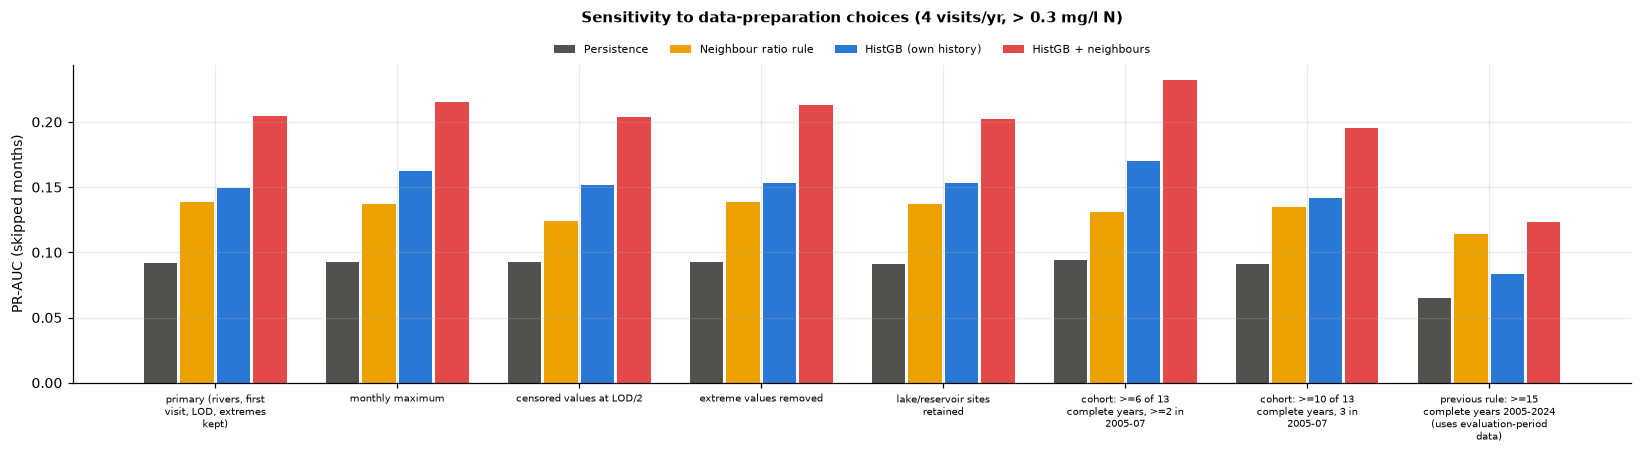

In [53]:
def run_variant(ctx):
    activate(ctx); globals()["DENSE"] = cumstats(L)
    pairs = make_pairs(); globals()["PAIRS"] = pairs
    items = {(4, p): skipped_items(CFG["sched"][4][p], CFG["eval"][0], EVAL)[:2] for p in range(3)}
    dev = {(4, p): skipped_items(CFG["sched"][4][p], CFG["dev"][0], DEVM)[:2] for p in range(3)}
    pr = run_models(items, "seen", pairs=pairs)
    for k, (IT, _) in items.items():
        for n in MODELS: IT[n] = pr[k][n]
        add_rules(IT)
    dm = {n: fit(cols, HGB_GRID[CHOSEN[n]], pairs[pairs.year < CFG["dev"][0]]) for n, cols in MODELS.items()}
    for k, (IT, _) in dev.items():
        for n, cols in MODELS.items(): IT[n] = predict(dm[n], cols, IT)
        add_rules(IT)
    out = []
    g_items, g_dev = globals()["ITEMS"], globals()["DEV_ITEMS"]; globals()["ITEMS"], globals()["DEV_ITEMS"] = items, dev
    try:
        for thr in (0.2, 0.3):
            IT, _ = pooled(items, 4); yb = labels(IT, thr); cuts = choose_cutoffs(4, thr); fx = evaluate_fixed(items, 4, thr, cuts, n_sy_eval)
            for s_ in STRATS:
                r = fx[(fx.strategy == s_) & (fx.rule == "FA-budget")].iloc[0]
                out.append({"threshold": thr, "strategy": s_, "stations": S, "events": int(fx.events.iloc[0]), "PR-AUC": average_precision_score(yb, IT[s_]),
                            "recall (FA-budget)": r.recall, "false alarms / station-yr": r["false alarms / station-yr"]})
    finally:
        globals()["ITEMS"], globals()["DEV_ITEMS"] = g_items, g_dev
    return pd.DataFrame(out)
SAVE = {k: globals()[k] for k in ("PAIRS", "DENSE")}
variants = {"primary (rivers, first visit, LOD, extremes kept)": None,
            "monthly maximum": prepare(SEL_RIVER, monthly_rule="max"), "censored values at LOD/2": prepare(SEL_RIVER, cens_factor=0.5),
            "extreme values removed": prepare(SEL_RIVER, drop_extremes=True), "lake/reservoir sites retained": prepare(SEL_ALL),
            **{name: prepare(sel_) for name, sel_ in COHORTS.items()}}
res = []; t_ = time.time()
for name, ctx in variants.items():
    if ctx is None:
        for thr in (0.2, 0.3):
            IT, _ = pooled(ITEMS, 4); yb = labels(IT, thr); fx = FIX[(FIX["visits/yr"] == 4) & (FIX.threshold == thr) & (FIX.rule == "FA-budget")]
            for s_ in STRATS:
                r = fx[fx.strategy == s_].iloc[0]
                res.append({"variant": name, "threshold": thr, "strategy": s_, "stations": S, "events": int(r.events), "PR-AUC": average_precision_score(yb, IT[s_]),
                            "recall (FA-budget)": r.recall, "false alarms / station-yr": r["false alarms / station-yr"]})
    else:
        res.append(run_variant(ctx).assign(variant=name))
activate(MAIN_CTX); globals().update(SAVE)
SENS = pd.concat([pd.DataFrame(r) if isinstance(r, dict) else r for r in [pd.DataFrame([x]) if isinstance(x, dict) else x for x in res]], ignore_index=True)
save_table(SENS, "T13_data_preparation_sensitivity"); print(f"sensitivity runs: {time.time() - t_:.0f}s")
display(SENS[SENS.threshold == PRIMARY].pivot_table(index="variant", columns="strategy", values="PR-AUC").round(3))
display(SENS[SENS.threshold == PRIMARY].pivot_table(index="variant", columns="strategy", values="recall (FA-budget)").round(3))
fig, ax = plt.subplots(figsize=(15, 4.2)); v = list(variants); x = np.arange(len(v)); w = .2
for i, s_ in enumerate(STRATS):
    vals_ = [SENS[(SENS.variant == n) & (SENS.threshold == PRIMARY) & (SENS.strategy == s_)]["PR-AUC"].iloc[0] for n in v]
    ax.bar(x + (i - 1.5) * w, vals_, w * .92, color=COL[s_], label=LAB[s_])
ax.set_xticks(x); ax.set_xticklabels([__import__("textwrap").fill(n, 24) for n in v], fontsize=6.5); ax.set_ylabel("PR-AUC (skipped months)")
ax.set_title(f"Sensitivity to data-preparation choices (4 visits/yr, > {PRIMARY} mg/l N)", pad=28); ax.legend(fontsize=7, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); savefig(fig, "F13_sensitivity"); plt.show()

> **Interpretation — sensitivity to data preparation and station cohort.** For every pre-2008 cohort and data-preparation alternative the ranking is **HistGB + neighbours > HistGB own history > neighbour ratio > persistence**. AP of HistGB + neighbours (4 visits/yr, > 0.3 mg N L⁻¹) is 0.204 in the primary analysis and 0.196–0.232 under the alternatives (monthly maximum 0.216, censored values at LOD/2 0.204, extremes removed 0.213, lake sites retained 0.202, 6/13-year cohort with 412 stations 0.232, 10/13-year cohort with 171 stations 0.196); recall at the pre-selected cut-off varies between 0.434 and 0.463 (persistence 0.380–0.397). The **previous cohort rule**, which used evaluation-period completeness, yields markedly lower values (AP 0.123, recall 0.378): it selected 'survivor' stations with fewer exceedances (539 events on 2,180 station-years instead of 828 on 2,788) and understated the benefit of inference. Conclusions are therefore not artefacts of data preparation, and the pre-2008 cohort removes a selection bias that would otherwise have distorted the results.

<a id="15b"></a>
## 15b. Publication figures

The figures of the manuscript and its Supplementary Material, drawn from the tables written above (file names `Fig01`–`Fig08`, `FigS1`, `FigS2`). Fig. 3 is identical to F09. Axis labels use *AP* for average precision (the columns named `PR-AUC` in the tables are scikit-learn `average_precision_score`, a step-wise summary, not a trapezoidal area).

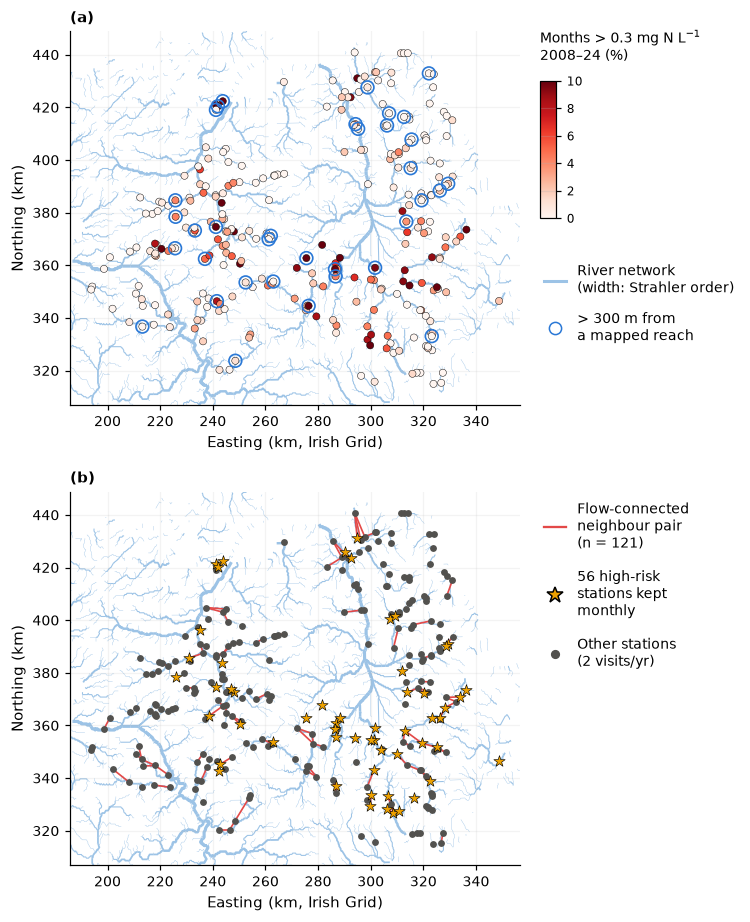

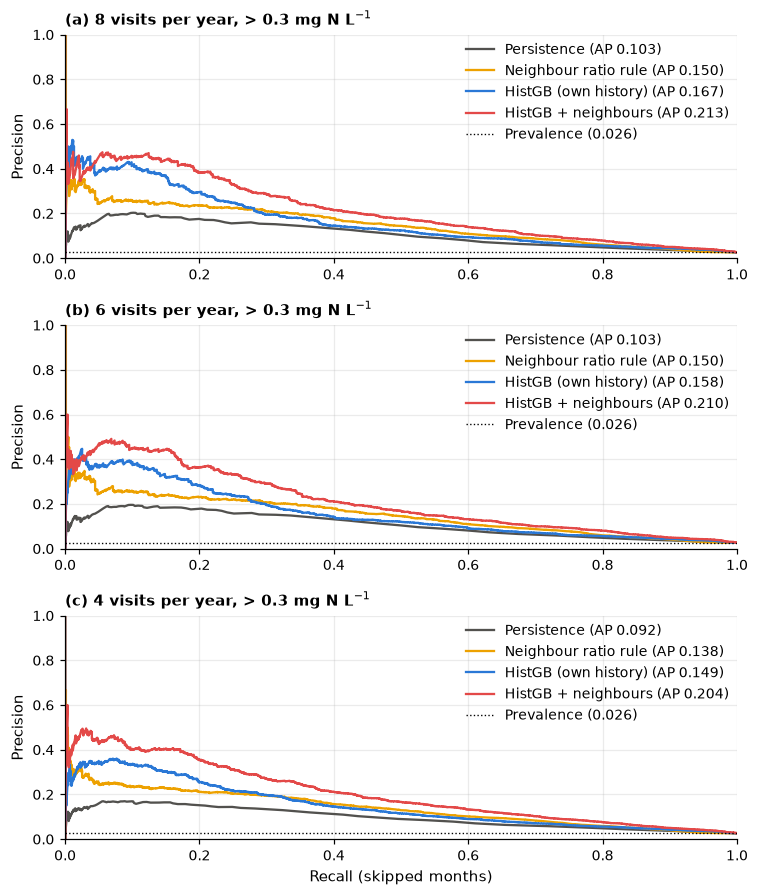

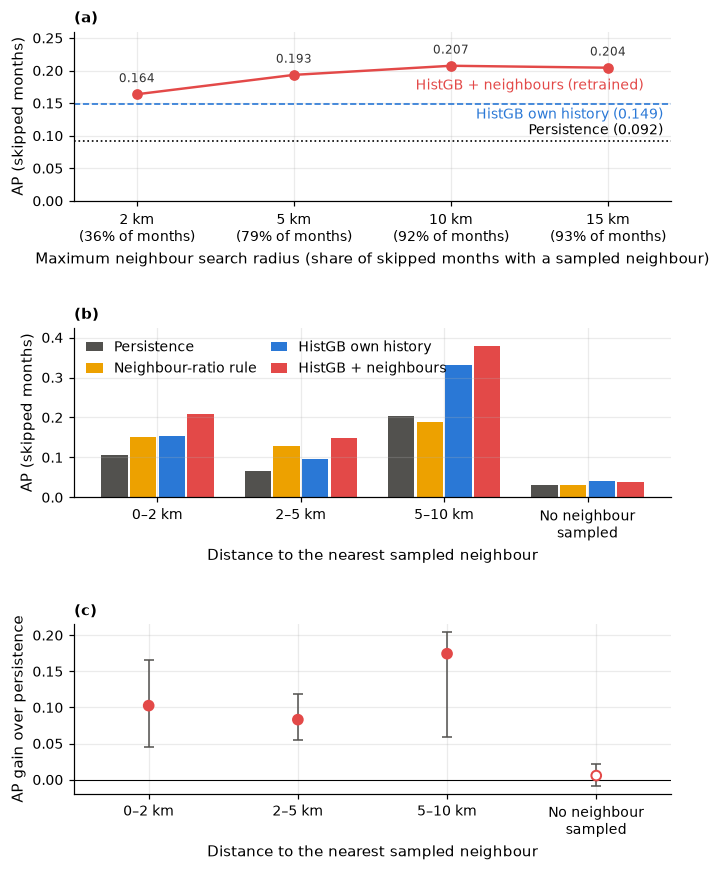

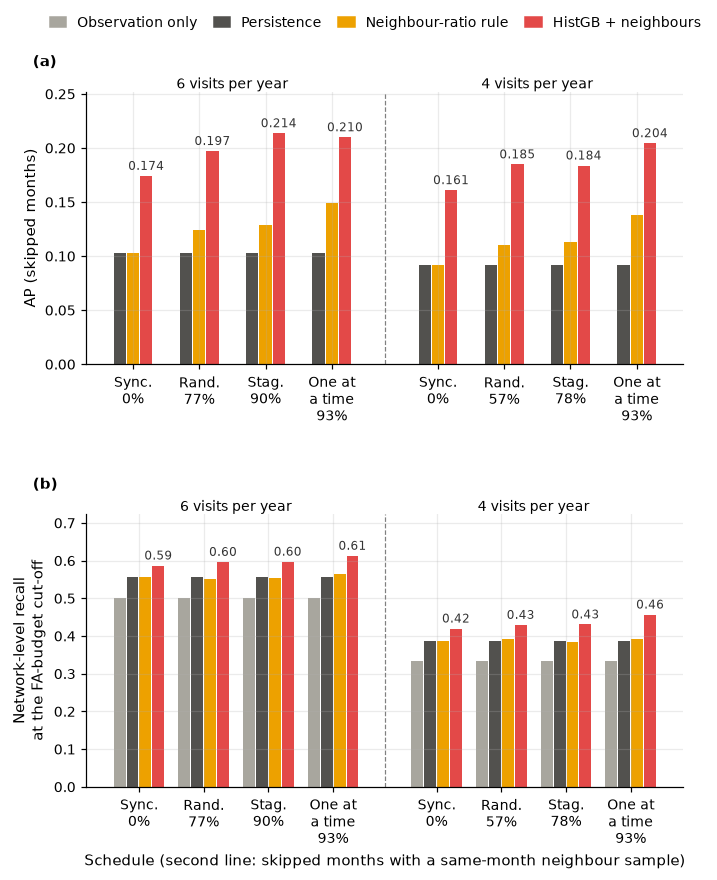

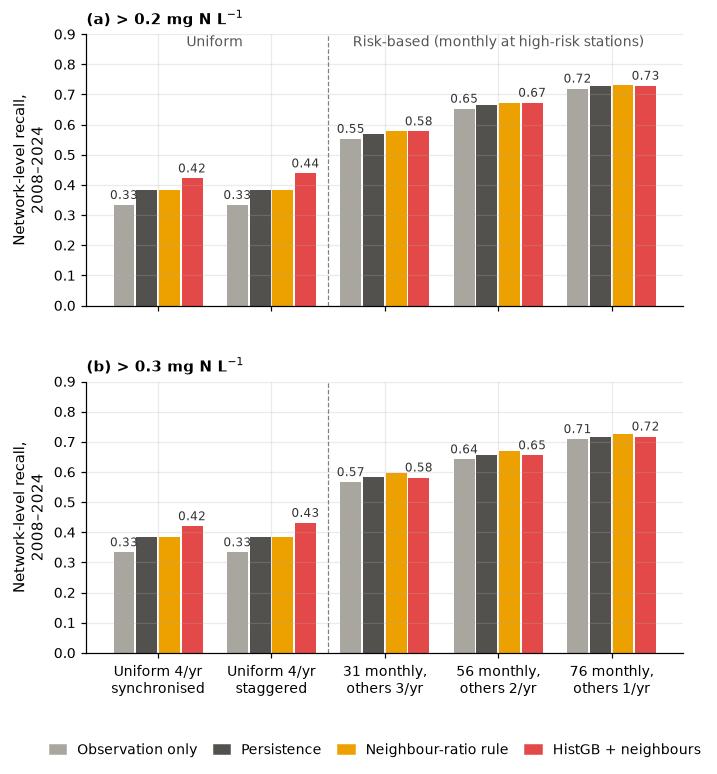

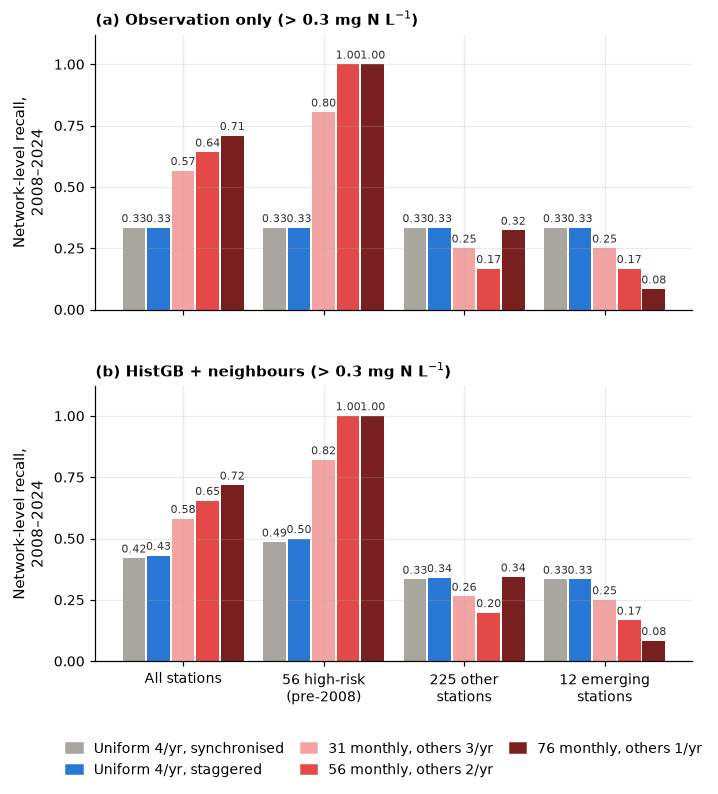

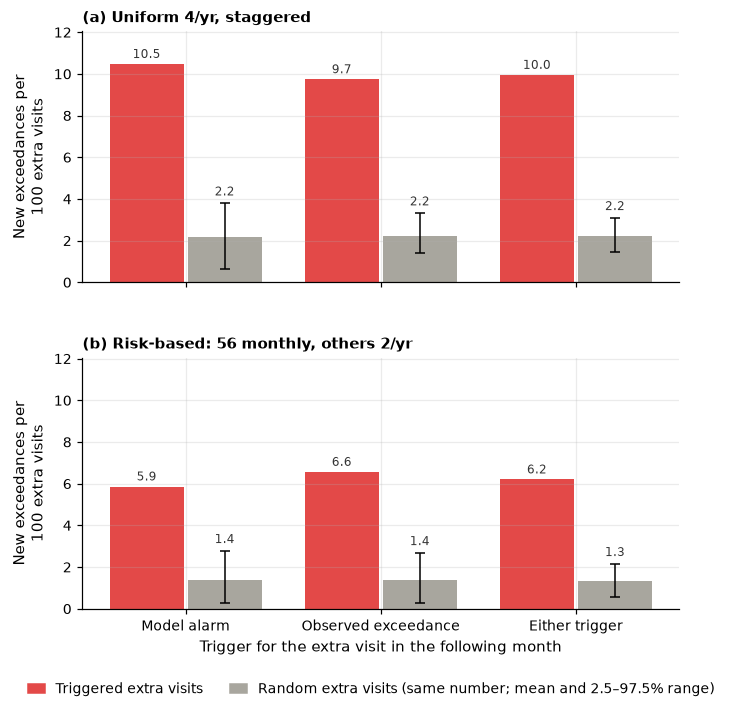

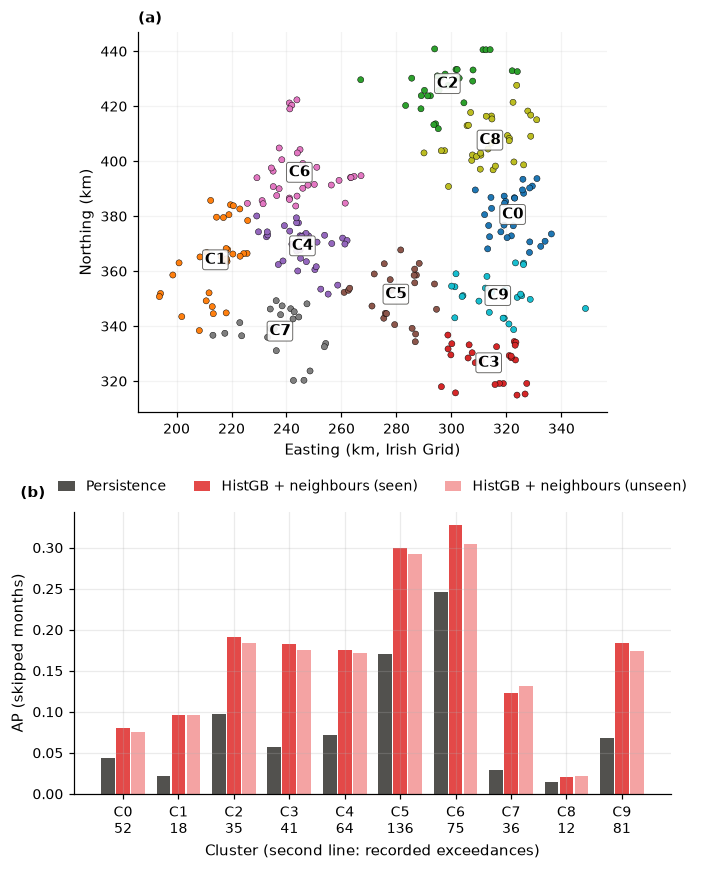

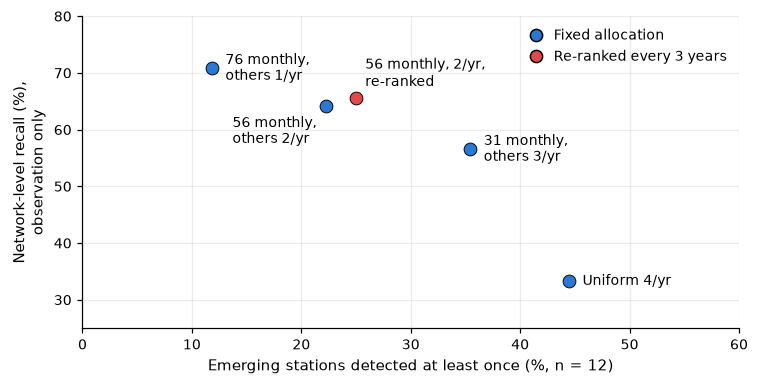

publication figures: Fig01_workflow.png, Fig02_study_area.png, Fig03_pr_curves.png, Fig04_neighbour_distance.png, Fig05_network_schedules.png, Fig06_allocation.png, Fig07_station_groups.png, Fig08_followup.png, FigS1_spatial_generalisation.png, FigS2_detection_vs_emerging.png


In [60]:
# ==== CELL P1 ==== Publication figures (manuscript versions). All values are read from the tables written above.
# Layout rules: 7.0 in wide (double-column), one panel per row, 9-10 pt text, horizontal value labels,
# legends outside the data area, and identical panel sizes within a figure.
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec
import matplotlib.patheffects as pe
UNIT = "mg N L$^{-1}$"
FW = 7.0                                      # figure width (in)
_RC = dict(plt.rcParams)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
                     "legend.fontsize": 9, "legend.frameon": False, "axes.titleweight": "bold", "axes.titlepad": 6})
VAL = dict(fontsize=8, ha="center", va="bottom", color="#333333")   # value labels
def rd(name): return pd.read_csv(os.path.join(OUT, name + ".csv"))
def panel(a_, k, txt=""): a_.set_title(f"({'abcdefgh'[k]}) {txt}".rstrip(), loc="left")
def vlabel(a_, x, y, s, dy=2, fs=8): a_.annotate(s, (x, y), xytext=(0, dy), textcoords="offset points", **{**VAL, "fontsize": fs})

# ---------------------------------------------------------------- Fig. 2 - study area (map objects of Section 14.5)
def fig2():
    fig = plt.figure(figsize=(FW, 10.2))
    gs = GridSpec(2, 2, figure=fig, width_ratios=[1, 0.30], wspace=0.04, hspace=0.14)
    ax = [fig.add_subplot(gs[0, 0])]; ax.append(fig.add_subplot(gs[1, 0], sharex=ax[0], sharey=ax[0]))
    side = [fig.add_subplot(gs[r, 1]) for r in (0, 1)]
    for s_ in side: s_.axis("off")
    for a_ in ax:
        a_.add_collection(LineCollection(segs, linewidths=0.25 + 0.45 * (ordr - 1), colors="#9cc3e6", zorder=1))
        a_.set_aspect("equal"); a_.set_xlim(XY[:, 0].min() / 1000 - 8, XY[:, 0].max() / 1000 + 8); a_.set_ylim(XY[:, 1].min() / 1000 - 8, XY[:, 1].max() / 1000 + 8)
        a_.set_ylabel("Northing (km)"); a_.set_xlabel("Easting (km, Irish Grid)"); a_.grid(alpha=.15)
    sc = ax[0].scatter(XY[:, 0] / 1000, XY[:, 1] / 1000, c=rate_, cmap="Reds", vmin=0, vmax=10, s=22, edgecolor="k", lw=.3, zorder=3)
    ax[0].scatter(XY[~reliable, 0] / 1000, XY[~reliable, 1] / 1000, s=70, facecolor="none", edgecolor="#2a78d6", lw=1.1, zorder=4)
    cax = side[0].inset_axes([0.06, 0.50, 0.12, 0.34]); cb = fig.colorbar(sc, cax=cax)
    cb.ax.tick_params(labelsize=8); side[0].text(0.06, 0.97, f"Months > 0.3 {UNIT}\n2008–24 (%)", fontsize=9, va="top", transform=side[0].transAxes)
    side[0].legend(handles=[Line2D([], [], color="#9cc3e6", lw=2, label="River network\n(width: Strahler order)"),
                            Line2D([], [], marker="o", ls="", mfc="none", mec="#2a78d6", ms=8, label=f"> {SNAP_MAX_M} m from\na mapped reach")],
                   loc="upper left", bbox_to_anchor=(0.0, 0.42), handlelength=1.6, labelspacing=1.0)
    for i, j in pairs: ax[1].plot(XY[[i, j], 0] / 1000, XY[[i, j], 1] / 1000, color="#e34948", lw=1.1, zorder=2)
    ax[1].scatter(XY[~HI0, 0] / 1000, XY[~HI0, 1] / 1000, s=12, color="#52514e", zorder=3)
    ax[1].scatter(XY[HI0, 0] / 1000, XY[HI0, 1] / 1000, s=60, marker="*", color="#eda100", edgecolor="k", lw=.4, zorder=4)
    side[1].legend(handles=[Line2D([], [], color="#e34948", lw=1.5, label=f"Flow-connected\nneighbour pair\n(n = {len(pairs)})"),
                            Line2D([], [], marker="*", ls="", color="#eda100", mec="k", ms=11, label=f"{NHI} high-risk\nstations kept\nmonthly"),
                            Line2D([], [], marker="o", ls="", color="#52514e", ms=5, label="Other stations\n(2 visits/yr)")],
                   loc="upper left", bbox_to_anchor=(0.0, 0.97), handlelength=1.6, labelspacing=1.2)
    panel(ax[0], 0); panel(ax[1], 1)
    savefig(fig, "Fig02_study_area"); plt.show()

# ---------------------------------------------------------------- Fig. 3 - precision-recall curves for skipped months
def fig3():
    nf = len(CFG["sched"]); fig, ax = plt.subplots(nf, 1, figsize=(FW, 2.75 * nf), sharex=True, sharey=True, squeeze=False); ax = ax[:, 0]
    for k, (a_, f) in enumerate(zip(ax, CFG["sched"])):
        sel_f3 = (MAIN["visits/yr"] == f) & (MAIN.threshold == PRIMARY)
        for s_ in STRATS:
            p_, r_, _ = curves[(f, s_)]; ap = MAIN[sel_f3 & (MAIN.strategy == s_)]["PR-AUC"].iloc[0]
            a_.plot(r_, p_, color=COL[s_], lw=1.5, label=f"{LAB[s_]} (AP {ap:.3f})")
        prev = MAIN[sel_f3 & MAIN.strategy.str.startswith("prev")]["PR-AUC"].iloc[0]
        a_.axhline(prev, color="k", ls=":", lw=0.9, label=f"Prevalence ({prev:.3f})")
        panel(a_, k, f"{f} visits per year, > {PRIMARY} {UNIT}"); a_.set_ylabel("Precision")
        a_.set_xlim(0, 1); a_.set_ylim(0, 1); a_.legend(loc="upper right", borderaxespad=0.2); a_.tick_params(labelbottom=True)
    ax[-1].set_xlabel("Recall (skipped months)"); fig.tight_layout(h_pad=1.2); savefig(fig, "Fig03_pr_curves"); plt.show()

# ---------------------------------------------------------------- Fig. 4 - neighbour distance (4 visits/yr, > 0.3)
def fig4():
    RADT_, DIST_ = rd("T11_radius_restriction"), rd("T10_distance_strata")
    r = RADT_[RADT_.threshold == PRIMARY].sort_values("radius (km)").reset_index(drop=True); x = np.arange(len(r))
    dd = DIST_[(DIST_["visits/yr"] == 4) & (DIST_.threshold == PRIMARY)].reset_index(drop=True); xd = np.arange(len(dd))
    lab_d = [c.replace("no neighbour sampled", "No neighbour\nsampled").replace("-", "–") for c in dd.distance]
    fig, ax = plt.subplots(3, 1, figsize=(FW, 9.0), gridspec_kw={"hspace": 0.75})
    # (a) AP of the retrained model by search radius; share of months with a sampled neighbour in the tick labels
    a_ = ax[0]; ap = r["PR-AUC HistGB + nb"]
    a_.plot(x, ap, "o-", color=COL["HistGB_nb"], lw=1.6, ms=6, zorder=3, label="HistGB + neighbours (retrained)")
    for xi, v in zip(x, ap): vlabel(a_, xi, v, f"{v:.3f}", dy=6)
    own, per = r["PR-AUC own history"].iloc[0], r["PR-AUC persistence"].iloc[0]
    a_.axhline(own, color=COL["HistGB_own"], ls="--", lw=1.1, label=f"HistGB own history ({own:.3f})")
    a_.axhline(per, color="k", ls=":", lw=1.1, label=f"Persistence ({per:.3f})")
    a_.set_xticks(x); a_.set_xticklabels([f"{v:g} km\n({c:.0%} of months)" for v, c in zip(r["radius (km)"], r["skipped months with a neighbour"])])
    a_.set_xlim(-0.4, len(x) - 0.6); a_.set_ylim(0, 0.26); a_.set_ylabel("AP (skipped months)")
    a_.set_xlabel("Maximum neighbour search radius (share of skipped months with a sampled neighbour)")
    # direct labels instead of a legend (a legend inside this short panel covers the data or the axis label)
    xr = len(x) - 0.65
    a_.text(xr, own - 0.006, f"HistGB own history ({own:.3f})", color=COL["HistGB_own"], fontsize=9, ha="right", va="top")
    a_.text(xr, per + 0.005, f"Persistence ({per:.3f})", color="k", fontsize=9, ha="right", va="bottom")
    a_.text((x[-2] + x[-1]) / 2, (own + min(ap.iloc[-2:])) / 2, "HistGB + neighbours (retrained)", color=COL["HistGB_nb"], fontsize=9, ha="center", va="center")
    panel(a_, 0)
    # (b) AP by distance class
    w = .2; names = {"HistGB_own": "HistGB own history", "HistGB_nb": "HistGB + neighbours", "Neighbour_ratio": "Neighbour-ratio rule"}
    for i, s_ in enumerate(STRATS):
        ax[1].bar(xd + (i - 1.5) * w, dd[f"PR-AUC {s_}"], w * .92, color=COL[s_], label=names.get(s_, LAB[s_]))
    ax[1].set_xticks(xd); ax[1].set_xticklabels(lab_d); ax[1].set_xlabel("Distance to the nearest sampled neighbour"); ax[1].set_ylabel("AP (skipped months)")
    ax[1].set_ylim(0, max(dd[[f"PR-AUC {s_}" for s_ in STRATS]].max()) * 1.12)
    ax[1].legend(ncol=2, loc="upper left", handlelength=1.2, columnspacing=1.0)
    panel(ax[1], 1)
    # (c) gain of HistGB + neighbours over persistence with 95% CI
    e = dd["dPR-AUC (nb - persistence)"]; lo, hi = dd["95% CI low"], dd["95% CI high"]
    ax[2].errorbar(xd, e, yerr=[e - lo, hi - e], fmt="none", ecolor="#52514e", capsize=3, lw=1)
    ax[2].scatter(xd, e, s=40, zorder=3, color=[COL["HistGB_nb"] if l_ > 0 else "white" for l_ in lo], edgecolor=COL["HistGB_nb"], lw=1.3)
    ax[2].axhline(0, color="k", lw=.7); ax[2].set_xticks(xd); ax[2].set_xticklabels(lab_d); ax[2].set_xlim(-0.5, len(xd) - 0.5)
    ax[2].set_xlabel("Distance to the nearest sampled neighbour"); ax[2].set_ylabel("AP gain over persistence")
    panel(ax[2], 2)
    savefig(fig, "Fig04_neighbour_distance"); plt.show()

# ---------------------------------------------------------------- Fig. 5 - network-wide schedules (AP and recall, 6 and 4 visits/yr)
def fig5():
    NT = rd("T15_network_schedules"); NT = NT[NT.threshold == PRIMARY]
    SCH = [("network: synchronised", "Sync."), ("network: random phases", "Rand."), ("network: staggered (graph colouring)", "Stag."), ("one-at-a-time (neighbours monthly)", "One at\na time")]
    KEYS = ["Observation-only", "Persistence", "Neighbour_ratio", "HistGB_nb"]
    fig, ax = plt.subplots(2, 1, figsize=(FW, 8.0), gridspec_kw={"hspace": 0.55}); w = .2
    freqs = [f_ for f_ in (6, 4) if f_ in set(NT["visits/yr"])]
    for row, (metric, keys_) in enumerate((("PR-AUC", KEYS[1:]), ("recall", KEYS))):
        a_ = ax[row]; xt, xl = [], []; top = 0
        for g, f in enumerate(freqs):
            for j, (sc_, sl) in enumerate(SCH):
                rr = NT[(NT["visits/yr"] == f) & (NT.scheme == sc_)].iloc[0]; x0 = g * 4.6 + j
                for k, s_ in enumerate(keys_):
                    v = rr[f"{s_} {metric}"]; xb = x0 + (k - (len(keys_) - 1) / 2) * w; top = max(top, v)
                    a_.bar(xb, v, w * .92, color=COL[s_])
                    if s_ == "HistGB_nb": vlabel(a_, xb, v, f"{v:.3f}" if metric == "PR-AUC" else f"{v:.2f}")
                xt.append(x0); xl.append(f"{sl}\n{rr['skipped months with a neighbour sampled in the same month']:.0%}")
            a_.text(g * 4.6 + 1.5, 1.0, f"{f} visits per year", ha="center", va="bottom", fontsize=9, transform=a_.get_xaxis_transform())
        a_.axvline(3.8, color="grey", ls="--", lw=.8); a_.set_xticks(xt); a_.set_xticklabels(xl)
        a_.set_ylim(0, top * 1.18); a_.set_ylabel("AP (skipped months)" if metric == "PR-AUC" else "Network-level recall\nat the FA-budget cut-off")
        a_.set_title(f"({'ab'[row]})", loc="left", x=-0.09, y=1.06)
    ax[1].set_xlabel("Schedule (second line: skipped months with a same-month neighbour sample)")
    fig.legend(handles=[Patch(color=COL[s_]) for s_ in KEYS], labels=["Observation only", "Persistence", "Neighbour-ratio rule", "HistGB + neighbours"],
               ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.0), handlelength=1.2, columnspacing=1.2)
    fig.subplots_adjust(top=0.90); savefig(fig, "Fig05_network_schedules"); plt.show()

# ---------------------------------------------------------------- Fig. 6 - uniform versus risk-based allocation (recall, 0.2 and 0.3)
def fig6():
    FA_ = rd("T20_fair_allocation_comparison"); DLAB = ["Observation only", "Persistence", "Neighbour-ratio rule", "HistGB + neighbours"]
    DCOL = dict(zip(DLAB, [COL["Observation-only"], COL["Persistence"], COL["Neighbour_ratio"], COL["HistGB_nb"]]))
    dsg = list(dict.fromkeys(FA_.design))
    dshort = ["Uniform 4/yr\nsynchronised", "Uniform 4/yr\nstaggered"] + [d.split(": ")[1].replace(", others", ",\nothers") for d in dsg[2:]]
    fig, ax = plt.subplots(2, 1, figsize=(FW, 7.6), sharex=True, gridspec_kw={"hspace": 0.28}); w = .2
    for row, thr in enumerate((0.2, PRIMARY)):
        for j, d_ in enumerate(dsg):
            for k, dl in enumerate(DLAB):
                v = FA_[(FA_.design == d_) & (FA_.threshold == thr) & (FA_.detection == dl)]["recall"].iloc[0]; xb = j + (k - 1.5) * w
                ax[row].bar(xb, v, w * .92, color=DCOL[dl])
                if dl in ("Observation only", "HistGB + neighbours"): vlabel(ax[row], xb, v, f"{v:.2f}")
        ax[row].axvline(1.5, color="grey", ls="--", lw=.8); ax[row].set_ylim(0, 0.9); ax[row].set_ylabel("Network-level recall,\n2008–2024")
        panel(ax[row], row, f"> {thr} {UNIT}")
    ax[0].text(0.5, 0.86, "Uniform", ha="center", fontsize=9, color="#555555"); ax[0].text(3.0, 0.86, "Risk-based (monthly at high-risk stations)", ha="center", fontsize=9, color="#555555")
    ax[1].set_xticks(range(len(dsg))); ax[1].set_xticklabels(dshort)
    fig.legend(handles=[Patch(color=DCOL[d]) for d in DLAB], labels=DLAB, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 0.0), handlelength=1.2, columnspacing=1.2)
    fig.subplots_adjust(bottom=0.14); savefig(fig, "Fig06_allocation"); plt.show()
    return dsg

# ---------------------------------------------------------------- Fig. 7 - recall by station group (observation only; HistGB + neighbours)
def fig7(dsg):
    SG = rd("T24b_station_groups_allocation"); SG = SG[SG.threshold == PRIMARY]
    gcols = [c for c in SG.columns if c.startswith("recall, ")]
    glab = ["All stations", f"{N_HI[2]} high-risk\n(pre-2008)", f"{S - N_HI[2]} other\nstations", f"{int(EMERG_R.sum())} emerging\nstations"]
    pal = ["#a8a69e", "#2a78d6", "#f4a3a3", "#e34948", "#7a1f1f"] if len(dsg) == 5 else ["#a8a69e", "#2a78d6", "#e34948"]
    DC7 = dict(zip(dsg, pal)); short = {d: d.replace("Risk-based: ", "").replace(", others", ", others") for d in dsg}
    fig, ax = plt.subplots(2, 1, figsize=(FW, 7.8), sharex=True, gridspec_kw={"hspace": 0.28}); w = .175
    for row, det in enumerate(("Observation only", "HistGB + neighbours")):
        for k, d_ in enumerate(dsg):
            v = SG[(SG.design == d_) & (SG.detection == det)][gcols].iloc[0].values; xb = np.arange(len(gcols)) + (k - (len(dsg) - 1) / 2) * w
            ax[row].bar(xb, v, w * .92, color=DC7[d_])
            for xi, vi in zip(xb, v): vlabel(ax[row], xi, vi, f"{vi:.2f}", fs=7)
        ax[row].set_ylim(0, 1.12); ax[row].set_yticks([0, .25, .5, .75, 1]); ax[row].set_ylabel("Network-level recall,\n2008–2024")
        panel(ax[row], row, f"{det} (> {PRIMARY} {UNIT})")
    ax[1].set_xticks(range(len(gcols))); ax[1].set_xticklabels(glab)
    labs = [short[d] if not d.startswith("Uniform") else d for d in dsg]
    fig.legend(handles=[Patch(color=DC7[d]) for d in dsg], labels=labs, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 0.0), handlelength=1.2, columnspacing=1.2)
    fig.subplots_adjust(bottom=0.15); savefig(fig, "Fig07_station_groups"); plt.show()
    return SG

# ---------------------------------------------------------------- Fig. 8 - alarm-triggered follow-up
def fig8():
    FU = rd("T28_alarm_triggered_followup"); FU = FU[FU.threshold == PRIMARY]
    des = list(dict.fromkeys(FU.design)); top = 0
    fig, ax = plt.subplots(len(des), 1, figsize=(FW, 7.0), sharex=True, sharey=True, gridspec_kw={"hspace": 0.3}, squeeze=False); ax = ax[:, 0]
    for row, d_ in enumerate(des):
        q = FU[FU.design == d_].reset_index(drop=True); x = np.arange(len(q))
        trg, mu = q["new detections per 100 scorable extra visits"], q["random control: per 100 visits (mean)"]
        lo, hi = q["random control: 2.5%"], q["random control: 97.5%"]; top = max(top, trg.max(), hi.max())
        ax[row].bar(x - .2, trg, .38, color="#e34948"); ax[row].bar(x + .2, mu, .38, color="#a8a69e")
        ax[row].errorbar(x + .2, mu, yerr=[mu - lo, hi - mu], fmt="none", ecolor="k", capsize=3, lw=1)
        for xi, v in zip(x, trg): vlabel(ax[row], xi - .2, v, f"{v:.1f}", dy=2)
        for xi, v, h in zip(x, mu, hi): vlabel(ax[row], xi + .2, h, f"{v:.1f}", dy=3)   # above the upper whisker
        ax[row].set_ylabel("New exceedances per\n100 extra visits"); panel(ax[row], row, d_)
    ax[0].set_ylim(0, top * 1.15)
    ax[-1].set_xticks(x); ax[-1].set_xticklabels(["Model alarm", "Observed exceedance", "Either trigger"]); ax[-1].set_xlabel("Trigger for the extra visit in the following month")
    fig.legend(handles=[Patch(color="#e34948"), Patch(color="#a8a69e")], labels=["Triggered extra visits", "Random extra visits (same number; mean and 2.5–97.5% range)"],
               ncol=2, loc="lower center", bbox_to_anchor=(0.5, 0.0), handlelength=1.2)
    fig.subplots_adjust(bottom=0.13); savefig(fig, "Fig08_followup"); plt.show()

# ---------------------------------------------------------------- Fig. S1 - spatial clusters and per-cluster AP (seen / unseen)
def figS1():
    fig, ax = plt.subplots(2, 1, figsize=(FW, 9.0), gridspec_kw={"height_ratios": [1.35, 1], "hspace": 0.3})
    ax[0].scatter(xy[:, 0] / 1000, xy[:, 1] / 1000, c=groups, cmap="tab10", s=16, edgecolor="k", lw=.3, zorder=2); ax[0].set_aspect("equal")
    for g in range(CFG["n_groups"]):
        c = xy[groups == g].mean(0) / 1000
        ax[0].text(c[0], c[1], f"C{g}", fontsize=10, weight="bold", ha="center", va="center", zorder=4,
                   bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="#52514e", lw=0.6, alpha=0.9))
    ax[0].set_xlabel("Easting (km, Irish Grid)"); ax[0].set_ylabel("Northing (km)"); ax[0].grid(alpha=.15); panel(ax[0], 0)
    xg = np.arange(len(PG)); w = .27
    for i, (c, lab, cc) in enumerate((("Persistence", "Persistence", "#52514e"), ("seen", "HistGB + neighbours (seen)", "#e34948"), ("unseen", "HistGB + neighbours (unseen)", "#f4a3a3"))):
        ax[1].bar(xg + (i - 1) * w, PG[c], w * .92, color=cc, label=lab)
    ax[1].set_xticks(xg); ax[1].set_xticklabels([f"C{g}\n{n}" for g, n in zip(PG.cluster, PG.events)])
    ax[1].set_xlabel("Cluster (second line: recorded exceedances)"); ax[1].set_ylabel("AP (skipped months)")
    ax[1].legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.02), handlelength=1.2); ax[1].set_title("(b)", loc="left", x=-0.09, y=1.02)
    savefig(fig, "FigS1_spatial_generalisation"); plt.show()

# ---------------------------------------------------------------- Fig. S2 - detection versus coverage of emerging pollution (repository only)
def figS2(SG, dsg):
    ob = SG[SG.detection == "Observation only"]; pts = []
    for d_ in dsg[1:]:
        q = ob[ob.design == d_].iloc[0]; lab_ = "Uniform 4/yr" if d_.startswith("Uniform") else d_.split(": ")[1].replace(", others ", ",\nothers ")
        pts.append((q["'emerging' stations detected at least once"] * 100, q["recall, all stations"] * 100, lab_, "#2a78d6"))
    rr_ = COST.loc["risk-based, re-ranked every 3 yr"]
    pts.append((rr_.iloc[3] * 100, rr_.iloc[0] * 100, f"{NHI} monthly, 2/yr,\nre-ranked", "#e34948"))
    fig, ax = plt.subplots(figsize=(FW, 3.6))
    for x_, y_, l_, c_ in pts:
        ax.scatter(x_, y_, s=70, color=c_, edgecolor="k", lw=.6, zorder=3)
        # the re-ranked point sits next to the fixed 56-monthly point: label it above-right, the fixed one below-left
        if c_ == "#e34948": off, ha, va = (6, 6), "left", "bottom"
        elif l_.startswith(f"{NHI} monthly"): off, ha, va = (-6, -6), "right", "top"
        else: off, ha, va = (9, 0), "left", "center"
        ax.annotate(l_, (x_, y_), xytext=off, textcoords="offset points", fontsize=9, ha=ha, va=va, multialignment="left", linespacing=1.15)
    ax.set_xlim(0, 60); ax.set_ylim(25, 80)
    ax.set_xlabel(f"Emerging stations detected at least once (%, n = {int(EMERG_R.sum())})"); ax.set_ylabel("Network-level recall (%),\nobservation only")
    ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc="#2a78d6", mec="k", ms=8, label="Fixed allocation"),
                       Line2D([], [], marker="o", ls="", mfc="#e34948", mec="k", ms=8, label="Re-ranked every 3 years")],
              loc="upper right", handletextpad=0.3)
    fig.tight_layout(); savefig(fig, "FigS2_detection_vs_emerging"); plt.show()

fig2(); fig3(); fig4(); fig5(); _dsg = fig6(); _SG = fig7(_dsg); fig8(); figS1(); figS2(_SG, _dsg)
plt.rcParams.update(_RC)
print("publication figures:", ", ".join(sorted(f for f in os.listdir(FIG) if f.startswith("Fig") and f.endswith(".png"))))


<a id="16"></a>
## 16. Synthesis, limitations and reproducibility

In [55]:
fx = FIX[(FIX["visits/yr"] == 4) & (FIX.threshold == PRIMARY)]
rowsum = []
for s_, rule in (("Observation-only", "-"), ("Persistence", "FA-budget"), ("Neighbour_ratio", "FA-budget"), ("HistGB_own", "FA-budget"), ("HistGB_nb", "FA-budget")):
    r = fx[(fx.strategy == s_) & (fx.rule == rule)].iloc[0]
    m = MAIN[(MAIN["visits/yr"] == 4) & (MAIN.threshold == PRIMARY) & (MAIN.strategy == s_)]
    u = GEN[(GEN["visits/yr"] == 4) & (GEN.threshold == PRIMARY) & (GEN.model == s_) & (GEN.design == "unseen")]
    rowsum.append({"strategy": LAB[s_], "PR-AUC (skipped)": m["PR-AUC"].iloc[0] if len(m) else np.nan, "MAE log (skipped)": m["MAE (log)"].iloc[0] if len(m) else np.nan,
                   "recall, pre-selected cut-off": r.recall, "precision": r.precision, "false alarms / station-yr": r["false alarms / station-yr"],
                   "PR-AUC unseen stations": u["PR-AUC"].iloc[0] if len(u) else np.nan})
SUMMARY = pd.DataFrame(rowsum); save_table(SUMMARY, "T14_summary")
display(Markdown(f"**Key results — {S} river stations, {n_sy_eval:,} station-years (2008–2024), 4 visits/yr, exceedance > {PRIMARY} mg/l NH₄-N.**")); display(SUMMARY.round(3))
json.dump({"seed": SEED, "fast_mode": FAST, "stations": S, "eval_station_years": n_sy_eval, "dev_station_years": n_sy_dev, "chosen": CHOSEN, "config": {k: (v if k != "sched" else {str(a): b for a, b in v.items()}) for k, v in CFG.items()},
           "truncation_test_max_diff": maxdiff, "runtime_minutes": (time.time() - T0) / 60}, open(os.path.join(OUT, "manifest.json"), "w"), indent=1)
outputs = sorted(os.listdir(OUT)); print(f"runtime {(time.time() - T0) / 60:.1f} min; outputs in results/complete_study/:"); print(", ".join(o for o in outputs if o.endswith((".csv", ".json"))))
print("figures:", ", ".join(sorted(f for f in os.listdir(FIG) if f.endswith(".png"))))

**Key results — 281 river stations, 2,788 station-years (2008–2024), 4 visits/yr, exceedance > 0.3 mg/l NH₄-N.**

,strategy,PR-AUC (skipped),MAE log (skipped),"recall, pre-selected cut-off",precision,false alarms / station-yr,PR-AUC unseen stations
0,Observation only,NaN,NaN,0.333,1,0,NaN
1,Persistence,0.092,0.38,0.386,0.593,0.079,NaN
2,Neighbour ratio rule,0.138,0.469,0.392,0.678,0.055,NaN
3,HistGB (own history),0.149,0.33,0.422,0.689,0.057,0.142
4,HistGB + neighbours,0.204,0.3,0.457,0.693,0.06,0.197


runtime 156.1 min; outputs in results/complete_study/:
T00_cleaning_log.csv, T00_data_dictionary.csv, T00b_station_cohorts.csv, T01_exceedance_counts.csv, T01b_exceedance_persistence.csv, T02_baselines.csv, T03_tuning.csv, T04_threshold_free.csv, T05_threshold_free_bootstrap.csv, T05b_two_way_bootstrap.csv, T06_fixed_cutoffs.csv, T07_fixed_cutoffs_bootstrap.csv, T08_spatial_generalisation.csv, T08b_spatial_generalisation_by_cluster.csv, T09_spatial_generalisation_bootstrap.csv, T10_distance_strata.csv, T11_radius_restriction.csv, T12_threshold_robustness.csv, T12b_river_connectivity.csv, T12c_connectivity_aware_ratio_rule.csv, T12d_flow_connectivity.csv, T13_data_preparation_sensitivity.csv, T14_summary.csv, T15_network_schedules.csv, T15c_network_retraining_vs_trained_once.csv, T16_network_schedules_bootstrap.csv, T17_station_year_detection.csv, T18_station_year_detection_bootstrap.csv, T19_risk_ranking_stability.csv, T19b_ranking_overlap.csv, T20_fair_allocation_comparison.csv, T20b_